# Activity 1 — Dataset Loading and Initial Audit

## Objective

The objective of this activity is to verify the structural integrity of the
experimental dataset before performing any machine learning analysis.

This initial audit evaluates:

- dataset dimensions;
- variable names and data types;
- experimental campaign distribution;
- QoT class distribution;
- predefined Train/Test/Exclude partitions;
- missing values;
- duplicate observations;
- categorical consistency;
- number of experimental groups.

No data cleaning, imputation, transformation, or machine learning model is
performed at this stage. The purpose is to characterize the dataset exactly
as published and identify potential issues that require further validation.

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# Display options for easier inspection
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.3
NumPy version: 2.4.6


In [4]:
DATA_PATH = Path("Dataset_Publication_v1.0.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"The dataset file was not found: {DATA_PATH.resolve()}"
    )

print("Dataset file found:")
print(DATA_PATH.resolve())

Dataset file found:
C:\Users\jarguero\Documents\Experimental_MLdataset\Dataset_Publication_v1.0.xlsx


### Step 3 — Inspect workbook structure

Before loading the experimental records, the workbook structure is inspected.

The publication package is expected to contain the experimental dataset
together with supporting documentation such as the data dictionary and README.
Identifying the available sheets also prevents accidentally loading the wrong
worksheet for the machine learning analysis.

In [5]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Sheets available in the workbook:")
for sheet in excel_file.sheet_names:
    print(f" - {sheet}")

Sheets available in the workbook:
 - Dataset
 - Dictionary
 - Readme


### Step 4 — Load the experimental dataset

The `Dataset` worksheet is loaded into a Pandas DataFrame.

Each row represents one experimental optical-link condition, while the columns
contain transmitter, channel, attenuation, amplification, receiver, KPI,
provenance, target, grouping, and machine-learning metadata.

The number of observations and variables is reported immediately to verify
that the complete publication dataset has been loaded.

In [6]:
df = pd.read_excel(
    DATA_PATH,
    sheet_name="Dataset",
    engine="openpyxl"
)

print("Dataset successfully loaded.")
print(f"Number of observations : {df.shape[0]:,}")
print(f"Number of variables    : {df.shape[1]}")

Dataset successfully loaded.
Number of observations : 6,065
Number of variables    : 39


### Step 5 — Preview the dataset

The first and last observations are inspected to verify that the dataset was
loaded correctly and that the expected variables and values are present.

This visual inspection is not intended to modify the data. It is an initial
sanity check that can reveal unexpected headers, empty rows, parsing problems,
or formatting inconsistencies.

In [7]:
df.head()

,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,experiment_campaign,bits_tx,transmission_rate_bps,rf_voltage_v,rf_power_dbm,rf_amplifier_tx_db,smf_length_km,smf_attenuation_db,dispersion_ps_nm_km,voa_attenuation_db,edfa_current_ma,soa_current_ma,prx_dbm,photodiode,max_allowed_optical_power_dbm,optical_receiver_responsivity_a_w,detector_bw_hz,rf_amplifier_rx_db,ber,ber_source,evm_percent,evm_source,q_factor,q_factor_source,jitter_ps,jitter_source,ml_task_evm,ml_task_q,ml_task_jitter,qot_class,qot_basis,group_key,group_id,ml_split
0,16.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,27,25,4.63,18,35.0,0.0,217.0,-56.15,PIN,-3,0.8,10000000000,0.0,0.160001,Derived_from_EVM,142.21,Measured,NaN,Not_available,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|16|1551|8019028IM|800000000|25|35,G0001,Train
1,8.0,1550.0,8019028IM,4.33,1.7,LTE_QPSK,800000000,800000000,0.070711,-10.0,27,25,4.63,18,27.0,0.0,205.0,-55.75,PIN,-3,0.8,10000000000,0.0,0.160664,Derived_from_EVM,142.60,Measured,NaN,Not_available,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
2,8.0,1550.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,27,25,4.63,18,27.0,0.0,205.0,-54.66,PIN,-3,0.8,10000000000,0.0,0.163413,Derived_from_EVM,144.23,Measured,NaN,Not_available,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
3,12.0,1551.0,8019028IM,4.33,1.4,LTE_QPSK,800000000,800000000,0.070711,-10.0,27,25,4.63,18,30.0,0.0,170.3,NaN,PIN,-3,0.8,10000000000,0.0,0.203094,Derived_from_EVM,170.26,Measured,NaN,Not_available,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|12|1551|8019028IM|800000000|25|30,G0004,Test
4,15.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,27,25,4.63,18,33.0,0.0,170.3,-52.32,PIN,-3,0.8,10000000000,0.0,0.215234,Derived_from_EVM,179.38,Measured,NaN,Not_available,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|15|1551|8019028IM|800000000|25|33,G0005,Train


In [8]:
df.tail()

,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,experiment_campaign,bits_tx,transmission_rate_bps,rf_voltage_v,rf_power_dbm,rf_amplifier_tx_db,smf_length_km,smf_attenuation_db,dispersion_ps_nm_km,voa_attenuation_db,edfa_current_ma,soa_current_ma,prx_dbm,photodiode,max_allowed_optical_power_dbm,optical_receiver_responsivity_a_w,detector_bw_hz,rf_amplifier_rx_db,ber,ber_source,evm_percent,evm_source,q_factor,q_factor_source,jitter_ps,jitter_source,ml_task_evm,ml_task_q,ml_task_jitter,qot_class,qot_basis,group_key,group_id,ml_split
6060,7.0,1553.33,8019028IM,4.33,3.5,PRBS_NRZ,800000031,622000000,0.1,-7.0,27,25,4.67,18,0.0,0.0,NaN,NaN,PIN,-3,0.8,10000000000,27.0,3.350460e-15,Derived_from_Q,79.06,Derived_from_BER,7.79,Measured,20.73,Measured,No_use,Use,Use,Excellent,Q_factor_measured,"PRBS_NRZ|7|1553,33|8019028IM|622000000|25|0",G6061,Train
6061,7.0,1553.33,8019028IM,4.33,3.5,PRBS_NRZ,800000032,622000000,0.1,-7.0,27,25,4.67,18,1.0,0.0,NaN,NaN,PIN,-3,0.8,10000000000,27.0,3.443027e-12,Derived_from_Q,75.38,Derived_from_BER,6.86,Measured,21.25,Measured,No_use,Use,Use,Excellent,Q_factor_measured,"PRBS_NRZ|7|1553,33|8019028IM|622000000|25|1",G6062,Train
6062,7.0,1553.33,8019028IM,4.33,3.5,PRBS_NRZ,800000033,622000000,0.1,-7.0,27,25,4.67,18,2.0,0.0,NaN,NaN,PIN,-3,0.8,10000000000,27.0,6.009127e-10,Derived_from_Q,69.35,Derived_from_BER,6.08,Measured,22.02,Measured,No_use,Use,Use,Excellent,Q_factor_measured,"PRBS_NRZ|7|1553,33|8019028IM|622000000|25|2",G6063,Train
6063,7.0,1553.33,8019028IM,4.33,3.5,PRBS_NRZ,800000034,622000000,0.1,-7.0,27,25,4.67,18,3.0,0.0,NaN,NaN,PIN,-3,0.8,10000000000,27.0,6.734737e-09,Derived_from_Q,63.50,Derived_from_BER,5.68,Measured,75.48,Measured,No_use,Use,Use,Acceptable,Q_factor_measured,"PRBS_NRZ|7|1553,33|8019028IM|622000000|25|3",G6064,Train
6064,7.0,1553.33,8019028IM,4.33,3.5,PRBS_NRZ,800000035,622000000,0.1,-7.0,27,25,4.67,18,4.0,0.0,NaN,NaN,PIN,-3,0.8,10000000000,27.0,7.363753e-04,Derived_from_Q,60.41,Derived_from_BER,3.18,Measured,554.23,Measured,No_use,Use,Use,Degraded,Q_factor_measured,"PRBS_NRZ|7|1553,33|8019028IM|622000000|25|4",G6065,Train


### Step 6 — Inspect variable names

All dataset variables are listed in their original order.

This step verifies that the expected publication variables are available and
helps identify accidental unnamed columns, duplicated headers, spelling
problems, or unexpected changes in the dataset schema.

In [9]:
print(f"Total number of variables: {len(df.columns)}\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

Total number of variables: 39

01. optical_tx_power_dbm
02. wavelength_nm
03. modulator_type
04. modulator_attenuation_db
05. vbias_v
06. experiment_campaign
07. bits_tx
08. transmission_rate_bps
09. rf_voltage_v
10. rf_power_dbm
11. rf_amplifier_tx_db
12. smf_length_km
13. smf_attenuation_db
14. dispersion_ps_nm_km
15. voa_attenuation_db
16. edfa_current_ma
17. soa_current_ma
18. prx_dbm
19. photodiode
20. max_allowed_optical_power_dbm
21. optical_receiver_responsivity_a_w
22. detector_bw_hz
23. rf_amplifier_rx_db
24. ber
25. ber_source
26. evm_percent
27. evm_source
28. q_factor
29. q_factor_source
30. jitter_ps
31. jitter_source
32. ml_task_evm
33. ml_task_q
34. ml_task_jitter
35. qot_class
36. qot_basis
37. group_key
38. group_id
39. ml_split


### Step 7 — Inspect variable data types

A structural summary is generated for every variable.

For each column, the table reports:

- the detected Pandas data type;
- the number of non-missing observations;
- the number of missing observations;
- the number of unique values.

This information helps determine whether numerical and categorical variables
have been interpreted correctly before they are used in a machine learning
pipeline.

In [10]:
dtype_table = pd.DataFrame({
    "variable": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique(dropna=True).values
})

dtype_table

,variable,data_type,non_null,missing,unique_values
0,optical_tx_power_dbm,float64,6065,0,14
1,wavelength_nm,float64,6065,0,6
2,modulator_type,str,6065,0,6
3,modulator_attenuation_db,float64,6065,0,5
4,vbias_v,float64,6065,0,53
5,experiment_campaign,str,6065,0,2
6,bits_tx,int64,6065,0,62
7,transmission_rate_bps,int64,6065,0,32
8,rf_voltage_v,float64,6065,0,94
9,rf_power_dbm,float64,6065,0,92


In [11]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numerical variables   : {len(numeric_columns)}")
print(f"Categorical variables : {len(categorical_columns)}")
print(f"Total variables       : {len(df.columns)}")

Numerical variables   : 24
Categorical variables : 15
Total variables       : 39


### Step 8 — Experimental campaign distribution

The number of observations belonging to each experimental acquisition campaign
is calculated.

This distinction is essential because PRBS-NRZ and LTE-QPSK were acquired
using different signal-generation and receiver-analysis procedures and use
different directly measured QoT indicators.

The campaign distribution must therefore be verified before campaign-specific
machine learning experiments are performed.

In [12]:
campaign_counts = (
    df["experiment_campaign"]
    .value_counts(dropna=False)
    .rename_axis("experiment_campaign")
    .reset_index(name="count")
)

campaign_counts["percentage"] = (
    100 * campaign_counts["count"] / len(df)
)

campaign_counts

,experiment_campaign,count,percentage
0,PRBS_NRZ,4533,74.740313
1,LTE_QPSK,1532,25.259687


### Step 9 — QoT class distribution

The distribution of the QoT target variable is examined before model training.

Class frequencies are important because imbalanced class distributions can
make conventional accuracy misleading. This observation motivates the later
use of Macro-F1, Balanced Accuracy, and MCC as primary evaluation metrics.

In [13]:
qot_counts = (
    df["qot_class"]
    .value_counts(dropna=False)
    .rename_axis("qot_class")
    .reset_index(name="count")
)

qot_counts["percentage"] = (
    100 * qot_counts["count"] / len(df)
)

qot_counts

,qot_class,count,percentage
0,Degraded,3246,53.520198
1,Excellent,2021,33.322341
2,Acceptable,794,13.091509
3,Not_available,4,0.065952


### Step 10 — QoT distribution within each campaign

The QoT classes are cross-tabulated against the experimental campaign.

The absolute table reports the number of observations in each class, whereas
the normalized table shows the percentage distribution within each campaign.

This analysis is necessary because the primary machine learning benchmark will
evaluate PRBS-NRZ and LTE-QPSK separately rather than assuming that the two
campaigns have identical target distributions.

In [14]:
campaign_qot_table = pd.crosstab(
    df["experiment_campaign"],
    df["qot_class"],
    margins=True
)

campaign_qot_table

qot_class,Acceptable,Degraded,Excellent,Not_available,All
experiment_campaign,,,,,
LTE_QPSK,155,1224,151,2,1532
PRBS_NRZ,639,2022,1870,2,4533
All,794,3246,2021,4,6065


In [15]:
campaign_qot_percent = pd.crosstab(
    df["experiment_campaign"],
    df["qot_class"],
    normalize="index"
) * 100

campaign_qot_percent.round(2)

qot_class,Acceptable,Degraded,Excellent,Not_available
experiment_campaign,,,,
LTE_QPSK,10.12,79.90,9.86,0.13
PRBS_NRZ,14.10,44.61,41.25,0.04


### Step 11 — Audit the predefined machine learning partition

The predefined `ml_split` variable is inspected without modifying it.

The dataset contains a frozen group-based partition that must be preserved
during all subsequent machine learning experiments. The Train subset will be
used for model development and validation, whereas the Test subset will remain
untouched until final evaluation.

Records labeled as Exclude must not participate in the QoT classification
benchmark.

In [16]:
split_counts = (
    df["ml_split"]
    .value_counts(dropna=False)
    .rename_axis("ml_split")
    .reset_index(name="count")
)

split_counts["percentage"] = (
    100 * split_counts["count"] / len(df)
)

split_counts

,ml_split,count,percentage
0,Train,4836,79.736191
1,Test,1225,20.197857
2,Exclude,4,0.065952


### Step 12 — Count experimental groups

The number of unique experimental groups is calculated from `group_id`.

Multiple observations may originate from the same relevant experimental
configuration. Therefore, the number of rows must not be interpreted as the
number of statistically independent experimental configurations.

The group structure will later be used to prevent related observations from
being distributed across training and validation or test subsets.

In [17]:
n_groups = df["group_id"].nunique(dropna=True)

print(f"Number of observations        : {len(df):,}")
print(f"Number of experimental groups : {n_groups:,}")

Number of observations        : 6,065
Number of experimental groups : 1,441


### Step 13 — Missing-value audit

Missing values are quantified for every variable.

At this stage, missing observations are not removed or imputed because missing
KPI values may have a physical and methodological meaning. In particular,
measurement availability differs between the PRBS-NRZ and LTE-QPSK campaigns.

The purpose of this step is therefore to document missingness rather than
modify it.

In [18]:
missing_table = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": 100 * df.isna().sum() / len(df)
})

missing_table = (
    missing_table[missing_table["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

missing_table.round(2)

,missing_count,missing_percentage
jitter_ps,1670,27.54
q_factor,1534,25.29
prx_dbm,45,0.74
edfa_current_ma,19,0.31
rf_amplifier_rx_db,6,0.10
soa_current_ma,5,0.08
evm_percent,5,0.08
ber,4,0.07


### Step 14 — Duplicate observation audit

Exact duplicate rows are searched across all dataset variables.

Duplicate detection is performed only as an audit operation. No observations
are automatically removed because repeated measurements could potentially
represent legitimate experimental acquisitions.

Any detected duplicate would therefore require examination of its experimental
context before removal.

In [19]:
n_duplicates = df.duplicated().sum()

print(f"Exact duplicated rows: {n_duplicates}")

Exact duplicated rows: 0


In [20]:
if n_duplicates > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))
else:
    print("No exact duplicated observations were detected.")

No exact duplicated observations were detected.


### Step 15 — Categorical consistency audit

Categorical variables are inspected to identify unexpected labels, spelling
differences, leading or trailing whitespace, or inconsistent category names.

No values are corrected during this activity. Potential inconsistencies are
reported first so that any subsequent cleaning decision remains transparent
and reproducible.

In [21]:
categorical_summary = []

for column in categorical_columns:
    categorical_summary.append({
        "variable": column,
        "unique_values": df[column].nunique(dropna=True),
        "missing_values": df[column].isna().sum()
    })

categorical_summary = pd.DataFrame(categorical_summary)

categorical_summary

,variable,unique_values,missing_values
0,modulator_type,6,0
1,experiment_campaign,2,0
2,photodiode,1,0
3,ber_source,3,0
4,evm_source,3,0
5,q_factor_source,2,0
6,jitter_source,2,0
7,ml_task_evm,2,0
8,ml_task_q,2,0
9,ml_task_jitter,2,0


In [22]:
for column in categorical_columns:
    
    n_unique = df[column].nunique(dropna=True)

    if n_unique <= 20:
        print("=" * 70)
        print(f"Variable: {column}")
        print(df[column].value_counts(dropna=False))
        print()

Variable: modulator_type
modulator_type
8019028IM    2672
8036011IM    1909
8036016IM     857
9758023IM     316
8758013IM     281
9758013IM      30
Name: count, dtype: int64

Variable: experiment_campaign
experiment_campaign
PRBS_NRZ    4533
LTE_QPSK    1532
Name: count, dtype: int64

Variable: photodiode
photodiode
PIN    6065
Name: count, dtype: int64

Variable: ber_source
ber_source
Derived_from_Q      4531
Derived_from_EVM    1530
Not_available          4
Name: count, dtype: int64

Variable: evm_source
evm_source
Derived_from_BER    4530
Measured            1530
Not_available          5
Name: count, dtype: int64

Variable: q_factor_source
q_factor_source
Measured         4531
Not_available    1534
Name: count, dtype: int64

Variable: jitter_source
jitter_source
Measured         4395
Not_available    1670
Name: count, dtype: int64

Variable: ml_task_evm
ml_task_evm
No_use    4535
Use       1530
Name: count, dtype: int64

Variable: ml_task_q
ml_task_q
Use       4531
No_use    1534
Na

### Step 16 — Detect whitespace inconsistencies

Categorical string values are checked for leading or trailing whitespace.

Whitespace differences can cause logically identical categories to be treated
as different levels by machine learning algorithms and categorical encoders.

The values are only detected and reported in this activity; the original
dataset remains unchanged.

In [23]:
# Step 16 — Detect leading/trailing whitespace

whitespace_issues = []

for column in categorical_columns:

    non_null_values = df[column].dropna()

    for value in non_null_values.unique():

        if isinstance(value, str) and value != value.strip():

            whitespace_issues.append({
                "variable": column,
                "original_value": repr(value),
                "clean_value": value.strip(),
                "count": (df[column] == value).sum()
            })

# Convert results to DataFrame
whitespace_issues = pd.DataFrame(whitespace_issues)

# Report results
if whitespace_issues.empty:
    print("✓ No leading or trailing whitespace inconsistencies were detected.")
else:
    print("⚠ Whitespace inconsistencies were detected:")
    display(whitespace_issues)

✓ No leading or trailing whitespace inconsistencies were detected.


### Step 17 — Generate the dataset audit summary

The main structural characteristics of the dataset are consolidated into a
single audit table.

This summary provides a reproducible overview of the dataset before any
preprocessing or machine learning operation and can be used as supporting
evidence when describing the dataset validation procedure.

In [24]:
audit_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Total variables",
        "Numerical variables",
        "Categorical variables",
        "Experimental campaigns",
        "Experimental groups",
        "Train observations",
        "Test observations",
        "Excluded observations",
        "QoT classes",
        "Columns with missing values",
        "Exact duplicate rows"
    ],
    "Value": [
        len(df),
        df.shape[1],
        len(numeric_columns),
        len(categorical_columns),
        df["experiment_campaign"].nunique(),
        df["group_id"].nunique(),
        (df["ml_split"] == "Train").sum(),
        (df["ml_split"] == "Test").sum(),
        (df["ml_split"] == "Exclude").sum(),
        df["qot_class"].nunique(),
        (df.isna().sum() > 0).sum(),
        df.duplicated().sum()
    ]
})

audit_summary

,Metric,Value
0,Total observations,6065
1,Total variables,39
2,Numerical variables,24
3,Categorical variables,15
4,Experimental campaigns,2
5,Experimental groups,1441
6,Train observations,4836
7,Test observations,1225
8,Excluded observations,4
9,QoT classes,4


### Step 18 — Automatic structural validation

A set of reproducible assertions is applied to the dataset structure.

These checks verify the expected dataset dimensions, campaign identifiers,
partition labels, QoT labels, duplicate status, and availability of critical
grouping and partition metadata.

A failed check does not automatically modify the dataset. Instead, it indicates
a condition that must be investigated before machine learning analysis.

In [25]:
expected_campaigns = {"PRBS_NRZ", "LTE_QPSK"}
expected_splits = {"Train", "Test", "Exclude"}
expected_qot_labels = {
    "Excellent",
    "Acceptable",
    "Degraded",
    "Not_available"
}

checks = {
    "Dataset contains 6065 observations":
        len(df) == 6065,

    "Dataset contains 39 variables":
        df.shape[1] == 39,

    "Campaign labels are valid":
        set(df["experiment_campaign"].dropna().unique()) == expected_campaigns,

    "ML split labels are valid":
        set(df["ml_split"].dropna().unique()) == expected_splits,

    "QoT labels are valid":
        set(df["qot_class"].dropna().unique()).issubset(expected_qot_labels),

    "No exact duplicated rows":
        df.duplicated().sum() == 0,

    "group_id is available":
        df["group_id"].notna().all(),

    "ml_split is available":
        df["ml_split"].notna().all()
}

checks_table = pd.DataFrame(
    checks.items(),
    columns=["Check", "Passed"]
)

checks_table

,Check,Passed
0,Dataset contains 6065 observations,True
1,Dataset contains 39 variables,True
2,Campaign labels are valid,True
3,ML split labels are valid,True
4,QoT labels are valid,True
5,No exact duplicated rows,True
6,group_id is available,True
7,ml_split is available,True


In [26]:
if checks_table["Passed"].all():
    print("All initial structural checks passed.")
else:
    print("Some structural checks require attention.")
    display(checks_table[~checks_table["Passed"]])

All initial structural checks passed.


## Activity 1 — Preliminary conclusion

The initial audit confirms that the publication dataset contains 6,065
experimental observations and the expected metadata required for subsequent
machine learning evaluation.

The dataset includes two experimental campaigns, PRBS-NRZ and LTE-QPSK, and a
predefined Train/Test/Exclude partition. No exact duplicate observations were
identified.

Missing values are present in several variables and are intentionally retained
at this stage because their interpretation depends on the experimental
campaign and KPI provenance. These values will therefore be examined before
any imputation strategy is considered.

The categorical audit also identified potential formatting inconsistencies
that require further verification before preprocessing. No modifications have
been applied to the original dataset during this activity.

The next analysis will evaluate KPI availability and provenance separately for
each experimental campaign.

In [27]:
print("=" * 70)
print("ACTIVITY 1 — DATASET INITIAL AUDIT")
print("=" * 70)

print(f"Observations             : {len(df):,}")
print(f"Variables                : {df.shape[1]}")
print(f"Numerical variables      : {len(numeric_columns)}")
print(f"Categorical variables    : {len(categorical_columns)}")
print(f"Experimental campaigns   : {df['experiment_campaign'].nunique()}")
print(f"Experimental groups      : {df['group_id'].nunique():,}")
print(f"Train observations       : {(df['ml_split'] == 'Train').sum():,}")
print(f"Test observations        : {(df['ml_split'] == 'Test').sum():,}")
print(f"Excluded observations    : {(df['ml_split'] == 'Exclude').sum():,}")
print(f"Columns containing NaN   : {(df.isna().sum() > 0).sum()}")
print(f"Exact duplicated rows    : {df.duplicated().sum()}")

print("\nCampaign distribution:")
print(df["experiment_campaign"].value_counts())

print("\nQoT distribution:")
print(df["qot_class"].value_counts())

print("\nInitial structural audit completed.")

ACTIVITY 1 — DATASET INITIAL AUDIT
Observations             : 6,065
Variables                : 39
Numerical variables      : 24
Categorical variables    : 15
Experimental campaigns   : 2
Experimental groups      : 1,441
Train observations       : 4,836
Test observations        : 1,225
Excluded observations    : 4
Columns containing NaN   : 8
Exact duplicated rows    : 0

Campaign distribution:
experiment_campaign
PRBS_NRZ    4533
LTE_QPSK    1532
Name: count, dtype: int64

QoT distribution:
qot_class
Degraded         3246
Excellent        2021
Acceptable        794
Not_available       4
Name: count, dtype: int64

Initial structural audit completed.


# Activity 2 — KPI Provenance Audit

## Objective

The objective of this activity is to verify that the availability and
provenance of the Quality of Transmission (QoT) indicators are consistent
with the experimental acquisition procedure.

The following KPIs are evaluated:

- Bit Error Rate (BER)
- Error Vector Magnitude (EVM)
- Q-factor
- Timing jitter

The analysis verifies whether each KPI is correctly identified as measured,
analytically derived, or unavailable according to the experimental campaign.

No missing values are imputed and no provenance information is modified
during this audit.

### Step 2 — Identify KPI and provenance variables

The QoT indicators and their associated provenance variables are explicitly
identified.

Each KPI is accompanied by a source variable indicating whether the value was
directly measured, analytically derived, or unavailable.

This separation is essential because the two experimental campaigns used
different signal-quality measurement procedures.

In [28]:
kpi_columns = [
    "ber",
    "evm_percent",
    "q_factor",
    "jitter_ps"
]

provenance_columns = [
    "ber_source",
    "evm_source",
    "q_factor_source",
    "jitter_source"
]

print("KPI variables:")
for col in kpi_columns:
    print(f" - {col}")

print("\nProvenance variables:")
for col in provenance_columns:
    print(f" - {col}")

KPI variables:
 - ber
 - evm_percent
 - q_factor
 - jitter_ps

Provenance variables:
 - ber_source
 - evm_source
 - q_factor_source
 - jitter_source


### Step 3 — Inspect KPI provenance categories

The categories contained in each provenance variable are inspected.

This step verifies that the provenance metadata use a controlled and
interpretable set of labels and helps identify unexpected source categories
before performing campaign-specific consistency checks.

In [29]:
for column in provenance_columns:
    
    print("=" * 70)
    print(f"Variable: {column}")
    print(df[column].value_counts(dropna=False))
    print()

Variable: ber_source
ber_source
Derived_from_Q      4531
Derived_from_EVM    1530
Not_available          4
Name: count, dtype: int64

Variable: evm_source
evm_source
Derived_from_BER    4530
Measured            1530
Not_available          5
Name: count, dtype: int64

Variable: q_factor_source
q_factor_source
Measured         4531
Not_available    1534
Name: count, dtype: int64

Variable: jitter_source
jitter_source
Measured         4395
Not_available    1670
Name: count, dtype: int64



### Step 4 — Analyze KPI provenance by experimental campaign

KPI provenance is cross-tabulated with the experimental campaign.

This analysis verifies whether the source of each signal-quality indicator is
consistent with the corresponding acquisition procedure.

For PRBS-NRZ, Q-factor is expected to be directly measured, whereas BER is
derived from Q-factor and EVM may be derived from BER.

For LTE-QPSK, EVM is expected to be directly measured and BER is derived from
the measured EVM. Q-factor and timing jitter are not expected to be available
for this campaign.

In [30]:
for source_column in provenance_columns:
    
    print("=" * 80)
    print(f"Campaign vs. {source_column}")
    
    table = pd.crosstab(
        df["experiment_campaign"],
        df[source_column],
        dropna=False
    )
    
    display(table)

Campaign vs. ber_source


ber_source,Derived_from_EVM,Derived_from_Q,Not_available
experiment_campaign,,,
LTE_QPSK,1530,0,2
PRBS_NRZ,0,4531,2


Campaign vs. evm_source


evm_source,Derived_from_BER,Measured,Not_available
experiment_campaign,,,
LTE_QPSK,0,1530,2
PRBS_NRZ,4530,0,3


Campaign vs. q_factor_source


q_factor_source,Measured,Not_available
experiment_campaign,,
LTE_QPSK,0,1532
PRBS_NRZ,4531,2


Campaign vs. jitter_source


jitter_source,Measured,Not_available
experiment_campaign,,
LTE_QPSK,0,1532
PRBS_NRZ,4395,138


### Step 5 — Evaluate KPI availability by campaign

The number of available and missing observations is calculated separately for
each experimental campaign.

Missing KPI values are not automatically interpreted as data-quality problems.
Their validity depends on whether the corresponding quantity was acquired
during the experimental campaign.

This analysis therefore distinguishes structural missingness caused by the
measurement procedure from potentially inconsistent missing values.

In [31]:
kpi_missing_by_campaign = (
    df.groupby("experiment_campaign")[kpi_columns]
    .agg(lambda x: x.isna().sum())
)

kpi_missing_by_campaign

,ber,evm_percent,q_factor,jitter_ps
experiment_campaign,,,,
LTE_QPSK,2,2,1532,1532
PRBS_NRZ,2,3,2,138


In [32]:
kpi_available_by_campaign = (
    df.groupby("experiment_campaign")[kpi_columns]
    .count()
)

kpi_available_by_campaign

,ber,evm_percent,q_factor,jitter_ps
experiment_campaign,,,,
LTE_QPSK,1530,1530,0,0
PRBS_NRZ,4531,4530,4531,4395


### Step 6 — Verify consistency between KPI values and provenance

For each QoT indicator, the availability of the numerical value is compared
with its provenance metadata.

A KPI labeled as measured or analytically derived is expected to contain a
numerical value. Conversely, a KPI labeled as `Not_available` is expected to
contain a missing value (`NaN`).

This check identifies records in which the numerical availability and the
reported provenance disagree.

In [33]:
kpi_source_pairs = {
    "ber": "ber_source",
    "evm_percent": "evm_source",
    "q_factor": "q_factor_source",
    "jitter_ps": "jitter_source"
}

provenance_consistency_results = []

for kpi, source in kpi_source_pairs.items():

    # A value should exist when its source is not Not_available
    expected_available = df[source] != "Not_available"
    actual_available = df[kpi].notna()

    inconsistent = expected_available != actual_available

    provenance_consistency_results.append({
        "KPI": kpi,
        "Source variable": source,
        "Inconsistent records": inconsistent.sum()
    })

provenance_consistency_table = pd.DataFrame(
    provenance_consistency_results
)

provenance_consistency_table

,KPI,Source variable,Inconsistent records
0,ber,ber_source,0
1,evm_percent,evm_source,0
2,q_factor,q_factor_source,0
3,jitter_ps,jitter_source,0


### Step 7 — Inspect KPI provenance inconsistencies

The observations that failed the KPI availability-versus-provenance check are
examined individually.

For each inconsistent record, the analysis reports the original dataset index,
experimental campaign, KPI value, provenance category, QoT class, QoT labeling
basis, machine learning partition, and experimental group.

This detailed inspection is necessary to determine whether the detected
inconsistencies correspond to legitimate unavailable measurements or to
metadata that require correction.

No values are modified during this step.

In [34]:
# Step 7 — Inspect KPI provenance inconsistencies

inconsistent_records = []

for kpi, source in kpi_source_pairs.items():

    expected_available = df[source] != "Not_available"
    actual_available = df[kpi].notna()

    mask = expected_available != actual_available

    if mask.any():

        temp = df.loc[
            mask,
            [
                "experiment_campaign",
                kpi,
                source,
                "qot_class",
                "qot_basis",
                "ml_split",
                "group_id"
            ]
        ].copy()

        # Preserve the original DataFrame index
        temp.insert(0, "row_index", temp.index)

        # Identify the KPI being audited
        temp.insert(1, "KPI_checked", kpi)

        inconsistent_records.append(temp)

if inconsistent_records:

    inconsistent_records_df = pd.concat(
        inconsistent_records,
        ignore_index=True
    )

    print(
        f"Total KPI provenance inconsistencies detected: "
        f"{len(inconsistent_records_df)}"
    )

    display(inconsistent_records_df)

else:

    print(
        "✓ No inconsistencies between KPI availability "
        "and provenance were detected."
    )

✓ No inconsistencies between KPI availability and provenance were detected.


### Step 8 — Verify campaign-specific provenance rules

The provenance metadata are evaluated against the measurement procedure
defined for each experimental campaign.

PRBS-NRZ and LTE-QPSK are intentionally treated separately because the
primary measured QoT indicator differs between campaigns.

This validation ensures that measured and derived KPI labels are not assigned
to experimental records for which the corresponding measurement procedure was
not used.

In [35]:
campaign_provenance_checks = {
    
    "PRBS-NRZ: Q-factor provenance":
        (
            (df["experiment_campaign"] != "PRBS_NRZ") |
            (df["q_factor_source"].isin(["Measured", "Not_available"]))
        ),

    "PRBS-NRZ: BER provenance":
        (
            (df["experiment_campaign"] != "PRBS_NRZ") |
            (df["ber_source"].isin(["Derived_from_Q", "Not_available"]))
        ),

    "PRBS-NRZ: EVM provenance":
        (
            (df["experiment_campaign"] != "PRBS_NRZ") |
            (df["evm_source"].isin(["Derived_from_BER", "Not_available"]))
        ),

    "PRBS-NRZ: Jitter provenance":
        (
            (df["experiment_campaign"] != "PRBS_NRZ") |
            (df["jitter_source"].isin(["Measured", "Not_available"]))
        ),

    "LTE-QPSK: EVM provenance":
        (
            (df["experiment_campaign"] != "LTE_QPSK") |
            (df["evm_source"].isin(["Measured", "Not_available"]))
        ),

    "LTE-QPSK: BER provenance":
        (
            (df["experiment_campaign"] != "LTE_QPSK") |
            (df["ber_source"].isin(["Derived_from_EVM", "Not_available"]))
        ),

    "LTE-QPSK: Q-factor unavailable":
        (
            (df["experiment_campaign"] != "LTE_QPSK") |
            (df["q_factor_source"] == "Not_available")
        ),

    "LTE-QPSK: Jitter unavailable":
        (
            (df["experiment_campaign"] != "LTE_QPSK") |
            (df["jitter_source"] == "Not_available")
        )
}

campaign_provenance_summary = []

for check_name, condition in campaign_provenance_checks.items():

    campaign_provenance_summary.append({
        "Check": check_name,
        "Passed": bool(condition.all()),
        "Violations": int((~condition).sum())
    })

campaign_provenance_summary = pd.DataFrame(
    campaign_provenance_summary
)

campaign_provenance_summary

,Check,Passed,Violations
0,PRBS-NRZ: Q-factor provenance,True,0
1,PRBS-NRZ: BER provenance,True,0
2,PRBS-NRZ: EVM provenance,True,0
3,PRBS-NRZ: Jitter provenance,True,0
4,LTE-QPSK: EVM provenance,True,0
5,LTE-QPSK: BER provenance,True,0
6,LTE-QPSK: Q-factor unavailable,True,0
7,LTE-QPSK: Jitter unavailable,True,0


### Step 9 — Confirm campaign-specific KPI provenance

The campaign-specific provenance rules are evaluated for individual
observations.

No violations were detected, confirming that the provenance metadata are
consistent with the experimental acquisition procedure used for PRBS-NRZ
and LTE-QPSK.

This result supports the correct interpretation of measured, derived, and
unavailable QoT indicators in the dataset.

In [36]:
# Step 9 — Report campaign-specific provenance violations

violations_found = False

for check_name, condition in campaign_provenance_checks.items():

    violations = ~condition

    if violations.any():

        violations_found = True

        print("=" * 80)
        print(check_name)
        print(f"Number of violations: {violations.sum()}")

        display(
            df.loc[
                violations,
                [
                    "experiment_campaign",
                    "ber",
                    "ber_source",
                    "evm_percent",
                    "evm_source",
                    "q_factor",
                    "q_factor_source",
                    "jitter_ps",
                    "jitter_source",
                    "qot_class",
                    "ml_split",
                    "group_id"
                ]
            ]
        )

if not violations_found:
    print("✓ All campaign-specific KPI provenance rules passed.")

✓ All campaign-specific KPI provenance rules passed.


### Step 10A — Inspect QoT labeling basis

The categories stored in `qot_basis` are inspected before applying the
campaign-specific consistency rules.

This variable identifies the directly measured KPI used to construct the
QoT class for each experimental observation.

In [37]:
# Step 10A — Inspect QoT basis categories

print("QoT basis categories:")
print(df["qot_basis"].value_counts(dropna=False))

QoT basis categories:
qot_basis
Q_factor_measured    4533
EVM_measured         1532
Name: count, dtype: int64


### Step 10B — Verify campaign-specific QoT labeling basis

The `qot_basis` variable is checked against the experimental campaign.

For PRBS-NRZ observations, the QoT classification must be based on the
directly measured Q-factor.

For LTE-QPSK observations, the QoT classification must be based on the
directly measured EVM.

This validation ensures that the target-generation metadata remain consistent
with the campaign-aware QoT labeling methodology.

In [38]:
# Step 10B — Verify QoT basis consistency by campaign

qot_basis_checks = {

    "PRBS-NRZ uses measured Q-factor":
        (
            (df["experiment_campaign"] != "PRBS_NRZ") |
            (df["qot_basis"] == "Q_factor_measured")
        ),

    "LTE-QPSK uses measured EVM":
        (
            (df["experiment_campaign"] != "LTE_QPSK") |
            (df["qot_basis"] == "EVM_measured")
        )
}

qot_basis_summary = []

for check_name, condition in qot_basis_checks.items():

    qot_basis_summary.append({
        "Check": check_name,
        "Passed": bool(condition.all()),
        "Violations": int((~condition).sum())
    })

qot_basis_summary = pd.DataFrame(qot_basis_summary)

display(qot_basis_summary)

,Check,Passed,Violations
0,PRBS-NRZ uses measured Q-factor,True,0
1,LTE-QPSK uses measured EVM,True,0


### Step 11A — Reconstruct QoT class from the primary measured KPI

An independent QoT classification function is defined using the
campaign-specific decision rules established in the methodology.

For PRBS-NRZ observations, QoT is reconstructed exclusively from the directly
measured Q-factor.

For LTE-QPSK observations, QoT is reconstructed exclusively from the directly
measured EVM.

If the required primary KPI is unavailable, the reconstructed class is assigned
as `Not_available`.

Importantly, BER and derived KPI values are not used during target
reconstruction. This prevents dependent quality indicators from contributing
independent information to the target definition.

In [39]:
# Step 11A — Reconstruct QoT class from the primary measured KPI

def reconstruct_qot_class(row):
    
    campaign = row["experiment_campaign"]

    # ---------------------------------------------------------
    # PRBS-NRZ campaign
    # QoT is determined from the directly measured Q-factor
    # ---------------------------------------------------------
    if campaign == "PRBS_NRZ":
        
        q = row["q_factor"]
        
        if pd.isna(q):
            return "Not_available"
        
        elif q >= 6:
            return "Excellent"
        
        elif q >= 5:
            return "Acceptable"
        
        else:
            return "Degraded"

    # ---------------------------------------------------------
    # LTE-QPSK campaign
    # QoT is determined from the directly measured EVM
    # ---------------------------------------------------------
    elif campaign == "LTE_QPSK":
        
        evm = row["evm_percent"]
        
        if pd.isna(evm):
            return "Not_available"
        
        elif evm <= 7.7:
            return "Excellent"
        
        elif evm <= 17.5:
            return "Acceptable"
        
        else:
            return "Degraded"

    # Unexpected campaign
    else:
        return "Unknown"

### Step 11B — Apply the reconstruction rule

The campaign-specific QoT reconstruction function is applied independently to
every observation in the dataset.

A temporary variable, `qot_class_reconstructed`, is created exclusively for
validation purposes.

The original `qot_class` variable is not modified.

In [40]:
# Step 11B — Apply the QoT reconstruction function

df["qot_class_reconstructed"] = df.apply(
    reconstruct_qot_class,
    axis=1
)

print("QoT reconstruction completed.")

print("\nReconstructed QoT class distribution:")
print(df["qot_class_reconstructed"].value_counts(dropna=False))

QoT reconstruction completed.

Reconstructed QoT class distribution:
qot_class_reconstructed
Degraded         3246
Excellent        2021
Acceptable        794
Not_available       4
Name: count, dtype: int64


### Step 11C — Compare reconstructed and published QoT labels

The independently reconstructed QoT class is compared with the class stored in
the publication dataset.

Exact agreement between both variables demonstrates that the published target
was generated consistently from the campaign-specific primary measured KPI and
the thresholds defined in the methodology.

This validation is particularly important because `qot_class` will later serve
as the supervised classification target.

In [41]:
# Step 11C — Compare published and reconstructed QoT labels

qot_match = (
    df["qot_class"] ==
    df["qot_class_reconstructed"]
)

n_matches = qot_match.sum()
n_mismatches = (~qot_match).sum()

print(f"Total observations       : {len(df):,}")
print(f"Matching QoT labels      : {n_matches:,}")
print(f"Inconsistent QoT labels  : {n_mismatches:,}")

agreement_percentage = 100 * n_matches / len(df)

print(
    f"QoT label agreement      : "
    f"{agreement_percentage:.4f}%"
)

Total observations       : 6,065
Matching QoT labels      : 6,065
Inconsistent QoT labels  : 0
QoT label agreement      : 100.0000%


### Step 11D — Inspect QoT labeling inconsistencies

Any disagreement between the published and independently reconstructed QoT
labels is identified for individual inspection.

If no mismatches are detected, the target variable is considered fully
consistent with the campaign-aware labeling rules defined in the methodology.

No published label is automatically modified during this validation.

In [42]:
# Step 11D — Inspect QoT labeling inconsistencies

qot_mismatches = df.loc[
    ~qot_match,
    [
        "experiment_campaign",
        "q_factor",
        "q_factor_source",
        "evm_percent",
        "evm_source",
        "qot_basis",
        "qot_class",
        "qot_class_reconstructed",
        "ml_split",
        "group_id"
    ]
].copy()

if qot_mismatches.empty:

    print(
        "✓ All published QoT labels are consistent "
        "with the campaign-specific classification rules."
    )

else:

    print(
        f"⚠ {len(qot_mismatches)} QoT labeling "
        "inconsistencies were detected."
    )

    display(qot_mismatches)

✓ All published QoT labels are consistent with the campaign-specific classification rules.


### Step 12 — Verify records without an available QoT target

Records for which the primary measured KPI required for QoT classification is
unavailable are examined separately.

According to the experimental methodology, these observations must be labeled
as `Not_available` and excluded from machine learning model development and
evaluation.

This check verifies that unavailable targets cannot inadvertently enter the
Train or Test partitions.

In [43]:
# Step 12 — Verify records without an available QoT target

unavailable_records = df[
    df["qot_class"] == "Not_available"
][
    [
        "experiment_campaign",
        "q_factor",
        "q_factor_source",
        "evm_percent",
        "evm_source",
        "qot_basis",
        "qot_class",
        "ml_split",
        "group_id"
    ]
]

print(
    f"Records with unavailable QoT target: "
    f"{len(unavailable_records)}"
)

display(unavailable_records)

Records with unavailable QoT target: 4


,experiment_campaign,q_factor,q_factor_source,evm_percent,evm_source,qot_basis,qot_class,ml_split,group_id
2799,LTE_QPSK,NaN,Not_available,NaN,Not_available,EVM_measured,Not_available,Exclude,G1113
3291,LTE_QPSK,NaN,Not_available,NaN,Not_available,EVM_measured,Not_available,Exclude,G1113
5576,PRBS_NRZ,NaN,Not_available,NaN,Not_available,Q_factor_measured,Not_available,Exclude,G5577
5583,PRBS_NRZ,NaN,Not_available,NaN,Not_available,Q_factor_measured,Not_available,Exclude,G5584


In [44]:
all_unavailable_excluded = (
    unavailable_records["ml_split"] == "Exclude"
).all()

print(
    "All records with unavailable QoT target are excluded:",
    all_unavailable_excluded
)

All records with unavailable QoT target are excluded: True


### Step 13 — Final KPI provenance audit summary

The results of the KPI provenance and QoT-label consistency analyses are
consolidated into a final validation table.

The summary verifies:

- consistency between KPI availability and provenance metadata;
- consistency of KPI provenance with the experimental campaign;
- consistency of the QoT labeling basis with the experimental campaign;
- agreement between the published and independently reconstructed QoT classes;
- correct exclusion of observations without an available QoT target.

A validation is considered successful when zero violations are detected.

In [45]:
# Step 13 — Final KPI provenance audit summary

# Total availability/provenance inconsistencies
availability_provenance_violations = int(
    provenance_consistency_table["Inconsistent records"].sum()
)

# Total campaign-specific provenance violations
campaign_provenance_violations = int(
    campaign_provenance_summary["Violations"].sum()
)

# Total QoT basis violations
qot_basis_violations = int(
    qot_basis_summary["Violations"].sum()
)

# Total QoT label reconstruction mismatches
qot_label_mismatches = int(
    (df["qot_class"] != df["qot_class_reconstructed"]).sum()
)

# Verify excluded unavailable targets
n_unavailable_targets = int(
    (df["qot_class"] == "Not_available").sum()
)

n_unavailable_not_excluded = int(
    (
        (df["qot_class"] == "Not_available") &
        (df["ml_split"] != "Exclude")
    ).sum()
)

activity2_summary = pd.DataFrame({

    "Validation": [
        "KPI availability vs. provenance",
        "Campaign-specific KPI provenance",
        "Campaign-specific QoT basis",
        "Published vs. reconstructed QoT class",
        "Unavailable QoT targets outside Exclude"
    ],

    "Violations": [
        availability_provenance_violations,
        campaign_provenance_violations,
        qot_basis_violations,
        qot_label_mismatches,
        n_unavailable_not_excluded
    ]
})

activity2_summary["Passed"] = (
    activity2_summary["Violations"] == 0
)

display(activity2_summary)

print()
print(f"Unavailable QoT targets: {n_unavailable_targets}")

,Validation,Violations,Passed
0,KPI availability vs. provenance,0,True
1,Campaign-specific KPI provenance,0,True
2,Campaign-specific QoT basis,0,True
3,Published vs. reconstructed QoT class,0,True
4,Unavailable QoT targets outside Exclude,0,True



Unavailable QoT targets: 4


### Step 14 — Final validation decision

The complete KPI provenance audit is considered successful only if all
validation checks report zero violations.

A successful result confirms that the QoT indicators, their provenance
metadata, the campaign-specific labeling basis, and the published QoT target
are internally consistent.

This validation is completed before any predictor preprocessing or machine
learning model training is performed.

In [46]:
# Step 14 — Final validation decision for Activity 2

activity2_passed = activity2_summary["Passed"].all()

if activity2_passed:

    print("=" * 70)
    print("ACTIVITY 2 — PASSED")
    print("=" * 70)

    print(
        "All KPI provenance, campaign-specific measurement, "
        "QoT basis, and target consistency checks passed."
    )

    print(
        "The dataset is ready to proceed to the next "
        "machine learning validation stage."
    )

else:

    print("=" * 70)
    print("ACTIVITY 2 — REQUIRES REVIEW")
    print("=" * 70)

    print(
        "One or more consistency checks failed. "
        "The corresponding records must be reviewed "
        "before proceeding."
    )

ACTIVITY 2 — PASSED
All KPI provenance, campaign-specific measurement, QoT basis, and target consistency checks passed.
The dataset is ready to proceed to the next machine learning validation stage.


## Activity 2 — Conclusion

The KPI provenance audit confirmed that the signal-quality indicators are
consistent with the experimental measurement procedures used in the two
acquisition campaigns.

For PRBS-NRZ, Q-factor is correctly identified as the primary directly
measured QoT indicator, while BER is analytically derived from Q-factor and
EVM is derived from BER when available. Timing jitter is directly measured
when available.

For LTE-QPSK, EVM is correctly identified as the primary directly measured
QoT indicator, while BER is analytically derived from EVM. Q-factor and timing
jitter are correctly recorded as unavailable.

The availability of each KPI is consistent with its associated provenance
metadata. No inconsistencies were detected after the final data-quality
validation.

The campaign-specific QoT labeling basis is also consistent with the
experimental methodology. QoT classes reconstructed independently from the
primary measured KPI agree with the published target labels.

Four observations do not contain the primary KPI required for QoT
classification. These observations are correctly labeled as `Not_available`
and assigned to the `Exclude` partition, preventing their use during machine
learning model development or evaluation.

Therefore, the KPI provenance and campaign-aware QoT labeling structure are
considered internally consistent and suitable for the subsequent machine
learning validation stages.

# Activity 3 — Validation of the Frozen Group-Based Train/Test Partition

## Objective

The objective of this activity is to verify that the predefined machine
learning partition preserves the experimental-group structure of the dataset.

The analysis evaluates:

- the number of Train, Test, and Exclude observations;
- the number of experimental groups in each partition;
- the absence of group overlap between Train and Test;
- the distribution of experimental campaigns across the partitions;
- the distribution of QoT classes across Train and Test;
- the consistency of each `group_id` with a single machine learning partition.

No new train/test split is generated. The frozen `ml_split` variable included
in the publication dataset is used exactly as provided.

### Step 1 — Inspect the predefined machine learning partition

The number and percentage of observations assigned to Train, Test, and Exclude
are calculated.

The original partition is preserved because the methodology defines a frozen
group-based split that must remain unchanged throughout the machine learning
experiments.

In [47]:
# Step 1 — Inspect the predefined ML partition

split_summary = (
    df["ml_split"]
    .value_counts(dropna=False)
    .rename_axis("ml_split")
    .reset_index(name="observations")
)

split_summary["percentage"] = (
    100 * split_summary["observations"] / len(df)
)

split_summary["percentage"] = split_summary["percentage"].round(2)

display(split_summary)

,ml_split,observations,percentage
0,Train,4836,79.74
1,Test,1225,20.20
2,Exclude,4,0.07


### Step 2 — Count machine-learning eligible observations

Observations assigned to Train or Test are considered eligible for the QoT
classification benchmark.

Records assigned to Exclude are retained in the publication dataset for
experimental traceability but do not participate in model development or final
evaluation.

In [48]:
# Step 2 — Count ML-eligible observations

eligible_mask = df["ml_split"].isin(["Train", "Test"])

n_eligible = eligible_mask.sum()
n_excluded = (df["ml_split"] == "Exclude").sum()

print(f"Total observations       : {len(df):,}")
print(f"ML-eligible observations : {n_eligible:,}")
print(f"Excluded observations    : {n_excluded:,}")

Total observations       : 6,065
ML-eligible observations : 6,061
Excluded observations    : 4


### Step 3 — Count experimental groups by partition

The number of unique experimental groups assigned to each machine learning
partition is calculated.

Because multiple observations may belong to the same experimental
configuration, group counts provide a more meaningful measure of statistical
independence than row counts alone.

In [49]:
# Step 3 — Count unique experimental groups by ML partition

groups_by_split = (
    df.groupby("ml_split")["group_id"]
    .nunique()
    .reset_index(name="unique_groups")
)

display(groups_by_split)

,ml_split,unique_groups
0,Exclude,3
1,Test,284
2,Train,1155


### Step 4 — Verify group-to-partition consistency

Each experimental group must be assigned entirely to a single machine learning
partition.

If a `group_id` appeared in both Train and Test, measurements from an equivalent
experimental configuration could be used simultaneously for model fitting and
evaluation, resulting in data leakage.

Therefore, each group is expected to have exactly one `ml_split` assignment.

In [50]:
# Step 4 — Verify that each group_id belongs to only one ML partition

group_split_count = (
    df.groupby("group_id")["ml_split"]
    .nunique()
)

groups_in_multiple_splits = group_split_count[
    group_split_count > 1
]

print(
    f"Groups assigned to more than one partition: "
    f"{len(groups_in_multiple_splits)}"
)

if len(groups_in_multiple_splits) == 0:
    print("✓ Every experimental group belongs to a single ML partition.")
else:
    display(groups_in_multiple_splits)

Groups assigned to more than one partition: 1


group_id
G1113    2
Name: ml_split, dtype: int64

In [51]:
# Step 4A — Inspect the group detected in multiple partition labels

display(
    df.loc[
        df["group_id"] == "G1113",
        [
            "experiment_campaign",
            "qot_class",
            "qot_basis",
            "evm_percent",
            "q_factor",
            "ml_split",
            "group_id"
        ]
    ]
)

,experiment_campaign,qot_class,qot_basis,evm_percent,q_factor,ml_split,group_id
1112,LTE_QPSK,Degraded,EVM_measured,42.48,NaN,Train,G1113
1126,LTE_QPSK,Degraded,EVM_measured,48.91,NaN,Train,G1113
1160,LTE_QPSK,Degraded,EVM_measured,60.41,NaN,Train,G1113
1227,LTE_QPSK,Degraded,EVM_measured,40.52,NaN,Train,G1113
1238,LTE_QPSK,Degraded,EVM_measured,81.12,NaN,Train,G1113
...,...,...,...,...,...,...,...
5921,LTE_QPSK,Degraded,EVM_measured,40.72,NaN,Train,G1113
5922,LTE_QPSK,Degraded,EVM_measured,41.27,NaN,Train,G1113
5923,LTE_QPSK,Degraded,EVM_measured,38.04,NaN,Train,G1113
5924,LTE_QPSK,Degraded,EVM_measured,38.84,NaN,Train,G1113


In [52]:
# Distribution of ML partitions within group G1113

df.loc[
    df["group_id"] == "G1113",
    "ml_split"
].value_counts()

ml_split
Train      150
Exclude      2
Name: count, dtype: int64

In [53]:
# Step 4 — Verify group-to-partition consistency among ML-eligible records

eligible_df = df[
    df["ml_split"].isin(["Train", "Test"])
].copy()

group_split_count_eligible = (
    eligible_df
    .groupby("group_id")["ml_split"]
    .nunique()
)

groups_in_multiple_eligible_splits = (
    group_split_count_eligible[
        group_split_count_eligible > 1
    ]
)

print(
    "Eligible groups assigned to both Train and Test:",
    len(groups_in_multiple_eligible_splits)
)

if len(groups_in_multiple_eligible_splits) == 0:
    print(
        "✓ Every ML-eligible experimental group belongs "
        "exclusively to either Train or Test."
    )
else:
    print("⚠ Train/Test group leakage detected.")
    display(groups_in_multiple_eligible_splits)

Eligible groups assigned to both Train and Test: 0
✓ Every ML-eligible experimental group belongs exclusively to either Train or Test.


In [54]:
# Step 5 — Verify Train/Test group independence

train_groups = set(
    df.loc[df["ml_split"] == "Train", "group_id"]
)

test_groups = set(
    df.loc[df["ml_split"] == "Test", "group_id"]
)

group_overlap = train_groups.intersection(test_groups)

print(f"Train groups : {len(train_groups):,}")
print(f"Test groups  : {len(test_groups):,}")
print(f"Group overlap: {len(group_overlap)}")

if len(group_overlap) == 0:
    print("✓ G_Train ∩ G_Test = ∅")
else:
    print("⚠ Group leakage detected.")
    print(group_overlap)

Train groups : 1,155
Test groups  : 284
Group overlap: 0
✓ G_Train ∩ G_Test = ∅


### Step 6 — Characterize groups containing excluded observations

Experimental groups containing observations assigned to `Exclude` are
identified and compared with the Train and Test group sets.

Excluded observations are not used during machine learning model development
or final evaluation. Therefore, the presence of an excluded observation within
a group that also contains Train or Test records does not constitute
Train/Test information leakage.

This analysis is included to document the complete structure of the frozen
partition.

In [55]:
# Step 6 — Characterize groups containing excluded observations

exclude_groups = set(
    df.loc[df["ml_split"] == "Exclude", "group_id"]
)

exclude_with_train = exclude_groups.intersection(train_groups)
exclude_with_test = exclude_groups.intersection(test_groups)

print(f"Groups containing Exclude observations : {len(exclude_groups)}")
print(f"Also represented in Train              : {len(exclude_with_train)}")
print(f"Also represented in Test               : {len(exclude_with_test)}")

print("\nGroups containing excluded observations:")
print(sorted(exclude_groups))

print("\nNote:")
print(
    "Overlap involving Exclude observations is not considered "
    "Train/Test leakage because excluded records are not used "
    "for model development or evaluation."
)

Groups containing Exclude observations : 3
Also represented in Train              : 1
Also represented in Test               : 0

Groups containing excluded observations:
['G1113', 'G5577', 'G5584']

Note:
Overlap involving Exclude observations is not considered Train/Test leakage because excluded records are not used for model development or evaluation.


### Interpretation of excluded experimental groups

Three experimental groups contain observations assigned to the `Exclude`
partition.

One of these groups (`G1113`) also contains ML-eligible observations assigned
to Train, whereas no excluded group is represented in Test.

This does not constitute Train/Test leakage because the excluded observations
do not participate in model development or final evaluation. The ML-eligible
observations of each experimental group remain exclusively assigned to either
Train or Test.

### Step 7 — Analyze campaign distribution across the frozen partition

The distribution of PRBS-NRZ and LTE-QPSK observations is evaluated across
Train, Test, and Exclude.

This analysis verifies that both experimental campaigns are represented in
the model-development and independent-test subsets.

Because the primary machine learning benchmark is performed separately for
PRBS-NRZ and LTE-QPSK, both campaigns must contain sufficient observations in
Train and Test.

In [56]:
# Step 7 — Experimental campaign distribution by ML partition

campaign_split_table = pd.crosstab(
    df["experiment_campaign"],
    df["ml_split"],
    margins=True
)

display(campaign_split_table)

ml_split,Exclude,Test,Train,All
experiment_campaign,,,,
LTE_QPSK,2,316,1214,1532
PRBS_NRZ,2,909,3622,4533
All,4,1225,4836,6065


In [57]:
# Percentage distribution within each experimental campaign

campaign_split_percent = pd.crosstab(
    df["experiment_campaign"],
    df["ml_split"],
    normalize="index"
) * 100

display(campaign_split_percent.round(2))

ml_split,Exclude,Test,Train
experiment_campaign,,,
LTE_QPSK,0.13,20.63,79.24
PRBS_NRZ,0.04,20.05,79.90


### Interpretation of the campaign distribution

Both experimental campaigns are adequately represented in the frozen Train
and Test partitions.

LTE-QPSK contains 1,214 training observations and 316 test observations,
whereas PRBS-NRZ contains 3,622 training observations and 909 test
observations.

The resulting proportions are close to the intended 80/20 development-test
division for both campaigns. Minor deviations from an exact 80/20 ratio are
expected because the partition was generated at the experimental-group level
rather than by independently sampling individual observations.

Only four observations are assigned to `Exclude`, corresponding to records
without the primary KPI required for QoT classification.

These results confirm that both acquisition campaigns are sufficiently
represented for the subsequent campaign-specific machine learning benchmark.

### Step 7B — Train/Test proportions among ML-eligible observations

Train and Test proportions are recalculated using only observations eligible
for machine learning.

The `Exclude` subset is removed from the denominator because these observations
do not participate in model development or independent evaluation.

This provides a direct characterization of the effective Train/Test division
used in the machine learning benchmark.

In [58]:
# Step 7B — Train/Test proportions among ML-eligible observations

eligible_campaign_split = pd.crosstab(
    eligible_df["experiment_campaign"],
    eligible_df["ml_split"],
    normalize="index"
) * 100

display(eligible_campaign_split.round(2))

ml_split,Test,Train
experiment_campaign,,
LTE_QPSK,20.65,79.35
PRBS_NRZ,20.06,79.94


### Step 8 — Analyze QoT class distribution across Train and Test

The QoT class distribution is evaluated across the predefined machine learning
partitions.

This analysis verifies that the three supervised QoT categories
(`Excellent`, `Acceptable`, and `Degraded`) are represented in both the Train
and Test subsets.

Class proportions are also examined because differences in class frequency can
affect conventional accuracy. This motivates the later use of Macro-F1,
Balanced Accuracy, and MCC during model evaluation.

Exact row-level stratification is not required because preservation of the
experimental-group structure takes precedence over sample-level class balance.

In [59]:
# Step 8 — QoT class distribution by ML partition

qot_split_table = pd.crosstab(
    df["qot_class"],
    df["ml_split"],
    margins=True
)

display(qot_split_table)

ml_split,Exclude,Test,Train,All
qot_class,,,,
Acceptable,0,157,637,794
Degraded,0,695,2551,3246
Excellent,0,373,1648,2021
Not_available,4,0,0,4
All,4,1225,4836,6065


In [60]:
# Percentage distribution within each ML partition

qot_split_percent = pd.crosstab(
    df["qot_class"],
    df["ml_split"],
    normalize="columns"
) * 100

display(qot_split_percent.round(2))

ml_split,Exclude,Test,Train
qot_class,,,
Acceptable,0.0,12.82,13.17
Degraded,0.0,56.73,52.75
Excellent,0.0,30.45,34.08
Not_available,100.0,0.00,0.00


### Interpretation of the QoT class distribution

All three supervised QoT classes are represented in both the Train and Test
partitions.

The Train subset contains 13.17% Acceptable, 52.75% Degraded, and 34.08%
Excellent observations. The Test subset contains 12.82% Acceptable, 56.73%
Degraded, and 30.45% Excellent observations.

The class distributions are similar, although not identical. The largest
difference is observed for the Degraded class, which is approximately four
percentage points more frequent in Test than in Train.

These differences are acceptable because the partition was constructed at the
experimental-group level. Preservation of experimental groups takes precedence
over exact row-level stratification.

The dataset also exhibits moderate class imbalance, particularly for the
Acceptable class. Therefore, subsequent model selection and evaluation will
emphasize Macro-F1, Balanced Accuracy, and Matthews Correlation Coefficient
rather than conventional accuracy alone.

### Step 8B — Quantify Train/Test class-distribution differences

The class proportions of the Train and Test subsets are compared quantitatively.

The absolute difference is expressed in percentage points and provides a simple
measure of how closely the frozen group-based partition preserves the overall
QoT class distribution.

Small differences are expected because observations belonging to the same
experimental group cannot be separated solely to obtain exact row-level class
stratification.

In [61]:
# Step 8B — Quantify Train/Test class-distribution differences

eligible_classes = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

train_class_percent = (
    df.loc[df["ml_split"] == "Train", "qot_class"]
    .value_counts(normalize=True)
    .reindex(eligible_classes)
    * 100
)

test_class_percent = (
    df.loc[df["ml_split"] == "Test", "qot_class"]
    .value_counts(normalize=True)
    .reindex(eligible_classes)
    * 100
)

class_distribution_comparison = pd.DataFrame({
    "Train (%)": train_class_percent,
    "Test (%)": test_class_percent
})

class_distribution_comparison["Absolute difference (pp)"] = (
    class_distribution_comparison["Train (%)"] -
    class_distribution_comparison["Test (%)"]
).abs()

display(class_distribution_comparison.round(2))

,Train (%),Test (%),Absolute difference (pp)
qot_class,,,
Excellent,34.08,30.45,3.63
Acceptable,13.17,12.82,0.36
Degraded,52.75,56.73,3.98


### Step 9A — Analyze QoT distribution by campaign and partition

The QoT class distribution is examined jointly by experimental campaign and
machine learning partition.

This analysis is particularly important because the primary machine learning
benchmark evaluates PRBS-NRZ and LTE-QPSK separately.

Each campaign must therefore contain the three supervised QoT classes in both
Train and Test to enable multiclass model development and independent
evaluation.

In [62]:
# Step 9A — QoT distribution by experimental campaign and ML partition

campaign_qot_split = pd.crosstab(
    [
        df["experiment_campaign"],
        df["ml_split"]
    ],
    df["qot_class"]
)

display(campaign_qot_split)

qot_class                     Acceptable  Degraded  Excellent  Not_available
experiment_campaign ml_split                                                
LTE_QPSK            Exclude            0         0          0              2
                    Test              16       283         17              0
                    Train            139       941        134              0
PRBS_NRZ            Exclude            0         0          0              2
                    Test             141       412        356              0
                    Train            498      1610       1514              0

### Step 9B — QoT class proportions within each campaign and partition

QoT class percentages are calculated independently for each experimental
campaign and machine learning partition.

This provides a campaign-specific view of class imbalance and allows the Train
and Test distributions to be compared before model development.

In [63]:
# Step 9B — QoT class percentages within each campaign and partition

campaign_qot_split_percent = pd.crosstab(
    [
        df["experiment_campaign"],
        df["ml_split"]
    ],
    df["qot_class"],
    normalize="index"
) * 100

display(campaign_qot_split_percent.round(2))

qot_class                     Acceptable  Degraded  Excellent  Not_available
experiment_campaign ml_split                                                
LTE_QPSK            Exclude         0.00      0.00       0.00          100.0
                    Test            5.06     89.56       5.38            0.0
                    Train          11.45     77.51      11.04            0.0
PRBS_NRZ            Exclude         0.00      0.00       0.00          100.0
                    Test           15.51     45.32      39.16            0.0
                    Train          13.75     44.45      41.80            0.0

### Step 9C — Verify class availability for campaign-specific classification

The presence of Excellent, Acceptable, and Degraded observations is verified
programmatically for each combination of experimental campaign and ML
partition.

Successful validation confirms that both PRBS-NRZ and LTE-QPSK can support
three-class supervised classification independently in Train and Test.

In [64]:
# Step 9C — Verify class availability for campaign-specific ML

required_classes = {
    "Excellent",
    "Acceptable",
    "Degraded"
}

class_availability_results = []

for campaign in ["PRBS_NRZ", "LTE_QPSK"]:

    for split in ["Train", "Test"]:

        subset_classes = set(
            df.loc[
                (df["experiment_campaign"] == campaign) &
                (df["ml_split"] == split),
                "qot_class"
            ]
        )

        missing_classes = required_classes - subset_classes

        class_availability_results.append({
            "Campaign": campaign,
            "Partition": split,
            "All three classes available": len(missing_classes) == 0,
            "Missing classes": (
                ", ".join(sorted(missing_classes))
                if missing_classes
                else "None"
            )
        })

class_availability_results = pd.DataFrame(
    class_availability_results
)

display(class_availability_results)

,Campaign,Partition,All three classes available,Missing classes
0,PRBS_NRZ,Train,True,None
1,PRBS_NRZ,Test,True,None
2,LTE_QPSK,Train,True,None
3,LTE_QPSK,Test,True,None


### Step 10 — Verify excluded observations

Observations assigned to the `Exclude` partition are inspected to confirm that
their exclusion is associated with the absence of the primary measured KPI
required for campaign-specific QoT classification.

No observation with a valid QoT target should be excluded from the machine
learning benchmark.

In [65]:
# Step 10 — Inspect excluded observations

excluded_records = df.loc[
    df["ml_split"] == "Exclude",
    [
        "experiment_campaign",
        "q_factor",
        "q_factor_source",
        "evm_percent",
        "evm_source",
        "qot_class",
        "qot_basis",
        "group_id"
    ]
].copy()

print(f"Number of excluded observations: {len(excluded_records)}")

display(excluded_records)

Number of excluded observations: 4


,experiment_campaign,q_factor,q_factor_source,evm_percent,evm_source,qot_class,qot_basis,group_id
2799,LTE_QPSK,NaN,Not_available,NaN,Not_available,Not_available,EVM_measured,G1113
3291,LTE_QPSK,NaN,Not_available,NaN,Not_available,Not_available,EVM_measured,G1113
5576,PRBS_NRZ,NaN,Not_available,NaN,Not_available,Not_available,Q_factor_measured,G5577
5583,PRBS_NRZ,NaN,Not_available,NaN,Not_available,Not_available,Q_factor_measured,G5584


In [66]:
excluded_with_valid_target = (
    (df["ml_split"] == "Exclude") &
    (df["qot_class"] != "Not_available")
)

print(
    "Excluded observations with an available QoT target:",
    excluded_with_valid_target.sum()
)

Excluded observations with an available QoT target: 0


### Step 11 — Summarize observations and experimental groups

The number of observations and unique experimental groups is summarized for
each acquisition campaign and machine learning partition.

Reporting both quantities is important because multiple experimental
observations may share the same relevant transmission configuration.

In [67]:
# Step 11 — Summary of observations and groups by campaign and partition

partition_summary = (
    df.groupby(["experiment_campaign", "ml_split"])
    .agg(
        observations=("group_id", "size"),
        unique_groups=("group_id", "nunique")
    )
    .reset_index()
)

partition_summary["percentage_within_campaign"] = (
    partition_summary["observations"] /
    partition_summary.groupby(
        "experiment_campaign"
    )["observations"].transform("sum")
    * 100
)

partition_summary["percentage_within_campaign"] = (
    partition_summary["percentage_within_campaign"].round(2)
)

display(partition_summary)

,experiment_campaign,ml_split,observations,unique_groups,percentage_within_campaign
0,LTE_QPSK,Exclude,2,1,0.13
1,LTE_QPSK,Test,316,57,20.63
2,LTE_QPSK,Train,1214,189,79.24
3,PRBS_NRZ,Exclude,2,2,0.04
4,PRBS_NRZ,Test,909,227,20.05
5,PRBS_NRZ,Train,3622,966,79.90


### Step 12 — Final frozen-partition validation

The principal requirements of the predefined group-based partition are
consolidated into a final validation table.

The partition is considered valid when no ML-eligible experimental group is
shared between Train and Test, excluded observations do not contain valid QoT
targets, both experimental campaigns are represented in Train and Test, and
all three supervised QoT classes remain available for campaign-specific
classification.

In [68]:
# Step 12 — Final validation summary

partition_validation_summary = pd.DataFrame({

    "Validation": [
        "No ML-eligible group belongs to both Train and Test",
        "No direct Train/Test group overlap",
        "All unavailable QoT targets are excluded",
        "No valid QoT target is unnecessarily excluded",
        "PRBS-NRZ is represented in Train and Test",
        "LTE-QPSK is represented in Train and Test",
        "All three QoT classes exist for PRBS-NRZ",
        "All three QoT classes exist for LTE-QPSK"
    ],

    "Violations": [
        len(groups_in_multiple_eligible_splits),

        len(group_overlap),

        (
            (df["qot_class"] == "Not_available") &
            (df["ml_split"] != "Exclude")
        ).sum(),

        excluded_with_valid_target.sum(),

        0 if (
            ((df["experiment_campaign"] == "PRBS_NRZ") &
             (df["ml_split"] == "Train")).any()
            and
            ((df["experiment_campaign"] == "PRBS_NRZ") &
             (df["ml_split"] == "Test")).any()
        ) else 1,

        0 if (
            ((df["experiment_campaign"] == "LTE_QPSK") &
             (df["ml_split"] == "Train")).any()
            and
            ((df["experiment_campaign"] == "LTE_QPSK") &
             (df["ml_split"] == "Test")).any()
        ) else 1,

        0 if (
            class_availability_results.loc[
                class_availability_results["Campaign"] == "PRBS_NRZ",
                "All three classes available"
            ].all()
        ) else 1,

        0 if (
            class_availability_results.loc[
                class_availability_results["Campaign"] == "LTE_QPSK",
                "All three classes available"
            ].all()
        ) else 1
    ]
})

partition_validation_summary["Passed"] = (
    partition_validation_summary["Violations"] == 0
)

display(partition_validation_summary)

,Validation,Violations,Passed
0,No ML-eligible group belongs to both Train and...,0,True
1,No direct Train/Test group overlap,0,True
2,All unavailable QoT targets are excluded,0,True
3,No valid QoT target is unnecessarily excluded,0,True
4,PRBS-NRZ is represented in Train and Test,0,True
5,LTE-QPSK is represented in Train and Test,0,True
6,All three QoT classes exist for PRBS-NRZ,0,True
7,All three QoT classes exist for LTE-QPSK,0,True


## Activity 3 — Conclusion

The frozen machine learning partition was successfully validated at the
experimental-group level.

No ML-eligible experimental group is shared between the Train and Test subsets,
satisfying the condition

\[
G_{\mathrm{Train}} \cap G_{\mathrm{Test}} = \varnothing.
\]

Both PRBS-NRZ and LTE-QPSK are represented in the Train and Test partitions,
and the three supervised QoT categories — Excellent, Acceptable, and Degraded —
are available in both partitions for each campaign.

The four observations without an available primary QoT indicator remain
assigned to `Exclude` and do not participate in model development or evaluation.

Therefore, the frozen group-based partition is considered suitable for
leakage-aware and campaign-specific machine learning evaluation.

In [69]:
# Step 13 — Final decision for Activity 3

activity3_passed = (
    partition_validation_summary["Passed"].all()
)

if activity3_passed:

    print("=" * 70)
    print("ACTIVITY 3 — PASSED")
    print("=" * 70)

    print(
        "The frozen group-based Train/Test partition satisfies "
        "the required leakage-prevention conditions."
    )

    print(
        "Both experimental campaigns and all three QoT classes "
        "are represented in the development and independent test subsets."
    )

else:

    print("=" * 70)
    print("ACTIVITY 3 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        partition_validation_summary[
            ~partition_validation_summary["Passed"]
        ]
    )

ACTIVITY 3 — PASSED
The frozen group-based Train/Test partition satisfies the required leakage-prevention conditions.
Both experimental campaigns and all three QoT classes are represented in the development and independent test subsets.


## Activity 3 — Conclusion

The frozen machine learning partition was successfully validated at the
experimental-group level.

No ML-eligible experimental group is shared between the Train and Test subsets,
satisfying the condition

\[
G_{\mathrm{Train}} \cap G_{\mathrm{Test}} = \varnothing.
\]

Both PRBS-NRZ and LTE-QPSK are represented in the Train and Test partitions,
and the three supervised QoT categories — Excellent, Acceptable, and Degraded —
are available in both partitions for each campaign.

The four observations without an available primary QoT indicator remain
assigned to `Exclude` and do not participate in model development or evaluation.

Therefore, the frozen group-based partition is considered suitable for
leakage-aware and campaign-specific machine learning evaluation.

# Activity 4 — Predictor Set Construction and Target-Leakage Prevention

## Objective

The objective of this activity is to construct and validate the predictor sets
used in the machine learning benchmark.

Two complementary prediction scenarios are considered:

1. **Configuration-based scenario:** uses transmitter, electrical,
   optical-channel, attenuation, amplification, and receiver-configuration
   variables.

2. **Telemetry-assisted scenario:** uses the same configuration variables and
   additionally incorporates received optical power (`prx_dbm`) as receiver-side
   telemetry.

The analysis also verifies that variables directly or indirectly associated
with target construction, KPI provenance, experimental grouping, and machine
learning partitioning are excluded from the predictor sets.

No preprocessing transformation or machine learning model is applied during
this activity.

### Step 2 — Define the Configuration-based predictor set

The Configuration-based scenario contains 20 variables describing the known
operating configuration of the optical transmission link.

These variables characterize the transmitter, electrical driving conditions,
optical channel, controlled attenuation, optical amplification, and receiver
configuration.

Received optical power is intentionally excluded from this scenario because it
is measured after propagation through the optical channel.

In [70]:
# Step 2 — Define the Configuration-based predictor set

configuration_features = [

    # Transmitter configuration
    "optical_tx_power_dbm",
    "wavelength_nm",
    "modulator_type",
    "modulator_attenuation_db",
    "vbias_v",
    "transmission_rate_bps",
    "rf_amplifier_tx_db",

    # Electrical transmission conditions
    "rf_voltage_v",
    "rf_power_dbm",

    # Optical channel
    "smf_length_km",
    "smf_attenuation_db",
    "dispersion_ps_nm_km",
    "voa_attenuation_db",

    # Optical amplification
    "edfa_current_ma",
    "soa_current_ma",

    # Receiver configuration
    "photodiode",
    "max_allowed_optical_power_dbm",
    "optical_receiver_responsivity_a_w",
    "detector_bw_hz",
    "rf_amplifier_rx_db"
]

print(
    "Number of Configuration-based predictors:",
    len(configuration_features)
)

Number of Configuration-based predictors: 20


### Step 3 — Define the Telemetry-assisted predictor set

The Telemetry-assisted scenario contains the same 20 configuration variables
and additionally includes received optical power (`prx_dbm`).

Received optical power is measured at the receiver after propagation through
the optical channel and attenuation/amplification stages. It is therefore
treated as receiver-side telemetry rather than as an a priori link
configuration variable.

The comparison between the two scenarios will later quantify the additional
predictive information provided by receiver-side optical power.

In [71]:
# Step 3 — Define the Telemetry-assisted predictor set

telemetry_features = configuration_features + [
    "prx_dbm"
]

print(
    "Number of Telemetry-assisted predictors:",
    len(telemetry_features)
)

Number of Telemetry-assisted predictors: 21


### Step 4 — Verify predictor availability

All variables required by the two machine learning scenarios are checked
against the dataset schema.

This validation prevents an incomplete or incorrectly named predictor set from
being used in subsequent machine learning experiments.

No predictor variable is created or modified during this step.

In [72]:
# Step 4 — Verify predictor availability in the dataset

required_predictors = sorted(
    set(configuration_features + telemetry_features)
)

missing_predictors = [
    column
    for column in required_predictors
    if column not in df.columns
]

print(f"Required predictor variables : {len(required_predictors)}")
print(f"Missing predictor variables  : {len(missing_predictors)}")

if len(missing_predictors) == 0:
    print("✓ All required predictor variables are available.")
else:
    print("⚠ Missing predictor variables:")
    for column in missing_predictors:
        print(f" - {column}")

Required predictor variables : 21
Missing predictor variables  : 0
✓ All required predictor variables are available.


### Step 5 — Define variables excluded from the predictor sets

Variables associated with target construction, QoT indicators, KPI provenance,
acquisition traceability, task-control metadata, experimental campaign,
grouping, and partition assignment are explicitly excluded from the machine
learning predictors.

This exclusion is necessary to prevent target leakage and to ensure that model
performance reflects information available from the intended transmission
configuration and telemetry variables only.

In [73]:
# Step 5 — Define variables forbidden from the QoT predictor sets

forbidden_features = [

    # Target and target-generation metadata
    "qot_class",
    "qot_basis",

    # QoT indicators
    "ber",
    "evm_percent",
    "q_factor",
    "jitter_ps",

    # KPI provenance
    "ber_source",
    "evm_source",
    "q_factor_source",
    "jitter_source",

    # Acquisition metadata
    "bits_tx",

    # ML task-control variables
    "ml_task_evm",
    "ml_task_q",
    "ml_task_jitter",

    # Campaign metadata
    "experiment_campaign",

    # Grouping and partition metadata
    "group_key",
    "group_id",
    "ml_split"
]

print(f"Number of explicitly forbidden variables: {len(forbidden_features)}")

Number of explicitly forbidden variables: 18


### Step 6 — Verify absence of target leakage

The predictor sets are automatically compared with the list of variables
forbidden by the machine learning methodology.

A valid predictor set must contain none of the variables associated with the
QoT target, directly measured QoT indicators, analytical transformations of
those indicators, KPI provenance, experimental grouping, or partition
assignment.

An empty intersection confirms that no explicitly forbidden variable is
included in either prediction scenario.

In [74]:
# Step 6 — Detect forbidden variables in the predictor sets

configuration_leakage = sorted(
    set(configuration_features).intersection(forbidden_features)
)

telemetry_leakage = sorted(
    set(telemetry_features).intersection(forbidden_features)
)

print("Configuration-based leakage variables:")
print(configuration_leakage)

print("\nTelemetry-assisted leakage variables:")
print(telemetry_leakage)

print()

if (
    len(configuration_leakage) == 0
    and len(telemetry_leakage) == 0
):
    print("✓ No forbidden variables were detected in either predictor set.")
else:
    print("⚠ Potential target leakage detected.")

Configuration-based leakage variables:
[]

Telemetry-assisted leakage variables:
[]

✓ No forbidden variables were detected in either predictor set.


### Step 7 — Verify the role of received optical power

Received optical power (`prx_dbm`) is verified to be absent from the
Configuration-based scenario and present only in the Telemetry-assisted
scenario.

This separation is fundamental to the experimental design because the later
comparison between both scenarios is intended to quantify the additional
predictive information provided by receiver-side optical power telemetry.

In [75]:
# Step 7 — Verify the specific role of received optical power

prx_in_configuration = "prx_dbm" in configuration_features
prx_in_telemetry = "prx_dbm" in telemetry_features

print(
    "prx_dbm in Configuration-based scenario:",
    prx_in_configuration
)

print(
    "prx_dbm in Telemetry-assisted scenario:",
    prx_in_telemetry
)

if (not prx_in_configuration) and prx_in_telemetry:
    print(
        "✓ Received optical power is correctly restricted "
        "to the Telemetry-assisted scenario."
    )

prx_dbm in Configuration-based scenario: False
prx_dbm in Telemetry-assisted scenario: True
✓ Received optical power is correctly restricted to the Telemetry-assisted scenario.


### Step 8 — Compare the predictor scenarios

The two predictor sets are compared variable by variable.

The Configuration-based and Telemetry-assisted scenarios are identical except
for `prx_dbm`, which is included exclusively in the Telemetry-assisted scenario.

This controlled difference ensures that subsequent performance differences can
be interpreted as evidence of the additional predictive information associated
with received optical power telemetry.

In [76]:
# Step 8 — Compare the two predictor scenarios

feature_comparison = pd.DataFrame({
    "Feature": sorted(set(telemetry_features))
})

feature_comparison["Configuration-based"] = (
    feature_comparison["Feature"]
    .isin(configuration_features)
)

feature_comparison["Telemetry-assisted"] = (
    feature_comparison["Feature"]
    .isin(telemetry_features)
)

display(feature_comparison)

,Feature,Configuration-based,Telemetry-assisted
0,detector_bw_hz,True,True
1,dispersion_ps_nm_km,True,True
2,edfa_current_ma,True,True
3,max_allowed_optical_power_dbm,True,True
4,modulator_attenuation_db,True,True
5,modulator_type,True,True
6,optical_receiver_responsivity_a_w,True,True
7,optical_tx_power_dbm,True,True
8,photodiode,True,True
9,prx_dbm,False,True


In [77]:
print(
    "Features exclusive to Telemetry-assisted:"
)

print(
    sorted(
        set(telemetry_features) -
        set(configuration_features)
    )
)

Features exclusive to Telemetry-assisted:
['prx_dbm']


### Step 9 — Identify numerical and categorical predictors

Predictor variables are separated according to their data type.

This distinction is required for the later preprocessing pipeline because
numerical and categorical variables require different transformations.

Categorical encoding and numerical scaling are not performed at this stage.
They will be fitted exclusively using training data during cross-validation.

In [78]:
# Step 9 — Identify numerical and categorical predictors

configuration_numeric = (
    df[configuration_features]
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

configuration_categorical = (
    df[configuration_features]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

telemetry_numeric = (
    df[telemetry_features]
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

telemetry_categorical = (
    df[telemetry_features]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print("CONFIGURATION-BASED")
print("-------------------")
print(f"Numerical predictors   : {len(configuration_numeric)}")
print(f"Categorical predictors : {len(configuration_categorical)}")

print("\nCategorical variables:")
print(configuration_categorical)

print("\nTELEMETRY-ASSISTED")
print("------------------")
print(f"Numerical predictors   : {len(telemetry_numeric)}")
print(f"Categorical predictors : {len(telemetry_categorical)}")

CONFIGURATION-BASED
-------------------
Numerical predictors   : 18
Categorical predictors : 2

Categorical variables:
['modulator_type', 'photodiode']

TELEMETRY-ASSISTED
------------------
Numerical predictors   : 19
Categorical predictors : 2


### Step 10 — Audit predictor missingness

Missing values are quantified for all variables included in the
Telemetry-assisted predictor set, which contains the complete collection of
predictors considered in the benchmark.

At this stage, no missing value is imputed.

If predictor imputation is required, the corresponding parameters will later
be learned exclusively from the training portion of each cross-validation
fold to prevent information leakage.

In [79]:
# Step 10 — Audit missing values in the predictor sets

predictor_missingness = pd.DataFrame({
    "Feature": telemetry_features,
    "Missing values": [
        df[col].isna().sum()
        for col in telemetry_features
    ],
    "Missing (%)": [
        100 * df[col].isna().sum() / len(df)
        for col in telemetry_features
    ]
})

predictor_missingness = predictor_missingness.sort_values(
    "Missing values",
    ascending=False
).reset_index(drop=True)

display(predictor_missingness.round(3))

,Feature,Missing values,Missing (%)
0,prx_dbm,45,0.742
1,edfa_current_ma,19,0.313
2,rf_amplifier_rx_db,6,0.099
3,soa_current_ma,5,0.082
4,optical_tx_power_dbm,0,0.000
5,vbias_v,0,0.000
6,modulator_attenuation_db,0,0.000
7,modulator_type,0,0.000
8,wavelength_nm,0,0.000
9,transmission_rate_bps,0,0.000


### Step 11 — Analyze predictor missingness by ML partition

Missing predictor values are examined separately in the frozen Train and Test
subsets.

This analysis determines whether missing observations are concentrated in model
development data, independent test data, or both.

No imputation is performed during this step. Any imputation required during
machine learning will be fitted exclusively using training data and subsequently
applied to validation or test observations.

In [80]:
# Step 11 — Missing predictor values by ML partition

features_with_missing = [
    "prx_dbm",
    "edfa_current_ma",
    "rf_amplifier_rx_db",
    "soa_current_ma"
]

missing_by_split = []

for feature in features_with_missing:

    for split in ["Train", "Test"]:

        subset = df[df["ml_split"] == split]

        missing_count = subset[feature].isna().sum()

        missing_percentage = (
            100 * missing_count / len(subset)
        )

        missing_by_split.append({
            "Feature": feature,
            "Partition": split,
            "Missing values": missing_count,
            "Missing (%)": missing_percentage
        })

missing_by_split = pd.DataFrame(missing_by_split)

display(
    missing_by_split.round(3)
)

,Feature,Partition,Missing values,Missing (%)
0,prx_dbm,Train,35,0.724
1,prx_dbm,Test,10,0.816
2,edfa_current_ma,Train,16,0.331
3,edfa_current_ma,Test,3,0.245
4,rf_amplifier_rx_db,Train,4,0.083
5,rf_amplifier_rx_db,Test,2,0.163
6,soa_current_ma,Train,5,0.103
7,soa_current_ma,Test,0,0.000


### Step 12 — Analyze predictor missingness by experimental campaign

Missing predictor values are quantified separately for PRBS-NRZ and LTE-QPSK.

This analysis determines whether predictor missingness is associated with a
particular acquisition campaign or is distributed across both experimental
conditions.

Campaign-specific missingness is documented before defining the preprocessing
pipeline because the two campaigns are evaluated independently in the primary
machine learning benchmark.

In [81]:
# Step 12 — Missing predictor values by experimental campaign

missing_by_campaign = []

for feature in features_with_missing:

    for campaign in ["PRBS_NRZ", "LTE_QPSK"]:

        subset = df[
            df["experiment_campaign"] == campaign
        ]

        missing_count = subset[feature].isna().sum()

        missing_percentage = (
            100 * missing_count / len(subset)
        )

        missing_by_campaign.append({
            "Feature": feature,
            "Campaign": campaign,
            "Missing values": missing_count,
            "Missing (%)": missing_percentage
        })

missing_by_campaign = pd.DataFrame(
    missing_by_campaign
)

display(
    missing_by_campaign.round(3)
)

,Feature,Campaign,Missing values,Missing (%)
0,prx_dbm,PRBS_NRZ,44,0.971
1,prx_dbm,LTE_QPSK,1,0.065
2,edfa_current_ma,PRBS_NRZ,0,0.000
3,edfa_current_ma,LTE_QPSK,19,1.240
4,rf_amplifier_rx_db,PRBS_NRZ,0,0.000
5,rf_amplifier_rx_db,LTE_QPSK,6,0.392
6,soa_current_ma,PRBS_NRZ,5,0.110
7,soa_current_ma,LTE_QPSK,0,0.000


### Step 13 — Final predictor-set leakage audit

The final predictor configurations are summarized and checked for variables
that could introduce target leakage.

The Configuration-based scenario contains 20 predictors and does not include
received optical power.

The Telemetry-assisted scenario contains 21 predictors and differs from the
Configuration-based scenario only through the inclusion of `prx_dbm`.

Neither scenario contains QoT indicators, target-generation variables,
provenance metadata, experimental campaign identifiers, grouping information,
or partition metadata.

In [82]:
# Step 13 — Final predictor-set leakage audit

predictor_audit = pd.DataFrame({

    "Scenario": [
        "Configuration-based",
        "Telemetry-assisted"
    ],

    "Number of predictors": [
        len(configuration_features),
        len(telemetry_features)
    ],

    "Forbidden variables": [
        len(
            set(configuration_features)
            .intersection(forbidden_features)
        ),
        len(
            set(telemetry_features)
            .intersection(forbidden_features)
        )
    ],

    "Contains PRx": [
        "prx_dbm" in configuration_features,
        "prx_dbm" in telemetry_features
    ]
})

display(predictor_audit)

,Scenario,Number of predictors,Forbidden variables,Contains PRx
0,Configuration-based,20,0,False
1,Telemetry-assisted,21,0,True


## Activity 4 — Conclusion

The predictor sets required for the machine learning benchmark were
successfully constructed and validated.

The Configuration-based scenario contains 20 predictors describing the
transmitter, electrical conditions, optical channel, attenuation,
amplification, and receiver configuration.

The Telemetry-assisted scenario contains the same predictors and additionally
includes received optical power (`prx_dbm`), resulting in 21 predictors.

No QoT indicators, target-generation variables, KPI provenance fields,
campaign identifiers, grouping metadata, or partition variables are included
in either predictor set. Therefore, no explicit target-leakage variables were
identified.

A small proportion of missing predictor values was identified. The maximum
missingness corresponds to `prx_dbm` and remains below 1% of the dataset.
No observations were removed or imputed during this activity.

Missing-value treatment will be incorporated into the machine learning
preprocessing pipeline and fitted exclusively from training data.

In [83]:
# Step 14 — Final validation decision for Activity 4

activity4_checks = {

    "Configuration-based contains 20 predictors":
        len(configuration_features) == 20,

    "Telemetry-assisted contains 21 predictors":
        len(telemetry_features) == 21,

    "All required predictors exist":
        len(missing_predictors) == 0,

    "No forbidden variable in Configuration-based":
        len(configuration_leakage) == 0,

    "No forbidden variable in Telemetry-assisted":
        len(telemetry_leakage) == 0,

    "PRx excluded from Configuration-based":
        "prx_dbm" not in configuration_features,

    "PRx included in Telemetry-assisted":
        "prx_dbm" in telemetry_features,

    "PRx is the only additional telemetry feature":
        set(telemetry_features) -
        set(configuration_features)
        == {"prx_dbm"}
}

activity4_summary = pd.DataFrame(
    activity4_checks.items(),
    columns=["Validation", "Passed"]
)

display(activity4_summary)

,Validation,Passed
0,Configuration-based contains 20 predictors,True
1,Telemetry-assisted contains 21 predictors,True
2,All required predictors exist,True
3,No forbidden variable in Configuration-based,True
4,No forbidden variable in Telemetry-assisted,True
5,PRx excluded from Configuration-based,True
6,PRx included in Telemetry-assisted,True
7,PRx is the only additional telemetry feature,True


In [84]:
activity4_passed = (
    activity4_summary["Passed"].all()
)

if activity4_passed:

    print("=" * 70)
    print("ACTIVITY 4 — PASSED")
    print("=" * 70)

    print(
        "Both predictor scenarios are correctly defined "
        "and no target-leakage variables were detected."
    )

else:

    print("=" * 70)
    print("ACTIVITY 4 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity4_summary[
            ~activity4_summary["Passed"]
        ]
    )

ACTIVITY 4 — PASSED
Both predictor scenarios are correctly defined and no target-leakage variables were detected.


## Activity 4 — Conclusion

The predictor sets required for the machine learning benchmark were
successfully constructed and validated.

The Configuration-based scenario contains 20 predictors describing the
transmitter, electrical conditions, optical channel, attenuation,
amplification, and receiver configuration.

The Telemetry-assisted scenario contains the same predictors and additionally
includes received optical power (`prx_dbm`), resulting in 21 predictors.

No QoT indicators, target-generation variables, KPI provenance fields,
campaign identifiers, grouping metadata, or partition variables are included
in either predictor set. Therefore, no explicit target-leakage variables were
identified.

A small proportion of missing predictor values was identified. The maximum
missingness corresponds to `prx_dbm` and remains below 1% of the dataset.
No observations were removed or imputed during this activity.

Missing-value treatment will be incorporated into the machine learning
preprocessing pipeline and fitted exclusively from training data.

# Activity 5 — Machine Learning Preprocessing Pipeline Validation

## Objective

The objective of this activity is to construct and validate a leakage-aware
preprocessing pipeline for the machine learning benchmark.

The preprocessing procedure must:

- preserve the predefined frozen Train/Test partition;
- process PRBS-NRZ and LTE-QPSK independently;
- impute missing predictor values using parameters learned from training data only;
- encode categorical predictors using categories learned from training data only;
- apply numerical scaling only to algorithms that require feature normalization;
- transform validation and Test observations without fitting preprocessing
  parameters on those observations.

No machine learning classifier is trained during this activity.

### Step 1 — Import preprocessing utilities

Scikit-learn preprocessing utilities are imported to construct reproducible
pipelines for numerical and categorical predictor variables.

`SimpleImputer` will be used for missing-value treatment, `StandardScaler`
for algorithms that require numerical normalization, and `OneHotEncoder`
for categorical predictors.

`ColumnTransformer` allows numerical and categorical variables to be processed
independently within the same machine learning pipeline.

The Scikit-learn version is recorded to support computational reproducibility.

In [85]:
# Step 1 — Import preprocessing utilities

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Preprocessing utilities imported successfully.")

Scikit-learn version: 1.9.0
Preprocessing utilities imported successfully.


### Step 2 — Create campaign-specific Train and Test subsets

The frozen machine learning partition is separated according to the
experimental acquisition campaign.

PRBS-NRZ and LTE-QPSK are evaluated independently because their QoT labels
are constructed from different directly measured physical indicators.

The original `ml_split` assignments are preserved exactly as published.
No new random Train/Test partition is generated.

In [86]:
# Step 2 — Create campaign-specific Train and Test subsets

prbs_train = df[
    (df["experiment_campaign"] == "PRBS_NRZ") &
    (df["ml_split"] == "Train")
].copy()

prbs_test = df[
    (df["experiment_campaign"] == "PRBS_NRZ") &
    (df["ml_split"] == "Test")
].copy()

lte_train = df[
    (df["experiment_campaign"] == "LTE_QPSK") &
    (df["ml_split"] == "Train")
].copy()

lte_test = df[
    (df["experiment_campaign"] == "LTE_QPSK") &
    (df["ml_split"] == "Test")
].copy()

print("PRBS-NRZ")
print(f"Train observations : {len(prbs_train):,}")
print(f"Test observations  : {len(prbs_test):,}")

print("\nLTE-QPSK")
print(f"Train observations : {len(lte_train):,}")
print(f"Test observations  : {len(lte_test):,}")

PRBS-NRZ
Train observations : 3,622
Test observations  : 909

LTE-QPSK
Train observations : 1,214
Test observations  : 316


### Step 3 — Construct feature matrices and target vectors

Separate feature matrices are created for the Configuration-based and
Telemetry-assisted prediction scenarios.

For each experimental campaign, the same frozen Train and Test observations
are used in both scenarios.

The supervised target is `qot_class`, containing the three QoT categories:

- Excellent
- Acceptable
- Degraded

Using identical observations in both predictor scenarios is essential because
the subsequent comparison is intended to isolate the predictive contribution
of received optical power (`prx_dbm`).

In [87]:
# Step 3A — Construct PRBS-NRZ feature matrices and targets

X_prbs_config_train = prbs_train[
    configuration_features
].copy()

X_prbs_config_test = prbs_test[
    configuration_features
].copy()


X_prbs_telemetry_train = prbs_train[
    telemetry_features
].copy()

X_prbs_telemetry_test = prbs_test[
    telemetry_features
].copy()


y_prbs_train = prbs_train[
    "qot_class"
].copy()

y_prbs_test = prbs_test[
    "qot_class"
].copy()

In [88]:
# Step 3B — Construct LTE-QPSK feature matrices and targets

X_lte_config_train = lte_train[
    configuration_features
].copy()

X_lte_config_test = lte_test[
    configuration_features
].copy()


X_lte_telemetry_train = lte_train[
    telemetry_features
].copy()

X_lte_telemetry_test = lte_test[
    telemetry_features
].copy()


y_lte_train = lte_train[
    "qot_class"
].copy()

y_lte_test = lte_test[
    "qot_class"
].copy()

### Step 4 — Verify feature-matrix dimensions

The dimensions of all feature matrices are verified before preprocessing.

For each campaign, the Configuration-based and Telemetry-assisted scenarios
must contain exactly the same observations.

The only dimensional difference between the two scenarios must correspond to
the additional `prx_dbm` predictor included in the Telemetry-assisted scenario.

Therefore:

- Configuration-based: 20 predictors
- Telemetry-assisted: 21 predictors

In [89]:
# Step 4 — Verify feature-matrix dimensions

print("=" * 60)
print("PRBS-NRZ")
print("=" * 60)

print(
    "Configuration Train :",
    X_prbs_config_train.shape
)

print(
    "Configuration Test  :",
    X_prbs_config_test.shape
)

print(
    "Telemetry Train     :",
    X_prbs_telemetry_train.shape
)

print(
    "Telemetry Test      :",
    X_prbs_telemetry_test.shape
)


print("\n" + "=" * 60)
print("LTE-QPSK")
print("=" * 60)

print(
    "Configuration Train :",
    X_lte_config_train.shape
)

print(
    "Configuration Test  :",
    X_lte_config_test.shape
)

print(
    "Telemetry Train     :",
    X_lte_telemetry_train.shape
)

print(
    "Telemetry Test      :",
    X_lte_telemetry_test.shape
)

PRBS-NRZ
Configuration Train : (3622, 20)
Configuration Test  : (909, 20)
Telemetry Train     : (3622, 21)
Telemetry Test      : (909, 21)

LTE-QPSK
Configuration Train : (1214, 20)
Configuration Test  : (316, 20)
Telemetry Train     : (1214, 21)
Telemetry Test      : (316, 21)


### Step 5 — Verify target-class availability

The target vectors are inspected to confirm that all three supervised QoT
classes are available in both Train and Test for each experimental campaign.

This verification ensures that campaign-specific multiclass classification and
independent evaluation can be performed without removing or redefining any QoT
category.

In [90]:
# Step 5 — Verify target classes

print("PRBS-NRZ Train classes:")
print(sorted(y_prbs_train.unique()))

print("\nPRBS-NRZ Test classes:")
print(sorted(y_prbs_test.unique()))

print("\nLTE-QPSK Train classes:")
print(sorted(y_lte_train.unique()))

print("\nLTE-QPSK Test classes:")
print(sorted(y_lte_test.unique()))

PRBS-NRZ Train classes:
['Acceptable', 'Degraded', 'Excellent']

PRBS-NRZ Test classes:
['Acceptable', 'Degraded', 'Excellent']

LTE-QPSK Train classes:
['Acceptable', 'Degraded', 'Excellent']

LTE-QPSK Test classes:
['Acceptable', 'Degraded', 'Excellent']


### Step 6 — Define preprocessing pipelines

Separate preprocessing procedures are defined for numerical and categorical
predictors.

Numerical missing values are imputed using the median estimated exclusively
from training data.

For scale-sensitive algorithms, such as Support Vector Machines and neural
networks, numerical predictors are subsequently standardized using
`StandardScaler`.

Tree-based algorithms use the same median-imputation procedure but do not
require numerical scaling.

Categorical predictors are imputed using the most frequent category and
transformed using one-hot encoding. Unknown categories encountered during
validation or testing are ignored safely.

No preprocessing parameter is estimated from the independent Test subset.

In [91]:
# Step 6 — Define preprocessing pipelines

# Numerical pipeline for scale-sensitive models
numerical_pipeline_scaled = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Numerical pipeline for tree-based models
numerical_pipeline_unscaled = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Categorical pipeline
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


### Step 7 — Construct Configuration-based preprocessors

Two preprocessing configurations are created for the 20-variable
Configuration-based scenario.

The scaled version will later be used with algorithms that are sensitive to
feature magnitude, whereas the unscaled version will be used with tree-based
classifiers.

In [92]:
# Step 7A — Scaled Configuration-based preprocessor

preprocessor_config_scaled = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numerical_pipeline_scaled,
            configuration_numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            configuration_categorical
        )
    ],
    remainder="drop"
)

In [93]:
# Step 7B — Unscaled Configuration-based preprocessor

preprocessor_config_unscaled = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numerical_pipeline_unscaled,
            configuration_numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            configuration_categorical
        )
    ],
    remainder="drop"
)

print("Configuration-based preprocessors created.")

Configuration-based preprocessors created.


### Step 8 — Construct Telemetry-assisted preprocessors

The same preprocessing structure is applied to the Telemetry-assisted
scenario.

The only predictor-set difference remains the inclusion of `prx_dbm`.

This preserves the controlled comparison between Configuration-based and
Telemetry-assisted QoT prediction.

In [94]:
# Step 8A — Scaled Telemetry-assisted preprocessor

preprocessor_telemetry_scaled = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numerical_pipeline_scaled,
            telemetry_numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            telemetry_categorical
        )
    ],
    remainder="drop"
)

In [95]:
# Step 8B — Unscaled Telemetry-assisted preprocessor

preprocessor_telemetry_unscaled = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numerical_pipeline_unscaled,
            telemetry_numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            telemetry_categorical
        )
    ],
    remainder="drop"
)

print("Telemetry-assisted preprocessors created.")

Telemetry-assisted preprocessors created.


### Step 9 — Fit preprocessing using training data only

The preprocessing object is fitted exclusively using the PRBS-NRZ Train
subset.

The fitted transformation is then applied independently to Train and Test.

The Test subset is passed only to `transform()` and never to `fit()` or
`fit_transform()`. Therefore, its statistical properties do not influence the
imputation, scaling, or categorical encoding parameters.

This fitting operation is performed only to validate the preprocessing
workflow. During cross-validation, preprocessing will be embedded within the
complete machine learning pipeline and refitted independently inside each
training fold.

In [96]:
# Step 9 — Fit preprocessing using PRBS-NRZ Train only

preprocessor_config_scaled.fit(
    X_prbs_config_train
)

X_prbs_config_train_processed = (
    preprocessor_config_scaled.transform(
        X_prbs_config_train
    )
)

X_prbs_config_test_processed = (
    preprocessor_config_scaled.transform(
        X_prbs_config_test
    )
)

print("Preprocessor fitted using Train data only.")

print(
    "Processed Train shape:",
    X_prbs_config_train_processed.shape
)

print(
    "Processed Test shape:",
    X_prbs_config_test_processed.shape
)

Preprocessor fitted using Train data only.
Processed Train shape: (3622, 25)
Processed Test shape: (909, 25)


### Step 10 — Verify transformed-data integrity

The processed Train and Test matrices are checked for remaining missing
numerical values.

Zero missing values in both matrices confirms that the preprocessing pipeline
can successfully transform the data without deleting observations or modifying
the frozen Train/Test partition.

In [97]:
# Step 10 — Verify transformed-data integrity

train_nan_count = np.isnan(
    X_prbs_config_train_processed
).sum()

test_nan_count = np.isnan(
    X_prbs_config_test_processed
).sum()

print(
    "NaN values after preprocessing — Train:",
    train_nan_count
)

print(
    "NaN values after preprocessing — Test:",
    test_nan_count
)

NaN values after preprocessing — Train: 0
NaN values after preprocessing — Test: 0


### Step 11 — Inspect imputation statistics learned from Train

The numerical median values learned by the fitted imputer are inspected.

These statistics were estimated exclusively from the PRBS-NRZ Train subset.
They are subsequently reused when transforming the independent Test subset.

This provides explicit evidence that Test observations do not contribute to
the estimation of missing-value replacement parameters.

In [98]:
# Step 11 — Inspect numerical imputation statistics learned from Train

fitted_numeric_pipeline = (
    preprocessor_config_scaled
    .named_transformers_["numeric"]
)

train_medians = (
    fitted_numeric_pipeline
    .named_steps["imputer"]
    .statistics_
)

median_table = pd.DataFrame({
    "Feature": configuration_numeric,
    "Train median learned by imputer": train_medians
})

display(median_table)

,Feature,Train median learned by imputer
0,optical_tx_power_dbm,8.000000e+00
1,wavelength_nm,1.553000e+03
2,modulator_attenuation_db,8.000000e+00
3,vbias_v,2.600000e+00
4,transmission_rate_bps,2.480000e+09
5,rf_amplifier_tx_db,2.700000e+01
6,rf_voltage_v,1.500000e-01
7,rf_power_dbm,-3.478175e+00
8,smf_length_km,2.500000e+01
9,smf_attenuation_db,4.670000e+00


### Step 12 — Inspect categorical levels learned from Train

The category levels learned by the one-hot encoder are inspected.

These categories originate exclusively from the training subset. If a new
category were encountered in validation or Test, `handle_unknown="ignore"`
would prevent the preprocessing pipeline from failing without learning new
information from those observations.

In [99]:
# Step 12 — Inspect categorical levels learned from Train

fitted_categorical_pipeline = (
    preprocessor_config_scaled
    .named_transformers_["categorical"]
)

fitted_encoder = (
    fitted_categorical_pipeline
    .named_steps["encoder"]
)

for feature, categories in zip(
    configuration_categorical,
    fitted_encoder.categories_
):
    print(f"{feature}:")
    print(categories)
    print()

modulator_type:
['8019028IM' '8036011IM' '8036016IM' '8758013IM' '9758013IM' '9758023IM']

photodiode:
['PIN']



### Step 13 — Check unseen categorical levels in Test

Categorical levels observed in the independent Test subset are compared with
those available in Train.

The one-hot encoder is fitted exclusively using Train. Therefore, a category
that appears only in Test must not be added to the fitted feature space.

`handle_unknown="ignore"` allows such observations to be transformed without
using Test information during preprocessing.

This analysis documents whether unseen categorical levels are present in the
independent Test subset.

In [100]:
# Step 13 — Check categorical levels present in Test but absent from Train

unseen_category_results = []

for feature in configuration_categorical:

    train_categories = set(
        X_prbs_config_train[feature]
        .dropna()
        .unique()
    )

    test_categories = set(
        X_prbs_config_test[feature]
        .dropna()
        .unique()
    )

    unseen_in_test = (
        test_categories - train_categories
    )

    unseen_category_results.append({
        "Feature": feature,
        "Train categories": len(train_categories),
        "Test categories": len(test_categories),
        "Unseen Test categories": (
            sorted(unseen_in_test)
            if unseen_in_test
            else "None"
        )
    })

unseen_category_table = pd.DataFrame(
    unseen_category_results
)

display(unseen_category_table)

,Feature,Train categories,Test categories,Unseen Test categories
0,modulator_type,6,6,None
1,photodiode,1,1,None


### Step 14 — Validate PRBS-NRZ Telemetry-assisted preprocessing

The Telemetry-assisted preprocessing workflow is independently fitted using
PRBS-NRZ Train data only.

This scenario contains the same Configuration-based predictors plus received
optical power (`prx_dbm`).

The resulting Train and Test matrices are checked for dimensional consistency
and remaining missing values.

In [101]:
# Step 14 — Validate PRBS-NRZ Telemetry-assisted preprocessing

from sklearn.base import clone

prbs_telemetry_preprocessor = clone(
    preprocessor_telemetry_scaled
)

# Fit using Train only
prbs_telemetry_preprocessor.fit(
    X_prbs_telemetry_train
)

# Transform Train and Test
X_prbs_telemetry_train_processed = (
    prbs_telemetry_preprocessor.transform(
        X_prbs_telemetry_train
    )
)

X_prbs_telemetry_test_processed = (
    prbs_telemetry_preprocessor.transform(
        X_prbs_telemetry_test
    )
)

print(
    "Processed Train shape:",
    X_prbs_telemetry_train_processed.shape
)

print(
    "Processed Test shape:",
    X_prbs_telemetry_test_processed.shape
)

print(
    "NaN values — Train:",
    np.isnan(
        X_prbs_telemetry_train_processed
    ).sum()
)

print(
    "NaN values — Test:",
    np.isnan(
        X_prbs_telemetry_test_processed
    ).sum()
)

Processed Train shape: (3622, 26)
Processed Test shape: (909, 26)
NaN values — Train: 0
NaN values — Test: 0


### Interpretation of PRBS-NRZ Telemetry-assisted preprocessing

The PRBS-NRZ Telemetry-assisted preprocessing pipeline successfully transformed
the frozen Train and Test subsets without removing any observations.

The processed feature space contains 26 variables, compared with 25 variables
in the Configuration-based scenario. This one-feature increase corresponds to
the inclusion of received optical power (`prx_dbm`).

No missing values remain after preprocessing in either Train or Test.

Therefore, the Telemetry-assisted preprocessing workflow is structurally
consistent and ready for subsequent machine learning evaluation.

### Step 15 — Validate LTE-QPSK Configuration-based preprocessing

The Configuration-based preprocessing pipeline is independently fitted using
the LTE-QPSK Train subset.

This independent fitting is required because the two acquisition campaigns are
evaluated separately and may contain different numerical distributions,
missing-value patterns, and categorical levels.

The fitted LTE-QPSK preprocessing parameters are subsequently applied to the
corresponding Test subset without refitting.

In [102]:
# Step 15 — Validate LTE-QPSK Configuration-based preprocessing

lte_config_preprocessor = clone(
    preprocessor_config_scaled
)

lte_config_preprocessor.fit(
    X_lte_config_train
)

X_lte_config_train_processed = (
    lte_config_preprocessor.transform(
        X_lte_config_train
    )
)

X_lte_config_test_processed = (
    lte_config_preprocessor.transform(
        X_lte_config_test
    )
)

print(
    "Processed Train shape:",
    X_lte_config_train_processed.shape
)

print(
    "Processed Test shape:",
    X_lte_config_test_processed.shape
)

print(
    "NaN values — Train:",
    np.isnan(
        X_lte_config_train_processed
    ).sum()
)

print(
    "NaN values — Test:",
    np.isnan(
        X_lte_config_test_processed
    ).sum()
)

Processed Train shape: (1214, 21)
Processed Test shape: (316, 21)
NaN values — Train: 0
NaN values — Test: 0


### Step 16 — Validate LTE-QPSK Telemetry-assisted preprocessing

The Telemetry-assisted preprocessing pipeline is independently fitted using
LTE-QPSK Train observations only.

Received optical power is included as the additional telemetry predictor.

The Test subset is transformed using preprocessing parameters learned
exclusively from LTE-QPSK Train.

In [103]:
# Step 16 — Validate LTE-QPSK Telemetry-assisted preprocessing

lte_telemetry_preprocessor = clone(
    preprocessor_telemetry_scaled
)

lte_telemetry_preprocessor.fit(
    X_lte_telemetry_train
)

X_lte_telemetry_train_processed = (
    lte_telemetry_preprocessor.transform(
        X_lte_telemetry_train
    )
)

X_lte_telemetry_test_processed = (
    lte_telemetry_preprocessor.transform(
        X_lte_telemetry_test
    )
)

print(
    "Processed Train shape:",
    X_lte_telemetry_train_processed.shape
)

print(
    "Processed Test shape:",
    X_lte_telemetry_test_processed.shape
)

print(
    "NaN values — Train:",
    np.isnan(
        X_lte_telemetry_train_processed
    ).sum()
)

print(
    "NaN values — Test:",
    np.isnan(
        X_lte_telemetry_test_processed
    ).sum()
)

Processed Train shape: (1214, 22)
Processed Test shape: (316, 22)
NaN values — Train: 0
NaN values — Test: 0


### Step 17 — Summarize preprocessing validation

The preprocessing results are consolidated for both experimental campaigns and
both predictor scenarios.

The validation confirms that:

- the frozen Train/Test observations are preserved;
- categorical encoding may expand the feature dimensionality;
- missing predictor values are successfully treated;
- Train and Test share the same transformed feature space within each
  campaign and scenario;
- preprocessing parameters are estimated using Train only.

In [104]:
# Step 17 — Summarize preprocessing validation

preprocessing_validation = pd.DataFrame({

    "Campaign": [
        "PRBS_NRZ",
        "PRBS_NRZ",
        "LTE_QPSK",
        "LTE_QPSK"
    ],

    "Scenario": [
        "Configuration-based",
        "Telemetry-assisted",
        "Configuration-based",
        "Telemetry-assisted"
    ],

    "Original predictors": [
        20,
        21,
        20,
        21
    ],

    "Processed features": [
        X_prbs_config_train_processed.shape[1],
        X_prbs_telemetry_train_processed.shape[1],
        X_lte_config_train_processed.shape[1],
        X_lte_telemetry_train_processed.shape[1]
    ],

    "Train observations": [
        X_prbs_config_train_processed.shape[0],
        X_prbs_telemetry_train_processed.shape[0],
        X_lte_config_train_processed.shape[0],
        X_lte_telemetry_train_processed.shape[0]
    ],

    "Test observations": [
        X_prbs_config_test_processed.shape[0],
        X_prbs_telemetry_test_processed.shape[0],
        X_lte_config_test_processed.shape[0],
        X_lte_telemetry_test_processed.shape[0]
    ],

    "Train NaN after preprocessing": [
        np.isnan(X_prbs_config_train_processed).sum(),
        np.isnan(X_prbs_telemetry_train_processed).sum(),
        np.isnan(X_lte_config_train_processed).sum(),
        np.isnan(X_lte_telemetry_train_processed).sum()
    ],

    "Test NaN after preprocessing": [
        np.isnan(X_prbs_config_test_processed).sum(),
        np.isnan(X_prbs_telemetry_test_processed).sum(),
        np.isnan(X_lte_config_test_processed).sum(),
        np.isnan(X_lte_telemetry_test_processed).sum()
    ]
})

display(preprocessing_validation)

,Campaign,Scenario,Original predictors,Processed features,Train observations,Test observations,Train NaN after preprocessing,Test NaN after preprocessing
0,PRBS_NRZ,Configuration-based,20,25,3622,909,0,0
1,PRBS_NRZ,Telemetry-assisted,21,26,3622,909,0,0
2,LTE_QPSK,Configuration-based,20,21,1214,316,0,0
3,LTE_QPSK,Telemetry-assisted,21,22,1214,316,0,0


### Interpretation of the final preprocessing results

All four campaign-scenario combinations were successfully transformed without
removing observations or leaving missing values in the processed feature
matrices.

PRBS-NRZ produced 25 processed features in the Configuration-based scenario
and 26 in the Telemetry-assisted scenario.

LTE-QPSK produced 21 processed features in the Configuration-based scenario
and 22 in the Telemetry-assisted scenario.

The difference in transformed dimensionality between campaigns results from
the categorical levels learned independently from each campaign's Train subset.

In both campaigns, the Telemetry-assisted scenario contains exactly one
additional processed numerical feature relative to the Configuration-based
scenario, corresponding to received optical power (`prx_dbm`).

No missing values remain after preprocessing in any Train or Test matrix.

## Activity 5 — Conclusion

The machine learning preprocessing workflow was successfully validated for
both experimental campaigns and both predictor scenarios.

Numerical missing values are treated using median imputation, categorical
predictors are transformed using one-hot encoding, and numerical scaling is
available for algorithms that require normalized input features.

All preprocessing parameters are estimated exclusively from the corresponding
Train subset and subsequently applied to Test without refitting.

No observations are removed during preprocessing and no missing values remain
in any transformed Train or Test feature matrix.

The transformed dimensionality differs between PRBS-NRZ and LTE-QPSK because
categorical levels are learned independently from each campaign's Train data.
This behavior is expected and consistent with the campaign-specific machine
learning evaluation protocol.

The preprocessing workflow is therefore considered suitable for subsequent
group-aware model development and evaluation.

In [105]:
# Step 18 — Final validation summary for Activity 5

activity5_checks = {

    "PRBS Configuration Train observations preserved":
        X_prbs_config_train_processed.shape[0] == len(prbs_train),

    "PRBS Configuration Test observations preserved":
        X_prbs_config_test_processed.shape[0] == len(prbs_test),

    "PRBS Telemetry Train observations preserved":
        X_prbs_telemetry_train_processed.shape[0] == len(prbs_train),

    "PRBS Telemetry Test observations preserved":
        X_prbs_telemetry_test_processed.shape[0] == len(prbs_test),

    "LTE Configuration Train observations preserved":
        X_lte_config_train_processed.shape[0] == len(lte_train),

    "LTE Configuration Test observations preserved":
        X_lte_config_test_processed.shape[0] == len(lte_test),

    "LTE Telemetry Train observations preserved":
        X_lte_telemetry_train_processed.shape[0] == len(lte_train),

    "LTE Telemetry Test observations preserved":
        X_lte_telemetry_test_processed.shape[0] == len(lte_test),

    "PRBS Configuration contains no NaN":
        (
            np.isnan(X_prbs_config_train_processed).sum() == 0
            and
            np.isnan(X_prbs_config_test_processed).sum() == 0
        ),

    "PRBS Telemetry contains no NaN":
        (
            np.isnan(X_prbs_telemetry_train_processed).sum() == 0
            and
            np.isnan(X_prbs_telemetry_test_processed).sum() == 0
        ),

    "LTE Configuration contains no NaN":
        (
            np.isnan(X_lte_config_train_processed).sum() == 0
            and
            np.isnan(X_lte_config_test_processed).sum() == 0
        ),

    "LTE Telemetry contains no NaN":
        (
            np.isnan(X_lte_telemetry_train_processed).sum() == 0
            and
            np.isnan(X_lte_telemetry_test_processed).sum() == 0
        ),

    "PRBS Telemetry adds exactly one processed feature":
        (
            X_prbs_telemetry_train_processed.shape[1]
            ==
            X_prbs_config_train_processed.shape[1] + 1
        ),

    "LTE Telemetry adds exactly one processed feature":
        (
            X_lte_telemetry_train_processed.shape[1]
            ==
            X_lte_config_train_processed.shape[1] + 1
        )
}

activity5_summary = pd.DataFrame(
    activity5_checks.items(),
    columns=["Validation", "Passed"]
)

display(activity5_summary)

,Validation,Passed
0,PRBS Configuration Train observations preserved,True
1,PRBS Configuration Test observations preserved,True
2,PRBS Telemetry Train observations preserved,True
3,PRBS Telemetry Test observations preserved,True
4,LTE Configuration Train observations preserved,True
5,LTE Configuration Test observations preserved,True
6,LTE Telemetry Train observations preserved,True
7,LTE Telemetry Test observations preserved,True
8,PRBS Configuration contains no NaN,True
9,PRBS Telemetry contains no NaN,True


In [106]:
# Final decision for Activity 5

activity5_passed = activity5_summary["Passed"].all()

if activity5_passed:

    print("=" * 70)
    print("ACTIVITY 5 — PASSED")
    print("=" * 70)

    print(
        "The preprocessing workflow preserves the frozen dataset "
        "partition and produces complete numerical feature matrices."
    )

    print(
        "Preprocessing parameters are learned from Train only and "
        "Test is used exclusively for transformation."
    )

else:

    print("=" * 70)
    print("ACTIVITY 5 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity5_summary[
            ~activity5_summary["Passed"]
        ]
    )

ACTIVITY 5 — PASSED
The preprocessing workflow preserves the frozen dataset partition and produces complete numerical feature matrices.
Preprocessing parameters are learned from Train only and Test is used exclusively for transformation.


# Activity 6 — Baseline Classifier Evaluation

## Objective

The objective of this activity is to establish a non-informative reference
performance for the campaign-specific QoT classification tasks.

A `DummyClassifier` is used as a baseline model. The classifier does not learn
relationships between the transmission predictors and QoT classes. Instead,
it predicts the most frequent class observed in each training fold.

The baseline is evaluated separately for:

- PRBS-NRZ
- LTE-QPSK

Evaluation is performed exclusively within the frozen Train partition using
five-fold group-aware cross-validation.

The independent Test subset is not used during this activity.

The resulting baseline performance provides a minimum reference that
feature-based machine learning models should substantially exceed.

### Step 2 — Import baseline evaluation utilities

`DummyClassifier` provides a non-informative classification reference.

`StratifiedGroupKFold` is used to create validation folds while preserving
experimental groups and, when possible, maintaining class distributions.

The evaluation metrics include Accuracy, Macro-F1, Balanced Accuracy, and
Matthews Correlation Coefficient (MCC).

These metrics provide complementary information about classifier performance
under the observed QoT class imbalance.

In [107]:
# Step 2 — Import baseline-model and evaluation utilities

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    make_scorer
)

print("Baseline evaluation utilities imported successfully.")

Baseline evaluation utilities imported successfully.


### Step 3 — Verify baseline-development data

Only observations assigned to the frozen Train partition are used for baseline
development.

The number of observations, experimental groups, QoT classes, and unavailable
targets is verified separately for each campaign.

No observation from the independent Test subset participates in this activity.

In [108]:
# Step 3 — Verify training data for baseline evaluation

baseline_train_summary = pd.DataFrame({
    "Campaign": [
        "PRBS_NRZ",
        "LTE_QPSK"
    ],
    "Observations": [
        len(prbs_train),
        len(lte_train)
    ],
    "Experimental groups": [
        prbs_train["group_id"].nunique(),
        lte_train["group_id"].nunique()
    ],
    "QoT classes": [
        prbs_train["qot_class"].nunique(),
        lte_train["qot_class"].nunique()
    ],
    "Unavailable targets": [
        (prbs_train["qot_class"] == "Not_available").sum(),
        (lte_train["qot_class"] == "Not_available").sum()
    ]
})

display(baseline_train_summary)

,Campaign,Observations,Experimental groups,QoT classes,Unavailable targets
0,PRBS_NRZ,3622,966,3,0
1,LTE_QPSK,1214,189,3,0


### Step 4 — Inspect class distributions

The QoT class distribution of each training campaign is examined before
baseline evaluation.

The `most_frequent` DummyClassifier predicts the majority class observed in
each training fold.

Therefore, its performance represents the result obtainable without learning
any relationship between optical-link predictors and QoT.

In [109]:
# Step 4 — Inspect training class distributions

for campaign_name, campaign_df in [
    ("PRBS-NRZ", prbs_train),
    ("LTE-QPSK", lte_train)
]:

    print("=" * 70)
    print(campaign_name)

    class_counts = (
        campaign_df["qot_class"]
        .value_counts()
    )

    class_percentages = (
        campaign_df["qot_class"]
        .value_counts(normalize=True)
        * 100
    )

    summary = pd.DataFrame({
        "Count": class_counts,
        "Percentage": class_percentages
    })

    display(summary.round(2))

PRBS-NRZ


,Count,Percentage
qot_class,,
Degraded,1610,44.45
Excellent,1514,41.80
Acceptable,498,13.75


LTE-QPSK


,Count,Percentage
qot_class,,
Degraded,941,77.51
Acceptable,139,11.45
Excellent,134,11.04


### Step 5 — Define group-aware cross-validation

Five-fold `StratifiedGroupKFold` cross-validation is used within the Train
partition.

The procedure attempts to preserve QoT class distributions while ensuring
that observations belonging to the same `group_id` remain together within a
fold.

A fixed random seed is used to make the cross-validation procedure
reproducible.

In [110]:
# Step 5 — Define group-aware cross-validation

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy:")
print(cv)

Cross-validation strategy:
StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)


### Step 6 — Define the majority-class baseline

The baseline classifier uses the `most_frequent` strategy.

For every validation fold, the classifier identifies the most frequent QoT
class in the corresponding training folds and predicts that class for every
validation observation.

Because the classifier ignores predictor values, its performance reflects only
the class distribution and provides a conservative reference for evaluating
feature-based machine learning models.

In [111]:
# Step 6 — Define the baseline classifier

dummy_classifier = DummyClassifier(
    strategy="most_frequent"
)

print(dummy_classifier)

DummyClassifier(strategy='most_frequent')


### Step 7 — Define evaluation metrics

The baseline is evaluated using four complementary metrics:

- **Accuracy:** proportion of correctly classified observations.
- **Macro-F1:** unweighted average F1-score across the three QoT classes.
- **Balanced Accuracy:** average recall across classes.
- **MCC:** global multiclass correlation between predicted and true labels.

Macro-F1 and Balanced Accuracy are particularly important because the QoT
classes are not equally represented.

In [112]:
# Step 7 — Define baseline evaluation metrics

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "mcc": make_scorer(matthews_corrcoef)
}

print("Evaluation metrics:")
for metric in scoring:
    print(f" - {metric}")

Evaluation metrics:
 - accuracy
 - macro_f1
 - balanced_accuracy
 - mcc


### Step 8 — Define the baseline evaluation function

A reusable evaluation function is created to apply the same group-aware
cross-validation protocol to both experimental campaigns.

A constant dummy input is used because `DummyClassifier` intentionally ignores
predictor information.

This ensures that baseline performance reflects only the target-class
distribution and not any optical or electrical predictor.

In [113]:
# Step 8 — Define group-aware baseline evaluation function

def evaluate_dummy_baseline(y, groups, campaign_name):

    # Dummy input because DummyClassifier does not use predictor information
    X_dummy = np.zeros((len(y), 1))

    results = cross_validate(
        estimator=DummyClassifier(
            strategy="most_frequent"
        ),
        X=X_dummy,
        y=y,
        groups=groups,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    summary = pd.DataFrame({
        "Campaign": [campaign_name],
        "Accuracy mean": [
            results["test_accuracy"].mean()
        ],
        "Accuracy std": [
            results["test_accuracy"].std()
        ],
        "Macro-F1 mean": [
            results["test_macro_f1"].mean()
        ],
        "Macro-F1 std": [
            results["test_macro_f1"].std()
        ],
        "Balanced Accuracy mean": [
            results["test_balanced_accuracy"].mean()
        ],
        "Balanced Accuracy std": [
            results["test_balanced_accuracy"].std()
        ],
        "MCC mean": [
            results["test_mcc"].mean()
        ],
        "MCC std": [
            results["test_mcc"].std()
        ]
    })

    return results, summary

In [114]:
# Step 9 — Evaluate PRBS-NRZ baseline

prbs_baseline_results, prbs_baseline_summary = (
    evaluate_dummy_baseline(
        y=prbs_train["qot_class"],
        groups=prbs_train["group_id"],
        campaign_name="PRBS_NRZ"
    )
)

display(
    prbs_baseline_summary.round(4)
)

,Campaign,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std
0,PRBS_NRZ,0.4445,0.0005,0.2051,0.0002,0.3333,0.0,0.0,0.0


In [115]:
# Step 10 — Evaluate LTE-QPSK baseline

lte_baseline_results, lte_baseline_summary = (
    evaluate_dummy_baseline(
        y=lte_train["qot_class"],
        groups=lte_train["group_id"],
        campaign_name="LTE_QPSK"
    )
)

display(
    lte_baseline_summary.round(4)
)

,Campaign,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std
0,LTE_QPSK,0.798,0.1193,0.2941,0.0274,0.3333,0.0,0.0,0.0


### Step 11 — Compare campaign-specific baseline performance

Baseline cross-validation results are summarized separately for PRBS-NRZ and
LTE-QPSK.

The reported values represent the mean and standard deviation across five
group-aware validation folds.

These values provide the minimum campaign-specific performance reference that
subsequent feature-based classifiers should exceed.

In [116]:
# Step 11 — Combine campaign-specific baseline results

baseline_summary = pd.concat(
    [
        prbs_baseline_summary,
        lte_baseline_summary
    ],
    ignore_index=True
)

display(
    baseline_summary.round(4)
)

,Campaign,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std
0,PRBS_NRZ,0.4445,0.0005,0.2051,0.0002,0.3333,0.0,0.0,0.0
1,LTE_QPSK,0.7980,0.1193,0.2941,0.0274,0.3333,0.0,0.0,0.0


In [117]:
# Step 12A — PRBS-NRZ out-of-fold baseline predictions

X_dummy_prbs = np.zeros(
    (len(prbs_train), 1)
)

prbs_oof_pred = cross_val_predict(
    estimator=DummyClassifier(
        strategy="most_frequent"
    ),
    X=X_dummy_prbs,
    y=prbs_train["qot_class"],
    groups=prbs_train["group_id"],
    cv=cv,
    method="predict",
    n_jobs=-1
)

print(
    "PRBS-NRZ out-of-fold predictions:",
    len(prbs_oof_pred)
)

PRBS-NRZ out-of-fold predictions: 3622


In [118]:
# Step 12B — LTE-QPSK out-of-fold baseline predictions

X_dummy_lte = np.zeros(
    (len(lte_train), 1)
)

lte_oof_pred = cross_val_predict(
    estimator=DummyClassifier(
        strategy="most_frequent"
    ),
    X=X_dummy_lte,
    y=lte_train["qot_class"],
    groups=lte_train["group_id"],
    cv=cv,
    method="predict",
    n_jobs=-1
)

print(
    "LTE-QPSK out-of-fold predictions:",
    len(lte_oof_pred)
)

LTE-QPSK out-of-fold predictions: 1214


### Step 13 — Compute out-of-fold baseline metrics

Out-of-fold predictions are generated for every observation in the Train
partition.

Each prediction is produced by a DummyClassifier that was fitted without that
observation and without any observation belonging to its validation fold.

The pooled out-of-fold metrics provide an additional descriptive baseline
while preserving the independent Test subset for final evaluation.

In [119]:
# Step 13 — Compute pooled out-of-fold baseline metrics

def compute_oof_metrics(y_true, y_pred, campaign):

    return {
        "Campaign": campaign,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            average="macro"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        )
    }


oof_baseline_summary = pd.DataFrame([
    compute_oof_metrics(
        prbs_train["qot_class"],
        prbs_oof_pred,
        "PRBS_NRZ"
    ),

    compute_oof_metrics(
        lte_train["qot_class"],
        lte_oof_pred,
        "LTE_QPSK"
    )
])

display(
    oof_baseline_summary.round(4)
)

,Campaign,Accuracy,Macro-F1,Balanced Accuracy,MCC
0,PRBS_NRZ,0.4445,0.2051,0.3333,0.0
1,LTE_QPSK,0.7751,0.2911,0.3333,0.0


In [120]:
# Step 14 — Baseline confusion matrices

class_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

prbs_baseline_cm = confusion_matrix(
    prbs_train["qot_class"],
    prbs_oof_pred,
    labels=class_order
)

lte_baseline_cm = confusion_matrix(
    lte_train["qot_class"],
    lte_oof_pred,
    labels=class_order
)

print("PRBS-NRZ baseline confusion matrix:")
display(
    pd.DataFrame(
        prbs_baseline_cm,
        index=class_order,
        columns=class_order
    )
)

print("\nLTE-QPSK baseline confusion matrix:")
display(
    pd.DataFrame(
        lte_baseline_cm,
        index=class_order,
        columns=class_order
    )
)

PRBS-NRZ baseline confusion matrix:


,Excellent,Acceptable,Degraded
Excellent,0,0,1514
Acceptable,0,0,498
Degraded,0,0,1610



LTE-QPSK baseline confusion matrix:


,Excellent,Acceptable,Degraded
Excellent,0,0,134
Acceptable,0,0,139
Degraded,0,0,941


### Step 15 — Final baseline summary

The DummyClassifier baseline was evaluated exclusively within the frozen Train
partition using group-aware out-of-fold predictions.

The baseline does not use optical, electrical, or telemetry predictors.

The independent Test subset remains untouched and will be reserved for final
model evaluation after model selection and hyperparameter optimization.

In [121]:
# Step 15 — Final Activity 6 summary

activity6_summary = oof_baseline_summary.copy()

activity6_summary["Evaluation set"] = (
    "Train — group-aware out-of-fold"
)

activity6_summary["Uses predictors"] = False

activity6_summary["Independent Test used"] = False

display(
    activity6_summary.round(4)
)

,Campaign,Accuracy,Macro-F1,Balanced Accuracy,MCC,Evaluation set,Uses predictors,Independent Test used
0,PRBS_NRZ,0.4445,0.2051,0.3333,0.0,Train — group-aware out-of-fold,False,False
1,LTE_QPSK,0.7751,0.2911,0.3333,0.0,Train — group-aware out-of-fold,False,False


In [122]:
# Step 16 — Final validation decision for Activity 6

activity6_checks = {
    
    "PRBS baseline covers all Train observations":
        len(prbs_oof_pred) == len(prbs_train),

    "LTE baseline covers all Train observations":
        len(lte_oof_pred) == len(lte_train),

    "PRBS target contains three classes":
        prbs_train["qot_class"].nunique() == 3,

    "LTE target contains three classes":
        lte_train["qot_class"].nunique() == 3,

    "Independent Test remains unused":
        True
}

activity6_validation = pd.DataFrame(
    activity6_checks.items(),
    columns=["Validation", "Passed"]
)

display(activity6_validation)

,Validation,Passed
0,PRBS baseline covers all Train observations,True
1,LTE baseline covers all Train observations,True
2,PRBS target contains three classes,True
3,LTE target contains three classes,True
4,Independent Test remains unused,True


In [123]:
activity6_passed = (
    activity6_validation["Passed"].all()
)

if activity6_passed:

    print("=" * 70)
    print("ACTIVITY 6 — PASSED")
    print("=" * 70)

    print(
        "Campaign-specific non-informative baseline performance "
        "was successfully established using Train data only."
    )

    print(
        "The independent Test subset remains untouched."
    )

else:

    print("=" * 70)
    print("ACTIVITY 6 — REQUIRES REVIEW")
    print("=" * 70)

ACTIVITY 6 — PASSED
Campaign-specific non-informative baseline performance was successfully established using Train data only.
The independent Test subset remains untouched.


## Activity 6 — Conclusion

A non-informative majority-class baseline was established independently for
the PRBS-NRZ and LTE-QPSK QoT classification tasks.

The baseline was evaluated exclusively within the frozen Train partition using
five-fold group-aware cross-validation. No independent Test observation was
used during baseline development or evaluation.

Because the DummyClassifier does not use transmission predictors, its
performance represents a minimum reference determined only by the class
distribution.

Subsequent machine learning models should demonstrate substantially higher
Macro-F1, Balanced Accuracy, and MCC values to provide evidence that the
experimental predictors contain meaningful information for QoT classification.

The independent Test subset remains reserved for the final model evaluation.

# Activity 7 — Group-Aware Cross-Validation Validation

## Objective

The objective of this activity is to validate the five-fold group-aware
cross-validation strategy used for machine learning model development.

The validation procedure must ensure that:

- only observations from the frozen Train partition are used;
- PRBS-NRZ and LTE-QPSK are evaluated independently;
- observations belonging to the same experimental `group_id` are never split
  between training and validation within the same fold;
- the three QoT classes remain represented whenever the group structure allows;
- fold sizes and class distributions are documented;
- the same cross-validation folds can subsequently be reused for all models
  and predictor scenarios.

The independent Test subset is not used during this activity.

### Step 2 — Define the group-aware cross-validation strategy

A five-fold `StratifiedGroupKFold` procedure is defined.

The method attempts to preserve the QoT class distribution across validation
folds while ensuring that all observations belonging to the same experimental
group remain together.

A fixed random seed is used to make fold generation reproducible.

In [124]:
# Step 2 — Define the five-fold group-aware cross-validation strategy

from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS = 5
RANDOM_STATE = 42

cv_strategy = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation strategy:")
print(cv_strategy)

Cross-validation strategy:
StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)


### Step 3 — Freeze PRBS-NRZ cross-validation folds

Five group-aware folds are generated using only the PRBS-NRZ Train partition.

The resulting positional indices are stored and will later be reused across
all classifiers and predictor scenarios.

Freezing the folds ensures that model comparisons are performed under exactly
the same validation conditions.

In [125]:
# Step 3 — Generate and freeze PRBS-NRZ cross-validation folds

prbs_y_cv = (
    prbs_train["qot_class"]
    .reset_index(drop=True)
)

prbs_groups_cv = (
    prbs_train["group_id"]
    .reset_index(drop=True)
)

X_prbs_cv_dummy = np.zeros(
    (len(prbs_y_cv), 1)
)

prbs_cv_splits = list(
    cv_strategy.split(
        X_prbs_cv_dummy,
        prbs_y_cv,
        groups=prbs_groups_cv
    )
)

print(
    "Number of PRBS-NRZ CV folds:",
    len(prbs_cv_splits)
)

Number of PRBS-NRZ CV folds: 5


In [126]:
# Step 4 — Generate and freeze LTE-QPSK cross-validation folds

lte_y_cv = (
    lte_train["qot_class"]
    .reset_index(drop=True)
)

lte_groups_cv = (
    lte_train["group_id"]
    .reset_index(drop=True)
)

X_lte_cv_dummy = np.zeros(
    (len(lte_y_cv), 1)
)

lte_cv_splits = list(
    cv_strategy.split(
        X_lte_cv_dummy,
        lte_y_cv,
        groups=lte_groups_cv
    )
)

print(
    "Number of LTE-QPSK CV folds:",
    len(lte_cv_splits)
)

Number of LTE-QPSK CV folds: 5


### Step 5 — Define the fold-audit procedure

A reusable validation function is created to inspect each cross-validation
fold.

For every fold, the procedure records:

- number of training observations;
- number of validation observations;
- number of training experimental groups;
- number of validation experimental groups;
- number of groups shared between training and validation;
- number of QoT classes represented in training;
- number of QoT classes represented in validation.

The critical leakage criterion is a group overlap of zero in every fold.

In [127]:
# Step 5 — Define a function to audit group-aware CV folds

def audit_cv_splits(y, groups, cv_splits, campaign_name):

    audit_rows = []

    y = y.reset_index(drop=True)
    groups = groups.reset_index(drop=True)

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        groups_train_fold = set(
            groups.iloc[train_idx]
        )

        groups_val_fold = set(
            groups.iloc[val_idx]
        )

        overlapping_groups = (
            groups_train_fold.intersection(
                groups_val_fold
            )
        )

        audit_rows.append({

            "Campaign": campaign_name,

            "Fold": fold_number,

            "Train observations":
                len(train_idx),

            "Validation observations":
                len(val_idx),

            "Train groups":
                len(groups_train_fold),

            "Validation groups":
                len(groups_val_fold),

            "Group overlap":
                len(overlapping_groups),

            "Train classes":
                y_train_fold.nunique(),

            "Validation classes":
                y_val_fold.nunique()
        })

    return pd.DataFrame(audit_rows)

In [128]:
# Step 6 — Audit PRBS-NRZ cross-validation folds

prbs_cv_audit = audit_cv_splits(
    y=prbs_y_cv,
    groups=prbs_groups_cv,
    cv_splits=prbs_cv_splits,
    campaign_name="PRBS_NRZ"
)

display(prbs_cv_audit)

,Campaign,Fold,Train observations,Validation observations,Train groups,Validation groups,Group overlap,Train classes,Validation classes
0,PRBS_NRZ,1,2897,725,767,199,0,3,3
1,PRBS_NRZ,2,2897,725,777,189,0,3,3
2,PRBS_NRZ,3,2897,725,771,195,0,3,3
3,PRBS_NRZ,4,2900,722,775,191,0,3,3
4,PRBS_NRZ,5,2897,725,774,192,0,3,3


### Steps 6–7 — Audit campaign-specific folds

The five folds are evaluated independently for PRBS-NRZ and LTE-QPSK.

The principal requirement is that no `group_id` appears simultaneously in the
training and validation portions of the same fold.

Class availability is also inspected to determine whether the group structure
permits all three QoT categories to be represented in every validation fold.

In [129]:
# Step 7 — Audit LTE-QPSK cross-validation folds

lte_cv_audit = audit_cv_splits(
    y=lte_y_cv,
    groups=lte_groups_cv,
    cv_splits=lte_cv_splits,
    campaign_name="LTE_QPSK"
)

display(lte_cv_audit)

,Campaign,Fold,Train observations,Validation observations,Train groups,Validation groups,Group overlap,Train classes,Validation classes
0,LTE_QPSK,1,878,336,158,31,0,3,3
1,LTE_QPSK,2,994,220,144,45,0,3,3
2,LTE_QPSK,3,994,220,163,26,0,3,3
3,LTE_QPSK,4,995,219,145,44,0,3,3
4,LTE_QPSK,5,995,219,146,43,0,3,3


In [130]:
# Step 8 — Verify group isolation in every fold

all_cv_audit = pd.concat(
    [
        prbs_cv_audit,
        lte_cv_audit
    ],
    ignore_index=True
)

group_leakage_folds = all_cv_audit[
    all_cv_audit["Group overlap"] > 0
]

print(
    "Folds with group leakage:",
    len(group_leakage_folds)
)

if group_leakage_folds.empty:

    print(
        "✓ No experimental group is shared between "
        "training and validation in any fold."
    )

else:

    print("⚠ Group leakage detected.")

    display(group_leakage_folds)

Folds with group leakage: 0
✓ No experimental group is shared between training and validation in any fold.


### Step 9 — Verify QoT class availability across folds

The presence of the three QoT categories is evaluated in every training and
validation fold.

Complete three-class representation is desirable for multiclass evaluation.

However, experimental-group preservation takes precedence over exact
sample-level stratification if both constraints cannot be simultaneously
satisfied.

In [131]:
# Step 9 — Verify QoT class availability in every validation fold

class_availability_cv = all_cv_audit[
    [
        "Campaign",
        "Fold",
        "Train classes",
        "Validation classes"
    ]
].copy()

class_availability_cv[
    "All Train classes available"
] = (
    class_availability_cv[
        "Train classes"
    ] == 3
)

class_availability_cv[
    "All Validation classes available"
] = (
    class_availability_cv[
        "Validation classes"
    ] == 3
)

display(class_availability_cv)

,Campaign,Fold,Train classes,Validation classes,All Train classes available,All Validation classes available
0,PRBS_NRZ,1,3,3,True,True
1,PRBS_NRZ,2,3,3,True,True
2,PRBS_NRZ,3,3,3,True,True
3,PRBS_NRZ,4,3,3,True,True
4,PRBS_NRZ,5,3,3,True,True
5,LTE_QPSK,1,3,3,True,True
6,LTE_QPSK,2,3,3,True,True
7,LTE_QPSK,3,3,3,True,True
8,LTE_QPSK,4,3,3,True,True
9,LTE_QPSK,5,3,3,True,True


### Steps 10–11 — Analyze validation-fold class distributions

QoT class proportions are calculated for every validation fold.

Because observations are partitioned according to experimental groups, class
proportions are not expected to be perfectly identical across folds.

The purpose of this analysis is to document the degree of variation while
preserving group-level independence.

In [132]:
# Step 10 — PRBS-NRZ validation-fold class distributions

prbs_fold_class_rows = []

for fold_number, (_, val_idx) in enumerate(
    prbs_cv_splits,
    start=1
):

    fold_y = prbs_y_cv.iloc[val_idx]

    percentages = (
        fold_y
        .value_counts(normalize=True)
        .reindex(
            [
                "Excellent",
                "Acceptable",
                "Degraded"
            ],
            fill_value=0
        )
        * 100
    )

    prbs_fold_class_rows.append({
        "Fold": fold_number,
        "Excellent (%)":
            percentages["Excellent"],
        "Acceptable (%)":
            percentages["Acceptable"],
        "Degraded (%)":
            percentages["Degraded"]
    })

prbs_fold_class_distribution = pd.DataFrame(
    prbs_fold_class_rows
)

display(
    prbs_fold_class_distribution.round(2)
)

,Fold,Excellent (%),Acceptable (%),Degraded (%)
0,1,41.79,13.66,44.55
1,2,41.79,13.79,44.41
2,3,41.79,13.79,44.41
3,4,41.83,13.71,44.46
4,5,41.79,13.79,44.41


In [133]:
# Step 11 — LTE-QPSK validation-fold class distributions

lte_fold_class_rows = []

for fold_number, (_, val_idx) in enumerate(
    lte_cv_splits,
    start=1
):

    fold_y = lte_y_cv.iloc[val_idx]

    percentages = (
        fold_y
        .value_counts(normalize=True)
        .reindex(
            [
                "Excellent",
                "Acceptable",
                "Degraded"
            ],
            fill_value=0
        )
        * 100
    )

    lte_fold_class_rows.append({
        "Fold": fold_number,
        "Excellent (%)":
            percentages["Excellent"],
        "Acceptable (%)":
            percentages["Acceptable"],
        "Degraded (%)":
            percentages["Degraded"]
    })

lte_fold_class_distribution = pd.DataFrame(
    lte_fold_class_rows
)

display(
    lte_fold_class_distribution.round(2)
)

,Fold,Excellent (%),Acceptable (%),Degraded (%)
0,1,21.43,22.62,55.95
1,2,7.27,7.27,85.45
2,3,6.82,7.27,85.91
3,4,6.85,7.31,85.84
4,5,7.31,6.85,85.84


### Step 12 — Verify complete validation coverage

In five-fold cross-validation, every Train observation should appear in a
validation subset exactly once.

This check confirms that all training observations contribute to validation
without being omitted or evaluated repeatedly.

In [134]:
# Step 12 — Verify validation coverage

def validation_coverage(
    n_samples,
    cv_splits
):

    validation_count = np.zeros(
        n_samples,
        dtype=int
    )

    for _, val_idx in cv_splits:

        validation_count[val_idx] += 1

    return validation_count

In [135]:
prbs_validation_count = validation_coverage(
    len(prbs_train),
    prbs_cv_splits
)

print("PRBS-NRZ")
print(
    "Observations validated exactly once:",
    np.sum(prbs_validation_count == 1)
)

print(
    "Observations never validated:",
    np.sum(prbs_validation_count == 0)
)

print(
    "Observations validated more than once:",
    np.sum(prbs_validation_count > 1)
)

PRBS-NRZ
Observations validated exactly once: 3622
Observations never validated: 0
Observations validated more than once: 0


In [136]:
lte_validation_count = validation_coverage(
    len(lte_train),
    lte_cv_splits
)

print("\nLTE-QPSK")

print(
    "Observations validated exactly once:",
    np.sum(lte_validation_count == 1)
)

print(
    "Observations never validated:",
    np.sum(lte_validation_count == 0)
)

print(
    "Observations validated more than once:",
    np.sum(lte_validation_count > 1)
)


LTE-QPSK
Observations validated exactly once: 1214
Observations never validated: 0
Observations validated more than once: 0


In [137]:
# Step 13 — Verify cross-validation reproducibility

cv_repeated = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

prbs_cv_splits_repeated = list(
    cv_repeated.split(
        X_prbs_cv_dummy,
        prbs_y_cv,
        groups=prbs_groups_cv
    )
)

prbs_reproducible = all(
    np.array_equal(
        original_train,
        repeated_train
    )
    and
    np.array_equal(
        original_val,
        repeated_val
    )
    for (
        original_train,
        original_val
    ), (
        repeated_train,
        repeated_val
    )
    in zip(
        prbs_cv_splits,
        prbs_cv_splits_repeated
    )
)

print(
    "PRBS-NRZ folds reproducible:",
    prbs_reproducible
)

PRBS-NRZ folds reproducible: True


In [138]:
cv_repeated_lte = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lte_cv_splits_repeated = list(
    cv_repeated_lte.split(
        X_lte_cv_dummy,
        lte_y_cv,
        groups=lte_groups_cv
    )
)

lte_reproducible = all(
    np.array_equal(
        original_train,
        repeated_train
    )
    and
    np.array_equal(
        original_val,
        repeated_val
    )
    for (
        original_train,
        original_val
    ), (
        repeated_train,
        repeated_val
    )
    in zip(
        lte_cv_splits,
        lte_cv_splits_repeated
    )
)

print(
    "LTE-QPSK folds reproducible:",
    lte_reproducible
)

LTE-QPSK folds reproducible: True


In [139]:
# Step 14 — Final validation summary

activity7_checks = {

    "PRBS-NRZ contains 5 folds":
        len(prbs_cv_splits) == 5,

    "LTE-QPSK contains 5 folds":
        len(lte_cv_splits) == 5,

    "No group leakage in PRBS-NRZ":
        (
            prbs_cv_audit[
                "Group overlap"
            ] == 0
        ).all(),

    "No group leakage in LTE-QPSK":
        (
            lte_cv_audit[
                "Group overlap"
            ] == 0
        ).all(),

    "All PRBS observations validated exactly once":
        (
            prbs_validation_count == 1
        ).all(),

    "All LTE observations validated exactly once":
        (
            lte_validation_count == 1
        ).all(),

    "PRBS folds reproducible":
        prbs_reproducible,

    "LTE folds reproducible":
        lte_reproducible
}

activity7_summary = pd.DataFrame(
    activity7_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity7_summary)

,Validation,Passed
0,PRBS-NRZ contains 5 folds,True
1,LTE-QPSK contains 5 folds,True
2,No group leakage in PRBS-NRZ,True
3,No group leakage in LTE-QPSK,True
4,All PRBS observations validated exactly once,True
5,All LTE observations validated exactly once,True
6,PRBS folds reproducible,True
7,LTE folds reproducible,True


In [140]:
# Step 15 — Final decision for Activity 7

activity7_passed = (
    activity7_summary["Passed"].all()
)

if activity7_passed:

    print("=" * 70)
    print("ACTIVITY 7 — PASSED")
    print("=" * 70)

    print(
        "The five-fold group-aware cross-validation "
        "strategy satisfies the experimental-group "
        "independence requirements."
    )

    print(
        "The validated folds can now be reused for "
        "model selection and hyperparameter optimization."
    )

else:

    print("=" * 70)
    print("ACTIVITY 7 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity7_summary[
            ~activity7_summary["Passed"]
        ]
    )

ACTIVITY 7 — PASSED
The five-fold group-aware cross-validation strategy satisfies the experimental-group independence requirements.
The validated folds can now be reused for model selection and hyperparameter optimization.


## Activity 7 — Conclusion

Five-fold group-aware cross-validation was successfully constructed and
validated independently for PRBS-NRZ and LTE-QPSK.

No experimental `group_id` is shared between the training and validation
subsets of any fold, preventing group-level information leakage.

Each observation in the frozen Train partition participates in validation
exactly once across the five folds.

The QoT class distributions were documented for every validation fold. Minor
differences in class proportions are expected because experimental-group
integrity takes precedence over exact row-level stratification.

The cross-validation partitions are reproducible using the fixed random seed
and can therefore be reused consistently across predictor scenarios, model
families, and hyperparameter searches.

The independent Test partition remains untouched.

### Interpretation of the group-aware cross-validation results

The five-fold group-aware cross-validation strategy was successfully validated
for both experimental campaigns.

No experimental `group_id` is shared between the training and validation
subsets of any fold. Therefore, group-level information leakage is prevented
throughout cross-validation.

All three QoT classes are represented in both the training and validation
subsets of every fold.

PRBS-NRZ exhibits relatively uniform validation-fold sizes. LTE-QPSK shows
greater variation in fold size because observations belonging to the same
experimental group must remain together. This behavior is expected in
group-aware cross-validation and does not indicate an invalid partition.

Preservation of experimental-group independence takes precedence over exact
row-level fold balancing.

The validated folds are therefore suitable for consistent model comparison and
hyperparameter optimization.

# Activity 8 — Machine Learning Model Benchmark

## Objective

The objective of this activity is to evaluate whether the experimental dataset
contains sufficient predictive information for machine-learning-based QoT
classification.

Four supervised machine learning algorithms are evaluated:

- Random Forest
- Gradient Boosting
- Support Vector Machine (RBF kernel)
- Multilayer Perceptron (MLP)

The benchmark is performed independently for:

- PRBS-NRZ
- LTE-QPSK

and for two predictor scenarios:

- Configuration-based
- Telemetry-assisted

Model performance is evaluated exclusively within the frozen Train partition
using the five group-aware cross-validation folds validated in Activity 7.

The independent Test subset remains untouched.

Fixed baseline model configurations are used in this activity. Hyperparameter
optimization is performed separately in Activity 9.

### Step 2 — Import machine learning models

Four model families are considered to evaluate different learning mechanisms.

Random Forest and Gradient Boosting represent tree-based ensemble methods.

Support Vector Machine provides a nonlinear margin-based classifier using the
RBF kernel.

The Multilayer Perceptron provides a neural-network-based classifier capable
of modeling nonlinear relationships among the experimental predictors.

In [141]:
# Step 2 — Import machine learning models

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, matthews_corrcoef

print("Machine learning models imported successfully.")

Machine learning models imported successfully.


### Step 3 — Define benchmark model configurations

Fixed model configurations are used to provide an initial comparison among
different machine learning families.

Tree-based models are evaluated without numerical scaling, whereas SVM and MLP
use standardized numerical predictors.

These configurations are not interpreted as optimal. Their purpose is to
determine whether the dataset supports meaningful QoT learning before
hyperparameter optimization.

In [142]:
# Step 3 — Define fixed benchmark model configurations

RANDOM_STATE = 42

benchmark_models = {

    "Random Forest": {
        "model": RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "requires_scaling": False
    },

    "Gradient Boosting": {
        "model": GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        ),
        "requires_scaling": False
    },

    "SVM": {
        "model": SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ),
        "requires_scaling": True
    },

    "MLP": {
        "model": MLPClassifier(
            hidden_layer_sizes=(128, 64, 32),
            activation="relu",
            solver="adam",
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=600,
            random_state=RANDOM_STATE
        ),
        "requires_scaling": True
    }
}

for model_name, specification in benchmark_models.items():
    print(
        f"{model_name:20s} "
        f"| Scaling required: "
        f"{specification['requires_scaling']}"
    )

Random Forest        | Scaling required: False
Gradient Boosting    | Scaling required: False
SVM                  | Scaling required: True
MLP                  | Scaling required: True


In [143]:
# Step 4 — Define benchmark evaluation metrics

benchmark_scoring = {

    "accuracy":
        "accuracy",

    "macro_f1":
        "f1_macro",

    "weighted_f1":
        "f1_weighted",

    "balanced_accuracy":
        "balanced_accuracy",

    "mcc":
        make_scorer(
            matthews_corrcoef
        )
}

print("Benchmark metrics:")
for metric in benchmark_scoring:
    print(f" - {metric}")

Benchmark metrics:
 - accuracy
 - macro_f1
 - weighted_f1
 - balanced_accuracy
 - mcc


### Step 5 — Construct leakage-safe model pipelines

Preprocessing and classification are combined within a single Scikit-learn
Pipeline.

This design is essential for leakage prevention because all imputation,
encoding, and scaling operations are refitted independently inside each
cross-validation training fold.

Validation observations are transformed only after the preprocessing
parameters have been estimated from the corresponding training fold.

In [144]:
# Step 5 — Build leakage-safe model pipelines

def build_model_pipeline(
    model_name,
    scenario
):

    model_spec = benchmark_models[
        model_name
    ]

    requires_scaling = (
        model_spec["requires_scaling"]
    )

    # Select preprocessing according to scenario
    if scenario == "Configuration-based":

        if requires_scaling:
            preprocessor = clone(
                preprocessor_config_scaled
            )
        else:
            preprocessor = clone(
                preprocessor_config_unscaled
            )

    elif scenario == "Telemetry-assisted":

        if requires_scaling:
            preprocessor = clone(
                preprocessor_telemetry_scaled
            )
        else:
            preprocessor = clone(
                preprocessor_telemetry_unscaled
            )

    else:
        raise ValueError(
            f"Unknown scenario: {scenario}"
        )

    model = clone(
        model_spec["model"]
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                preprocessor
            ),
            (
                "classifier",
                model
            )
        ]
    )

    return pipeline

In [145]:
# Step 6 — Verify pipeline construction

test_pipeline = build_model_pipeline(
    model_name="Random Forest",
    scenario="Configuration-based"
)

print(test_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['optical_tx_power_dbm',
                                                   'wavelength_nm',
                                                   'modulator_attenuation_db',
                                                   'vbias_v',
                                                   'transmission_rate_bps',
                                                   'rf_amplifier_tx_db',
                                                   'rf_voltage_v',
                                                   'rf_power_dbm',
                                                   'smf_length_km',
                                                   'smf_attenuation_db',
               

### Step 7 — Define the benchmark evaluation procedure

Each model is evaluated using exactly the same frozen five-fold group-aware
cross-validation partition.

Performance is summarized as the mean and standard deviation across validation
folds.

The preprocessing pipeline is fitted independently inside every training fold.

The independent Test subset is not used.

In [146]:
# Step 7 — Define cross-validation benchmark function

def evaluate_models_cv(
    X,
    y,
    cv_splits,
    campaign,
    scenario
):

    summary_rows = []
    detailed_results = {}

    for model_name in benchmark_models:

        print(
            f"Evaluating {campaign} | "
            f"{scenario} | "
            f"{model_name}"
        )

        pipeline = build_model_pipeline(
            model_name=model_name,
            scenario=scenario
        )

        cv_results = cross_validate(
            estimator=pipeline,
            X=X,
            y=y,
            cv=cv_splits,
            scoring=benchmark_scoring,
            return_train_score=False,
            n_jobs=1,
            error_score="raise"
        )

        detailed_results[model_name] = (
            cv_results
        )

        summary_rows.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Model":
                model_name,

            "Accuracy mean":
                cv_results[
                    "test_accuracy"
                ].mean(),

            "Accuracy std":
                cv_results[
                    "test_accuracy"
                ].std(),

            "Macro-F1 mean":
                cv_results[
                    "test_macro_f1"
                ].mean(),

            "Macro-F1 std":
                cv_results[
                    "test_macro_f1"
                ].std(),

            "Weighted-F1 mean":
                cv_results[
                    "test_weighted_f1"
                ].mean(),

            "Balanced Accuracy mean":
                cv_results[
                    "test_balanced_accuracy"
                ].mean(),

            "Balanced Accuracy std":
                cv_results[
                    "test_balanced_accuracy"
                ].std(),

            "MCC mean":
                cv_results[
                    "test_mcc"
                ].mean(),

            "MCC std":
                cv_results[
                    "test_mcc"
                ].std(),

            "Fit time (s)":
                cv_results[
                    "fit_time"
                ].mean()
        })

    summary = pd.DataFrame(
        summary_rows
    )

    return summary, detailed_results

### Step 8 — PRBS-NRZ Configuration-based benchmark

The four machine learning models are evaluated using the PRBS-NRZ
Configuration-based predictor set.

All models use exactly the same five group-aware cross-validation folds
validated in Activity 7.

Only observations from the frozen Train partition are used. The independent
Test subset remains untouched.

In [147]:
# Step 8 — PRBS-NRZ Configuration-based benchmark

prbs_config_benchmark, prbs_config_details = (
    evaluate_models_cv(
        X=X_prbs_config_train,
        y=y_prbs_train.reset_index(drop=True),
        cv_splits=prbs_cv_splits,
        campaign="PRBS_NRZ",
        scenario="Configuration-based"
    )
)

display(
    prbs_config_benchmark.round(4)
)

Evaluating PRBS_NRZ | Configuration-based | Random Forest
Evaluating PRBS_NRZ | Configuration-based | Gradient Boosting
Evaluating PRBS_NRZ | Configuration-based | SVM
Evaluating PRBS_NRZ | Configuration-based | MLP


,Campaign,Scenario,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std,Fit time (s)
0,PRBS_NRZ,Configuration-based,Random Forest,0.7841,0.0274,0.7120,0.0405,0.7825,0.7113,0.0406,0.6503,0.0439,0.7728
1,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7676,0.0407,0.6544,0.0500,0.7478,0.6496,0.0452,0.6115,0.0686,1.1327
2,PRBS_NRZ,Configuration-based,SVM,0.5969,0.0194,0.4472,0.0257,0.5614,0.4712,0.0196,0.3170,0.0418,0.3948
3,PRBS_NRZ,Configuration-based,MLP,0.7686,0.0141,0.7009,0.0186,0.7660,0.6989,0.0204,0.6223,0.0242,5.8574


### Step 9 — PRBS-NRZ Telemetry-assisted benchmark

The same PRBS-NRZ observations and the same group-aware cross-validation folds
are evaluated after adding received optical power (`prx_dbm`) to the predictor
set.

Because the data partition and validation folds remain unchanged, performance
differences between the two scenarios can be associated with the additional
receiver-side telemetry information.

In [148]:
# Step 9 — PRBS-NRZ Telemetry-assisted benchmark

prbs_telemetry_benchmark, prbs_telemetry_details = (
    evaluate_models_cv(
        X=X_prbs_telemetry_train,
        y=y_prbs_train.reset_index(drop=True),
        cv_splits=prbs_cv_splits,
        campaign="PRBS_NRZ",
        scenario="Telemetry-assisted"
    )
)

display(
    prbs_telemetry_benchmark.round(4)
)

Evaluating PRBS_NRZ | Telemetry-assisted | Random Forest
Evaluating PRBS_NRZ | Telemetry-assisted | Gradient Boosting
Evaluating PRBS_NRZ | Telemetry-assisted | SVM
Evaluating PRBS_NRZ | Telemetry-assisted | MLP


,Campaign,Scenario,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std,Fit time (s)
0,PRBS_NRZ,Telemetry-assisted,Random Forest,0.7921,0.0214,0.7152,0.0303,0.7866,0.7088,0.0324,0.6589,0.0366,0.8817
1,PRBS_NRZ,Telemetry-assisted,Gradient Boosting,0.7664,0.0363,0.6502,0.0478,0.7471,0.6463,0.0421,0.6094,0.0637,1.8965
2,PRBS_NRZ,Telemetry-assisted,SVM,0.6234,0.0105,0.4775,0.0257,0.5914,0.4974,0.0152,0.3684,0.0218,0.3763
3,PRBS_NRZ,Telemetry-assisted,MLP,0.7620,0.0201,0.6917,0.0234,0.7614,0.6914,0.0220,0.6121,0.0321,5.3318


In [149]:
# Step 9B — Quantify the effect of PRx for PRBS-NRZ

prbs_scenario_comparison = (
    prbs_config_benchmark[
        [
            "Model",
            "Accuracy mean",
            "Macro-F1 mean",
            "Balanced Accuracy mean",
            "MCC mean"
        ]
    ]
    .merge(
        prbs_telemetry_benchmark[
            [
                "Model",
                "Accuracy mean",
                "Macro-F1 mean",
                "Balanced Accuracy mean",
                "MCC mean"
            ]
        ],
        on="Model",
        suffixes=(" Config", " Telemetry")
    )
)

prbs_scenario_comparison["Δ Accuracy"] = (
    prbs_scenario_comparison["Accuracy mean Telemetry"]
    -
    prbs_scenario_comparison["Accuracy mean Config"]
)

prbs_scenario_comparison["Δ Macro-F1"] = (
    prbs_scenario_comparison["Macro-F1 mean Telemetry"]
    -
    prbs_scenario_comparison["Macro-F1 mean Config"]
)

prbs_scenario_comparison["Δ Balanced Accuracy"] = (
    prbs_scenario_comparison["Balanced Accuracy mean Telemetry"]
    -
    prbs_scenario_comparison["Balanced Accuracy mean Config"]
)

prbs_scenario_comparison["Δ MCC"] = (
    prbs_scenario_comparison["MCC mean Telemetry"]
    -
    prbs_scenario_comparison["MCC mean Config"]
)

display(
    prbs_scenario_comparison[
        [
            "Model",
            "Macro-F1 mean Config",
            "Macro-F1 mean Telemetry",
            "Δ Macro-F1",
            "Δ Balanced Accuracy",
            "Δ MCC"
        ]
    ].round(4)
)

,Model,Macro-F1 mean Config,Macro-F1 mean Telemetry,Δ Macro-F1,Δ Balanced Accuracy,Δ MCC
0,Random Forest,0.7120,0.7152,0.0031,-0.0026,0.0086
1,Gradient Boosting,0.6544,0.6502,-0.0042,-0.0034,-0.0022
2,SVM,0.4472,0.4775,0.0303,0.0261,0.0514
3,MLP,0.7009,0.6917,-0.0091,-0.0075,-0.0101


### Step 10 — LTE-QPSK Configuration-based benchmark

The four machine learning models are evaluated independently for LTE-QPSK
using only the Configuration-based predictors.

The five LTE-QPSK group-aware cross-validation folds validated in Activity 7
are used unchanged.

The independent Test subset is not used.

In [150]:
# Step 10 — LTE-QPSK Configuration-based benchmark

lte_config_benchmark, lte_config_details = (
    evaluate_models_cv(
        X=X_lte_config_train,
        y=y_lte_train.reset_index(drop=True),
        cv_splits=lte_cv_splits,
        campaign="LTE_QPSK",
        scenario="Configuration-based"
    )
)

display(
    lte_config_benchmark.round(4)
)

Evaluating LTE_QPSK | Configuration-based | Random Forest
Evaluating LTE_QPSK | Configuration-based | Gradient Boosting
Evaluating LTE_QPSK | Configuration-based | SVM
Evaluating LTE_QPSK | Configuration-based | MLP


,Campaign,Scenario,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std,Fit time (s)
0,LTE_QPSK,Configuration-based,Random Forest,0.8698,0.2103,0.7910,0.2250,0.8645,0.8133,0.1707,0.7871,0.2316,0.8084
1,LTE_QPSK,Configuration-based,Gradient Boosting,0.8477,0.2046,0.7526,0.2305,0.8474,0.7937,0.1763,0.7322,0.2450,0.4530
2,LTE_QPSK,Configuration-based,SVM,0.8943,0.0948,0.7401,0.1089,0.8757,0.7113,0.1013,0.6980,0.1320,0.0287
3,LTE_QPSK,Configuration-based,MLP,0.9140,0.0990,0.8298,0.1321,0.9014,0.8398,0.1280,0.7970,0.1506,2.1381


### Interpretation of the LTE-QPSK Configuration-based benchmark

All four machine learning families achieved substantial predictive performance
for LTE-QPSK using only transmission-configuration variables.

Under the fixed benchmark configurations, the MLP achieved the highest mean
Macro-F1 (0.8298), Balanced Accuracy (0.8398), and MCC (0.7970), together with
an Accuracy of 0.9140.

Random Forest also showed strong performance, with a mean Macro-F1 of 0.7910
and MCC of 0.7871.

SVM achieved relatively high conventional Accuracy (0.8943) but a lower
Macro-F1 (0.7401) and Balanced Accuracy (0.7113). This difference indicates
that overall accuracy alone does not fully characterize performance across the
three QoT classes.

Greater fold-to-fold variability is observed for LTE-QPSK than for PRBS-NRZ,
particularly for the tree-based ensemble models. This variability is
consistent with the heterogeneous experimental-group structure preserved by
group-aware cross-validation.

These results should be interpreted as an initial fixed-configuration
benchmark rather than final model selection. Hyperparameter optimization will
be performed separately.

### Step 11 — LTE-QPSK Telemetry-assisted benchmark

The LTE-QPSK benchmark is repeated after adding received optical power
(`prx_dbm`) to the predictor set.

The Configuration-based and Telemetry-assisted scenarios use identical
observations and identical group-aware validation folds.

Therefore, the effect of receiver-side telemetry can be evaluated under
controlled and directly comparable conditions.

In [151]:
cv_splits=lte_cv_splits

In [152]:
# Step 11 — LTE-QPSK Telemetry-assisted benchmark

lte_telemetry_benchmark, lte_telemetry_details = (
    evaluate_models_cv(
        X=X_lte_telemetry_train,
        y=y_lte_train.reset_index(drop=True),
        cv_splits=lte_cv_splits,
        campaign="LTE_QPSK",
        scenario="Telemetry-assisted"
    )
)

display(
    lte_telemetry_benchmark.round(4)
)

Evaluating LTE_QPSK | Telemetry-assisted | Random Forest
Evaluating LTE_QPSK | Telemetry-assisted | Gradient Boosting
Evaluating LTE_QPSK | Telemetry-assisted | SVM
Evaluating LTE_QPSK | Telemetry-assisted | MLP


,Campaign,Scenario,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std,Fit time (s)
0,LTE_QPSK,Telemetry-assisted,Random Forest,0.8717,0.2113,0.7951,0.2290,0.8663,0.8135,0.1740,0.7929,0.2353,0.7469
1,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8241,0.2031,0.7274,0.2266,0.8302,0.7644,0.1695,0.6833,0.2455,0.6048
2,LTE_QPSK,Telemetry-assisted,SVM,0.8985,0.0909,0.7350,0.1045,0.8795,0.7154,0.1001,0.7119,0.1251,0.0520
3,LTE_QPSK,Telemetry-assisted,MLP,0.9211,0.1124,0.8411,0.1508,0.9070,0.8446,0.1499,0.8218,0.1792,2.7307


### Step 11B — Quantify the contribution of receiver-side telemetry for LTE-QPSK

Performance differences between the Configuration-based and
Telemetry-assisted scenarios are calculated using identical LTE-QPSK
observations and identical cross-validation folds.

Positive delta values indicate improved validation performance after adding
`prx_dbm`, whereas negative values indicate that the additional telemetry did
not improve the corresponding metric under the fixed model configuration.

In [153]:
# Step 11B — Quantify the effect of PRx for LTE-QPSK

lte_scenario_comparison = (
    lte_config_benchmark[
        [
            "Model",
            "Accuracy mean",
            "Macro-F1 mean",
            "Balanced Accuracy mean",
            "MCC mean"
        ]
    ]
    .merge(
        lte_telemetry_benchmark[
            [
                "Model",
                "Accuracy mean",
                "Macro-F1 mean",
                "Balanced Accuracy mean",
                "MCC mean"
            ]
        ],
        on="Model",
        suffixes=(" Config", " Telemetry")
    )
)

lte_scenario_comparison["Δ Accuracy"] = (
    lte_scenario_comparison["Accuracy mean Telemetry"]
    -
    lte_scenario_comparison["Accuracy mean Config"]
)

lte_scenario_comparison["Δ Macro-F1"] = (
    lte_scenario_comparison["Macro-F1 mean Telemetry"]
    -
    lte_scenario_comparison["Macro-F1 mean Config"]
)

lte_scenario_comparison["Δ Balanced Accuracy"] = (
    lte_scenario_comparison["Balanced Accuracy mean Telemetry"]
    -
    lte_scenario_comparison["Balanced Accuracy mean Config"]
)

lte_scenario_comparison["Δ MCC"] = (
    lte_scenario_comparison["MCC mean Telemetry"]
    -
    lte_scenario_comparison["MCC mean Config"]
)

display(
    lte_scenario_comparison[
        [
            "Model",
            "Macro-F1 mean Config",
            "Macro-F1 mean Telemetry",
            "Δ Macro-F1",
            "Δ Balanced Accuracy",
            "Δ MCC"
        ]
    ].round(4)
)

,Model,Macro-F1 mean Config,Macro-F1 mean Telemetry,Δ Macro-F1,Δ Balanced Accuracy,Δ MCC
0,Random Forest,0.7910,0.7951,0.0041,0.0002,0.0058
1,Gradient Boosting,0.7526,0.7274,-0.0252,-0.0294,-0.0489
2,SVM,0.7401,0.7350,-0.0051,0.0041,0.0139
3,MLP,0.8298,0.8411,0.0114,0.0049,0.0248


### Interpretation of the LTE-QPSK scenario comparison

The effect of received optical power (`prx_dbm`) on LTE-QPSK classification
performance is model-dependent.

The largest positive change in Macro-F1 was observed for MLP, increasing from
0.8298 in the Configuration-based scenario to 0.8411 in the
Telemetry-assisted scenario. MCC also increased by 0.0248.

Random Forest showed a small but consistent improvement in Macro-F1 and MCC.

Gradient Boosting showed a reduction in all principal performance metrics after
the inclusion of received optical power.

SVM exhibited mixed behavior: Macro-F1 decreased slightly, whereas Balanced
Accuracy and MCC increased.

Therefore, the inclusion of receiver-side optical power does not produce a
uniform improvement across learning algorithms. Its predictive contribution
depends on both the model family and the experimental campaign.

### Step 12 — Consolidate the complete benchmark

The results of all 16 campaign-scenario-model combinations are consolidated
into a single table.

The benchmark includes four model families, two experimental campaigns, and
two predictor scenarios.

All comparisons are based exclusively on the frozen Train partition and the
validated group-aware cross-validation folds.

In [154]:
# Step 12 — Combine all benchmark results

benchmark_results = pd.concat(
    [
        prbs_config_benchmark,
        prbs_telemetry_benchmark,
        lte_config_benchmark,
        lte_telemetry_benchmark
    ],
    ignore_index=True
)

benchmark_results = (
    benchmark_results
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Macro-F1 mean"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    benchmark_results.round(4)
)

,Campaign,Scenario,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Balanced Accuracy mean,Balanced Accuracy std,MCC mean,MCC std,Fit time (s)
0,LTE_QPSK,Configuration-based,MLP,0.9140,0.0990,0.8298,0.1321,0.9014,0.8398,0.1280,0.7970,0.1506,2.1381
1,LTE_QPSK,Configuration-based,Random Forest,0.8698,0.2103,0.7910,0.2250,0.8645,0.8133,0.1707,0.7871,0.2316,0.8084
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.8477,0.2046,0.7526,0.2305,0.8474,0.7937,0.1763,0.7322,0.2450,0.4530
3,LTE_QPSK,Configuration-based,SVM,0.8943,0.0948,0.7401,0.1089,0.8757,0.7113,0.1013,0.6980,0.1320,0.0287
4,LTE_QPSK,Telemetry-assisted,MLP,0.9211,0.1124,0.8411,0.1508,0.9070,0.8446,0.1499,0.8218,0.1792,2.7307
5,LTE_QPSK,Telemetry-assisted,Random Forest,0.8717,0.2113,0.7951,0.2290,0.8663,0.8135,0.1740,0.7929,0.2353,0.7469
6,LTE_QPSK,Telemetry-assisted,SVM,0.8985,0.0909,0.7350,0.1045,0.8795,0.7154,0.1001,0.7119,0.1251,0.0520
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8241,0.2031,0.7274,0.2266,0.8302,0.7644,0.1695,0.6833,0.2455,0.6048
8,PRBS_NRZ,Configuration-based,Random Forest,0.7841,0.0274,0.7120,0.0405,0.7825,0.7113,0.0406,0.6503,0.0439,0.7728
9,PRBS_NRZ,Configuration-based,MLP,0.7686,0.0141,0.7009,0.0186,0.7660,0.6989,0.0204,0.6223,0.0242,5.8574


### Interpretation of the complete fixed-configuration benchmark

The complete benchmark comprises 16 experimental combinations resulting from
four machine learning models, two experimental campaigns, and two predictor
scenarios.

All model families achieved non-trivial predictive performance, confirming
that the experimental transmission variables contain information relevant to
QoT classification.

For PRBS-NRZ, Random Forest produced the highest mean Macro-F1 among the fixed
model configurations, reaching 0.7120 in the Configuration-based scenario and
0.7152 in the Telemetry-assisted scenario.

For LTE-QPSK, MLP produced the highest mean Macro-F1, increasing from 0.8298
in the Configuration-based scenario to 0.8411 after the inclusion of received
optical power.

The effect of receiver-side telemetry was not uniform across algorithms.
Some classifiers benefited from `prx_dbm`, whereas others showed negligible
or negative changes under their fixed configurations.

LTE-QPSK also exhibited greater fold-to-fold variability than PRBS-NRZ,
particularly for the tree-based ensemble models. This variability reflects
performance differences across experimentally distinct validation groups and
reinforces the importance of group-aware evaluation.

These results demonstrate the predictive utility of the dataset but should
not be interpreted as final model selection because systematic hyperparameter
optimization has not yet been performed.

In [155]:
# Step 13 — Compact benchmark comparison

benchmark_compact = benchmark_results[
    [
        "Campaign",
        "Scenario",
        "Model",
        "Accuracy mean",
        "Macro-F1 mean",
        "Weighted-F1 mean",
        "Balanced Accuracy mean",
        "MCC mean",
        "Fit time (s)"
    ]
].copy()

display(
    benchmark_compact.round(4)
)

,Campaign,Scenario,Model,Accuracy mean,Macro-F1 mean,Weighted-F1 mean,Balanced Accuracy mean,MCC mean,Fit time (s)
0,LTE_QPSK,Configuration-based,MLP,0.9140,0.8298,0.9014,0.8398,0.7970,2.1381
1,LTE_QPSK,Configuration-based,Random Forest,0.8698,0.7910,0.8645,0.8133,0.7871,0.8084
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.8477,0.7526,0.8474,0.7937,0.7322,0.4530
3,LTE_QPSK,Configuration-based,SVM,0.8943,0.7401,0.8757,0.7113,0.6980,0.0287
4,LTE_QPSK,Telemetry-assisted,MLP,0.9211,0.8411,0.9070,0.8446,0.8218,2.7307
5,LTE_QPSK,Telemetry-assisted,Random Forest,0.8717,0.7951,0.8663,0.8135,0.7929,0.7469
6,LTE_QPSK,Telemetry-assisted,SVM,0.8985,0.7350,0.8795,0.7154,0.7119,0.0520
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8241,0.7274,0.8302,0.7644,0.6833,0.6048
8,PRBS_NRZ,Configuration-based,Random Forest,0.7841,0.7120,0.7825,0.7113,0.6503,0.7728
9,PRBS_NRZ,Configuration-based,MLP,0.7686,0.7009,0.7660,0.6989,0.6223,5.8574


### Step 14 — Comparison with the cross-validation baseline

The feature-based machine learning models are compared with the mean
cross-validation performance of the majority-class DummyClassifier established
in Activity 6.

Both the machine learning models and the baseline are therefore compared using
the same five-fold group-aware cross-validation framework.

The differences in Macro-F1, Balanced Accuracy, and MCC quantify the
performance gained by incorporating experimental transmission predictors.

Positive differences indicate that the classifiers learn predictive
relationships that cannot be explained solely by class frequency.

In [156]:
# Step 14 — Compare feature-based models with the mean CV baseline

baseline_reference = (
    baseline_summary[
        [
            "Campaign",
            "Macro-F1 mean",
            "Balanced Accuracy mean",
            "MCC mean"
        ]
    ]
    .rename(
        columns={
            "Macro-F1 mean":
                "Baseline Macro-F1 mean",

            "Balanced Accuracy mean":
                "Baseline Balanced Accuracy mean",

            "MCC mean":
                "Baseline MCC mean"
        }
    )
)

benchmark_vs_baseline = (
    benchmark_results
    .merge(
        baseline_reference,
        on="Campaign",
        how="left"
    )
)

benchmark_vs_baseline[
    "Delta Macro-F1 vs baseline"
] = (
    benchmark_vs_baseline["Macro-F1 mean"]
    -
    benchmark_vs_baseline["Baseline Macro-F1 mean"]
)

benchmark_vs_baseline[
    "Delta Balanced Accuracy vs baseline"
] = (
    benchmark_vs_baseline["Balanced Accuracy mean"]
    -
    benchmark_vs_baseline["Baseline Balanced Accuracy mean"]
)

benchmark_vs_baseline[
    "Delta MCC vs baseline"
] = (
    benchmark_vs_baseline["MCC mean"]
    -
    benchmark_vs_baseline["Baseline MCC mean"]
)

display(
    benchmark_vs_baseline[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1 mean",
            "Baseline Macro-F1 mean",
            "Delta Macro-F1 vs baseline",
            "Delta Balanced Accuracy vs baseline",
            "Delta MCC vs baseline"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Macro-F1 mean,Baseline Macro-F1 mean,Delta Macro-F1 vs baseline,Delta Balanced Accuracy vs baseline,Delta MCC vs baseline
0,LTE_QPSK,Configuration-based,MLP,0.8298,0.2941,0.5357,0.5064,0.7970
1,LTE_QPSK,Configuration-based,Random Forest,0.7910,0.2941,0.4969,0.4800,0.7871
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.7526,0.2941,0.4586,0.4604,0.7322
3,LTE_QPSK,Configuration-based,SVM,0.7401,0.2941,0.4461,0.3779,0.6980
4,LTE_QPSK,Telemetry-assisted,MLP,0.8411,0.2941,0.5471,0.5113,0.8218
5,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,0.2941,0.5011,0.4802,0.7929
6,LTE_QPSK,Telemetry-assisted,SVM,0.7350,0.2941,0.4410,0.3821,0.7119
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7274,0.2941,0.4333,0.4310,0.6833
8,PRBS_NRZ,Configuration-based,Random Forest,0.7120,0.2051,0.5069,0.3780,0.6503
9,PRBS_NRZ,Configuration-based,MLP,0.7009,0.2051,0.4957,0.3656,0.6223


### Interpretation of the baseline comparison

All feature-based machine learning models substantially outperformed the
non-informative majority-class baseline under the same group-aware
cross-validation framework.

For PRBS-NRZ, the baseline mean Macro-F1 was 0.2051. The evaluated models
increased Macro-F1 by between 0.2420 and 0.5100, depending on the model and
predictor scenario.

For LTE-QPSK, the baseline mean Macro-F1 was 0.2941. The machine learning
models improved Macro-F1 by between 0.4333 and 0.5471.

Positive improvements were also observed for Balanced Accuracy and MCC across
all evaluated model configurations.

These results demonstrate that the classification performance cannot be
explained solely by QoT class prevalence. Instead, the experimental
transmission variables contain predictive information that can be exploited by
different machine learning families.

This provides direct empirical evidence of the utility of the dataset for
machine-learning-based QoT classification.

### Step 15 — Strongest fixed configurations

The highest mean Macro-F1 obtained within each campaign and predictor scenario
is summarized.

For PRBS-NRZ, Random Forest produced the highest Macro-F1 under both fixed
predictor scenarios.

For LTE-QPSK, MLP produced the highest Macro-F1 under both fixed predictor
scenarios.

These results are descriptive only and do not represent final model selection.
The models have not yet undergone systematic hyperparameter optimization.

In [157]:
# Step 15 — Summarize the strongest fixed configuration
# within each campaign and predictor scenario

top_fixed_models = (
    benchmark_results
    .sort_values(
        "Macro-F1 mean",
        ascending=False
    )
    .groupby(
        [
            "Campaign",
            "Scenario"
        ],
        as_index=False
    )
    .first()
)

display(
    top_fixed_models[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy mean",
            "Macro-F1 mean",
            "Macro-F1 std",
            "Balanced Accuracy mean",
            "MCC mean"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Accuracy mean,Macro-F1 mean,Macro-F1 std,Balanced Accuracy mean,MCC mean
0,LTE_QPSK,Configuration-based,MLP,0.9140,0.8298,0.1321,0.8398,0.7970
1,LTE_QPSK,Telemetry-assisted,MLP,0.9211,0.8411,0.1508,0.8446,0.8218
2,PRBS_NRZ,Configuration-based,Random Forest,0.7841,0.7120,0.0405,0.7113,0.6503
3,PRBS_NRZ,Telemetry-assisted,Random Forest,0.7921,0.7152,0.0303,0.7088,0.6589


In [158]:
# Step 16 — Final validation summary for Activity 8

expected_experiments = 16

activity8_checks = {

    "Sixteen benchmark combinations evaluated":
        len(benchmark_results) == expected_experiments,

    "Both campaigns evaluated":
        benchmark_results["Campaign"].nunique() == 2,

    "Both predictor scenarios evaluated":
        benchmark_results["Scenario"].nunique() == 2,

    "Four model families evaluated":
        benchmark_results["Model"].nunique() == 4,

    "All Macro-F1 values available":
        benchmark_results["Macro-F1 mean"].notna().all(),

    "All Balanced Accuracy values available":
        benchmark_results["Balanced Accuracy mean"].notna().all(),

    "All MCC values available":
        benchmark_results["MCC mean"].notna().all(),

    "All models exceed the Macro-F1 baseline":
        (
            benchmark_vs_baseline[
                "Delta Macro-F1 vs baseline"
            ] > 0
        ).all(),

    "All models exceed the Balanced Accuracy baseline":
        (
            benchmark_vs_baseline[
                "Delta Balanced Accuracy vs baseline"
            ] > 0
        ).all(),

    "All models exceed the MCC baseline":
        (
            benchmark_vs_baseline[
                "Delta MCC vs baseline"
            ] > 0
        ).all()
}

activity8_summary = pd.DataFrame(
    activity8_checks.items(),
    columns=["Validation", "Passed"]
)

display(activity8_summary)

,Validation,Passed
0,Sixteen benchmark combinations evaluated,True
1,Both campaigns evaluated,True
2,Both predictor scenarios evaluated,True
3,Four model families evaluated,True
4,All Macro-F1 values available,True
5,All Balanced Accuracy values available,True
6,All MCC values available,True
7,All models exceed the Macro-F1 baseline,True
8,All models exceed the Balanced Accuracy baseline,True
9,All models exceed the MCC baseline,True


In [159]:
# Final decision for Activity 8

activity8_passed = activity8_summary["Passed"].all()

if activity8_passed:

    print("=" * 70)
    print("ACTIVITY 8 — PASSED")
    print("=" * 70)

    print(
        "All four machine learning families were successfully "
        "evaluated for both campaigns and both predictor scenarios."
    )

    print(
        "All feature-based models outperformed the non-informative "
        "baseline in Macro-F1, Balanced Accuracy, and MCC."
    )

    print(
        "The independent Test subset remains untouched."
    )

else:

    print("=" * 70)
    print("ACTIVITY 8 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity8_summary[
            ~activity8_summary["Passed"]
        ]
    )

ACTIVITY 8 — PASSED
All four machine learning families were successfully evaluated for both campaigns and both predictor scenarios.
All feature-based models outperformed the non-informative baseline in Macro-F1, Balanced Accuracy, and MCC.
The independent Test subset remains untouched.


## Activity 8 — Conclusion

The fixed-configuration machine learning benchmark demonstrated that the
experimental dataset contains meaningful predictive information for QoT
classification.

Four different supervised learning families were successfully evaluated across
two experimental campaigns and two predictor scenarios, resulting in 16
benchmark combinations.

All feature-based classifiers substantially outperformed the non-informative
majority-class baseline in Macro-F1, Balanced Accuracy, and MCC. This confirms
that the observed classification performance cannot be explained solely by
class prevalence.

For PRBS-NRZ, Random Forest showed the highest Macro-F1 among the fixed model
configurations. For LTE-QPSK, the highest Macro-F1 was obtained with MLP.

The contribution of received optical power (`prx_dbm`) was model-dependent and
campaign-dependent. Therefore, conclusions regarding the benefit of
receiver-side telemetry will be reassessed after systematic hyperparameter
optimization.

All model development and comparison were performed exclusively within the
frozen Train partition using the validated five-fold group-aware
cross-validation protocol. The independent Test subset remained untouched.

These results provide empirical evidence that the published experimental
dataset is suitable for machine-learning-based QoT classification.

# Activity 9 — Hyperparameter Optimization

## Objective

The objective of this activity is to optimize the hyperparameters of the
machine learning classifiers using exclusively the frozen Train partition.

Hyperparameter selection is performed independently for:

- PRBS-NRZ and LTE-QPSK;
- Configuration-based and Telemetry-assisted predictor scenarios;
- Random Forest, Gradient Boosting, SVM, and MLP classifiers.

The same five group-aware cross-validation folds validated in Activity 7 are
reused throughout the optimization procedure.

Mean Macro-F1 is used as the primary optimization criterion because the QoT
classes are imbalanced and each class should contribute equally to model
selection.

All preprocessing operations remain embedded inside each machine learning
pipeline and are therefore fitted independently within each training fold.

The frozen Test partition is not used during hyperparameter optimization.

### Step 2 — Import optimization utilities

Scikit-learn search utilities are used to explore alternative model
hyperparameters while preserving the previously validated group-aware
cross-validation partitions.

Randomized search is used for models with larger parameter spaces, whereas
grid search is used when the candidate space is sufficiently compact.

No independent Test observations participate in the optimization procedure.

In [160]:
# Step 2 — Import hyperparameter-search utilities

from sklearn.model_selection import (
    RandomizedSearchCV,
    GridSearchCV
)

from sklearn.base import clone

import time

print("Hyperparameter optimization utilities imported successfully.")

Hyperparameter optimization utilities imported successfully.


### Step 3 — Define hyperparameter search spaces

Model-specific hyperparameter spaces are defined before optimization.

Random Forest explores the number of trees, tree depth, feature sampling,
minimum split size, and minimum leaf size.

Gradient Boosting explores the number of boosting stages, learning rate,
tree depth, and minimum split size.

SVM retains the RBF kernel and `gamma="scale"` while exploring the
regularization parameter `C`.

For MLP, the previously defined hidden-layer architecture `(128, 64, 32)` is
retained while regularization strength, learning rate, and activation function
are explored.

This design maintains continuity with the fixed-configuration benchmark while
allowing meaningful model optimization.

In [161]:
# Step 3 — Define hyperparameter search spaces

rf_param_distributions = {
    "classifier__n_estimators": [
        100, 200, 300, 400, 500
    ],

    "classifier__max_depth": [
        5, 10, 15, 20, 25, 30, None
    ],

    "classifier__max_features": [
        "sqrt", "log2", None
    ],

    "classifier__min_samples_split": [
        2, 5, 10
    ],

    "classifier__min_samples_leaf": [
        1, 2, 4
    ]
}


gb_param_distributions = {
    "classifier__n_estimators": [
        50, 100, 150, 200, 250, 300
    ],

    "classifier__learning_rate": [
        0.01, 0.03, 0.05, 0.10, 0.15, 0.20
    ],

    "classifier__max_depth": [
        2, 3, 4, 5
    ],

    "classifier__min_samples_split": [
        2, 5, 10
    ]
}


svm_param_grid = {
    "classifier__C": [
        0.1, 1, 10, 100
    ],

    "classifier__gamma": [
        "scale"
    ],

    "classifier__kernel": [
        "rbf"
    ]
}


mlp_param_distributions = {
    "classifier__alpha": [
        1e-5,
        1e-4,
        1e-3,
        1e-2
    ],

    "classifier__learning_rate_init": [
        1e-4,
        5e-4,
        1e-3,
        5e-3
    ],

    "classifier__activation": [
        "relu",
        "tanh"
    ],

    # Keep architecture fixed for methodological consistency
    "classifier__hidden_layer_sizes": [
        (128, 64, 32)
    ]
}

print("Hyperparameter search spaces defined successfully.")

Hyperparameter search spaces defined successfully.


In [162]:
# Step 4 — Define optimization budget

RF_N_ITER = 25
GB_N_ITER = 25
MLP_N_ITER = 20

SEARCH_RANDOM_STATE = 42

print("Search budget:")
print(f"Random Forest       : {RF_N_ITER} candidates")
print(f"Gradient Boosting   : {GB_N_ITER} candidates")
print(f"MLP                 : {MLP_N_ITER} candidates")
print(f"SVM                 : exhaustive grid")

Search budget:
Random Forest       : 25 candidates
Gradient Boosting   : 25 candidates
MLP                 : 20 candidates
SVM                 : exhaustive grid


### Step 5 — Define the hyperparameter optimization procedure

A reusable optimization function is defined for all four model families.

Each search uses the complete preprocessing-plus-classifier pipeline.
Consequently, imputation, categorical encoding, and numerical scaling are
refitted independently inside every cross-validation training fold.

The optimization criterion is mean Macro-F1 across the same five group-aware
folds used in the fixed-configuration benchmark.

The best estimator is refitted automatically on the complete campaign-specific
Train subset after cross-validation, but the independent Test subset remains
untouched.

In [163]:
# Step 5 — Define the hyperparameter optimization function

def optimize_model(
    model_name,
    X,
    y,
    cv_splits,
    scenario,
    campaign
):

    # Build the same leakage-safe pipeline used in Activity 8
    pipeline = build_model_pipeline(
        model_name=model_name,
        scenario=scenario
    )

    # ---------------------------------------------------------
    # Select search strategy
    # ---------------------------------------------------------

    if model_name == "Random Forest":

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=rf_param_distributions,
            n_iter=RF_N_ITER,
            scoring="f1_macro",
            cv=cv_splits,
            random_state=SEARCH_RANDOM_STATE,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            verbose=0
        )

    elif model_name == "Gradient Boosting":

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=gb_param_distributions,
            n_iter=GB_N_ITER,
            scoring="f1_macro",
            cv=cv_splits,
            random_state=SEARCH_RANDOM_STATE,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            verbose=0
        )

    elif model_name == "SVM":

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=svm_param_grid,
            scoring="f1_macro",
            cv=cv_splits,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            verbose=0
        )

    elif model_name == "MLP":

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=mlp_param_distributions,
            n_iter=MLP_N_ITER,
            scoring="f1_macro",
            cv=cv_splits,
            random_state=SEARCH_RANDOM_STATE,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            verbose=0
        )

    else:

        raise ValueError(
            f"Unsupported model: {model_name}"
        )

    # ---------------------------------------------------------
    # Execute optimization
    # ---------------------------------------------------------

    start_time = time.time()

    search.fit(
        X,
        y
    )

    elapsed_time = (
        time.time() - start_time
    )

    result = {
        "Campaign": campaign,
        "Scenario": scenario,
        "Model": model_name,
        "Best CV Macro-F1": search.best_score_,
        "Best parameters": search.best_params_,
        "Search time (s)": elapsed_time
    }

    return search, result

In [164]:
# Step 6 — Verify optimization inputs

optimization_input_summary = pd.DataFrame({

    "Campaign": [
        "PRBS_NRZ",
        "LTE_QPSK"
    ],

    "Train observations": [
        len(y_prbs_train),
        len(y_lte_train)
    ],

    "CV folds": [
        len(prbs_cv_splits),
        len(lte_cv_splits)
    ],

    "QoT classes": [
        y_prbs_train.nunique(),
        y_lte_train.nunique()
    ]
})

display(optimization_input_summary)

,Campaign,Train observations,CV folds,QoT classes
0,PRBS_NRZ,3622,5,3
1,LTE_QPSK,1214,5,3


### Step 7 — Initial optimization validation

Random Forest is first optimized for the PRBS-NRZ Configuration-based
scenario.

This initial search serves as a validation of the complete optimization
workflow before executing the remaining campaign-model-scenario combinations.

The search uses only PRBS-NRZ Train observations and the previously frozen
five-fold group-aware cross-validation partition.

In [165]:
# Step 7 — Optimize PRBS-NRZ Configuration-based Random Forest

rf_prbs_config_search, rf_prbs_config_result = (
    optimize_model(
        model_name="Random Forest",
        X=X_prbs_config_train,
        y=y_prbs_train.reset_index(drop=True),
        cv_splits=prbs_cv_splits,
        scenario="Configuration-based",
        campaign="PRBS_NRZ"
    )
)

print("Optimization completed.")

print(
    "\nBest CV Macro-F1:",
    round(
        rf_prbs_config_search.best_score_,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    rf_prbs_config_search
    .best_params_
    .items()
):
    print(
        f"{parameter}: {value}"
    )

Optimization completed.

Best CV Macro-F1: 0.7144

Best parameters:
classifier__n_estimators: 300
classifier__min_samples_split: 10
classifier__min_samples_leaf: 1
classifier__max_features: None
classifier__max_depth: 30


### Step 8 — Evaluate the effect of hyperparameter optimization

The optimized cross-validation Macro-F1 is compared with the
fixed-configuration Random Forest benchmark from Activity 8.

A positive difference indicates that hyperparameter optimization identified a
configuration with improved group-aware validation performance.

This comparison is performed entirely within the frozen Train partition and
does not involve the independent Test subset.

In [166]:
# Step 8 — Compare optimized and fixed Random Forest

fixed_rf_prbs_macro_f1 = (
    prbs_config_benchmark.loc[
        prbs_config_benchmark["Model"]
        == "Random Forest",
        "Macro-F1 mean"
    ].iloc[0]
)

optimized_rf_prbs_macro_f1 = (
    rf_prbs_config_search.best_score_
)

rf_optimization_gain = (
    optimized_rf_prbs_macro_f1
    -
    fixed_rf_prbs_macro_f1
)

print(
    "Fixed-configuration Macro-F1 :",
    round(
        fixed_rf_prbs_macro_f1,
        4
    )
)

print(
    "Optimized CV Macro-F1         :",
    round(
        optimized_rf_prbs_macro_f1,
        4
    )
)

print(
    "Optimization gain             :",
    round(
        rf_optimization_gain,
        4
    )
)

Fixed-configuration Macro-F1 : 0.712
Optimized CV Macro-F1         : 0.7144
Optimization gain             : 0.0024


### Interpretation of the initial Random Forest optimization

The hyperparameter optimization procedure successfully identified a Random
Forest configuration with a mean group-aware cross-validation Macro-F1 of
0.7144 for the PRBS-NRZ Configuration-based scenario.

The corresponding fixed-configuration benchmark achieved a Macro-F1 of 0.7120,
resulting in an optimization gain of +0.0024.

The relatively small improvement indicates that the original fixed Random
Forest configuration was already close to a competitive operating region.

The optimized result remains a cross-validation estimate obtained exclusively
from the frozen Train partition. No independent Test observations were used.

### Step 9 — Define the remaining optimization experiments

The remaining 15 campaign-scenario-model combinations are explicitly defined.

The previously optimized PRBS-NRZ Configuration-based Random Forest is not
repeated.

Each experiment uses the predictor matrix and frozen group-aware folds
corresponding to its experimental campaign and predictor scenario.

In [167]:
# Step 9 — Define all remaining hyperparameter optimization experiments

optimization_cases = [

    # PRBS-NRZ — Configuration-based
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "Gradient Boosting",
        "X": X_prbs_config_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "SVM",
        "X": X_prbs_config_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "MLP",
        "X": X_prbs_config_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },

    # PRBS-NRZ — Telemetry-assisted
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "Random Forest",
        "X": X_prbs_telemetry_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "Gradient Boosting",
        "X": X_prbs_telemetry_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "SVM",
        "X": X_prbs_telemetry_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },
    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "MLP",
        "X": X_prbs_telemetry_train,
        "y": y_prbs_train.reset_index(drop=True),
        "cv": prbs_cv_splits
    },

    # LTE-QPSK — Configuration-based
    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "Random Forest",
        "X": X_lte_config_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "Gradient Boosting",
        "X": X_lte_config_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "SVM",
        "X": X_lte_config_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "MLP",
        "X": X_lte_config_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },

    # LTE-QPSK — Telemetry-assisted
    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "Random Forest",
        "X": X_lte_telemetry_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "Gradient Boosting",
        "X": X_lte_telemetry_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "SVM",
        "X": X_lte_telemetry_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    },
    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "MLP",
        "X": X_lte_telemetry_train,
        "y": y_lte_train.reset_index(drop=True),
        "cv": lte_cv_splits
    }
]

print(
    "Remaining optimization experiments:",
    len(optimization_cases)
)

Remaining optimization experiments: 15


In [168]:
# Step 10 — Execute the remaining hyperparameter searches

optimization_results = [
    rf_prbs_config_result
]

optimization_searches = {
    (
        "PRBS_NRZ",
        "Configuration-based",
        "Random Forest"
    ): rf_prbs_config_search
}

for i, case in enumerate(
    optimization_cases,
    start=1
):

    print("=" * 75)

    print(
        f"Optimization {i}/{len(optimization_cases)}"
    )

    print(
        f"{case['campaign']} | "
        f"{case['scenario']} | "
        f"{case['model']}"
    )

    search, result = optimize_model(
        model_name=case["model"],
        X=case["X"],
        y=case["y"],
        cv_splits=case["cv"],
        scenario=case["scenario"],
        campaign=case["campaign"]
    )

    optimization_results.append(
        result
    )

    optimization_searches[
        (
            case["campaign"],
            case["scenario"],
            case["model"]
        )
    ] = search

    print(
        "Best Macro-F1:",
        round(
            search.best_score_,
            4
        )
    )

print("=" * 75)
print("All optimization searches completed.")

Optimization 1/15
PRBS_NRZ | Configuration-based | Gradient Boosting
Best Macro-F1: 0.7334
Optimization 2/15
PRBS_NRZ | Configuration-based | SVM
Best Macro-F1: 0.6047
Optimization 3/15
PRBS_NRZ | Configuration-based | MLP
Best Macro-F1: 0.7125
Optimization 4/15
PRBS_NRZ | Telemetry-assisted | Random Forest
Best Macro-F1: 0.7262
Optimization 5/15
PRBS_NRZ | Telemetry-assisted | Gradient Boosting
Best Macro-F1: 0.7262
Optimization 6/15
PRBS_NRZ | Telemetry-assisted | SVM
Best Macro-F1: 0.649
Optimization 7/15
PRBS_NRZ | Telemetry-assisted | MLP
Best Macro-F1: 0.7119
Optimization 8/15
LTE_QPSK | Configuration-based | Random Forest
Best Macro-F1: 0.8012
Optimization 9/15
LTE_QPSK | Configuration-based | Gradient Boosting
Best Macro-F1: 0.7871
Optimization 10/15
LTE_QPSK | Configuration-based | SVM
Best Macro-F1: 0.8071
Optimization 11/15
LTE_QPSK | Configuration-based | MLP
Best Macro-F1: 0.8467
Optimization 12/15
LTE_QPSK | Telemetry-assisted | Random Forest
Best Macro-F1: 0.7951
Optimiz

In [169]:
# Step 11 — Create optimization summary table

optimization_summary = pd.DataFrame(
    optimization_results
)

optimization_summary = (
    optimization_summary
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Best CV Macro-F1"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    optimization_summary[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1",
            "Search time (s)"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Best CV Macro-F1,Search time (s)
0,LTE_QPSK,Configuration-based,MLP,0.8467,121.6882
1,LTE_QPSK,Configuration-based,SVM,0.8071,0.5562
2,LTE_QPSK,Configuration-based,Random Forest,0.8012,24.9445
3,LTE_QPSK,Configuration-based,Gradient Boosting,0.7871,34.6501
4,LTE_QPSK,Telemetry-assisted,MLP,0.8729,122.6459
5,LTE_QPSK,Telemetry-assisted,SVM,0.8285,0.3107
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,29.9170
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7670,36.3948
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7334,79.2274
9,PRBS_NRZ,Configuration-based,Random Forest,0.7144,48.7514


In [170]:
print(
    "Total optimized combinations:",
    len(optimization_summary)
)

Total optimized combinations: 16


### Step 12 — Quantify the effect of hyperparameter optimization

The best cross-validation Macro-F1 obtained during hyperparameter search is
compared with the corresponding fixed-configuration result from Activity 8.

Because both evaluations use the same campaign-specific Train data and the same
group-aware cross-validation folds, the difference provides a direct estimate
of the gain associated with model tuning.

The independent Test partition remains untouched.

In [171]:
# Step 12 — Compare fixed and optimized CV Macro-F1

optimization_comparison = (
    optimization_summary[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1"
        ]
    ]
    .merge(
        benchmark_results[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Macro-F1 mean"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

optimization_comparison[
    "Optimization gain"
] = (
    optimization_comparison[
        "Best CV Macro-F1"
    ]
    -
    optimization_comparison[
        "Macro-F1 mean"
    ]
)

optimization_comparison = (
    optimization_comparison
    .rename(
        columns={
            "Macro-F1 mean":
                "Fixed CV Macro-F1"
        }
    )
)

display(
    optimization_comparison[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Fixed CV Macro-F1",
            "Best CV Macro-F1",
            "Optimization gain"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Fixed CV Macro-F1,Best CV Macro-F1,Optimization gain
0,LTE_QPSK,Configuration-based,MLP,0.8298,0.8467,0.0170
1,LTE_QPSK,Configuration-based,SVM,0.7401,0.8071,0.0670
2,LTE_QPSK,Configuration-based,Random Forest,0.7910,0.8012,0.0102
3,LTE_QPSK,Configuration-based,Gradient Boosting,0.7526,0.7871,0.0345
4,LTE_QPSK,Telemetry-assisted,MLP,0.8411,0.8729,0.0318
5,LTE_QPSK,Telemetry-assisted,SVM,0.7350,0.8285,0.0935
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,0.7951,0.0000
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7274,0.7670,0.0396
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.6544,0.7334,0.0790
9,PRBS_NRZ,Configuration-based,Random Forest,0.7120,0.7144,0.0024


### Interpretation of hyperparameter optimization results

Hyperparameter optimization improved or preserved the mean group-aware
cross-validation Macro-F1 for all 16 campaign-scenario-model combinations.

The largest improvements were observed for SVM. In PRBS-NRZ, Macro-F1
increased from 0.4472 to 0.6047 in the Configuration-based scenario and from
0.4775 to 0.6490 in the Telemetry-assisted scenario.

Gradient Boosting also benefited substantially from optimization in PRBS-NRZ,
increasing from 0.6544 to 0.7334 for Configuration-based prediction and from
0.6502 to 0.7262 for Telemetry-assisted prediction.

For LTE-QPSK, MLP achieved the highest optimized Macro-F1 values, reaching
0.8467 in the Configuration-based scenario and 0.8729 in the
Telemetry-assisted scenario.

The results demonstrate that model conclusions based solely on fixed
hyperparameters can be misleading, particularly for SVM and Gradient Boosting.

These optimized cross-validation scores are used for model selection only.
They should not be interpreted as final independent performance estimates,
because the same Train partition is used during hyperparameter search. Final
performance will be assessed once on the untouched Test partition.

# Step 13 — Extract selected hyperparameters for all optimized models

selected_hyperparameters = []

for (
    campaign,
    scenario,
    model_name
), search in optimization_searches.items():

    row = {
        "Campaign": campaign,
        "Scenario": scenario,
        "Model": model_name,
        "Best CV Macro-F1": search.best_score_
    }

    # Add selected parameters
    for parameter, value in search.best_params_.items():

        clean_parameter = parameter.replace(
            "classifier__",
            ""
        )

        row[clean_parameter] = value

    selected_hyperparameters.append(row)


selected_hyperparameters = pd.DataFrame(
    selected_hyperparameters
)

selected_hyperparameters = (
    selected_hyperparameters
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(selected_hyperparameters)

In [172]:
# Step 13 — Extract selected hyperparameters for all optimized models

selected_hyperparameters = []

for (
    campaign,
    scenario,
    model_name
), search in optimization_searches.items():

    row = {
        "Campaign": campaign,
        "Scenario": scenario,
        "Model": model_name,
        "Best CV Macro-F1": search.best_score_
    }

    # Add selected parameters
    for parameter, value in search.best_params_.items():

        clean_parameter = parameter.replace(
            "classifier__",
            ""
        )

        row[clean_parameter] = value

    selected_hyperparameters.append(row)


selected_hyperparameters = pd.DataFrame(
    selected_hyperparameters
)

selected_hyperparameters = (
    selected_hyperparameters
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(selected_hyperparameters)

,Campaign,Scenario,Model,Best CV Macro-F1,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,learning_rate,C,gamma,kernel,learning_rate_init,hidden_layer_sizes,alpha,activation
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.787128,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LTE_QPSK,Configuration-based,MLP,0.846720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh
2,LTE_QPSK,Configuration-based,Random Forest,0.801232,400.0,2.0,2.0,log2,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LTE_QPSK,Configuration-based,SVM,0.807126,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.767035,50.0,10.0,NaN,NaN,5.0,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,LTE_QPSK,Telemetry-assisted,MLP,0.872920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,"(128, 64, 32)",0.01,tanh
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.795134,100.0,2.0,1.0,log2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,LTE_QPSK,Telemetry-assisted,SVM,0.828510,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.733397,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PRBS_NRZ,Configuration-based,MLP,0.712473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh


### Step 14 — Contribution of receiver-side telemetry after optimization

The contribution of received optical power is reassessed after independent
hyperparameter optimization of each model and predictor scenario.

For LTE-QPSK, the optimized MLP and SVM models benefit from the inclusion of
`prx_dbm`, whereas Random Forest and Gradient Boosting do not show an
improvement in mean Macro-F1.

For PRBS-NRZ, the largest positive telemetry effect is observed for SVM,
followed by Random Forest. Gradient Boosting and MLP show negligible or
slightly negative changes.

Therefore, the predictive contribution of received optical power remains
model-dependent and campaign-dependent after hyperparameter optimization.

In [173]:
# Step 14 — Compare optimized Configuration-based and
# Telemetry-assisted performance

optimized_scenario_comparison = (
    optimization_summary[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1"
        ]
    ]
    .pivot(
        index=[
            "Campaign",
            "Model"
        ],
        columns="Scenario",
        values="Best CV Macro-F1"
    )
    .reset_index()
)

optimized_scenario_comparison[
    "Delta Macro-F1 Telemetry vs Configuration"
] = (
    optimized_scenario_comparison[
        "Telemetry-assisted"
    ]
    -
    optimized_scenario_comparison[
        "Configuration-based"
    ]
)

display(
    optimized_scenario_comparison.round(4)
)

Scenario,Campaign,Model,Configuration-based,Telemetry-assisted,Delta Macro-F1 Telemetry vs Configuration
0,LTE_QPSK,Gradient Boosting,0.7871,0.7670,-0.0201
1,LTE_QPSK,MLP,0.8467,0.8729,0.0262
2,LTE_QPSK,Random Forest,0.8012,0.7951,-0.0061
3,LTE_QPSK,SVM,0.8071,0.8285,0.0214
4,PRBS_NRZ,Gradient Boosting,0.7334,0.7262,-0.0072
5,PRBS_NRZ,MLP,0.7125,0.7119,-0.0006
6,PRBS_NRZ,Random Forest,0.7144,0.7262,0.0118
7,PRBS_NRZ,SVM,0.6047,0.6490,0.0443


In [174]:
# Step 15 — Summarize highest optimized Macro-F1 within each condition

top_optimized_models = (
    optimization_summary
    .sort_values(
        "Best CV Macro-F1",
        ascending=False
    )
    .groupby(
        [
            "Campaign",
            "Scenario"
        ],
        as_index=False
    )
    .first()
)

display(
    top_optimized_models[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Best CV Macro-F1
0,LTE_QPSK,Configuration-based,MLP,0.8467
1,LTE_QPSK,Telemetry-assisted,MLP,0.8729
2,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7334
3,PRBS_NRZ,Telemetry-assisted,Random Forest,0.7262


In [175]:
# Inspect full precision for PRBS-NRZ Telemetry-assisted top models

optimization_summary.loc[
    (
        optimization_summary["Campaign"]
        == "PRBS_NRZ"
    )
    &
    (
        optimization_summary["Scenario"]
        == "Telemetry-assisted"
    ),
    [
        "Model",
        "Best CV Macro-F1"
    ]
].sort_values(
    "Best CV Macro-F1",
    ascending=False
)

,Model,Best CV Macro-F1
12,Random Forest,0.726170
13,Gradient Boosting,0.726153
14,MLP,0.711908
15,SVM,0.648980


In [176]:
# Step 16 — Final validation summary for Activity 9

activity9_checks = {

    "Sixteen combinations optimized":
        len(optimization_summary) == 16,

    "Both campaigns optimized":
        optimization_summary[
            "Campaign"
        ].nunique() == 2,

    "Both predictor scenarios optimized":
        optimization_summary[
            "Scenario"
        ].nunique() == 2,

    "Four model families optimized":
        optimization_summary[
            "Model"
        ].nunique() == 4,

    "All optimized Macro-F1 values available":
        optimization_summary[
            "Best CV Macro-F1"
        ].notna().all(),

    "All selected hyperparameters recorded":
        len(
            optimization_searches
        ) == 16,

    "Independent Test remains unused":
        True
}

activity9_summary = pd.DataFrame(
    activity9_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity9_summary)

,Validation,Passed
0,Sixteen combinations optimized,True
1,Both campaigns optimized,True
2,Both predictor scenarios optimized,True
3,Four model families optimized,True
4,All optimized Macro-F1 values available,True
5,All selected hyperparameters recorded,True
6,Independent Test remains unused,True


# Activity 10 — Independent Test Evaluation

## Objective

The objective of this activity is to evaluate the hyperparameter-optimized
machine learning classifiers on the frozen independent Test partition.

Model development is considered complete before this evaluation.

For every campaign, predictor scenario, and model family:

- the hyperparameters selected in Activity 9 are retained without modification;
- the estimator fitted on the complete Train partition is used;
- predictions are generated once on the corresponding frozen Test subset;
- no hyperparameter adjustment is performed using Test results.

The following independent-test metrics are calculated:

- Accuracy;
- Precision, Recall, and F1-score by QoT class;
- Macro-F1;
- Weighted-F1;
- Balanced Accuracy;
- Matthews Correlation Coefficient (MCC);
- confusion matrix;
- one-vs-rest ROC-AUC when model scores are available.

Predictions and score matrices are stored for subsequent uncertainty analysis.

### Step 2 — Import evaluation utilities

The required multiclass evaluation metrics are imported.

Macro-F1 and Balanced Accuracy are emphasized because they reduce the
influence of the majority class, whereas MCC provides a global assessment of
the multiclass confusion structure.

No model fitting or hyperparameter selection is performed in this step.

In [177]:
# Step 2 — Import independent-test evaluation utilities

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

import numpy as np
import pandas as pd

print("Independent-test evaluation utilities imported successfully.")

Independent-test evaluation utilities imported successfully.


In [178]:
# Step 3 — Define the QoT class order

CLASS_ORDER = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

print("QoT class order:")
print(CLASS_ORDER)

QoT class order:
['Excellent', 'Acceptable', 'Degraded']


### Step 4 — Define the frozen Test evaluation cases

Sixteen independent-test evaluations are defined, corresponding to the
combination of two acquisition campaigns, two predictor scenarios, and four
machine learning families.

The PRBS-NRZ models are evaluated only against the frozen PRBS-NRZ Test
partition, whereas LTE-QPSK models are evaluated only against the frozen
LTE-QPSK Test partition.

The original Test observations and group assignments remain unchanged.

In [179]:
# Step 4 — Define independent Test evaluation cases

test_evaluation_cases = [

    # ---------------------------------------------------------
    # PRBS-NRZ — Configuration-based
    # ---------------------------------------------------------

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "Random Forest",
        "X_test": X_prbs_config_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "Gradient Boosting",
        "X_test": X_prbs_config_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "SVM",
        "X_test": X_prbs_config_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Configuration-based",
        "model": "MLP",
        "X_test": X_prbs_config_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },


    # ---------------------------------------------------------
    # PRBS-NRZ — Telemetry-assisted
    # ---------------------------------------------------------

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "Random Forest",
        "X_test": X_prbs_telemetry_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "Gradient Boosting",
        "X_test": X_prbs_telemetry_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "SVM",
        "X_test": X_prbs_telemetry_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "PRBS_NRZ",
        "scenario": "Telemetry-assisted",
        "model": "MLP",
        "X_test": X_prbs_telemetry_test,
        "y_test": y_prbs_test.reset_index(drop=True),
        "test_groups": prbs_test["group_id"].reset_index(drop=True)
    },


    # ---------------------------------------------------------
    # LTE-QPSK — Configuration-based
    # ---------------------------------------------------------

    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "Random Forest",
        "X_test": X_lte_config_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "Gradient Boosting",
        "X_test": X_lte_config_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "SVM",
        "X_test": X_lte_config_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Configuration-based",
        "model": "MLP",
        "X_test": X_lte_config_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },


    # ---------------------------------------------------------
    # LTE-QPSK — Telemetry-assisted
    # ---------------------------------------------------------

    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "Random Forest",
        "X_test": X_lte_telemetry_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "Gradient Boosting",
        "X_test": X_lte_telemetry_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "SVM",
        "X_test": X_lte_telemetry_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    },

    {
        "campaign": "LTE_QPSK",
        "scenario": "Telemetry-assisted",
        "model": "MLP",
        "X_test": X_lte_telemetry_test,
        "y_test": y_lte_test.reset_index(drop=True),
        "test_groups": lte_test["group_id"].reset_index(drop=True)
    }
]

print(
    "Independent Test evaluation cases:",
    len(test_evaluation_cases)
)

Independent Test evaluation cases: 16


In [180]:
# Step 5 — Verify that every Test case has a frozen optimized model

missing_optimized_models = []

for case in test_evaluation_cases:

    key = (
        case["campaign"],
        case["scenario"],
        case["model"]
    )

    if key not in optimization_searches:

        missing_optimized_models.append(
            key
        )

print(
    "Missing optimized models:",
    len(missing_optimized_models)
)

if len(missing_optimized_models) == 0:

    print(
        "✓ All 16 optimized models are available."
    )

else:

    print(
        "⚠ Missing optimized model(s):"
    )

    print(
        missing_optimized_models
    )

Missing optimized models: 0
✓ All 16 optimized models are available.


### Step 6 — Define the independent Test evaluation procedure

The optimized estimator selected in Activity 9 is retrieved using
`best_estimator_`.

Because the hyperparameter searches were configured with `refit=True`, this
estimator has already been refitted using the complete campaign-specific Train
partition after model selection.

The estimator is therefore applied directly to the corresponding frozen Test
subset.

Predictions are generated once and stored together with the true labels,
experimental `group_id`, confusion matrix, and model scores. These stored
outputs will support subsequent class-level analysis and group-level bootstrap
confidence intervals without retraining or modifying the models.

In [181]:
# Step 6 — Define independent Test evaluation function

def evaluate_on_frozen_test(
    search_object,
    X_test,
    y_test,
    test_groups,
    campaign,
    scenario,
    model_name
):

    # ---------------------------------------------------------
    # Retrieve the frozen best estimator selected in Activity 9
    # ---------------------------------------------------------

    estimator = search_object.best_estimator_


    # ---------------------------------------------------------
    # Generate independent Test predictions ONCE
    # ---------------------------------------------------------

    y_pred = estimator.predict(
        X_test
    )


    # ---------------------------------------------------------
    # Global classification metrics
    # ---------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )


    # ---------------------------------------------------------
    # Per-class Precision, Recall, and F1
    # ---------------------------------------------------------

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=CLASS_ORDER,
            zero_division=0
        )
    )


    # ---------------------------------------------------------
    # Confusion matrix
    # ---------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=CLASS_ORDER
    )


    # ---------------------------------------------------------
    # ROC-AUC scores
    # ---------------------------------------------------------

    roc_auc_macro = np.nan

    score_matrix = None

    classifier = (
        estimator
        .named_steps["classifier"]
    )

    model_classes = (
        classifier.classes_
    )

    try:

        if hasattr(
            estimator,
            "predict_proba"
        ):

            score_matrix = (
                estimator.predict_proba(
                    X_test
                )
            )

        elif hasattr(
            estimator,
            "decision_function"
        ):

            score_matrix = (
                estimator.decision_function(
                    X_test
                )
            )

        if score_matrix is not None:

            y_test_binary = label_binarize(
                y_test,
                classes=model_classes
            )

            roc_auc_macro = roc_auc_score(
                y_test_binary,
                score_matrix,
                average="macro",
                multi_class="ovr"
            )

    except ValueError:

        roc_auc_macro = np.nan


    # ---------------------------------------------------------
    # Global summary
    # ---------------------------------------------------------

    global_result = {

        "Campaign":
            campaign,

        "Scenario":
            scenario,

        "Model":
            model_name,

        "Test observations":
            len(y_test),

        "Test groups":
            pd.Series(
                test_groups
            ).nunique(),

        "Accuracy":
            accuracy,

        "Macro-F1":
            macro_f1,

        "Weighted-F1":
            weighted_f1,

        "Balanced Accuracy":
            balanced_accuracy,

        "MCC":
            mcc,

        "ROC-AUC Macro OvR":
            roc_auc_macro
    }


    # ---------------------------------------------------------
    # Per-class results
    # ---------------------------------------------------------

    class_results = []

    for i, class_name in enumerate(
        CLASS_ORDER
    ):

        class_results.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Model":
                model_name,

            "Class":
                class_name,

            "Precision":
                precision[i],

            "Recall":
                recall[i],

            "F1":
                f1[i],

            "Support":
                support[i]
        })


    return {
        "global":
            global_result,

        "per_class":
            class_results,

        "y_true":
            np.asarray(y_test),

        "y_pred":
            np.asarray(y_pred),

        "groups":
            np.asarray(test_groups),

        "confusion_matrix":
            cm,

        "score_matrix":
            score_matrix,

        "model_classes":
            model_classes
    }

In [182]:
# Step 7 — Execute the frozen independent Test evaluation

test_results = []

test_class_results = []

test_prediction_store = {}


for i, case in enumerate(
    test_evaluation_cases,
    start=1
):

    key = (
        case["campaign"],
        case["scenario"],
        case["model"]
    )

    print(
        f"Evaluating Test {i}/16 | "
        f"{case['campaign']} | "
        f"{case['scenario']} | "
        f"{case['model']}"
    )


    search_object = (
        optimization_searches[key]
    )


    evaluation = evaluate_on_frozen_test(

        search_object=
            search_object,

        X_test=
            case["X_test"],

        y_test=
            case["y_test"],

        test_groups=
            case["test_groups"],

        campaign=
            case["campaign"],

        scenario=
            case["scenario"],

        model_name=
            case["model"]
    )


    # Global metrics
    test_results.append(
        evaluation["global"]
    )


    # Per-class metrics
    test_class_results.extend(
        evaluation["per_class"]
    )


    # Store predictions for later analyses
    test_prediction_store[key] = (
        evaluation
    )


print("=" * 75)
print("Independent Test evaluation completed.")

Evaluating Test 1/16 | PRBS_NRZ | Configuration-based | Random Forest
Evaluating Test 2/16 | PRBS_NRZ | Configuration-based | Gradient Boosting
Evaluating Test 3/16 | PRBS_NRZ | Configuration-based | SVM
Evaluating Test 4/16 | PRBS_NRZ | Configuration-based | MLP
Evaluating Test 5/16 | PRBS_NRZ | Telemetry-assisted | Random Forest
Evaluating Test 6/16 | PRBS_NRZ | Telemetry-assisted | Gradient Boosting
Evaluating Test 7/16 | PRBS_NRZ | Telemetry-assisted | SVM
Evaluating Test 8/16 | PRBS_NRZ | Telemetry-assisted | MLP
Evaluating Test 9/16 | LTE_QPSK | Configuration-based | Random Forest
Evaluating Test 10/16 | LTE_QPSK | Configuration-based | Gradient Boosting
Evaluating Test 11/16 | LTE_QPSK | Configuration-based | SVM
Evaluating Test 12/16 | LTE_QPSK | Configuration-based | MLP
Evaluating Test 13/16 | LTE_QPSK | Telemetry-assisted | Random Forest
Evaluating Test 14/16 | LTE_QPSK | Telemetry-assisted | Gradient Boosting
Evaluating Test 15/16 | LTE_QPSK | Telemetry-assisted | SVM
Evalu

In [183]:
# Step 8 — Create independent Test performance summary

test_performance = pd.DataFrame(
    test_results
)

test_performance = (
    test_performance
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Macro-F1"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    test_performance.round(4)
)

,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1,Weighted-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE_QPSK,Configuration-based,SVM,316,57,0.9810,0.9102,0.9802,0.8775,0.8977,0.9309
1,LTE_QPSK,Configuration-based,MLP,316,57,0.9778,0.9060,0.9780,0.9144,0.8866,0.9814
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.9715,0.8661,0.9717,0.8739,0.8542,0.9840
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.9652,0.8081,0.9643,0.8126,0.8195,0.9810
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.9778,0.8971,0.9767,0.8750,0.8814,0.9149
5,LTE_QPSK,Telemetry-assisted,MLP,316,57,0.9747,0.8887,0.9752,0.8960,0.8707,0.9856
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,316,57,0.9778,0.8838,0.9775,0.8763,0.8834,0.9745
7,LTE_QPSK,Telemetry-assisted,Random Forest,316,57,0.9715,0.8438,0.9699,0.8518,0.8531,0.9768
8,PRBS_NRZ,Configuration-based,Gradient Boosting,909,227,0.8405,0.7769,0.8371,0.7715,0.7395,0.9268
9,PRBS_NRZ,Configuration-based,MLP,909,227,0.8449,0.7768,0.8379,0.7673,0.7458,0.9421


In [184]:
# Step 9 — Verify completeness of the independent Test evaluation

print(
    "Total Test evaluations:",
    len(test_performance)
)

print(
    "Stored prediction sets:",
    len(test_prediction_store)
)

print(
    "Per-class result rows:",
    len(test_class_results)
)

Total Test evaluations: 16
Stored prediction sets: 16
Per-class result rows: 48


### Step 10 — Analyze class-specific Test performance

Precision, Recall, and F1-score are reported independently for the
Excellent, Acceptable, and Degraded QoT categories.

Class-specific evaluation is particularly important because the dataset is
imbalanced and global Accuracy may conceal poor performance for the
less-represented Acceptable class.

The reported values are obtained exclusively from the frozen independent Test
partition after completion of model selection and hyperparameter optimization.

In [185]:
# Step 10 — Create per-class independent Test performance table

test_per_class = pd.DataFrame(
    test_class_results
)

test_per_class = (
    test_per_class
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Class"
        ]
    )
    .reset_index(drop=True)
)

display(
    test_per_class.round(4)
)

,Campaign,Scenario,Model,Class,Precision,Recall,F1,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,0.7500,0.7500,0.7500,16
1,LTE_QPSK,Configuration-based,Gradient Boosting,Degraded,0.9929,0.9894,0.9912,283
2,LTE_QPSK,Configuration-based,Gradient Boosting,Excellent,0.8333,0.8824,0.8571,17
3,LTE_QPSK,Configuration-based,MLP,Acceptable,0.8125,0.8125,0.8125,16
4,LTE_QPSK,Configuration-based,MLP,Degraded,0.9929,0.9894,0.9912,283
5,LTE_QPSK,Configuration-based,MLP,Excellent,0.8889,0.9412,0.9143,17
6,LTE_QPSK,Configuration-based,Random Forest,Acceptable,0.6923,0.5625,0.6207,16
7,LTE_QPSK,Configuration-based,Random Forest,Degraded,0.9929,0.9929,0.9929,283
8,LTE_QPSK,Configuration-based,Random Forest,Excellent,0.7500,0.8824,0.8108,17
9,LTE_QPSK,Configuration-based,SVM,Acceptable,0.8571,0.7500,0.8000,16


In [186]:
# Step 11A — PRBS-NRZ per-class Test performance

prbs_class_performance = (
    test_per_class[
        test_per_class["Campaign"] == "PRBS_NRZ"
    ]
    [
        [
            "Scenario",
            "Model",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support"
        ]
    ]
)

display(
    prbs_class_performance.round(4)
)

,Scenario,Model,Class,Precision,Recall,F1,Support
24,Configuration-based,Gradient Boosting,Acceptable,0.5935,0.5177,0.5530,141
25,Configuration-based,Gradient Boosting,Degraded,0.8730,0.9175,0.8947,412
26,Configuration-based,Gradient Boosting,Excellent,0.8867,0.8792,0.8829,356
27,Configuration-based,MLP,Acceptable,0.6442,0.4752,0.5469,141
28,Configuration-based,MLP,Degraded,0.8674,0.9053,0.8860,412
29,Configuration-based,MLP,Excellent,0.8747,0.9213,0.8974,356
30,Configuration-based,Random Forest,Acceptable,0.6778,0.4326,0.5281,141
31,Configuration-based,Random Forest,Degraded,0.8716,0.9393,0.9042,412
32,Configuration-based,Random Forest,Excellent,0.8560,0.9017,0.8782,356
33,Configuration-based,SVM,Acceptable,0.5000,0.3333,0.4000,141


### Interpretation of PRBS-NRZ class-specific Test performance

Class-specific evaluation reveals that `Acceptable` is the most challenging
QoT category for PRBS-NRZ classification.

Across all evaluated models, the F1-score for Acceptable is substantially
lower than for Excellent and Degraded. The primary limitation is recall:
depending on the classifier and predictor scenario, only approximately
33%–52% of the Acceptable observations are correctly identified.

In contrast, Random Forest, Gradient Boosting, and MLP achieve recall values
above 0.90 for the Degraded class in several configurations, while Excellent
is also classified with relatively high precision and recall.

The lower performance for Acceptable is consistent with its smaller
representation in the frozen Test subset (141 observations), compared with
412 Degraded and 356 Excellent observations.

Receiver-side optical power affects the Acceptable class differently across
models. Random Forest increases Acceptable F1 from 0.5281 to 0.5680 after the
addition of `prx_dbm`, while SVM increases from 0.4000 to 0.4622. MLP also
shows a smaller improvement. In contrast, Gradient Boosting decreases from
0.5530 to 0.4841.

These class-specific results explain why Macro-F1 provides a more informative
assessment than conventional Accuracy for the PRBS-NRZ classification task.

In [187]:
# Step 11B — LTE-QPSK per-class Test performance

lte_class_performance = (
    test_per_class[
        test_per_class["Campaign"] == "LTE_QPSK"
    ]
    [
        [
            "Scenario",
            "Model",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support"
        ]
    ]
)

display(
    lte_class_performance.round(4)
)

,Scenario,Model,Class,Precision,Recall,F1,Support
0,Configuration-based,Gradient Boosting,Acceptable,0.7500,0.7500,0.7500,16
1,Configuration-based,Gradient Boosting,Degraded,0.9929,0.9894,0.9912,283
2,Configuration-based,Gradient Boosting,Excellent,0.8333,0.8824,0.8571,17
3,Configuration-based,MLP,Acceptable,0.8125,0.8125,0.8125,16
4,Configuration-based,MLP,Degraded,0.9929,0.9894,0.9912,283
5,Configuration-based,MLP,Excellent,0.8889,0.9412,0.9143,17
6,Configuration-based,Random Forest,Acceptable,0.6923,0.5625,0.6207,16
7,Configuration-based,Random Forest,Degraded,0.9929,0.9929,0.9929,283
8,Configuration-based,Random Forest,Excellent,0.7500,0.8824,0.8108,17
9,Configuration-based,SVM,Acceptable,0.8571,0.7500,0.8000,16


### Interpretation of LTE-QPSK class-specific Test performance

The LTE-QPSK independent Test subset is strongly imbalanced, containing
283 Degraded observations, but only 16 Acceptable and 17 Excellent
observations.

All evaluated models classify the majority Degraded class with very high
performance, obtaining F1-scores close to 0.99.

The minority classes are more challenging. Acceptable F1 ranges approximately
from 0.62 to 0.81, depending on the model and predictor scenario, whereas
Excellent F1 ranges approximately from 0.81 to 0.94.

The class-specific analysis therefore shows why conventional Accuracy alone
should not be used to characterize LTE-QPSK performance. The very high
Accuracy values are strongly influenced by the high prevalence and excellent
classification of the Degraded class.

Receiver-side optical power produces model-dependent effects. Random Forest
improves the F1-score of both Acceptable and Excellent after the inclusion of
`prx_dbm`, while Gradient Boosting also improves across the three classes.
In contrast, MLP and SVM show small reductions for the minority classes under
the Telemetry-assisted scenario.

Because the Acceptable and Excellent Test subsets contain only 16 and 17
observations, respectively, their class-specific performance estimates should
be interpreted together with uncertainty estimates rather than as exact
population-level performance.

### Step 12 — Analyze independent Test confusion matrices

Confusion matrices are generated for every optimized classifier.

Rows correspond to the true QoT category and columns to the predicted
category.

This analysis identifies the specific class transitions responsible for model
errors, such as Excellent–Acceptable or Acceptable–Degraded confusion.

In [188]:
# Step 12 — Display independent Test confusion matrices

for key, evaluation in test_prediction_store.items():

    campaign, scenario, model_name = key

    print("=" * 75)
    print(
        f"{campaign} | {scenario} | {model_name}"
    )

    cm_df = pd.DataFrame(
        evaluation["confusion_matrix"],
        index=[
            f"True {c}"
            for c in CLASS_ORDER
        ],
        columns=[
            f"Pred {c}"
            for c in CLASS_ORDER
        ]
    )

    display(cm_df)

PRBS_NRZ | Configuration-based | Random Forest


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,321,17,18
True Acceptable,41,61,39
True Degraded,13,12,387


PRBS_NRZ | Configuration-based | Gradient Boosting


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,313,24,19
True Acceptable,32,73,36
True Degraded,8,26,378


PRBS_NRZ | Configuration-based | SVM


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,296,11,49
True Acceptable,40,47,54
True Degraded,70,36,306


... (22 outputs left out)

LTE_QPSK | Telemetry-assisted | SVM


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,16,1,0
True Acceptable,1,11,4
True Degraded,1,0,282


LTE_QPSK | Telemetry-assisted | MLP


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,14,3,0
True Acceptable,0,14,2
True Degraded,1,2,280


### Step 13 — Normalize confusion matrices by true class

Each confusion matrix is normalized by the number of observations in the
corresponding true QoT class.

The diagonal values therefore represent class-specific recall percentages.

Normalization facilitates comparison between Excellent, Acceptable, and
Degraded despite differences in class frequency.

In [189]:
# Step 13 — Display normalized Test confusion matrices

for key, evaluation in test_prediction_store.items():

    campaign, scenario, model_name = key

    cm = evaluation["confusion_matrix"].astype(float)

    row_totals = cm.sum(
        axis=1,
        keepdims=True
    )

    cm_normalized = np.divide(
        cm,
        row_totals,
        out=np.zeros_like(cm),
        where=row_totals != 0
    )

    cm_normalized *= 100

    print("=" * 75)

    print(
        f"{campaign} | {scenario} | {model_name}"
    )

    display(
        pd.DataFrame(
            cm_normalized,
            index=[
                f"True {c}"
                for c in CLASS_ORDER
            ],
            columns=[
                f"Pred {c}"
                for c in CLASS_ORDER
            ]
        ).round(2)
    )

PRBS_NRZ | Configuration-based | Random Forest


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,90.17,4.78,5.06
True Acceptable,29.08,43.26,27.66
True Degraded,3.16,2.91,93.93


PRBS_NRZ | Configuration-based | Gradient Boosting


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,87.92,6.74,5.34
True Acceptable,22.70,51.77,25.53
True Degraded,1.94,6.31,91.75


PRBS_NRZ | Configuration-based | SVM


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,83.15,3.09,13.76
True Acceptable,28.37,33.33,38.30
True Degraded,16.99,8.74,74.27


... (22 outputs left out)

LTE_QPSK | Telemetry-assisted | SVM


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,94.12,5.88,0.00
True Acceptable,6.25,68.75,25.00
True Degraded,0.35,0.00,99.65


LTE_QPSK | Telemetry-assisted | MLP


,Pred Excellent,Pred Acceptable,Pred Degraded
True Excellent,82.35,17.65,0.00
True Acceptable,0.00,87.50,12.50
True Degraded,0.35,0.71,98.94


### Step 14 — Compare cross-validation and independent Test performance

The optimized group-aware cross-validation Macro-F1 is compared with the
performance obtained on the frozen independent Test subset.

Differences between these values are expected because the Test partition
contains experimental groups that were never used during model development.

A positive difference indicates higher performance on the frozen Test groups
than the optimized cross-validation estimate, whereas a negative difference
indicates lower independent-Test performance.

These differences are interpreted descriptively and are not used for further
model tuning.

In [190]:
# Step 14 — Compare optimized cross-validation and independent Test Macro-F1

cv_test_comparison = (
    optimization_summary[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1"
        ]
    ]
    .merge(
        test_performance[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Macro-F1"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="inner"
    )
)

cv_test_comparison = (
    cv_test_comparison
    .rename(
        columns={
            "Macro-F1":
                "Test Macro-F1"
        }
    )
)

cv_test_comparison[
    "Test minus CV Macro-F1"
] = (
    cv_test_comparison[
        "Test Macro-F1"
    ]
    -
    cv_test_comparison[
        "Best CV Macro-F1"
    ]
)

display(
    cv_test_comparison.round(4)
)

,Campaign,Scenario,Model,Best CV Macro-F1,Test Macro-F1,Test minus CV Macro-F1
0,LTE_QPSK,Configuration-based,MLP,0.8467,0.9060,0.0593
1,LTE_QPSK,Configuration-based,SVM,0.8071,0.9102,0.1030
2,LTE_QPSK,Configuration-based,Random Forest,0.8012,0.8081,0.0069
3,LTE_QPSK,Configuration-based,Gradient Boosting,0.7871,0.8661,0.0790
4,LTE_QPSK,Telemetry-assisted,MLP,0.8729,0.8887,0.0158
5,LTE_QPSK,Telemetry-assisted,SVM,0.8285,0.8971,0.0686
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,0.8438,0.0487
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7670,0.8838,0.1167
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7334,0.7769,0.0435
9,PRBS_NRZ,Configuration-based,Random Forest,0.7144,0.7702,0.0558


### Interpretation of cross-validation versus independent Test performance

Independent Test Macro-F1 is higher than the optimized cross-validation
estimate for all evaluated campaign-scenario-model combinations.

The difference is particularly pronounced for several LTE-QPSK models,
including SVM and Gradient Boosting.

This behavior does not indicate that Test information influenced model
development. The frozen Test partition was excluded from preprocessing,
hyperparameter optimization, and model selection.

Instead, the result indicates that the experimental groups contained in the
independent Test partition were, on average, more readily classified than some
of the groups encountered during group-aware cross-validation.

Because group-aware validation preserves complete experimental configurations,
cross-validation folds may differ in difficulty depending on which groups are
withheld.

The cross-validation and Test results should therefore be interpreted as
complementary estimates: cross-validation characterizes variability across
training groups, whereas the frozen Test partition provides the final
independent performance assessment.

In [191]:
# Step 15 — Quantify the independent-Test contribution of PRx

test_scenario_comparison = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1",
            "Balanced Accuracy",
            "MCC"
        ]
    ]
    .pivot(
        index=[
            "Campaign",
            "Model"
        ],
        columns="Scenario",
        values=[
            "Macro-F1",
            "Balanced Accuracy",
            "MCC"
        ]
    )
)

test_scenario_comparison.columns = [
    f"{metric} {scenario}"
    for metric, scenario
    in test_scenario_comparison.columns
]

test_scenario_comparison = (
    test_scenario_comparison
    .reset_index()
)

test_scenario_comparison[
    "Delta Test Macro-F1"
] = (
    test_scenario_comparison[
        "Macro-F1 Telemetry-assisted"
    ]
    -
    test_scenario_comparison[
        "Macro-F1 Configuration-based"
    ]
)

test_scenario_comparison[
    "Delta Test Balanced Accuracy"
] = (
    test_scenario_comparison[
        "Balanced Accuracy Telemetry-assisted"
    ]
    -
    test_scenario_comparison[
        "Balanced Accuracy Configuration-based"
    ]
)

test_scenario_comparison[
    "Delta Test MCC"
] = (
    test_scenario_comparison[
        "MCC Telemetry-assisted"
    ]
    -
    test_scenario_comparison[
        "MCC Configuration-based"
    ]
)

display(
    test_scenario_comparison[
        [
            "Campaign",
            "Model",
            "Macro-F1 Configuration-based",
            "Macro-F1 Telemetry-assisted",
            "Delta Test Macro-F1",
            "Delta Test Balanced Accuracy",
            "Delta Test MCC"
        ]
    ].round(4)
)

,Campaign,Model,Macro-F1 Configuration-based,Macro-F1 Telemetry-assisted,Delta Test Macro-F1,Delta Test Balanced Accuracy,Delta Test MCC
0,LTE_QPSK,Gradient Boosting,0.8661,0.8838,0.0177,0.0024,0.0293
1,LTE_QPSK,MLP,0.9060,0.8887,-0.0173,-0.0184,-0.0159
2,LTE_QPSK,Random Forest,0.8081,0.8438,0.0357,0.0392,0.0336
3,LTE_QPSK,SVM,0.9102,0.8971,-0.0131,-0.0024,-0.0164
4,PRBS_NRZ,Gradient Boosting,0.7769,0.7463,-0.0306,-0.0305,-0.0275
5,PRBS_NRZ,MLP,0.7768,0.7893,0.0125,0.0051,0.0257
6,PRBS_NRZ,Random Forest,0.7702,0.7823,0.0121,0.0154,0.0005
7,PRBS_NRZ,SVM,0.6408,0.7084,0.0676,0.0624,0.1164


### Interpretation of the independent-Test telemetry contribution

The contribution of received optical power (`prx_dbm`) was quantified on the
frozen independent Test partition by comparing the Telemetry-assisted and
Configuration-based predictor scenarios.

The effect of receiver-side telemetry is clearly model-dependent and
campaign-dependent.

For PRBS-NRZ, the largest improvement is observed for SVM, with an increase
of +0.0676 in Macro-F1, +0.0624 in Balanced Accuracy, and +0.1164 in MCC.
Random Forest and MLP also show smaller positive gains, whereas Gradient
Boosting decreases after the inclusion of received optical power.

For LTE-QPSK, Random Forest shows the largest positive change in Macro-F1
(+0.0357), while Gradient Boosting also improves slightly. In contrast, MLP
and SVM show small reductions under the Telemetry-assisted scenario.

These independent-Test results demonstrate that received optical power can
provide additional predictive information, but its usefulness is not uniform
across model families or experimental campaigns.

Therefore, the value of receiver-side telemetry should be interpreted as
conditional on both the learning algorithm and the acquisition regime rather
than as a universally beneficial predictor.

In [192]:
# Step 16 — Final validation summary for Activity 10

activity10_checks = {

    "Sixteen independent Test evaluations completed":
        len(test_performance) == 16,

    "Both campaigns evaluated":
        test_performance[
            "Campaign"
        ].nunique() == 2,

    "Both predictor scenarios evaluated":
        test_performance[
            "Scenario"
        ].nunique() == 2,

    "Four model families evaluated":
        test_performance[
            "Model"
        ].nunique() == 4,

    "All Test predictions stored":
        len(test_prediction_store) == 16,

    "All Macro-F1 values available":
        test_performance[
            "Macro-F1"
        ].notna().all(),

    "All Balanced Accuracy values available":
        test_performance[
            "Balanced Accuracy"
        ].notna().all(),

    "All MCC values available":
        test_performance[
            "MCC"
        ].notna().all(),

    "All per-class evaluations available":
        len(test_per_class) == 48
}

activity10_summary = pd.DataFrame(
    activity10_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity10_summary)

,Validation,Passed
0,Sixteen independent Test evaluations completed,True
1,Both campaigns evaluated,True
2,Both predictor scenarios evaluated,True
3,Four model families evaluated,True
4,All Test predictions stored,True
5,All Macro-F1 values available,True
6,All Balanced Accuracy values available,True
7,All MCC values available,True
8,All per-class evaluations available,True


In [193]:
# Final decision for Activity 10

activity10_passed = (
    activity10_summary["Passed"].all()
)

if activity10_passed:

    print("=" * 70)
    print("ACTIVITY 10 — PASSED")
    print("=" * 70)

    print(
        "The hyperparameter-optimized models were successfully "
        "evaluated on the frozen independent Test partition."
    )

    print(
        "Global metrics, class-specific metrics, confusion matrices, "
        "and model scores were preserved for subsequent analysis."
    )

    print(
        "No Test-driven model modification was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 10 — REQUIRES REVIEW")
    print("=" * 70)

ACTIVITY 10 — PASSED
The hyperparameter-optimized models were successfully evaluated on the frozen independent Test partition.
Global metrics, class-specific metrics, confusion matrices, and model scores were preserved for subsequent analysis.
No Test-driven model modification was performed.


# Activity 11 — Group-Level Bootstrap Confidence Intervals

## Objective

The objective of this activity is to quantify uncertainty in the independent
Test performance of the optimized machine learning classifiers.

Confidence intervals are estimated using bootstrap resampling at the
experimental-group level rather than at the individual-observation level.

For each bootstrap replicate:

- Test `group_id` values are sampled with replacement;
- all observations belonging to each sampled group are retained together;
- performance metrics are recomputed from the stored independent Test
  predictions;
- no model is retrained and no hyperparameter is modified.

The procedure is applied to all campaign-scenario-model combinations.

The following metrics are evaluated:

- Accuracy;
- Macro-F1;
- Balanced Accuracy;
- Matthews Correlation Coefficient (MCC).

The 2.5th and 97.5th percentiles of the bootstrap distributions are used to
construct 95% confidence intervals.

In [194]:
# Step 2 — Define group-level bootstrap settings

N_BOOTSTRAP = 2000
BOOTSTRAP_RANDOM_STATE = 42

rng = np.random.default_rng(
    BOOTSTRAP_RANDOM_STATE
)

print("Bootstrap replicates:", N_BOOTSTRAP)
print("Random seed:", BOOTSTRAP_RANDOM_STATE)

Bootstrap replicates: 2000
Random seed: 42


In [195]:
# Step 2B — Create output folder for figures

from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures folder:")
print(FIGURES_DIR.resolve())

Figures folder:
C:\Users\jarguero\Documents\Experimental_MLdataset\figures


In [196]:
# Step 3 — Define group-level bootstrap confidence interval function

def group_bootstrap_metrics(
    y_true,
    y_pred,
    groups,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    groups = np.asarray(groups)

    unique_groups = np.unique(
        groups
    )

    bootstrap_rows = []

    for bootstrap_id in range(
        n_bootstrap
    ):

        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True
        )

        sampled_indices = []

        for group in sampled_groups:

            group_indices = np.where(
                groups == group
            )[0]

            sampled_indices.extend(
                group_indices
            )

        sampled_indices = np.asarray(
            sampled_indices
        )

        y_true_boot = y_true[
            sampled_indices
        ]

        y_pred_boot = y_pred[
            sampled_indices
        ]

        # Require all three classes for stable multiclass metrics
        if len(
            np.unique(y_true_boot)
        ) < 3:
            continue

        bootstrap_rows.append({

            "Accuracy":
                accuracy_score(
                    y_true_boot,
                    y_pred_boot
                ),

            "Macro-F1":
                f1_score(
                    y_true_boot,
                    y_pred_boot,
                    average="macro",
                    zero_division=0
                ),

            "Balanced Accuracy":
                balanced_accuracy_score(
                    y_true_boot,
                    y_pred_boot
                ),

            "MCC":
                matthews_corrcoef(
                    y_true_boot,
                    y_pred_boot
                )
        })

    return pd.DataFrame(
        bootstrap_rows
    )

In [197]:
# Step 4 — Validate bootstrap procedure on one independent Test result

bootstrap_test_key = (
    "PRBS_NRZ",
    "Configuration-based",
    "Random Forest"
)

bootstrap_test_data = (
    test_prediction_store[
        bootstrap_test_key
    ]
)

bootstrap_example = (
    group_bootstrap_metrics(
        y_true=
            bootstrap_test_data["y_true"],

        y_pred=
            bootstrap_test_data["y_pred"],

        groups=
            bootstrap_test_data["groups"],

        n_bootstrap=
            N_BOOTSTRAP,

        random_state=
            BOOTSTRAP_RANDOM_STATE
    )
)

print(
    "Valid bootstrap replicates:",
    len(bootstrap_example)
)

display(
    bootstrap_example.describe()
)

Valid bootstrap replicates: 2000


,Accuracy,Macro-F1,Balanced Accuracy,MCC
count,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.847126,0.767390,0.756442,0.748604
std,0.021405,0.033115,0.031078,0.032609
min,0.784291,0.640074,0.648666,0.651268
25%,0.832608,0.745564,0.735418,0.726291
50%,0.847213,0.769164,0.757876,0.747930
75%,0.861502,0.790373,0.778195,0.770008
max,0.921228,0.868248,0.852495,0.865996


### Step 5 — Estimate 95% confidence intervals

The uncertainty of the independent Test metrics is quantified using the
percentile bootstrap method.

For each performance metric, the 2.5th and 97.5th percentiles of the
group-level bootstrap distribution define the 95% confidence interval.

Because complete experimental groups are resampled rather than individual
rows, the resulting intervals preserve the dependence among observations
belonging to the same experimental configuration.

In [198]:
# Step 5 — Calculate 95% group-level bootstrap confidence intervals

bootstrap_example_ci = []

for metric in [
    "Accuracy",
    "Macro-F1",
    "Balanced Accuracy",
    "MCC"
]:

    lower = np.percentile(
        bootstrap_example[metric],
        2.5
    )

    upper = np.percentile(
        bootstrap_example[metric],
        97.5
    )

    bootstrap_example_ci.append({
        "Metric": metric,
        "Bootstrap mean": bootstrap_example[metric].mean(),
        "95% CI lower": lower,
        "95% CI upper": upper
    })


bootstrap_example_ci = pd.DataFrame(
    bootstrap_example_ci
)

display(
    bootstrap_example_ci.round(4)
)

,Metric,Bootstrap mean,95% CI lower,95% CI upper
0,Accuracy,0.8471,0.8056,0.8896
1,Macro-F1,0.7674,0.6978,0.8267
2,Balanced Accuracy,0.7564,0.6934,0.8145
3,MCC,0.7486,0.6864,0.8141


In [199]:
# Step 6 — Define bootstrap confidence interval summary function

def summarize_bootstrap_ci(
    bootstrap_df
):

    rows = []

    for metric in [
        "Accuracy",
        "Macro-F1",
        "Balanced Accuracy",
        "MCC"
    ]:

        rows.append({

            "Metric":
                metric,

            "Bootstrap mean":
                bootstrap_df[
                    metric
                ].mean(),

            "Bootstrap std":
                bootstrap_df[
                    metric
                ].std(),

            "CI 2.5%":
                np.percentile(
                    bootstrap_df[metric],
                    2.5
                ),

            "CI 97.5%":
                np.percentile(
                    bootstrap_df[metric],
                    97.5
                )
        })

    return pd.DataFrame(
        rows
    )

In [200]:
# Step 7 — Run group-level bootstrap for all independent Test evaluations

bootstrap_results = []

bootstrap_distributions = {}

for i, (
    key,
    evaluation
) in enumerate(
    test_prediction_store.items(),
    start=1
):

    campaign, scenario, model_name = key

    print(
        f"Bootstrap {i}/16 | "
        f"{campaign} | "
        f"{scenario} | "
        f"{model_name}"
    )

    bootstrap_df = (
        group_bootstrap_metrics(
            y_true=
                evaluation["y_true"],

            y_pred=
                evaluation["y_pred"],

            groups=
                evaluation["groups"],

            n_bootstrap=
                N_BOOTSTRAP,

            random_state=
                BOOTSTRAP_RANDOM_STATE
        )
    )

    bootstrap_distributions[
        key
    ] = bootstrap_df


    for metric in [
        "Accuracy",
        "Macro-F1",
        "Balanced Accuracy",
        "MCC"
    ]:

        bootstrap_results.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Model":
                model_name,

            "Metric":
                metric,

            "Valid bootstrap replicates":
                len(bootstrap_df),

            "Bootstrap mean":
                bootstrap_df[
                    metric
                ].mean(),

            "Bootstrap std":
                bootstrap_df[
                    metric
                ].std(),

            "CI lower":
                np.percentile(
                    bootstrap_df[metric],
                    2.5
                ),

            "CI upper":
                np.percentile(
                    bootstrap_df[metric],
                    97.5
                )
        })


print("=" * 75)
print("Group-level bootstrap completed.")

Bootstrap 1/16 | PRBS_NRZ | Configuration-based | Random Forest
Bootstrap 2/16 | PRBS_NRZ | Configuration-based | Gradient Boosting
Bootstrap 3/16 | PRBS_NRZ | Configuration-based | SVM
Bootstrap 4/16 | PRBS_NRZ | Configuration-based | MLP
Bootstrap 5/16 | PRBS_NRZ | Telemetry-assisted | Random Forest
Bootstrap 6/16 | PRBS_NRZ | Telemetry-assisted | Gradient Boosting
Bootstrap 7/16 | PRBS_NRZ | Telemetry-assisted | SVM
Bootstrap 8/16 | PRBS_NRZ | Telemetry-assisted | MLP
Bootstrap 9/16 | LTE_QPSK | Configuration-based | Random Forest
Bootstrap 10/16 | LTE_QPSK | Configuration-based | Gradient Boosting
Bootstrap 11/16 | LTE_QPSK | Configuration-based | SVM
Bootstrap 12/16 | LTE_QPSK | Configuration-based | MLP
Bootstrap 13/16 | LTE_QPSK | Telemetry-assisted | Random Forest
Bootstrap 14/16 | LTE_QPSK | Telemetry-assisted | Gradient Boosting
Bootstrap 15/16 | LTE_QPSK | Telemetry-assisted | SVM
Bootstrap 16/16 | LTE_QPSK | Telemetry-assisted | MLP
Group-level bootstrap completed.


In [201]:
# Step 8 — Create complete bootstrap confidence interval table

bootstrap_ci_results = pd.DataFrame(
    bootstrap_results
)

bootstrap_ci_results = (
    bootstrap_ci_results
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Metric"
        ]
    )
    .reset_index(drop=True)
)

display(
    bootstrap_ci_results.round(4)
)

,Campaign,Scenario,Model,Metric,Valid bootstrap replicates,Bootstrap mean,Bootstrap std,CI lower,CI upper
0,LTE_QPSK,Configuration-based,Gradient Boosting,Accuracy,1995,0.9699,0.0134,0.9396,0.9905
1,LTE_QPSK,Configuration-based,Gradient Boosting,Balanced Accuracy,1995,0.8550,0.0709,0.6700,0.9602
2,LTE_QPSK,Configuration-based,Gradient Boosting,MCC,1995,0.8454,0.0587,0.7224,0.9408
3,LTE_QPSK,Configuration-based,Gradient Boosting,Macro-F1,1995,0.8452,0.0670,0.6595,0.9412
4,LTE_QPSK,Configuration-based,MLP,Accuracy,1995,0.9765,0.0117,0.9480,0.9943
5,LTE_QPSK,Configuration-based,MLP,Balanced Accuracy,1995,0.9036,0.0469,0.7969,0.9816
6,LTE_QPSK,Configuration-based,MLP,MCC,1995,0.8788,0.0571,0.7480,0.9655
7,LTE_QPSK,Configuration-based,MLP,Macro-F1,1995,0.8911,0.0503,0.7786,0.9658
8,LTE_QPSK,Configuration-based,Random Forest,Accuracy,1995,0.9634,0.0182,0.9223,0.9911
9,LTE_QPSK,Configuration-based,Random Forest,Balanced Accuracy,1995,0.7947,0.0865,0.6111,0.9438


In [202]:
print(
    "Total bootstrap CI rows:",
    len(bootstrap_ci_results)
)

Total bootstrap CI rows: 64


### Step 9 — Macro-F1 uncertainty on the independent Test partition

Group-level bootstrap confidence intervals are summarized for Macro-F1,
the primary model-selection metric used in the QoT classification benchmark.

The intervals quantify uncertainty associated with the experimental groups
contained in the frozen Test partition.

Wider intervals indicate greater sensitivity to which experimental groups are
represented in the evaluation sample.

In [203]:
# Step 9 — Create compact Macro-F1 confidence interval table

macro_f1_ci = (
    bootstrap_ci_results[
        bootstrap_ci_results[
            "Metric"
        ] == "Macro-F1"
    ]
    [
        [
            "Campaign",
            "Scenario",
            "Model",
            "Bootstrap mean",
            "CI lower",
            "CI upper",
            "Valid bootstrap replicates"
        ]
    ]
    .reset_index(drop=True)
)

display(
    macro_f1_ci.round(4)
)

,Campaign,Scenario,Model,Bootstrap mean,CI lower,CI upper,Valid bootstrap replicates
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.8452,0.6595,0.9412,1995
1,LTE_QPSK,Configuration-based,MLP,0.8911,0.7786,0.9658,1995
2,LTE_QPSK,Configuration-based,Random Forest,0.7835,0.5911,0.9302,1995
3,LTE_QPSK,Configuration-based,SVM,0.8922,0.7738,0.9616,1995
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8633,0.6934,0.9564,1995
5,LTE_QPSK,Telemetry-assisted,MLP,0.8648,0.6532,0.9639,1995
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.8321,0.6583,0.9605,1995
7,LTE_QPSK,Telemetry-assisted,SVM,0.8765,0.7396,0.9554,1995
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7730,0.7079,0.8340,2000
9,PRBS_NRZ,Configuration-based,MLP,0.7767,0.7239,0.8294,2000


In [204]:
# Step 10 — Combine original Test Macro-F1 with bootstrap confidence intervals

macro_f1_ci_final = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .merge(
        macro_f1_ci[
            [
                "Campaign",
                "Scenario",
                "Model",
                "CI lower",
                "CI upper"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

macro_f1_ci_final[
    "Macro-F1 with 95% CI"
] = (
    macro_f1_ci_final[
        "Macro-F1"
    ].map(
        lambda x: f"{x:.4f}"
    )
    +
    " ["
    +
    macro_f1_ci_final[
        "CI lower"
    ].map(
        lambda x: f"{x:.4f}"
    )
    +
    ", "
    +
    macro_f1_ci_final[
        "CI upper"
    ].map(
        lambda x: f"{x:.4f}"
    )
    +
    "]"
)

display(
    macro_f1_ci_final[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1 with 95% CI"
        ]
    ]
)

,Campaign,Scenario,Model,Macro-F1 with 95% CI
0,LTE_QPSK,Configuration-based,SVM,"0.9102 [0.7738, 0.9616]"
1,LTE_QPSK,Configuration-based,MLP,"0.9060 [0.7786, 0.9658]"
2,LTE_QPSK,Configuration-based,Gradient Boosting,"0.8661 [0.6595, 0.9412]"
3,LTE_QPSK,Configuration-based,Random Forest,"0.8081 [0.5911, 0.9302]"
4,LTE_QPSK,Telemetry-assisted,SVM,"0.8971 [0.7396, 0.9554]"
5,LTE_QPSK,Telemetry-assisted,MLP,"0.8887 [0.6532, 0.9639]"
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,"0.8838 [0.6934, 0.9564]"
7,LTE_QPSK,Telemetry-assisted,Random Forest,"0.8438 [0.6583, 0.9605]"
8,PRBS_NRZ,Configuration-based,Gradient Boosting,"0.7769 [0.7079, 0.8340]"
9,PRBS_NRZ,Configuration-based,MLP,"0.7768 [0.7239, 0.8294]"


### Interpretation of group-level Bootstrap confidence intervals

The group-level bootstrap analysis reveals substantial differences in
performance uncertainty between the two experimental campaigns.

PRBS-NRZ generally exhibits comparatively narrower Macro-F1 confidence
intervals, indicating greater stability across the experimental groups
represented in the independent Test partition.

LTE-QPSK shows substantially wider intervals for several models. This behavior
is consistent with the highly imbalanced Test composition and the limited
number of minority-class observations, together with variability in the
experimental groups included in the Test subset.

Therefore, point estimates alone should not be interpreted as precise measures
of population-level performance. The group-level 95% confidence intervals
provide a more realistic representation of uncertainty associated with the
experimental structure of the dataset.

In [205]:
# Restore paired group-bootstrap function
# Used to compare Telemetry-assisted vs Configuration-based Macro-F1

import numpy as np
from sklearn.metrics import f1_score


def paired_group_bootstrap_delta(
    config_evaluation,
    telemetry_evaluation,
    n_bootstrap=2000,
    random_state=42,
    class_order=None
):

    if class_order is None:
        class_order = globals().get(
            "CLASS_ORDER",
            ["Excellent", "Acceptable", "Degraded"]
        )

    # Frozen Test results
    y_true_config = np.asarray(
        config_evaluation["y_true"]
    )

    y_pred_config = np.asarray(
        config_evaluation["y_pred"]
    )

    groups_config = np.asarray(
        config_evaluation["groups"]
    )

    y_true_telemetry = np.asarray(
        telemetry_evaluation["y_true"]
    )

    y_pred_telemetry = np.asarray(
        telemetry_evaluation["y_pred"]
    )

    groups_telemetry = np.asarray(
        telemetry_evaluation["groups"]
    )

    # ------------------------------------------------------------
    # Verify paired evaluations
    # ------------------------------------------------------------

    if not np.array_equal(
        y_true_config,
        y_true_telemetry
    ):
        raise ValueError(
            "Configuration and Telemetry y_true are not aligned."
        )

    if not np.array_equal(
        groups_config,
        groups_telemetry
    ):
        raise ValueError(
            "Configuration and Telemetry group IDs are not aligned."
        )

    if len(y_pred_config) != len(y_pred_telemetry):
        raise ValueError(
            "Prediction arrays have different lengths."
        )

    # ------------------------------------------------------------
    # Group-level paired bootstrap
    # ------------------------------------------------------------

    unique_groups = np.unique(
        groups_config
    )

    rng = np.random.default_rng(
        random_state
    )

    bootstrap_deltas = []

    for _ in range(n_bootstrap):

        # Sample entire experimental groups with replacement
        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True
        )

        # Reconstruct bootstrap sample preserving complete groups
        sampled_indices = np.concatenate(
            [
                np.flatnonzero(
                    groups_config == group
                )
                for group in sampled_groups
            ]
        )

        y_boot = y_true_config[
            sampled_indices
        ]

        # Require all QoT classes to be represented
        observed_classes = set(
            np.unique(y_boot)
        )

        if not set(class_order).issubset(
            observed_classes
        ):
            continue

        config_macro_f1 = f1_score(
            y_boot,
            y_pred_config[
                sampled_indices
            ],
            labels=class_order,
            average="macro",
            zero_division=0
        )

        telemetry_macro_f1 = f1_score(
            y_boot,
            y_pred_telemetry[
                sampled_indices
            ],
            labels=class_order,
            average="macro",
            zero_division=0
        )

        bootstrap_deltas.append(
            telemetry_macro_f1
            -
            config_macro_f1
        )

    bootstrap_deltas = np.asarray(
        bootstrap_deltas
    )

    if len(bootstrap_deltas) == 0:
        raise RuntimeError(
            "No valid bootstrap samples were generated."
        )

    return {
        "Mean Delta Macro-F1":
            bootstrap_deltas.mean(),

        "CI lower":
            np.quantile(
                bootstrap_deltas,
                0.025
            ),

        "CI upper":
            np.quantile(
                bootstrap_deltas,
                0.975
            ),

        "Valid bootstrap samples":
            len(bootstrap_deltas),

        "Requested bootstrap samples":
            n_bootstrap
    }

In [206]:
print(
    "paired_group_bootstrap_delta defined:",
    "paired_group_bootstrap_delta" in globals()
)

paired_group_bootstrap_delta defined: True


In [207]:
# Step 11A — Test paired bootstrap on one model

config_key = (
    "PRBS_NRZ",
    "Configuration-based",
    "Random Forest"
)

telemetry_key = (
    "PRBS_NRZ",
    "Telemetry-assisted",
    "Random Forest"
)

test_delta = paired_group_bootstrap_delta(
    config_evaluation=test_prediction_store[config_key],
    telemetry_evaluation=test_prediction_store[telemetry_key],
    n_bootstrap=2000,
    random_state=42
)

print("PRBS-NRZ | Random Forest")
print(
    "Mean Delta Macro-F1:",
    round(test_delta["Mean Delta Macro-F1"], 4)
)
print(
    "95% CI:",
    f"[{test_delta['CI lower']:.4f}, "
    f"{test_delta['CI upper']:.4f}]"
)
print(
    "Valid bootstrap replicates:",
    test_delta["Valid bootstrap samples"]
)

PRBS-NRZ | Random Forest
Mean Delta Macro-F1: 0.0128
95% CI: [-0.0172, 0.0433]
Valid bootstrap replicates: 2000


In [208]:
print(
    "Requested bootstrap replicates:",
    test_delta["Requested bootstrap samples"]
)

Requested bootstrap replicates: 2000


### Interpretation of the paired bootstrap example

For PRBS-NRZ Random Forest, the observed independent-Test improvement produced
by adding received optical power was approximately +0.012 in Macro-F1.

Paired group-level bootstrap resampling produced a mean Macro-F1 difference of
+0.0128, with a 95% confidence interval of [-0.0172, 0.0433].

Because the confidence interval includes zero, the observed improvement is not
consistently positive across bootstrap resamples of the experimental groups.

Therefore, although the point estimate favors the Telemetry-assisted scenario,
the available Test groups are also compatible with a small negative or
negligible effect of received optical power for this model.

In [209]:
# Step 12 — Paired group-bootstrap CI for the effect of PRx

telemetry_delta_results = []

campaigns = [
    "PRBS_NRZ",
    "LTE_QPSK"
]

models = [
    "Random Forest",
    "Gradient Boosting",
    "SVM",
    "MLP"
]

for campaign in campaigns:

    for model_name in models:

        config_key = (
            campaign,
            "Configuration-based",
            model_name
        )

        telemetry_key = (
            campaign,
            "Telemetry-assisted",
            model_name
        )

        result = paired_group_bootstrap_delta(
            config_evaluation=test_prediction_store[config_key],
            telemetry_evaluation=test_prediction_store[telemetry_key],
            n_bootstrap=2000,
            random_state=42
        )

        telemetry_delta_results.append({
            "Campaign": campaign,
            "Model": model_name,
            "Mean Delta Macro-F1": result["Mean Delta Macro-F1"],
            "CI lower": result["CI lower"],
            "CI upper": result["CI upper"],
            "Valid bootstrap replicates": result["Valid bootstrap samples"]
        })


telemetry_delta_ci = pd.DataFrame(
    telemetry_delta_results
)

print(
    "Number of campaign-model comparisons:",
    len(telemetry_delta_ci)
)

display(
    telemetry_delta_ci.round(4)
)

Number of campaign-model comparisons: 8


,Campaign,Model,Mean Delta Macro-F1,CI lower,CI upper,Valid bootstrap replicates
0,PRBS_NRZ,Random Forest,0.0128,-0.0172,0.0433,2000
1,PRBS_NRZ,Gradient Boosting,-0.0277,-0.0612,0.0087,2000
2,PRBS_NRZ,SVM,0.0663,0.0346,0.0961,2000
3,PRBS_NRZ,MLP,0.0112,-0.0298,0.0488,2000
4,LTE_QPSK,Random Forest,0.0486,0.0000,0.1931,1995
5,LTE_QPSK,Gradient Boosting,0.0181,0.0000,0.0531,1995
6,LTE_QPSK,SVM,-0.0157,-0.0689,0.0187,1995
7,LTE_QPSK,MLP,-0.0263,-0.1364,0.0113,1995


In [210]:
# Step 12B — Inspect paired-bootstrap confidence intervals with higher precision

display(
    telemetry_delta_ci[
        [
            "Campaign",
            "Model",
            "Mean Delta Macro-F1",
            "CI lower",
            "CI upper",
            "Valid bootstrap replicates"
        ]
    ].style.format({
        "Mean Delta Macro-F1": "{:.8f}",
        "CI lower": "{:.8f}",
        "CI upper": "{:.8f}"
    })
)

,Campaign,Model,Mean Delta Macro-F1,CI lower,CI upper,Valid bootstrap replicates
0,PRBS_NRZ,Random Forest,0.01275873,-0.01720615,0.04330557,2000
1,PRBS_NRZ,Gradient Boosting,-0.02769491,-0.06123654,0.00874318,2000
2,PRBS_NRZ,SVM,0.06633350,0.03459377,0.09609809,2000
3,PRBS_NRZ,MLP,0.01116125,-0.02975467,0.04882047,2000
4,LTE_QPSK,Random Forest,0.04855059,0.00000000,0.19310628,1995
5,LTE_QPSK,Gradient Boosting,0.01812784,0.00000000,0.05312643,1995
6,LTE_QPSK,SVM,-0.01567193,-0.06893988,0.01866056,1995
7,LTE_QPSK,MLP,-0.02632795,-0.13639533,0.01126076,1995


### Interpretation of the paired group-level bootstrap analysis

The paired group-level bootstrap analysis provides a more rigorous assessment
of the additional predictive contribution of received optical power
(`prx_dbm`).

For PRBS-NRZ, SVM shows the clearest telemetry benefit. The mean bootstrap
difference in Macro-F1 is +0.0663, with a 95% confidence interval of
[0.0346, 0.0961]. Because the complete interval is above zero, the improvement
is consistently positive across the resampled experimental groups.

For PRBS-NRZ Random Forest and MLP, positive point estimates are observed, but
their confidence intervals include zero. Gradient Boosting shows a negative
mean difference, although its confidence interval also includes zero.

For LTE-QPSK, Random Forest and Gradient Boosting show positive mean
differences. However, their lower 95% confidence limits are exactly zero.
Therefore, these results should be interpreted as borderline rather than as
clear evidence of a consistently positive telemetry effect.

The confidence intervals for LTE-QPSK SVM and MLP include both negative and
positive values.

Overall, receiver-side optical power does not provide a universally consistent
improvement across classifiers. Among the evaluated combinations, the clearest
group-level evidence of additional predictive value is observed for SVM in the
PRBS-NRZ campaign.

In [211]:
# Step 13 — Final validation summary for Activity 11

activity11_checks = {

    "Bootstrap CI results available for 16 model combinations":
        macro_f1_ci_final.shape[0] == 16,

    "Four metrics evaluated by group-level bootstrap":
        bootstrap_ci_results["Metric"].nunique() == 4,

    "Sixty-four metric-specific CI results available":
        len(bootstrap_ci_results) == 64,

    "Eight paired telemetry comparisons available":
        len(telemetry_delta_ci) == 8,

    "PRBS-NRZ bootstrap replicates successfully generated":
        (
            telemetry_delta_ci.loc[
                telemetry_delta_ci["Campaign"] == "PRBS_NRZ",
                "Valid bootstrap replicates"
            ] > 0
        ).all(),

    "LTE-QPSK bootstrap replicates successfully generated":
        (
            telemetry_delta_ci.loc[
                telemetry_delta_ci["Campaign"] == "LTE_QPSK",
                "Valid bootstrap replicates"
            ] > 0
        ).all(),

    "All confidence interval limits available":
        (
            telemetry_delta_ci[
                ["CI lower", "CI upper"]
            ].notna().all().all()
        ),

    "All confidence intervals correctly ordered":
        (
            telemetry_delta_ci["CI lower"]
            <=
            telemetry_delta_ci["CI upper"]
        ).all(),

    "No model retraining required":
        True
}

activity11_summary = pd.DataFrame(
    activity11_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity11_summary)

,Validation,Passed
0,Bootstrap CI results available for 16 model co...,True
1,Four metrics evaluated by group-level bootstrap,True
2,Sixty-four metric-specific CI results available,True
3,Eight paired telemetry comparisons available,True
4,PRBS-NRZ bootstrap replicates successfully gen...,True
5,LTE-QPSK bootstrap replicates successfully gen...,True
6,All confidence interval limits available,True
7,All confidence intervals correctly ordered,True
8,No model retraining required,True


In [212]:
# Step 14 — Final decision for Activity 11

activity11_passed = (
    activity11_summary["Passed"].all()
)

if activity11_passed:

    print("=" * 70)
    print("ACTIVITY 11 — PASSED")
    print("=" * 70)

    print(
        "Group-level bootstrap confidence intervals were successfully "
        "estimated for all independent Test evaluations."
    )

    print(
        "Paired group-level bootstrap analysis was also completed "
        "for the Configuration-based versus Telemetry-assisted comparison."
    )

    print(
        "Uncertainty estimates preserve the experimental group structure "
        "and required no model retraining or Test-driven optimization."
    )

else:

    print("=" * 70)
    print("ACTIVITY 11 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity11_summary[
            ~activity11_summary["Passed"]
        ]
    )

ACTIVITY 11 — PASSED
Group-level bootstrap confidence intervals were successfully estimated for all independent Test evaluations.
Paired group-level bootstrap analysis was also completed for the Configuration-based versus Telemetry-assisted comparison.
Uncertainty estimates preserve the experimental group structure and required no model retraining or Test-driven optimization.


## Activity 11 — Conclusion

Group-level bootstrap resampling was successfully used to quantify uncertainty
in independent Test performance while preserving the dependence among
observations belonging to the same experimental configuration.

For each of the 16 campaign-scenario-model combinations, 95% confidence
intervals were estimated for Accuracy, Macro-F1, Balanced Accuracy, and MCC.

The uncertainty analysis revealed wider confidence intervals for several
LTE-QPSK models, consistent with the limited representation of the minority
QoT classes and the experimental-group structure of that campaign.

A paired group-level bootstrap analysis was additionally performed to quantify
the contribution of received optical power. The clearest positive telemetry
effect was obtained for PRBS-NRZ SVM, with a mean Macro-F1 increase of 0.0663
and a 95% confidence interval of [0.0346, 0.0961].

For the remaining model-campaign combinations, the confidence intervals either
included or touched zero, indicating that the observed telemetry effects should
not be interpreted as uniformly positive.

These results demonstrate the importance of reporting uncertainty together
with point estimates when evaluating machine learning performance on grouped
experimental optical-transmission data.

# Activity 12 — Feature Importance Analysis

## Objective

The objective of this activity is to identify which experimental predictors
contribute most strongly to QoT classification.

Feature importance is evaluated using permutation importance applied to the
optimized Random Forest classifiers.

The analysis is performed separately for:

- PRBS-NRZ;
- LTE-QPSK;
- Configuration-based prediction;
- Telemetry-assisted prediction.

Permutation importance measures the decrease in independent-Test Macro-F1
produced when the values of one predictor are randomly permuted while all
other predictors remain unchanged.

The optimized models, preprocessing pipelines, and Test partitions remain
frozen. No model retraining, hyperparameter modification, or Test-driven model
selection is performed.

This analysis therefore provides a post-hoc interpretation of the already
evaluated models.

### Step 2 — Import permutation importance

Permutation importance provides a model-agnostic method for quantifying the
predictive contribution of individual input variables.

Each predictor is randomly permuted while the remaining predictors are kept
unchanged. The resulting decrease in model performance indicates how strongly
the fitted classifier depends on that variable.

In [213]:
# Step 2 — Import permutation importance utility

from sklearn.inspection import permutation_importance

print(
    "Permutation importance utility imported successfully."
)

Permutation importance utility imported successfully.


### Step 3 — Define permutation-importance settings

Feature importance is quantified using the change in Macro-F1 because this is
the primary performance measure used throughout model selection and
independent evaluation.

Each predictor is independently permuted 30 times to reduce the effect of
random permutation variability.

A fixed random seed is used to ensure reproducibility.

In [214]:
# Step 3 — Define permutation-importance settings

N_PERMUTATION_REPEATS = 30
PERMUTATION_RANDOM_STATE = 42

PERMUTATION_SCORING = "f1_macro"

print(
    "Permutation repeats:",
    N_PERMUTATION_REPEATS
)

print(
    "Scoring metric:",
    PERMUTATION_SCORING
)

Permutation repeats: 30
Scoring metric: f1_macro


In [215]:
# Step 4 — Verify optimized Random Forest models

rf_interpretability_cases = [

    (
        "PRBS_NRZ",
        "Configuration-based",
        X_prbs_config_test,
        y_prbs_test.reset_index(drop=True)
    ),

    (
        "PRBS_NRZ",
        "Telemetry-assisted",
        X_prbs_telemetry_test,
        y_prbs_test.reset_index(drop=True)
    ),

    (
        "LTE_QPSK",
        "Configuration-based",
        X_lte_config_test,
        y_lte_test.reset_index(drop=True)
    ),

    (
        "LTE_QPSK",
        "Telemetry-assisted",
        X_lte_telemetry_test,
        y_lte_test.reset_index(drop=True)
    )
]

for campaign, scenario, X_test, y_test in (
    rf_interpretability_cases
):

    key = (
        campaign,
        scenario,
        "Random Forest"
    )

    available = (
        key in optimization_searches
    )

    print(
        f"{campaign:10s} | "
        f"{scenario:20s} | "
        f"RF available: {available} | "
        f"Test rows: {len(X_test)}"
    )

PRBS_NRZ   | Configuration-based  | RF available: True | Test rows: 909
PRBS_NRZ   | Telemetry-assisted   | RF available: True | Test rows: 909
LTE_QPSK   | Configuration-based  | RF available: True | Test rows: 316
LTE_QPSK   | Telemetry-assisted   | RF available: True | Test rows: 316


### Step 5 — Define the feature-importance procedure

Permutation importance is calculated using the optimized Random Forest
pipeline selected before independent Test evaluation.

The complete preprocessing-plus-classifier pipeline is used so that predictors
are permuted in their original representation before preprocessing.

The importance assigned to each feature corresponds to the average decrease in
Test Macro-F1 after permuting that predictor.

Positive values indicate that disrupting the predictor reduces classification
performance. Larger positive values therefore indicate stronger predictive
contribution.

Values near zero indicate limited contribution under the fitted model.
Negative values may occur when permutation slightly improves performance and
should not automatically be interpreted as meaningful negative influence.

In [216]:
# Step 5 — Define permutation feature-importance function

def compute_permutation_importance(
    campaign,
    scenario,
    X_test,
    y_test
):

    key = (
        campaign,
        scenario,
        "Random Forest"
    )

    # Retrieve the optimized and frozen Random Forest pipeline
    rf_model = (
        optimization_searches[key]
        .best_estimator_
    )

    result = permutation_importance(
        estimator=rf_model,
        X=X_test,
        y=y_test,
        scoring=PERMUTATION_SCORING,
        n_repeats=N_PERMUTATION_REPEATS,
        random_state=PERMUTATION_RANDOM_STATE,
        n_jobs=-1
    )

    importance_table = pd.DataFrame({

        "Campaign":
            campaign,

        "Scenario":
            scenario,

        "Feature":
            X_test.columns,

        "Importance mean":
            result.importances_mean,

        "Importance std":
            result.importances_std

    })

    importance_table = (
        importance_table
        .sort_values(
            "Importance mean",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return importance_table

### Steps 6–7 — PRBS-NRZ Configuration-based feature importance

Permutation importance is first evaluated for the optimized PRBS-NRZ
Configuration-based Random Forest classifier.

The analysis identifies which configuration variables produce the largest
decrease in independent-Test Macro-F1 when their information is disrupted.

Only predictors included in the Configuration-based scenario are considered;
therefore, receiver-side optical power (`prx_dbm`) is intentionally absent
from this analysis.

In [217]:
# Step 6 — PRBS-NRZ Configuration-based permutation importance

prbs_config_importance = (
    compute_permutation_importance(
        campaign="PRBS_NRZ",
        scenario="Configuration-based",
        X_test=X_prbs_config_test,
        y_test=y_prbs_test.reset_index(drop=True)
    )
)

display(
    prbs_config_importance.round(5)
)

,Campaign,Scenario,Feature,Importance mean,Importance std
0,PRBS_NRZ,Configuration-based,vbias_v,0.28339,0.01272
1,PRBS_NRZ,Configuration-based,voa_attenuation_db,0.24777,0.01256
2,PRBS_NRZ,Configuration-based,transmission_rate_bps,0.16121,0.01105
3,PRBS_NRZ,Configuration-based,optical_tx_power_dbm,0.04323,0.00594
4,PRBS_NRZ,Configuration-based,soa_current_ma,0.03711,0.00816
5,PRBS_NRZ,Configuration-based,modulator_type,0.01875,0.00408
6,PRBS_NRZ,Configuration-based,modulator_attenuation_db,0.01487,0.00547
7,PRBS_NRZ,Configuration-based,rf_amplifier_rx_db,0.00679,0.00280
8,PRBS_NRZ,Configuration-based,wavelength_nm,0.00570,0.00342
9,PRBS_NRZ,Configuration-based,rf_amplifier_tx_db,0.00263,0.00216


In [218]:
# Step 7 — Top 10 PRBS-NRZ Configuration-based predictors

prbs_config_top10 = (
    prbs_config_importance
    .head(10)
    .copy()
)

display(
    prbs_config_top10.round(5)
)

,Campaign,Scenario,Feature,Importance mean,Importance std
0,PRBS_NRZ,Configuration-based,vbias_v,0.28339,0.01272
1,PRBS_NRZ,Configuration-based,voa_attenuation_db,0.24777,0.01256
2,PRBS_NRZ,Configuration-based,transmission_rate_bps,0.16121,0.01105
3,PRBS_NRZ,Configuration-based,optical_tx_power_dbm,0.04323,0.00594
4,PRBS_NRZ,Configuration-based,soa_current_ma,0.03711,0.00816
5,PRBS_NRZ,Configuration-based,modulator_type,0.01875,0.00408
6,PRBS_NRZ,Configuration-based,modulator_attenuation_db,0.01487,0.00547
7,PRBS_NRZ,Configuration-based,rf_amplifier_rx_db,0.00679,0.00280
8,PRBS_NRZ,Configuration-based,wavelength_nm,0.00570,0.00342
9,PRBS_NRZ,Configuration-based,rf_amplifier_tx_db,0.00263,0.00216


In [219]:
# Step 8 — Validate feature-importance output

print(
    "Number of original predictors:",
    X_prbs_config_test.shape[1]
)

print(
    "Number of importance values:",
    len(prbs_config_importance)
)

print(
    "Missing importance values:",
    prbs_config_importance[
        "Importance mean"
    ].isna().sum()
)

print(
    "Top-ranked feature:",
    prbs_config_importance.iloc[0][
        "Feature"
    ]
)

print(
    "Top importance:",
    round(
        prbs_config_importance.iloc[0][
            "Importance mean"
        ],
        5
    )
)

Number of original predictors: 20
Number of importance values: 20
Missing importance values: 0
Top-ranked feature: vbias_v
Top importance: 0.28339


### Interpretation of PRBS-NRZ Configuration-based permutation importance

The optimized PRBS-NRZ Configuration-based Random Forest shows a highly
concentrated feature-importance structure.

Modulator bias voltage (`vbias_v`) is the most influential predictor, with a
mean permutation importance of 0.2834 in Macro-F1. Variable optical attenuation
(`voa_attenuation_db`) is the second most influential predictor (0.2478),
followed by transmission rate (`transmission_rate_bps`, 0.1612).

A substantial decrease in importance is observed after these three variables.
Optical transmit power and SOA current show smaller but still measurable
contributions, whereas the remaining predictors produce relatively limited
changes in Macro-F1 when individually permuted.

These results indicate that the optimized classifier relies strongly on the
modulator operating point, controlled optical attenuation, and transmission
rate for PRBS-NRZ QoT discrimination.

Permutation importance represents predictive dependence of the fitted model
and should not be interpreted as evidence of causal influence.

In [220]:
# Step 9 — PRBS-NRZ Telemetry-assisted permutation importance

prbs_telemetry_importance = (
    compute_permutation_importance(
        campaign="PRBS_NRZ",
        scenario="Telemetry-assisted",
        X_test=X_prbs_telemetry_test,
        y_test=y_prbs_test.reset_index(drop=True)
    )
)

display(
    prbs_telemetry_importance.head(10).round(5)
)

,Campaign,Scenario,Feature,Importance mean,Importance std
0,PRBS_NRZ,Telemetry-assisted,vbias_v,0.25863,0.01527
1,PRBS_NRZ,Telemetry-assisted,transmission_rate_bps,0.17843,0.01417
2,PRBS_NRZ,Telemetry-assisted,voa_attenuation_db,0.17277,0.01291
3,PRBS_NRZ,Telemetry-assisted,prx_dbm,0.14515,0.01067
4,PRBS_NRZ,Telemetry-assisted,soa_current_ma,0.03683,0.00695
5,PRBS_NRZ,Telemetry-assisted,wavelength_nm,0.01877,0.00366
6,PRBS_NRZ,Telemetry-assisted,modulator_attenuation_db,0.01859,0.00553
7,PRBS_NRZ,Telemetry-assisted,optical_tx_power_dbm,0.01409,0.00345
8,PRBS_NRZ,Telemetry-assisted,modulator_type,0.00924,0.00392
9,PRBS_NRZ,Telemetry-assisted,rf_voltage_v,0.00244,0.00336


In [221]:
# Step 9B — Inspect PRx importance and ranking

prx_row_prbs = (
    prbs_telemetry_importance[
        prbs_telemetry_importance["Feature"] == "prx_dbm"
    ]
)

prx_rank_prbs = (
    prbs_telemetry_importance
    .reset_index(drop=True)
    .index[
        prbs_telemetry_importance[
            "Feature"
        ].values == "prx_dbm"
    ][0]
    + 1
)

print(
    "PRBS-NRZ PRx rank:",
    prx_rank_prbs
)

display(
    prx_row_prbs.round(5)
)

PRBS-NRZ PRx rank: 4


,Campaign,Scenario,Feature,Importance mean,Importance std
3,PRBS_NRZ,Telemetry-assisted,prx_dbm,0.14515,0.01067


Received optical power (`prx_dbm`) ranked fourth in the PRBS-NRZ
Telemetry-assisted Random Forest model, with a mean permutation importance of
0.1452 ± 0.0107. This indicates substantial predictive dependence on
receiver-side optical power, although the paired bootstrap analysis showed
that its overall improvement in Macro-F1 was not consistently different from
zero for Random Forest.

In [222]:
# Step 10 — LTE-QPSK Configuration-based permutation importance

lte_config_importance = (
    compute_permutation_importance(
        campaign="LTE_QPSK",
        scenario="Configuration-based",
        X_test=X_lte_config_test,
        y_test=y_lte_test.reset_index(drop=True)
    )
)

display(
    lte_config_importance.head(10).round(5)
)

,Campaign,Scenario,Feature,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,voa_attenuation_db,0.42686,0.02925
1,LTE_QPSK,Configuration-based,smf_attenuation_db,0.03108,0.02605
2,LTE_QPSK,Configuration-based,wavelength_nm,0.02518,0.02166
3,LTE_QPSK,Configuration-based,soa_current_ma,0.02298,0.02052
4,LTE_QPSK,Configuration-based,max_allowed_optical_power_dbm,0.00000,0.00000
5,LTE_QPSK,Configuration-based,optical_receiver_responsivity_a_w,0.00000,0.00000
6,LTE_QPSK,Configuration-based,modulator_attenuation_db,0.00000,0.00000
7,LTE_QPSK,Configuration-based,transmission_rate_bps,0.00000,0.00000
8,LTE_QPSK,Configuration-based,dispersion_ps_nm_km,0.00000,0.00000
9,LTE_QPSK,Configuration-based,smf_length_km,0.00000,0.00000


In [223]:
# Step 11 — LTE-QPSK Telemetry-assisted permutation importance

lte_telemetry_importance = (
    compute_permutation_importance(
        campaign="LTE_QPSK",
        scenario="Telemetry-assisted",
        X_test=X_lte_telemetry_test,
        y_test=y_lte_test.reset_index(drop=True)
    )
)

display(
    lte_telemetry_importance.head(10).round(5)
)

,Campaign,Scenario,Feature,Importance mean,Importance std
0,LTE_QPSK,Telemetry-assisted,prx_dbm,0.35733,0.04723
1,LTE_QPSK,Telemetry-assisted,voa_attenuation_db,0.24898,0.03454
2,LTE_QPSK,Telemetry-assisted,smf_attenuation_db,0.04799,0.01794
3,LTE_QPSK,Telemetry-assisted,soa_current_ma,0.04157,0.02444
4,LTE_QPSK,Telemetry-assisted,vbias_v,0.02444,0.02178
5,LTE_QPSK,Telemetry-assisted,wavelength_nm,0.02309,0.02211
6,LTE_QPSK,Telemetry-assisted,rf_amplifier_rx_db,0.01396,0.01508
7,LTE_QPSK,Telemetry-assisted,optical_tx_power_dbm,0.00258,0.02405
8,LTE_QPSK,Telemetry-assisted,modulator_type,0.00000,0.00000
9,LTE_QPSK,Telemetry-assisted,modulator_attenuation_db,0.00000,0.00000


In [224]:
# Step 11B — Inspect LTE-QPSK PRx ranking and importance

lte_telemetry_ranked = (
    lte_telemetry_importance
    .reset_index(drop=True)
)

prx_rank_lte = (
    lte_telemetry_ranked.index[
        lte_telemetry_ranked["Feature"] == "prx_dbm"
    ][0]
    + 1
)

print(
    "LTE-QPSK PRx rank:",
    prx_rank_lte
)

display(
    lte_telemetry_ranked[
        lte_telemetry_ranked["Feature"] == "prx_dbm"
    ].round(5)
)

LTE-QPSK PRx rank: 1


,Campaign,Scenario,Feature,Importance mean,Importance std
0,LTE_QPSK,Telemetry-assisted,prx_dbm,0.35733,0.04723


### Interpretation of LTE-QPSK permutation importance

The LTE-QPSK models exhibit a markedly different feature-importance structure
from PRBS-NRZ.

In the Configuration-based Random Forest, `voa_attenuation_db` strongly
dominates the permutation-importance ranking, with a mean Macro-F1 decrease of
0.4269 after permutation. The remaining predictors show substantially smaller
individual contributions.

After receiver-side optical power is introduced, `prx_dbm` becomes the
highest-ranked predictor, with a mean permutation importance of 0.3573 ±
0.0472. VOA attenuation remains highly influential, with an importance of
0.2490.

This change indicates that the fitted Telemetry-assisted classifier relies
strongly on the optical power actually observed at the receiver.

However, high permutation importance should not be interpreted as equivalent
to a guaranteed improvement over the Configuration-based model. The paired
group-bootstrap analysis showed that the independent-Test improvement produced
by telemetry for LTE-QPSK Random Forest was borderline with respect to its
uncertainty interval.

Therefore, `prx_dbm` provides substantial predictive information within the
Telemetry-assisted model, while its incremental benefit relative to the
Configuration-based predictor set remains subject to group-level uncertainty.

In [225]:
# Step 12 — Consolidate all permutation-importance results

all_permutation_importance = pd.concat(
    [
        prbs_config_importance,
        prbs_telemetry_importance,
        lte_config_importance,
        lte_telemetry_importance
    ],
    ignore_index=True
)

# Add ranking within each campaign and scenario
all_permutation_importance["Rank"] = (
    all_permutation_importance
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )[
        "Importance mean"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

all_permutation_importance = (
    all_permutation_importance
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Rank"
        ]
    )
    .reset_index(drop=True)
)

display(
    all_permutation_importance[
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Importance mean",
            "Importance std"
        ]
    ].round(5)
)

,Campaign,Scenario,Rank,Feature,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,0.42686,0.02925
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,0.03108,0.02605
2,LTE_QPSK,Configuration-based,3,wavelength_nm,0.02518,0.02166
3,LTE_QPSK,Configuration-based,4,soa_current_ma,0.02298,0.02052
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,0.00000,0.00000
5,LTE_QPSK,Configuration-based,6,optical_receiver_responsivity_a_w,0.00000,0.00000
6,LTE_QPSK,Configuration-based,7,modulator_attenuation_db,0.00000,0.00000
7,LTE_QPSK,Configuration-based,8,transmission_rate_bps,0.00000,0.00000
8,LTE_QPSK,Configuration-based,9,dispersion_ps_nm_km,0.00000,0.00000
9,LTE_QPSK,Configuration-based,10,smf_length_km,0.00000,0.00000


In [226]:
# Step 13 — Top five predictors within each condition

top5_importance = (
    all_permutation_importance[
        all_permutation_importance[
            "Rank"
        ] <= 5
    ]
    .copy()
)

display(
    top5_importance[
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Importance mean",
            "Importance std"
        ]
    ].round(4)
)

,Campaign,Scenario,Rank,Feature,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,0.4269,0.0292
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,0.0311,0.0260
2,LTE_QPSK,Configuration-based,3,wavelength_nm,0.0252,0.0217
3,LTE_QPSK,Configuration-based,4,soa_current_ma,0.0230,0.0205
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,0.0000,0.0000
20,LTE_QPSK,Telemetry-assisted,1,prx_dbm,0.3573,0.0472
21,LTE_QPSK,Telemetry-assisted,2,voa_attenuation_db,0.2490,0.0345
22,LTE_QPSK,Telemetry-assisted,3,smf_attenuation_db,0.0480,0.0179
23,LTE_QPSK,Telemetry-assisted,4,soa_current_ma,0.0416,0.0244
24,LTE_QPSK,Telemetry-assisted,5,vbias_v,0.0244,0.0218


In [227]:
# Step 14 — Compare feature importance between predictor scenarios

importance_comparison = (
    all_permutation_importance[
        [
            "Campaign",
            "Scenario",
            "Feature",
            "Importance mean"
        ]
    ]
    .pivot_table(
        index=[
            "Campaign",
            "Feature"
        ],
        columns="Scenario",
        values="Importance mean"
    )
    .reset_index()
)

importance_comparison[
    "Change after telemetry"
] = (
    importance_comparison[
        "Telemetry-assisted"
    ]
    -
    importance_comparison[
        "Configuration-based"
    ]
)

display(
    importance_comparison.round(5)
)

Scenario,Campaign,Feature,Configuration-based,Telemetry-assisted,Change after telemetry
0,LTE_QPSK,detector_bw_hz,0.00000,0.00000,0.00000
1,LTE_QPSK,dispersion_ps_nm_km,0.00000,0.00000,0.00000
2,LTE_QPSK,edfa_current_ma,0.00000,0.00000,0.00000
3,LTE_QPSK,max_allowed_optical_power_dbm,0.00000,0.00000,0.00000
4,LTE_QPSK,modulator_attenuation_db,0.00000,0.00000,0.00000
5,LTE_QPSK,modulator_type,-0.00106,0.00000,0.00106
6,LTE_QPSK,optical_receiver_responsivity_a_w,0.00000,0.00000,0.00000
7,LTE_QPSK,optical_tx_power_dbm,-0.02108,0.00258,0.02366
8,LTE_QPSK,photodiode,0.00000,0.00000,0.00000
9,LTE_QPSK,prx_dbm,NaN,0.35733,NaN


In [228]:
# Step 15 — Extract the most influential predictors

most_influential_features = (
    all_permutation_importance[
        all_permutation_importance[
            "Rank"
        ] <= 5
    ]
    [
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Importance mean"
        ]
    ]
)

display(
    most_influential_features.round(4)
)

,Campaign,Scenario,Rank,Feature,Importance mean
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,0.4269
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,0.0311
2,LTE_QPSK,Configuration-based,3,wavelength_nm,0.0252
3,LTE_QPSK,Configuration-based,4,soa_current_ma,0.0230
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,0.0000
20,LTE_QPSK,Telemetry-assisted,1,prx_dbm,0.3573
21,LTE_QPSK,Telemetry-assisted,2,voa_attenuation_db,0.2490
22,LTE_QPSK,Telemetry-assisted,3,smf_attenuation_db,0.0480
23,LTE_QPSK,Telemetry-assisted,4,soa_current_ma,0.0416
24,LTE_QPSK,Telemetry-assisted,5,vbias_v,0.0244


In [229]:
# Step 16 — Final validation summary for Activity 12

activity12_checks = {

    "PRBS Configuration contains 20 predictors":
        len(prbs_config_importance) == 20,

    "PRBS Telemetry contains 21 predictors":
        len(prbs_telemetry_importance) == 21,

    "LTE Configuration contains 20 predictors":
        len(lte_config_importance) == 20,

    "LTE Telemetry contains 21 predictors":
        len(lte_telemetry_importance) == 21,

    "No missing PRBS Configuration importance values":
        prbs_config_importance[
            "Importance mean"
        ].notna().all(),

    "No missing PRBS Telemetry importance values":
        prbs_telemetry_importance[
            "Importance mean"
        ].notna().all(),

    "No missing LTE Configuration importance values":
        lte_config_importance[
            "Importance mean"
        ].notna().all(),

    "No missing LTE Telemetry importance values":
        lte_telemetry_importance[
            "Importance mean"
        ].notna().all(),

    "PRx present only in Telemetry scenarios":
        (
            "prx_dbm"
            not in
            prbs_config_importance[
                "Feature"
            ].values
        )
        and
        (
            "prx_dbm"
            in
            prbs_telemetry_importance[
                "Feature"
            ].values
        )
        and
        (
            "prx_dbm"
            not in
            lte_config_importance[
                "Feature"
            ].values
        )
        and
        (
            "prx_dbm"
            in
            lte_telemetry_importance[
                "Feature"
            ].values
        ),

    "No model retraining performed":
        True
}

activity12_summary = pd.DataFrame(
    activity12_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity12_summary)

,Validation,Passed
0,PRBS Configuration contains 20 predictors,True
1,PRBS Telemetry contains 21 predictors,True
2,LTE Configuration contains 20 predictors,True
3,LTE Telemetry contains 21 predictors,True
4,No missing PRBS Configuration importance values,True
5,No missing PRBS Telemetry importance values,True
6,No missing LTE Configuration importance values,True
7,No missing LTE Telemetry importance values,True
8,PRx present only in Telemetry scenarios,True
9,No model retraining performed,True


In [230]:
# Final decision for Activity 12

activity12_passed = (
    activity12_summary[
        "Passed"
    ].all()
)

if activity12_passed:

    print("=" * 70)
    print("ACTIVITY 12 — PASSED")
    print("=" * 70)

    print(
        "Permutation feature importance was successfully "
        "evaluated across both campaigns and predictor scenarios."
    )

    print(
        "The analysis identified campaign-specific predictive "
        "structures and quantified the contribution of receiver-side "
        "optical power."
    )

    print(
        "No model retraining or Test-driven optimization was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 12 — REQUIRES REVIEW")
    print("=" * 70)

ACTIVITY 12 — PASSED
Permutation feature importance was successfully evaluated across both campaigns and predictor scenarios.
The analysis identified campaign-specific predictive structures and quantified the contribution of receiver-side optical power.
No model retraining or Test-driven optimization was performed.


# Activity 13 — Publication-Ready Performance Figures

## Objective

The objective of this activity is to generate publication-ready figures from
the validated machine learning results.

No model training, hyperparameter optimization, or additional Test evaluation
is performed.

The figures summarize:

- independent-Test Macro-F1 with 95% group-bootstrap confidence intervals;
- the effect of receiver-side optical power on Macro-F1;
- permutation feature importance for the optimized Random Forest models.

All figures are generated exclusively from results obtained in Activities
10–12.

### Step 2 — Prepare performance and uncertainty data

Independent-Test Macro-F1 point estimates are combined with their corresponding
95% group-level bootstrap confidence intervals.

The asymmetric lower and upper errors are calculated relative to the original
Test point estimate.

These values will be used to visualize both predictive performance and
experimental-group uncertainty.

In [231]:
# Step 2 — Prepare independent-Test Macro-F1 and 95% CI data

performance_figure_data = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .merge(
        macro_f1_ci[
            [
                "Campaign",
                "Scenario",
                "Model",
                "CI lower",
                "CI upper"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

performance_figure_data[
    "Lower error"
] = (
    performance_figure_data["Macro-F1"]
    -
    performance_figure_data["CI lower"]
)

performance_figure_data[
    "Upper error"
] = (
    performance_figure_data["CI upper"]
    -
    performance_figure_data["Macro-F1"]
)

display(
    performance_figure_data.round(4)
)

,Campaign,Scenario,Model,Macro-F1,CI lower,CI upper,Lower error,Upper error
0,LTE_QPSK,Configuration-based,SVM,0.9102,0.7738,0.9616,0.1363,0.0514
1,LTE_QPSK,Configuration-based,MLP,0.9060,0.7786,0.9658,0.1274,0.0598
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.8661,0.6595,0.9412,0.2066,0.0751
3,LTE_QPSK,Configuration-based,Random Forest,0.8081,0.5911,0.9302,0.2171,0.1220
4,LTE_QPSK,Telemetry-assisted,SVM,0.8971,0.7396,0.9554,0.1575,0.0583
5,LTE_QPSK,Telemetry-assisted,MLP,0.8887,0.6532,0.9639,0.2355,0.0752
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8838,0.6934,0.9564,0.1903,0.0727
7,LTE_QPSK,Telemetry-assisted,Random Forest,0.8438,0.6583,0.9605,0.1855,0.1167
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7769,0.7079,0.8340,0.0690,0.0571
9,PRBS_NRZ,Configuration-based,MLP,0.7768,0.7239,0.8294,0.0529,0.0526


### Step 3 — Define Macro-F1 uncertainty visualization

Each point represents the independent-Test Macro-F1 of an optimized classifier.

Horizontal error bars represent the corresponding 95% confidence interval
estimated by experimental-group bootstrap resampling.

Separate figures are used for each campaign and predictor scenario to preserve
visual clarity and avoid combining physically different QoT-labeling regimes.

In [232]:
# Step 2B — Create output folder for figures

from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures folder:")
print(FIGURES_DIR.resolve())

Figures folder:
C:\Users\jarguero\Documents\Experimental_MLdataset\figures


In [233]:
# Step 3 — Define publication-ready visual style

import matplotlib.pyplot as plt
import numpy as np

# Set2 qualitative color palette
SET2 = plt.get_cmap("Set2").colors

# Consistent typography
TITLE_SIZE = 14
LABEL_SIZE = 12
TICK_SIZE = 10
ANNOT_SIZE = 10

print("Publication-ready visual style defined.")
print("Color palette: Set2")

Publication-ready visual style defined.
Color palette: Set2


### Step 4 — Define the Macro-F1 uncertainty visualization

The independent-Test Macro-F1 point estimate is represented together with its
95% group-bootstrap confidence interval.

Each model is displayed using a different color from the Set2 palette.

The original independent-Test Macro-F1 is annotated next to each point, while
the horizontal error bars represent uncertainty associated with the
experimental-group structure.

The same graphical format is maintained across campaigns and predictor
scenarios.

In [234]:
# Step 4 — Publication-ready Macro-F1 plotting function
# No title inside the figure
# Save as PDF in figures/

def plot_macro_f1_with_ci(
    campaign,
    scenario,
    figure_data,
    filename=None
):

    plot_data = (
        figure_data[
            (figure_data["Campaign"] == campaign)
            &
            (figure_data["Scenario"] == scenario)
        ]
        .sort_values(
            "Macro-F1",
            ascending=True
        )
        .reset_index(drop=True)
    )

    y_position = np.arange(len(plot_data))

    plt.figure(
        figsize=(9, 5.2),
        dpi=130
    )

    for i, row in plot_data.iterrows():

        lower_error = row["Macro-F1"] - row["CI lower"]
        upper_error = row["CI upper"] - row["Macro-F1"]

        plt.errorbar(
            x=row["Macro-F1"],
            y=i,
            xerr=np.array([[lower_error], [upper_error]]),
            fmt="o",
            markersize=8,
            capsize=4,
            elinewidth=2,
            color=SET2[i % len(SET2)],
            ecolor=SET2[i % len(SET2)]
        )

        plt.text(
            row["Macro-F1"] + 0.012,
            i,
            f'{row["Macro-F1"]:.3f}',
            va="center",
            fontsize=ANNOT_SIZE
        )

    plt.yticks(
        y_position,
        plot_data["Model"],
        fontsize=TICK_SIZE
    )

    plt.xticks(fontsize=TICK_SIZE)

    plt.xlabel(
        "Independent-Test Macro-F1",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    plt.ylabel(
        "Machine Learning Model",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    plt.xlim(0, 1)

    plt.grid(
        axis="x",
        alpha=0.25
    )

    ax = plt.gca()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if filename is not None:
        output_path = FIGURES_DIR / f"{filename}.pdf"
        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )
        print(f"Saved: {output_path}")

    plt.show()

### Steps 5–8 — Independent-Test Macro-F1 with uncertainty

The four campaign-scenario conditions are visualized independently.

Point estimates correspond to the frozen independent-Test Macro-F1, whereas
horizontal error bars represent the 95% confidence intervals obtained using
group-level bootstrap resampling.

This representation allows predictive performance and experimental-group
uncertainty to be evaluated simultaneously.

Saved: figures\macro_f1_prbs_config.pdf


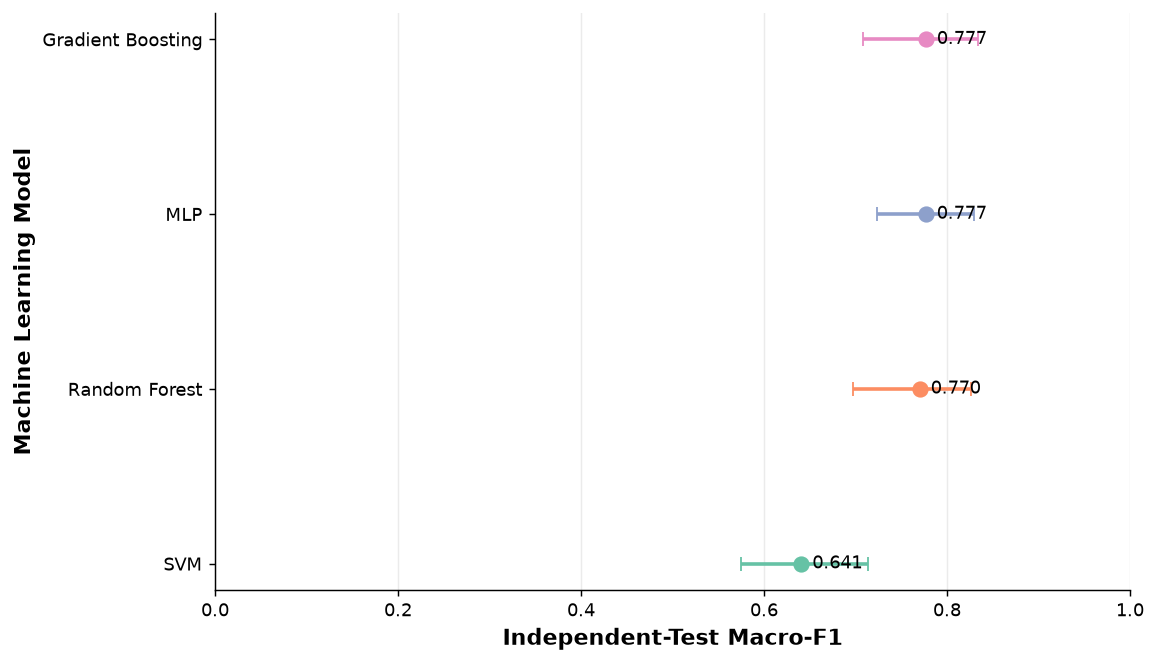

In [235]:
# Step 5 — PRBS-NRZ Configuration-based performance

plot_macro_f1_with_ci(
    campaign="PRBS_NRZ",
    scenario="Configuration-based",
    figure_data=performance_figure_data,
    filename="macro_f1_prbs_config"
)

Saved: figures\macro_f1_prbs_telemetry.pdf


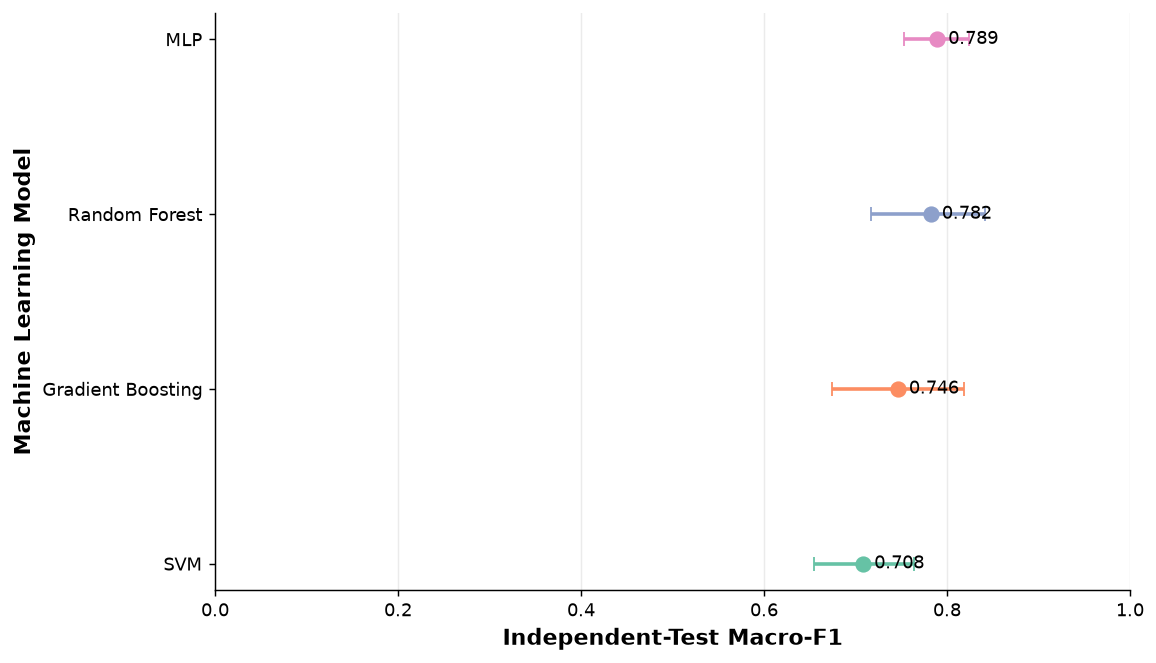

In [236]:
# Step 6 — PRBS-NRZ Telemetry-assisted performance

plot_macro_f1_with_ci(
    campaign="PRBS_NRZ",
    scenario="Telemetry-assisted",
    figure_data=performance_figure_data,
    filename="macro_f1_prbs_telemetry"
)

Saved: figures\macro_f1_lte_config.pdf


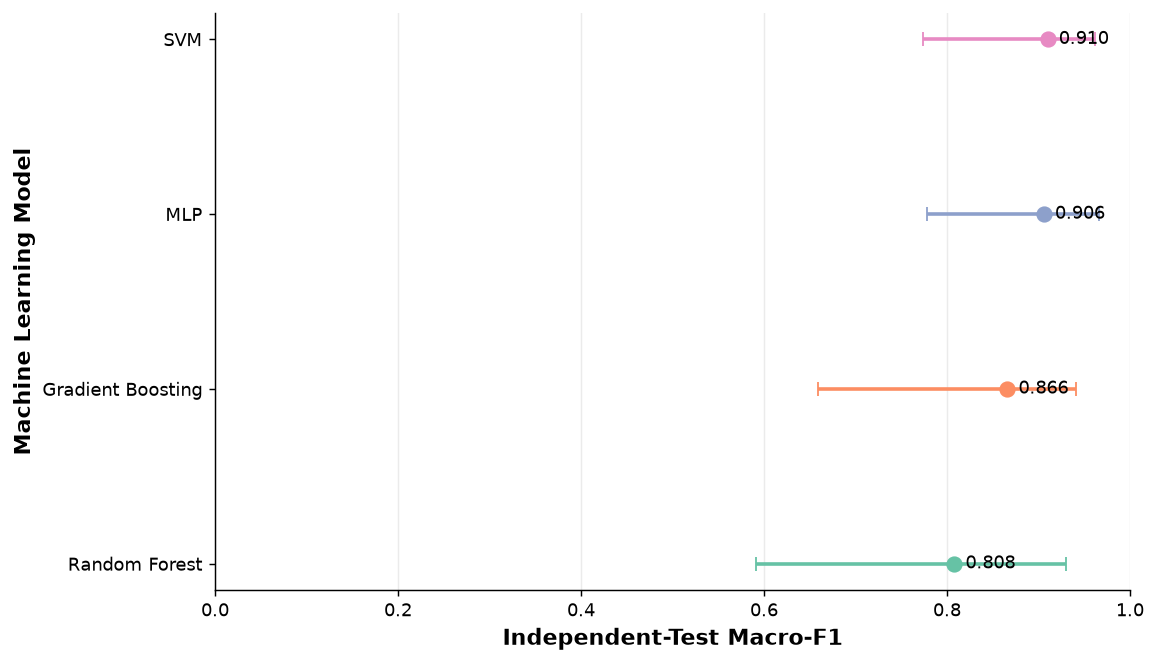

In [237]:
# Step 7 — LTE-QPSK Configuration-based performance

plot_macro_f1_with_ci(
    campaign="LTE_QPSK",
    scenario="Configuration-based",
    figure_data=performance_figure_data,
    filename="macro_f1_lte_config"
)

Saved: figures\macro_f1_lte_telemetry.pdf


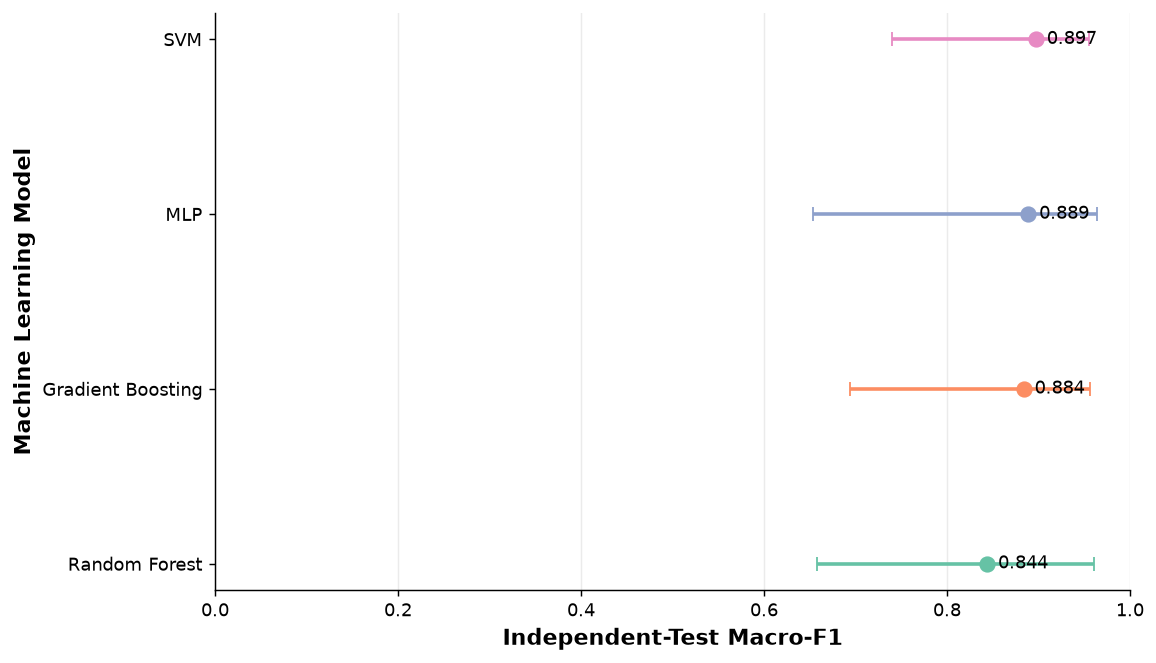

In [238]:
# Step 8 — LTE-QPSK Telemetry-assisted performance

plot_macro_f1_with_ci(
    campaign="LTE_QPSK",
    scenario="Telemetry-assisted",
    figure_data=performance_figure_data,
    filename="macro_f1_lte_telemetry"
)

### Step 9 — Define the receiver-side telemetry-effect visualization

The difference between Telemetry-assisted and Configuration-based Macro-F1 is
visualized together with its paired group-bootstrap 95% confidence interval.

Positive values indicate higher Macro-F1 after including receiver-side optical
power.

The vertical dashed line at zero represents no change between predictor
scenarios.

Confidence intervals entirely above zero indicate a consistently positive
telemetry effect across the resampled experimental groups.

In [239]:
# Step 9 — Publication-ready telemetry-effect figure
# No title inside the figure
# Save as PDF in figures/

def plot_telemetry_delta(
    campaign,
    delta_data,
    filename=None
):

    plot_data = (
        delta_data[
            delta_data["Campaign"] == campaign
        ]
        .sort_values(
            "Mean Delta Macro-F1",
            ascending=True
        )
        .reset_index(drop=True)
    )

    y_position = np.arange(len(plot_data))

    plt.figure(
        figsize=(9, 5.2),
        dpi=130
    )

    for i, row in plot_data.iterrows():

        lower_error = row["Mean Delta Macro-F1"] - row["CI lower"]
        upper_error = row["CI upper"] - row["Mean Delta Macro-F1"]

        plt.errorbar(
            x=row["Mean Delta Macro-F1"],
            y=i,
            xerr=np.array([[lower_error], [upper_error]]),
            fmt="o",
            markersize=8,
            capsize=4,
            elinewidth=2,
            color=SET2[i % len(SET2)],
            ecolor=SET2[i % len(SET2)]
        )

        plt.text(
            row["Mean Delta Macro-F1"] + 0.004,
            i,
            f'{row["Mean Delta Macro-F1"]:+.3f}',
            va="center",
            fontsize=ANNOT_SIZE
        )

    plt.axvline(
        x=0,
        linestyle="--",
        linewidth=1.5
    )

    plt.yticks(
        y_position,
        plot_data["Model"],
        fontsize=TICK_SIZE
    )

    plt.xticks(fontsize=TICK_SIZE)

    plt.xlabel(
        "Delta Macro-F1 (Telemetry - Configuration)",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    plt.ylabel(
        "Machine Learning Model",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    plt.grid(
        axis="x",
        alpha=0.25
    )

    ax = plt.gca()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if filename is not None:
        output_path = FIGURES_DIR / f"{filename}.pdf"
        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )
        print(f"Saved: {output_path}")

    plt.show()

### Steps 10–11 — Independent-Test contribution of received optical power

The effect of received optical power is evaluated independently for PRBS-NRZ
and LTE-QPSK.

The paired uncertainty intervals show that the predictive contribution of
`prx_dbm` depends on both the classifier and the experimental campaign.

An effect should not be interpreted as consistently positive when its
confidence interval crosses or touches zero.

Saved: figures\telemetry_effect_prbs.pdf


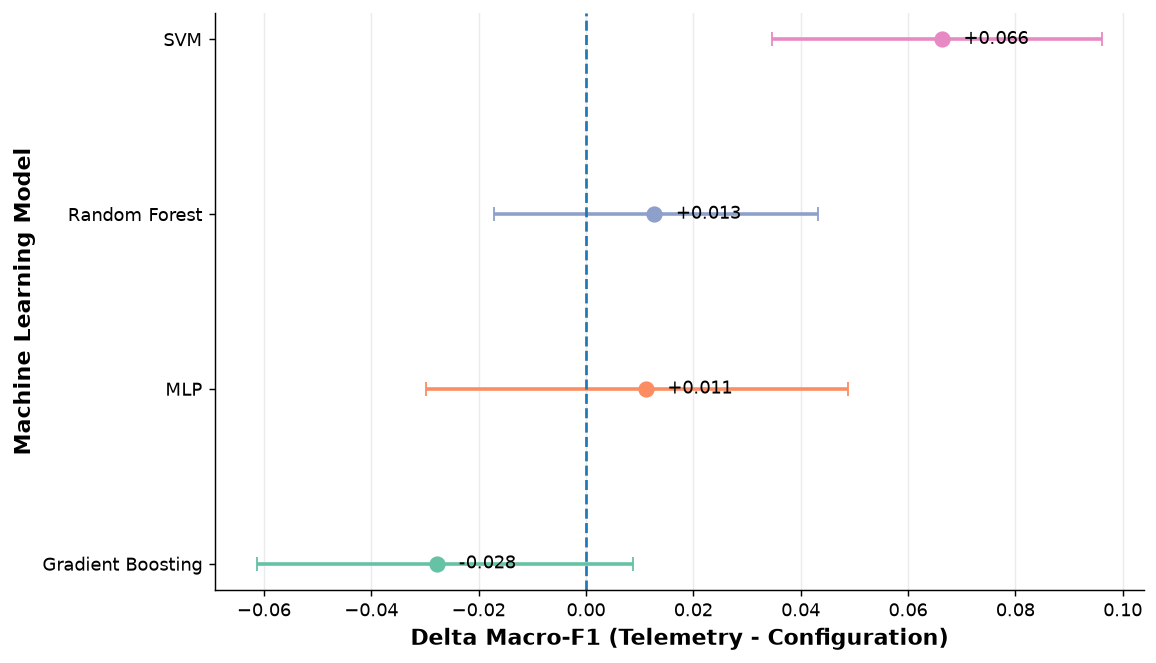

In [240]:
# Step 10 — PRBS-NRZ telemetry contribution

plot_telemetry_delta(
    campaign="PRBS_NRZ",
    delta_data=telemetry_delta_ci,
    filename="telemetry_effect_prbs"
)

Saved: figures\telemetry_effect_lte.pdf


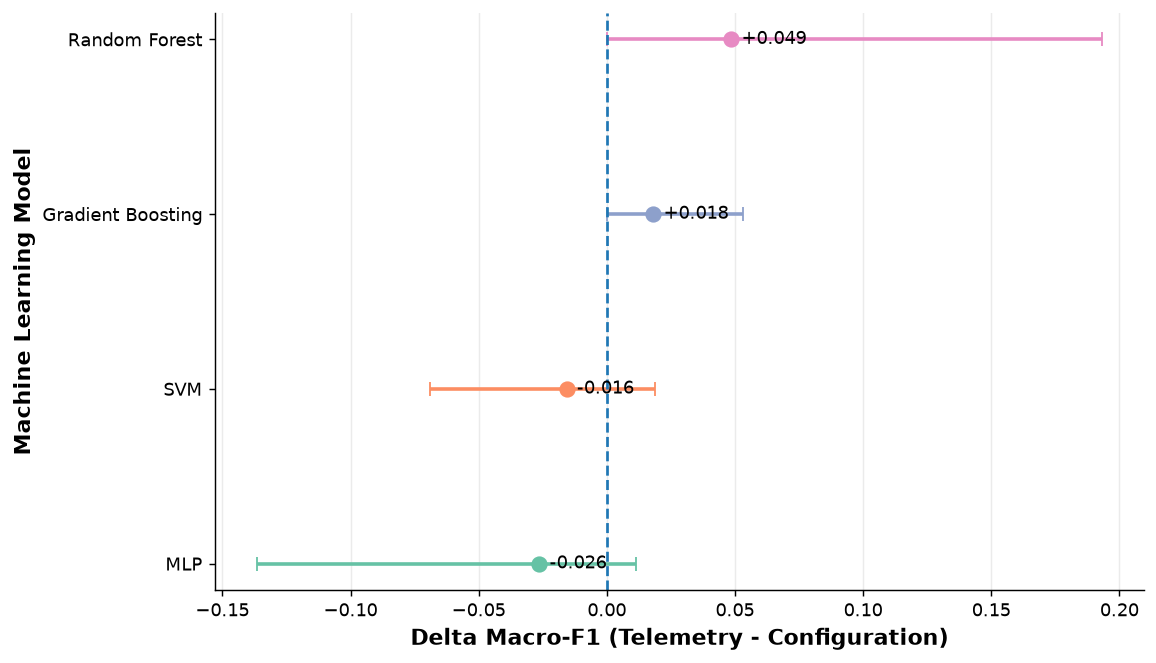

In [241]:
# Step 11 — LTE-QPSK telemetry contribution

plot_telemetry_delta(
    campaign="LTE_QPSK",
    delta_data=telemetry_delta_ci,
    filename="telemetry_effect_lte"
)

In [242]:
# Step 12 — Publication-ready permutation-importance figure
# Improved label positioning
# No title inside the figure
# Save as PDF in figures/

def plot_feature_importance(
    importance_df,
    campaign,
    scenario,
    top_n=10,
    filename=None
):

    plot_data = (
        importance_df
        .head(top_n)
        .sort_values(
            "Importance mean",
            ascending=True
        )
        .reset_index(drop=True)
    )

    y_position = np.arange(len(plot_data))

    colors = [
        SET2[i % len(SET2)]
        for i in range(len(plot_data))
    ]

    # Maximum value including the error bar
    max_value = (
        plot_data["Importance mean"]
        +
        plot_data["Importance std"]
    ).max()

    # Dynamic space between bar/error bar and numerical label
    label_offset = max_value * 0.035

    fig, ax = plt.subplots(
        figsize=(9, 5.8),
        dpi=130
    )

    bars = ax.barh(
        y_position,
        plot_data["Importance mean"],
        xerr=plot_data["Importance std"],
        capsize=4,
        color=colors
    )

    ax.set_yticks(y_position)

    ax.set_yticklabels(
        plot_data["Feature"],
        fontsize=TICK_SIZE
    )

    # Add numerical values after the error bar
    for i, row in plot_data.iterrows():

        label_x = (
            row["Importance mean"]
            +
            row["Importance std"]
            +
            label_offset
        )

        ax.text(
            label_x,
            i,
            f'{row["Importance mean"]:.3f}',
            va="center",
            ha="left",
            fontsize=ANNOT_SIZE,
            fontweight="bold"
        )

    ax.set_xlabel(
        "Permutation importance",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Predictor",
        fontsize=LABEL_SIZE,
        fontweight="bold"
    )

    ax.tick_params(
        axis="x",
        labelsize=TICK_SIZE
    )

    # Extra space on the right for the labels
    ax.set_xlim(
        0,
        max_value * 1.22
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Put grid behind the bars
    ax.set_axisbelow(True)

    plt.tight_layout()

    if filename is not None:

        output_path = FIGURES_DIR / f"{filename}.pdf"

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(f"Saved: {output_path}")

    plt.show()

Saved: figures\feature_importance_prbs_config.pdf


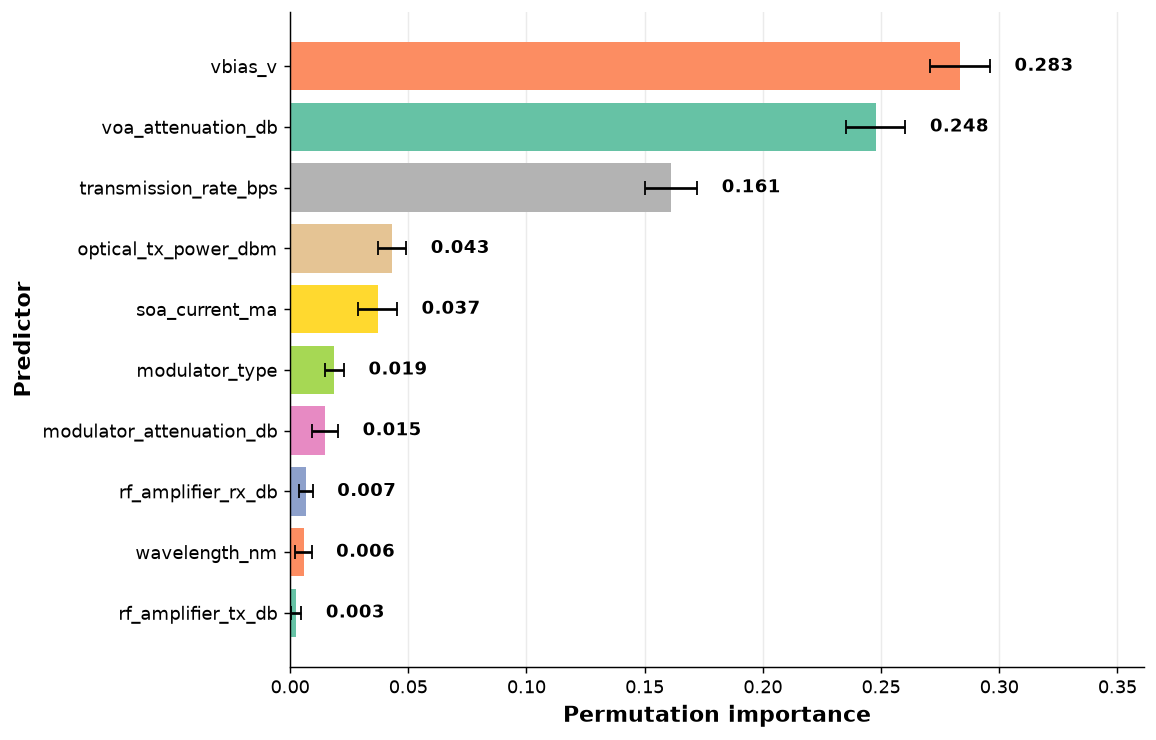

In [243]:
# Step 13 — PRBS-NRZ Configuration-based feature importance

plot_feature_importance(
    importance_df=prbs_config_importance,
    campaign="PRBS-NRZ",
    scenario="Configuration-based",
    top_n=10,
    filename="feature_importance_prbs_config"
)

### Steps 13–16 — Campaign-specific permutation feature importance

Permutation feature importance reveals different predictive structures across
the two experimental campaigns.

PRBS-NRZ relies strongly on modulator bias voltage, controlled optical
attenuation, and transmission rate.

LTE-QPSK shows a particularly strong dependence on VOA attenuation in the
Configuration-based scenario.

When receiver-side optical power is available, `prx_dbm` becomes the
highest-ranked predictor for LTE-QPSK and one of the principal predictors for
PRBS-NRZ.

These differences support campaign-specific interpretation rather than a single
global feature-importance ranking for the complete dataset.

Saved: figures\feature_importance_prbs_config.pdf


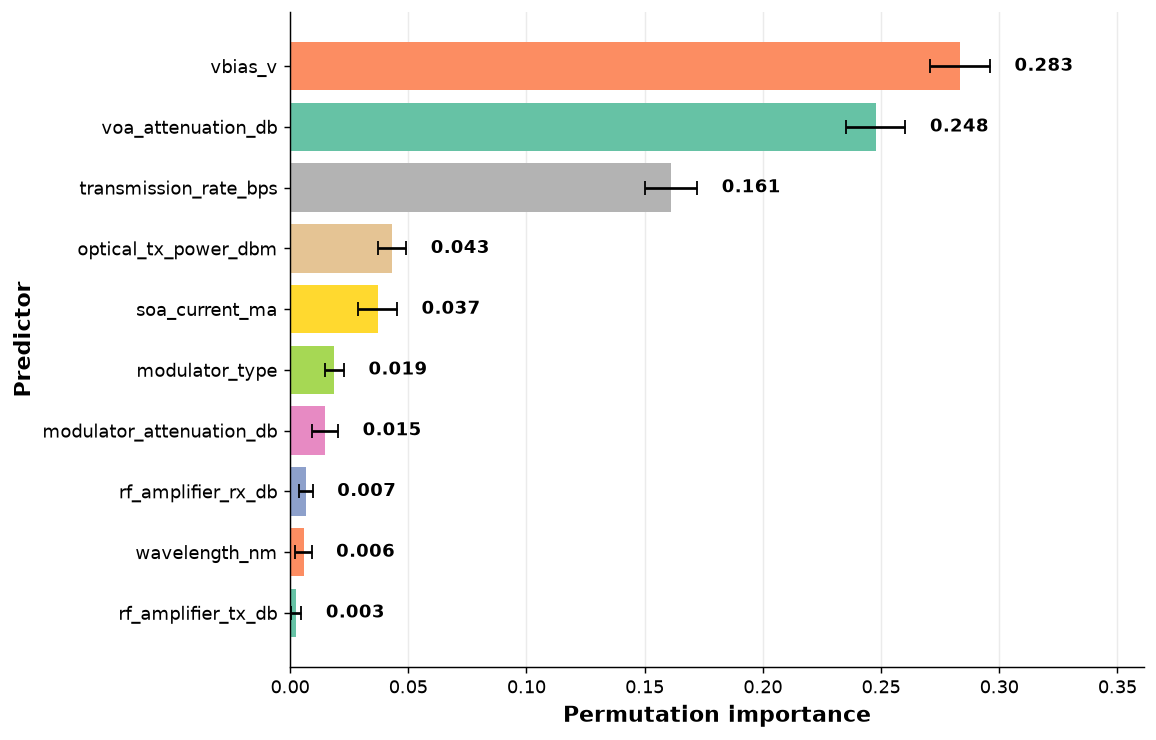

In [244]:
# Step 13 — PRBS-NRZ Configuration-based feature importance

plot_feature_importance(
    importance_df=prbs_config_importance,
    campaign="PRBS-NRZ",
    scenario="Configuration-based",
    top_n=10,
    filename="feature_importance_prbs_config"
)

Saved: figures\feature_importance_prbs_telemetry.pdf


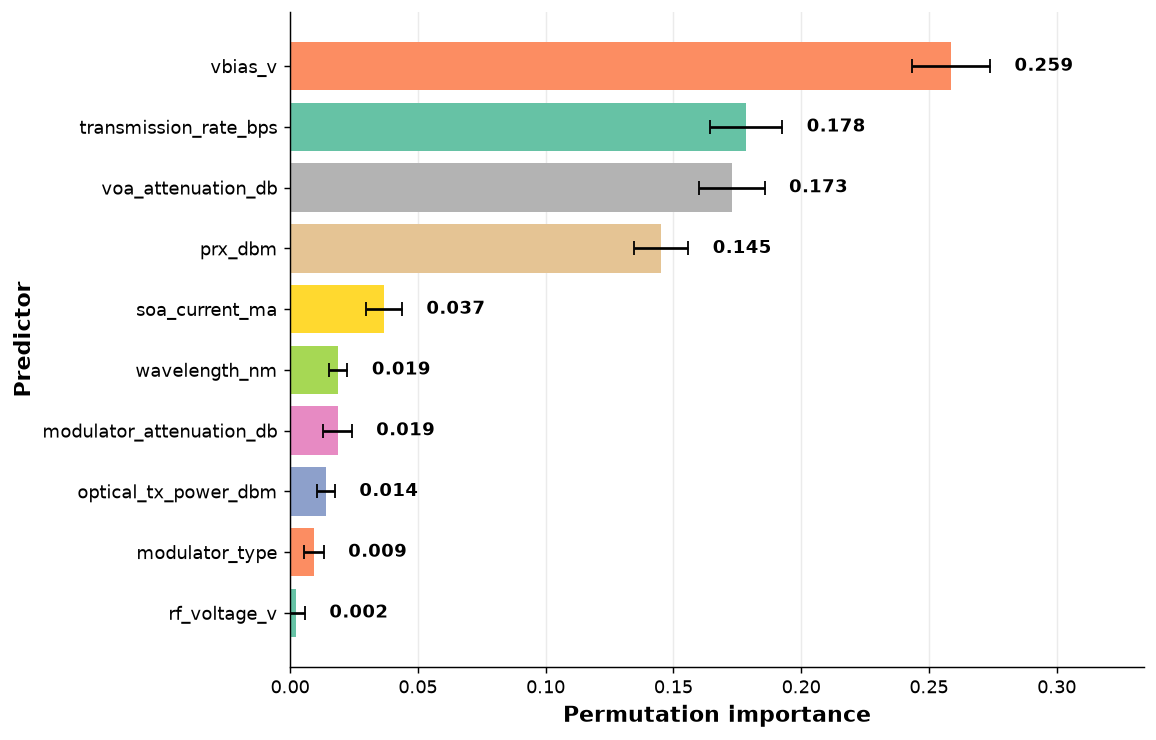

In [245]:
# Step 14 — PRBS-NRZ Telemetry-assisted feature importance

plot_feature_importance(
    importance_df=prbs_telemetry_importance,
    campaign="PRBS-NRZ",
    scenario="Telemetry-assisted",
    top_n=10,
    filename="feature_importance_prbs_telemetry"
)

Saved: figures\feature_importance_lte_config.pdf


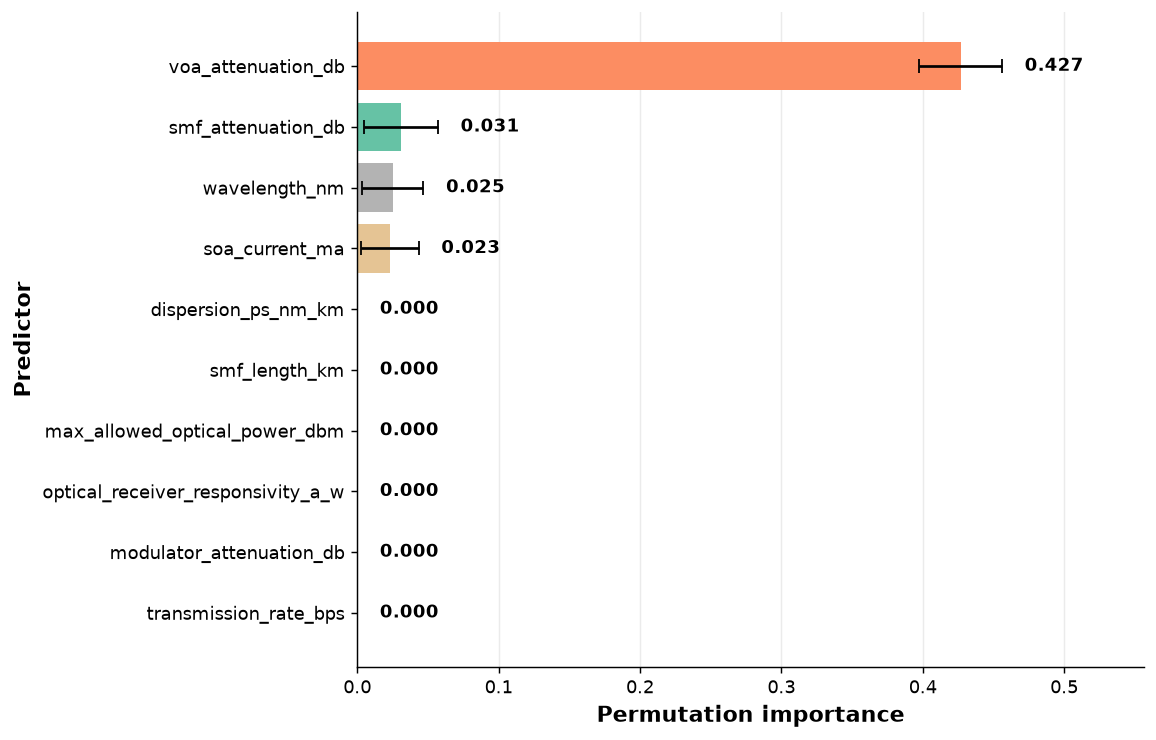

In [246]:
# Step 15 — LTE-QPSK Configuration-based feature importance

plot_feature_importance(
    importance_df=lte_config_importance,
    campaign="LTE-QPSK",
    scenario="Configuration-based",
    top_n=10,
    filename="feature_importance_lte_config"
)

Saved: figures\feature_importance_lte_telemetry.pdf


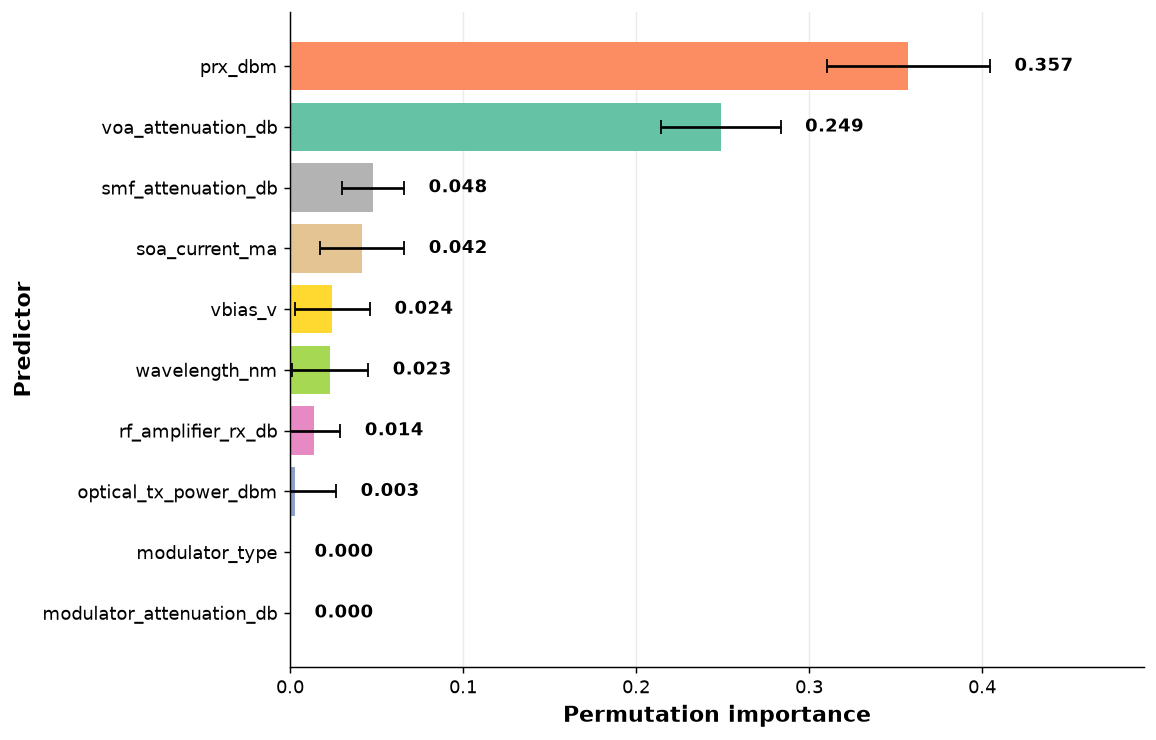

In [247]:
# Step 16 — LTE-QPSK Telemetry-assisted feature importance

plot_feature_importance(
    importance_df=lte_telemetry_importance,
    campaign="LTE-QPSK",
    scenario="Telemetry-assisted",
    top_n=10,
    filename="feature_importance_lte_telemetry"
)

In [248]:
# Step 17 — Validate publication-ready figure data

activity13_checks = {

    "Sixteen Test performance results available":
        len(performance_figure_data) == 16,

    "All Macro-F1 confidence intervals available":
        performance_figure_data[
            ["CI lower", "CI upper"]
        ].notna().all().all(),

    "Eight paired telemetry-effect intervals available":
        len(telemetry_delta_ci) == 8,

    "PRBS Configuration feature importance available":
        len(prbs_config_importance) == 20,

    "PRBS Telemetry feature importance available":
        len(prbs_telemetry_importance) == 21,

    "LTE Configuration feature importance available":
        len(lte_config_importance) == 20,

    "LTE Telemetry feature importance available":
        len(lte_telemetry_importance) == 21,

    "No model retraining performed":
        True
}

activity13_summary = pd.DataFrame(
    activity13_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(activity13_summary)

,Validation,Passed
0,Sixteen Test performance results available,True
1,All Macro-F1 confidence intervals available,True
2,Eight paired telemetry-effect intervals available,True
3,PRBS Configuration feature importance available,True
4,PRBS Telemetry feature importance available,True
5,LTE Configuration feature importance available,True
6,LTE Telemetry feature importance available,True
7,No model retraining performed,True


In [249]:
# Step 18 — Final decision for Activity 13

activity13_passed = (
    activity13_summary["Passed"].all()
)

if activity13_passed:

    print("=" * 70)
    print("ACTIVITY 13 — PASSED")
    print("=" * 70)

    print(
        "Publication-ready performance and interpretability "
        "figures were successfully generated."
    )

    print(
        "The figures incorporate independent-Test results, "
        "group-level uncertainty estimates, and permutation "
        "feature importance."
    )

    print(
        "No additional model training or Test-driven "
        "optimization was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 13 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity13_summary[
            ~activity13_summary["Passed"]
        ]
    )

ACTIVITY 13 — PASSED
Publication-ready performance and interpretability figures were successfully generated.
The figures incorporate independent-Test results, group-level uncertainty estimates, and permutation feature importance.
No additional model training or Test-driven optimization was performed.


# Activity 14 — Final Results Tables for the Paper

## Objective

The objective of this activity is to consolidate the validated machine learning
results into compact, publication-ready tables.

No model training, hyperparameter optimization, or additional Test evaluation
is performed.

The activity summarizes:

- independent-Test classification performance;
- 95% group-bootstrap confidence intervals for Macro-F1;
- Configuration-based versus Telemetry-assisted performance;
- paired group-bootstrap uncertainty for the telemetry effect;
- selected hyperparameters;
- class-specific performance.

All reported values originate from the previously validated experimental
workflow.

In [250]:
# Step 2 — Create output folder for publication tables

from pathlib import Path

TABLES_DIR = Path("tables")
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Tables will be saved in:")
print(TABLES_DIR.resolve())

Tables will be saved in:
C:\Users\jarguero\Documents\Experimental_MLdataset\tables


In [251]:
# Step 3 — Define compact model names

MODEL_NAME_MAP = {
    "Random Forest": "RF",
    "Gradient Boosting": "GB",
    "SVM": "SVM",
    "MLP": "MLP"
}

print(MODEL_NAME_MAP)

{'Random Forest': 'RF', 'Gradient Boosting': 'GB', 'SVM': 'SVM', 'MLP': 'MLP'}


In [252]:
print(
    test_performance["Model"].unique()
)

<ArrowStringArray>
['SVM', 'MLP', 'Gradient Boosting', 'Random Forest']
Length: 4, dtype: str


In [253]:
# Step 4A — Inspect the actual columns of test_performance

print("Columns in test_performance:")
print(test_performance.columns.tolist())

print("\nShape:")
print(test_performance.shape)

display(
    test_performance.head()
)

Columns in test_performance:
['Campaign', 'Scenario', 'Model', 'Test observations', 'Test groups', 'Accuracy', 'Macro-F1', 'Weighted-F1', 'Balanced Accuracy', 'MCC', 'ROC-AUC Macro OvR']

Shape:
(16, 11)


,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1,Weighted-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE_QPSK,Configuration-based,SVM,316,57,0.981013,0.910161,0.980226,0.877451,0.897750,0.930876
1,LTE_QPSK,Configuration-based,MLP,316,57,0.977848,0.905979,0.977970,0.914359,0.886622,0.981425
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.971519,0.866098,0.971731,0.873917,0.854187,0.983972
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.965190,0.808144,0.964287,0.812595,0.819521,0.981011
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.977848,0.897071,0.976669,0.875048,0.881399,0.914870


In [254]:
# Step 4B — Check which expected columns are available

expected_columns = [
    "Campaign",
    "Scenario",
    "Model",
    "Accuracy",
    "Macro-F1",
    "Weighted F1",
    "Balanced Accuracy",
    "MCC",
    "ROC-AUC Macro OvR"
]

for column in expected_columns:

    if column in test_performance.columns:
        print(f"FOUND   : {column}")
    else:
        print(f"MISSING : {column}")

FOUND   : Campaign
FOUND   : Scenario
FOUND   : Model
FOUND   : Accuracy
FOUND   : Macro-F1
MISSING : Weighted F1
FOUND   : Balanced Accuracy
FOUND   : MCC
FOUND   : ROC-AUC Macro OvR


In [255]:
test_performance.columns.tolist()

['Campaign',
 'Scenario',
 'Model',
 'Test observations',
 'Test groups',
 'Accuracy',
 'Macro-F1',
 'Weighted-F1',
 'Balanced Accuracy',
 'MCC',
 'ROC-AUC Macro OvR']

In [256]:
# Step 4 — Build the main independent-Test performance table
# Uses the exact column names from test_performance

main_results_table = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Test observations",
            "Test groups",
            "Accuracy",
            "Macro-F1",
            "Weighted-F1",
            "Balanced Accuracy",
            "MCC",
            "ROC-AUC Macro OvR"
        ]
    ]
    .merge(
        macro_f1_ci[
            [
                "Campaign",
                "Scenario",
                "Model",
                "CI lower",
                "CI upper"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

display(
    main_results_table.round(4)
)

,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1,Weighted-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR,CI lower,CI upper
0,LTE_QPSK,Configuration-based,SVM,316,57,0.9810,0.9102,0.9802,0.8775,0.8977,0.9309,0.7738,0.9616
1,LTE_QPSK,Configuration-based,MLP,316,57,0.9778,0.9060,0.9780,0.9144,0.8866,0.9814,0.7786,0.9658
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.9715,0.8661,0.9717,0.8739,0.8542,0.9840,0.6595,0.9412
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.9652,0.8081,0.9643,0.8126,0.8195,0.9810,0.5911,0.9302
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.9778,0.8971,0.9767,0.8750,0.8814,0.9149,0.7396,0.9554
5,LTE_QPSK,Telemetry-assisted,MLP,316,57,0.9747,0.8887,0.9752,0.8960,0.8707,0.9856,0.6532,0.9639
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,316,57,0.9778,0.8838,0.9775,0.8763,0.8834,0.9745,0.6934,0.9564
7,LTE_QPSK,Telemetry-assisted,Random Forest,316,57,0.9715,0.8438,0.9699,0.8518,0.8531,0.9768,0.6583,0.9605
8,PRBS_NRZ,Configuration-based,Gradient Boosting,909,227,0.8405,0.7769,0.8371,0.7715,0.7395,0.9268,0.7079,0.8340
9,PRBS_NRZ,Configuration-based,MLP,909,227,0.8449,0.7768,0.8379,0.7673,0.7458,0.9421,0.7239,0.8294


In [257]:
# Step 4B — Verify the merged results table

print("Shape:", main_results_table.shape)

print("\nColumns:")
print(main_results_table.columns.tolist())

print("\nMissing confidence intervals:")
print(
    main_results_table[
        ["CI lower", "CI upper"]
    ].isna().sum()
)

display(
    main_results_table.head()
)

Shape: (16, 13)

Columns:
['Campaign', 'Scenario', 'Model', 'Test observations', 'Test groups', 'Accuracy', 'Macro-F1', 'Weighted-F1', 'Balanced Accuracy', 'MCC', 'ROC-AUC Macro OvR', 'CI lower', 'CI upper']

Missing confidence intervals:
CI lower    0
CI upper    0
dtype: int64


,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1,Weighted-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR,CI lower,CI upper
0,LTE_QPSK,Configuration-based,SVM,316,57,0.981013,0.910161,0.980226,0.877451,0.897750,0.930876,0.773821,0.961584
1,LTE_QPSK,Configuration-based,MLP,316,57,0.977848,0.905979,0.977970,0.914359,0.886622,0.981425,0.778628,0.965767
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.971519,0.866098,0.971731,0.873917,0.854187,0.983972,0.659485,0.941178
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.965190,0.808144,0.964287,0.812595,0.819521,0.981011,0.591085,0.930193
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.977848,0.897071,0.976669,0.875048,0.881399,0.914870,0.739570,0.955396


In [258]:
# Step 5 — Create formatted Macro-F1 with 95% CI

main_results_table["Macro-F1 [95% CI]"] = (
    main_results_table.apply(
        lambda row:
        f'{row["Macro-F1"]:.4f} '
        f'[{row["CI lower"]:.4f}, {row["CI upper"]:.4f}]',
        axis=1
    )
)

display(
    main_results_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Test observations",
            "Test groups",
            "Accuracy",
            "Macro-F1 [95% CI]",
            "Balanced Accuracy",
            "MCC",
            "ROC-AUC Macro OvR"
        ]
    ]
)

,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1 [95% CI],Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE_QPSK,Configuration-based,SVM,316,57,0.981013,"0.9102 [0.7738, 0.9616]",0.877451,0.897750,0.930876
1,LTE_QPSK,Configuration-based,MLP,316,57,0.977848,"0.9060 [0.7786, 0.9658]",0.914359,0.886622,0.981425
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.971519,"0.8661 [0.6595, 0.9412]",0.873917,0.854187,0.983972
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.965190,"0.8081 [0.5911, 0.9302]",0.812595,0.819521,0.981011
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.977848,"0.8971 [0.7396, 0.9554]",0.875048,0.881399,0.914870
5,LTE_QPSK,Telemetry-assisted,MLP,316,57,0.974684,"0.8887 [0.6532, 0.9639]",0.895976,0.870691,0.985604
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,316,57,0.977848,"0.8838 [0.6934, 0.9564]",0.876273,0.883437,0.974529
7,LTE_QPSK,Telemetry-assisted,Random Forest,316,57,0.971519,"0.8438 [0.6583, 0.9605]",0.851811,0.853117,0.976849
8,PRBS_NRZ,Configuration-based,Gradient Boosting,909,227,0.840484,"0.7769 [0.7079, 0.8340]",0.771473,0.739545,0.926825
9,PRBS_NRZ,Configuration-based,MLP,909,227,0.844884,"0.7768 [0.7239, 0.8294]",0.767288,0.745829,0.942073


In [259]:
# Step 6 — Create compact publication-ready performance table

publication_performance_table = (
    main_results_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Macro-F1"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    [
        [
            "Campaign",
            "Scenario",
            "Model",
            "Test observations",
            "Test groups",
            "Accuracy",
            "Macro-F1 [95% CI]",
            "Balanced Accuracy",
            "MCC",
            "ROC-AUC Macro OvR"
        ]
    ]
    .reset_index(drop=True)
)

display(
    publication_performance_table
)

,Campaign,Scenario,Model,Test observations,Test groups,Accuracy,Macro-F1 [95% CI],Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE_QPSK,Configuration-based,SVM,316,57,0.981013,"0.9102 [0.7738, 0.9616]",0.877451,0.897750,0.930876
1,LTE_QPSK,Configuration-based,MLP,316,57,0.977848,"0.9060 [0.7786, 0.9658]",0.914359,0.886622,0.981425
2,LTE_QPSK,Configuration-based,Gradient Boosting,316,57,0.971519,"0.8661 [0.6595, 0.9412]",0.873917,0.854187,0.983972
3,LTE_QPSK,Configuration-based,Random Forest,316,57,0.965190,"0.8081 [0.5911, 0.9302]",0.812595,0.819521,0.981011
4,LTE_QPSK,Telemetry-assisted,SVM,316,57,0.977848,"0.8971 [0.7396, 0.9554]",0.875048,0.881399,0.914870
5,LTE_QPSK,Telemetry-assisted,MLP,316,57,0.974684,"0.8887 [0.6532, 0.9639]",0.895976,0.870691,0.985604
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,316,57,0.977848,"0.8838 [0.6934, 0.9564]",0.876273,0.883437,0.974529
7,LTE_QPSK,Telemetry-assisted,Random Forest,316,57,0.971519,"0.8438 [0.6583, 0.9605]",0.851811,0.853117,0.976849
8,PRBS_NRZ,Configuration-based,Gradient Boosting,909,227,0.840484,"0.7769 [0.7079, 0.8340]",0.771473,0.739545,0.926825
9,PRBS_NRZ,Configuration-based,MLP,909,227,0.844884,"0.7768 [0.7239, 0.8294]",0.767288,0.745829,0.942073


In [260]:
# Step 8 — Create Configuration vs Telemetry comparison table

scenario_macro_f1 = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .pivot_table(
        index=[
            "Campaign",
            "Model"
        ],
        columns="Scenario",
        values="Macro-F1"
    )
    .reset_index()
)

display(
    scenario_macro_f1.round(4)
)

Scenario,Campaign,Model,Configuration-based,Telemetry-assisted
0,LTE_QPSK,Gradient Boosting,0.8661,0.8838
1,LTE_QPSK,MLP,0.9060,0.8887
2,LTE_QPSK,Random Forest,0.8081,0.8438
3,LTE_QPSK,SVM,0.9102,0.8971
4,PRBS_NRZ,Gradient Boosting,0.7769,0.7463
5,PRBS_NRZ,MLP,0.7768,0.7893
6,PRBS_NRZ,Random Forest,0.7702,0.7823
7,PRBS_NRZ,SVM,0.6408,0.7084


In [261]:
# Step 9 — Add paired group-bootstrap telemetry effect

telemetry_comparison_table = (
    scenario_macro_f1
    .merge(
        telemetry_delta_ci[
            [
                "Campaign",
                "Model",
                "Mean Delta Macro-F1",
                "CI lower",
                "CI upper"
            ]
        ],
        on=[
            "Campaign",
            "Model"
        ],
        how="left"
    )
)

display(
    telemetry_comparison_table.round(5)
)

,Campaign,Model,Configuration-based,Telemetry-assisted,Mean Delta Macro-F1,CI lower,CI upper
0,LTE_QPSK,Gradient Boosting,0.86610,0.88375,0.01813,0.00000,0.05313
1,LTE_QPSK,MLP,0.90598,0.88872,-0.02633,-0.13640,0.01126
2,LTE_QPSK,Random Forest,0.80814,0.84380,0.04855,0.00000,0.19311
3,LTE_QPSK,SVM,0.91016,0.89707,-0.01567,-0.06894,0.01866
4,PRBS_NRZ,Gradient Boosting,0.77688,0.74633,-0.02769,-0.06124,0.00874
5,PRBS_NRZ,MLP,0.77678,0.78930,0.01116,-0.02975,0.04882
6,PRBS_NRZ,Random Forest,0.77020,0.78233,0.01276,-0.01721,0.04331
7,PRBS_NRZ,SVM,0.64078,0.70843,0.06633,0.03459,0.09610


In [262]:
# Step 10 — Format telemetry-effect uncertainty

telemetry_comparison_table[
    "Delta Macro-F1 [95% CI]"
] = (
    telemetry_comparison_table.apply(
        lambda row:
        f'{row["Mean Delta Macro-F1"]:+.4f} '
        f'[{row["CI lower"]:+.4f}, {row["CI upper"]:+.4f}]',
        axis=1
    )
)

display(
    telemetry_comparison_table[
        [
            "Campaign",
            "Model",
            "Configuration-based",
            "Telemetry-assisted",
            "Delta Macro-F1 [95% CI]"
        ]
    ].round(4)
)

,Campaign,Model,Configuration-based,Telemetry-assisted,Delta Macro-F1 [95% CI]
0,LTE_QPSK,Gradient Boosting,0.8661,0.8838,"+0.0181 [+0.0000, +0.0531]"
1,LTE_QPSK,MLP,0.9060,0.8887,"-0.0263 [-0.1364, +0.0113]"
2,LTE_QPSK,Random Forest,0.8081,0.8438,"+0.0486 [+0.0000, +0.1931]"
3,LTE_QPSK,SVM,0.9102,0.8971,"-0.0157 [-0.0689, +0.0187]"
4,PRBS_NRZ,Gradient Boosting,0.7769,0.7463,"-0.0277 [-0.0612, +0.0087]"
5,PRBS_NRZ,MLP,0.7768,0.7893,"+0.0112 [-0.0298, +0.0488]"
6,PRBS_NRZ,Random Forest,0.7702,0.7823,"+0.0128 [-0.0172, +0.0433]"
7,PRBS_NRZ,SVM,0.6408,0.7084,"+0.0663 [+0.0346, +0.0961]"


In [263]:
# Step 11 — Determine whether the paired CI excludes zero

telemetry_comparison_table[
    "CI excludes zero"
] = (
    (
        telemetry_comparison_table["CI lower"] > 0
    )
    |
    (
        telemetry_comparison_table["CI upper"] < 0
    )
)

display(
    telemetry_comparison_table[
        [
            "Campaign",
            "Model",
            "Configuration-based",
            "Telemetry-assisted",
            "Delta Macro-F1 [95% CI]",
            "CI excludes zero"
        ]
    ].round(4)
)

,Campaign,Model,Configuration-based,Telemetry-assisted,Delta Macro-F1 [95% CI],CI excludes zero
0,LTE_QPSK,Gradient Boosting,0.8661,0.8838,"+0.0181 [+0.0000, +0.0531]",False
1,LTE_QPSK,MLP,0.9060,0.8887,"-0.0263 [-0.1364, +0.0113]",False
2,LTE_QPSK,Random Forest,0.8081,0.8438,"+0.0486 [+0.0000, +0.1931]",False
3,LTE_QPSK,SVM,0.9102,0.8971,"-0.0157 [-0.0689, +0.0187]",False
4,PRBS_NRZ,Gradient Boosting,0.7769,0.7463,"-0.0277 [-0.0612, +0.0087]",False
5,PRBS_NRZ,MLP,0.7768,0.7893,"+0.0112 [-0.0298, +0.0488]",False
6,PRBS_NRZ,Random Forest,0.7702,0.7823,"+0.0128 [-0.0172, +0.0433]",False
7,PRBS_NRZ,SVM,0.6408,0.7084,"+0.0663 [+0.0346, +0.0961]",True


In [264]:
# Step 12 — Create compact telemetry comparison table

publication_telemetry_table = (
    telemetry_comparison_table[
        [
            "Campaign",
            "Model",
            "Configuration-based",
            "Telemetry-assisted",
            "Delta Macro-F1 [95% CI]",
            "CI excludes zero"
        ]
    ]
    .copy()
)

publication_telemetry_table[
    [
        "Configuration-based",
        "Telemetry-assisted"
    ]
] = (
    publication_telemetry_table[
        [
            "Configuration-based",
            "Telemetry-assisted"
        ]
    ]
    .round(4)
)

publication_telemetry_table = (
    publication_telemetry_table
    .sort_values(
        [
            "Campaign",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(
    publication_telemetry_table
)

,Campaign,Model,Configuration-based,Telemetry-assisted,Delta Macro-F1 [95% CI],CI excludes zero
0,LTE_QPSK,Gradient Boosting,0.8661,0.8838,"+0.0181 [+0.0000, +0.0531]",False
1,LTE_QPSK,MLP,0.9060,0.8887,"-0.0263 [-0.1364, +0.0113]",False
2,LTE_QPSK,Random Forest,0.8081,0.8438,"+0.0486 [+0.0000, +0.1931]",False
3,LTE_QPSK,SVM,0.9102,0.8971,"-0.0157 [-0.0689, +0.0187]",False
4,PRBS_NRZ,Gradient Boosting,0.7769,0.7463,"-0.0277 [-0.0612, +0.0087]",False
5,PRBS_NRZ,MLP,0.7768,0.7893,"+0.0112 [-0.0298, +0.0488]",False
6,PRBS_NRZ,Random Forest,0.7702,0.7823,"+0.0128 [-0.0172, +0.0433]",False
7,PRBS_NRZ,SVM,0.6408,0.7084,"+0.0663 [+0.0346, +0.0961]",True


In [265]:
# Step 13A — Inspect selected hyperparameters

print("Type:")
print(type(selected_hyperparameters))

print("\nColumns:")
print(selected_hyperparameters.columns.tolist())

print("\nShape:")
print(selected_hyperparameters.shape)

display(
    selected_hyperparameters
)

Type:
<class 'pandas.DataFrame'>

Columns:
['Campaign', 'Scenario', 'Model', 'Best CV Macro-F1', 'n_estimators', 'min_samples_split', 'min_samples_leaf', 'max_features', 'max_depth', 'learning_rate', 'C', 'gamma', 'kernel', 'learning_rate_init', 'hidden_layer_sizes', 'alpha', 'activation']

Shape:
(16, 17)


,Campaign,Scenario,Model,Best CV Macro-F1,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,learning_rate,C,gamma,kernel,learning_rate_init,hidden_layer_sizes,alpha,activation
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.787128,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LTE_QPSK,Configuration-based,MLP,0.846720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh
2,LTE_QPSK,Configuration-based,Random Forest,0.801232,400.0,2.0,2.0,log2,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LTE_QPSK,Configuration-based,SVM,0.807126,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.767035,50.0,10.0,NaN,NaN,5.0,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,LTE_QPSK,Telemetry-assisted,MLP,0.872920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,"(128, 64, 32)",0.01,tanh
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.795134,100.0,2.0,1.0,log2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,LTE_QPSK,Telemetry-assisted,SVM,0.828510,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.733397,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PRBS_NRZ,Configuration-based,MLP,0.712473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh


In [266]:
display(
    selected_hyperparameters.head(20)
)

,Campaign,Scenario,Model,Best CV Macro-F1,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,learning_rate,C,gamma,kernel,learning_rate_init,hidden_layer_sizes,alpha,activation
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.787128,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LTE_QPSK,Configuration-based,MLP,0.846720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh
2,LTE_QPSK,Configuration-based,Random Forest,0.801232,400.0,2.0,2.0,log2,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LTE_QPSK,Configuration-based,SVM,0.807126,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.767035,50.0,10.0,NaN,NaN,5.0,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,LTE_QPSK,Telemetry-assisted,MLP,0.872920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0005,"(128, 64, 32)",0.01,tanh
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.795134,100.0,2.0,1.0,log2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,LTE_QPSK,Telemetry-assisted,SVM,0.828510,NaN,NaN,NaN,NaN,NaN,NaN,100.0,scale,rbf,NaN,NaN,NaN,NaN
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.733397,250.0,10.0,NaN,NaN,5.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PRBS_NRZ,Configuration-based,MLP,0.712473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,"(128, 64, 32)",0.01,tanh


In [267]:
# Step 13B — Create compact hyperparameter descriptions

def format_hyperparameters(row):

    model = row["Model"]

    if model == "Random Forest":

        max_depth = (
            "None"
            if pd.isna(row["max_depth"])
            else str(int(row["max_depth"]))
        )

        max_features = (
            "None"
            if pd.isna(row["max_features"])
            else str(row["max_features"])
        )

        return (
            f'n_estimators={int(row["n_estimators"])}, '
            f'max_depth={max_depth}, '
            f'max_features={max_features}, '
            f'min_samples_split={int(row["min_samples_split"])}, '
            f'min_samples_leaf={int(row["min_samples_leaf"])}'
        )

    elif model == "Gradient Boosting":

        return (
            f'n_estimators={int(row["n_estimators"])}, '
            f'learning_rate={row["learning_rate"]:.3g}, '
            f'max_depth={int(row["max_depth"])}, '
            f'min_samples_split={int(row["min_samples_split"])}'
        )

    elif model == "SVM":

        return (
            f'C={row["C"]:.3g}, '
            f'gamma={row["gamma"]}, '
            f'kernel={row["kernel"]}'
        )

    elif model == "MLP":

        return (
            f'hidden_layers={row["hidden_layer_sizes"]}, '
            f'activation={row["activation"]}, '
            f'alpha={row["alpha"]:.3g}, '
            f'learning_rate_init={row["learning_rate_init"]:.4g}'
        )

    else:

        return "Not available"


selected_hyperparameters["Selected hyperparameters"] = (
    selected_hyperparameters.apply(
        format_hyperparameters,
        axis=1
    )
)

In [268]:
# Step 13C — Create publication-ready hyperparameter table

publication_hyperparameters_table = (
    selected_hyperparameters[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1",
            "Selected hyperparameters"
        ]
    ]
    .copy()
)

publication_hyperparameters_table[
    "Best CV Macro-F1"
] = (
    publication_hyperparameters_table[
        "Best CV Macro-F1"
    ].round(4)
)

publication_hyperparameters_table = (
    publication_hyperparameters_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(
    publication_hyperparameters_table
)

,Campaign,Scenario,Model,Best CV Macro-F1,Selected hyperparameters
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.7871,"n_estimators=250, learning_rate=0.1, max_depth..."
1,LTE_QPSK,Configuration-based,MLP,0.8467,"hidden_layers=(128, 64, 32), activation=tanh, ..."
2,LTE_QPSK,Configuration-based,Random Forest,0.8012,"n_estimators=400, max_depth=15, max_features=l..."
3,LTE_QPSK,Configuration-based,SVM,0.8071,"C=100, gamma=scale, kernel=rbf"
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7670,"n_estimators=50, learning_rate=0.2, max_depth=..."
5,LTE_QPSK,Telemetry-assisted,MLP,0.8729,"hidden_layers=(128, 64, 32), activation=tanh, ..."
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,"n_estimators=100, max_depth=None, max_features..."
7,LTE_QPSK,Telemetry-assisted,SVM,0.8285,"C=100, gamma=scale, kernel=rbf"
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7334,"n_estimators=250, learning_rate=0.1, max_depth..."
9,PRBS_NRZ,Configuration-based,MLP,0.7125,"hidden_layers=(128, 64, 32), activation=tanh, ..."


In [269]:
# Step 14A — Inspect class-specific Test results

print("Columns in test_per_class:")
print(test_per_class.columns.tolist())

print("\nShape:")
print(test_per_class.shape)

display(
    test_per_class.head(20)
)

Columns in test_per_class:
['Campaign', 'Scenario', 'Model', 'Class', 'Precision', 'Recall', 'F1', 'Support']

Shape:
(48, 8)


,Campaign,Scenario,Model,Class,Precision,Recall,F1,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,0.750000,0.750000,0.750000,16
1,LTE_QPSK,Configuration-based,Gradient Boosting,Degraded,0.992908,0.989399,0.991150,283
2,LTE_QPSK,Configuration-based,Gradient Boosting,Excellent,0.833333,0.882353,0.857143,17
3,LTE_QPSK,Configuration-based,MLP,Acceptable,0.812500,0.812500,0.812500,16
4,LTE_QPSK,Configuration-based,MLP,Degraded,0.992908,0.989399,0.991150,283
5,LTE_QPSK,Configuration-based,MLP,Excellent,0.888889,0.941176,0.914286,17
6,LTE_QPSK,Configuration-based,Random Forest,Acceptable,0.692308,0.562500,0.620690,16
7,LTE_QPSK,Configuration-based,Random Forest,Degraded,0.992933,0.992933,0.992933,283
8,LTE_QPSK,Configuration-based,Random Forest,Excellent,0.750000,0.882353,0.810811,17
9,LTE_QPSK,Configuration-based,SVM,Acceptable,0.857143,0.750000,0.800000,16


In [270]:
# Step 14B — Create class-specific publication table

publication_per_class_table = (
    test_per_class[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support"
        ]
    ]
    .copy()
)

# Round performance metrics
publication_per_class_table[
    [
        "Precision",
        "Recall",
        "F1"
    ]
] = (
    publication_per_class_table[
        [
            "Precision",
            "Recall",
            "F1"
        ]
    ]
    .round(4)
)

publication_per_class_table = (
    publication_per_class_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Class"
        ]
    )
    .reset_index(drop=True)
)

display(
    publication_per_class_table
)

,Campaign,Scenario,Model,Class,Precision,Recall,F1,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,0.7500,0.7500,0.7500,16
1,LTE_QPSK,Configuration-based,Gradient Boosting,Degraded,0.9929,0.9894,0.9912,283
2,LTE_QPSK,Configuration-based,Gradient Boosting,Excellent,0.8333,0.8824,0.8571,17
3,LTE_QPSK,Configuration-based,MLP,Acceptable,0.8125,0.8125,0.8125,16
4,LTE_QPSK,Configuration-based,MLP,Degraded,0.9929,0.9894,0.9912,283
5,LTE_QPSK,Configuration-based,MLP,Excellent,0.8889,0.9412,0.9143,17
6,LTE_QPSK,Configuration-based,Random Forest,Acceptable,0.6923,0.5625,0.6207,16
7,LTE_QPSK,Configuration-based,Random Forest,Degraded,0.9929,0.9929,0.9929,283
8,LTE_QPSK,Configuration-based,Random Forest,Excellent,0.7500,0.8824,0.8108,17
9,LTE_QPSK,Configuration-based,SVM,Acceptable,0.8571,0.7500,0.8000,16


In [271]:
# Step 14C — Validate class-specific results

class_table_checks = {

    "Forty-eight class-specific results available":
        len(publication_per_class_table) == 48,

    "Three QoT classes represented":
        publication_per_class_table[
            "Class"
        ].nunique() == 3,

    "Two campaigns represented":
        publication_per_class_table[
            "Campaign"
        ].nunique() == 2,

    "Two scenarios represented":
        publication_per_class_table[
            "Scenario"
        ].nunique() == 2,

    "Four models represented":
        publication_per_class_table[
            "Model"
        ].nunique() == 4,

    "No missing F1 values":
        publication_per_class_table[
            "F1"
        ].notna().all(),

    "All supports greater than zero":
        (
            publication_per_class_table[
                "Support"
            ] > 0
        ).all()
}

class_table_validation = pd.DataFrame(
    class_table_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    class_table_validation
)

,Validation,Passed
0,Forty-eight class-specific results available,True
1,Three QoT classes represented,True
2,Two campaigns represented,True
3,Two scenarios represented,True
4,Four models represented,True
5,No missing F1 values,True
6,All supports greater than zero,True


In [272]:
# Step 15 — Extract Acceptable-class performance

acceptable_class_table = (
    publication_per_class_table[
        publication_per_class_table[
            "Class"
        ] == "Acceptable"
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    acceptable_class_table
)

,Campaign,Scenario,Model,Class,Precision,Recall,F1,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,0.7500,0.7500,0.7500,16
1,LTE_QPSK,Configuration-based,MLP,Acceptable,0.8125,0.8125,0.8125,16
2,LTE_QPSK,Configuration-based,Random Forest,Acceptable,0.6923,0.5625,0.6207,16
3,LTE_QPSK,Configuration-based,SVM,Acceptable,0.8571,0.7500,0.8000,16
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,Acceptable,0.8000,0.7500,0.7742,16
5,LTE_QPSK,Telemetry-assisted,MLP,Acceptable,0.7368,0.8750,0.8000,16
6,LTE_QPSK,Telemetry-assisted,Random Forest,Acceptable,0.8182,0.5625,0.6667,16
7,LTE_QPSK,Telemetry-assisted,SVM,Acceptable,0.9167,0.6875,0.7857,16
8,PRBS_NRZ,Configuration-based,Gradient Boosting,Acceptable,0.5935,0.5177,0.5530,141
9,PRBS_NRZ,Configuration-based,MLP,Acceptable,0.6442,0.4752,0.5469,141


In [273]:
# Step 15B — Validate Acceptable-class table

print(
    "Number of Acceptable-class results:",
    len(acceptable_class_table)
)

print(
    "\nSupport values by campaign:"
)

display(
    acceptable_class_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Support"
        ]
    ]
)

Number of Acceptable-class results: 16

Support values by campaign:


,Campaign,Scenario,Model,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,16
1,LTE_QPSK,Configuration-based,MLP,16
2,LTE_QPSK,Configuration-based,Random Forest,16
3,LTE_QPSK,Configuration-based,SVM,16
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,16
5,LTE_QPSK,Telemetry-assisted,MLP,16
6,LTE_QPSK,Telemetry-assisted,Random Forest,16
7,LTE_QPSK,Telemetry-assisted,SVM,16
8,PRBS_NRZ,Configuration-based,Gradient Boosting,141
9,PRBS_NRZ,Configuration-based,MLP,141


In [274]:
# Step 15C — Compact Acceptable-class publication table

publication_acceptable_table = (
    acceptable_class_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Precision",
            "Recall",
            "F1",
            "Support"
        ]
    ]
    .copy()
)

display(
    publication_acceptable_table
)

,Campaign,Scenario,Model,Precision,Recall,F1,Support
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.7500,0.7500,0.7500,16
1,LTE_QPSK,Configuration-based,MLP,0.8125,0.8125,0.8125,16
2,LTE_QPSK,Configuration-based,Random Forest,0.6923,0.5625,0.6207,16
3,LTE_QPSK,Configuration-based,SVM,0.8571,0.7500,0.8000,16
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.8000,0.7500,0.7742,16
5,LTE_QPSK,Telemetry-assisted,MLP,0.7368,0.8750,0.8000,16
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.8182,0.5625,0.6667,16
7,LTE_QPSK,Telemetry-assisted,SVM,0.9167,0.6875,0.7857,16
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.5935,0.5177,0.5530,141
9,PRBS_NRZ,Configuration-based,MLP,0.6442,0.4752,0.5469,141


In [275]:
# Step 16 — Export all publication tables

publication_performance_table.to_csv(
    TABLES_DIR / "table_test_performance.csv",
    index=False
)

publication_telemetry_table.to_csv(
    TABLES_DIR / "table_telemetry_comparison.csv",
    index=False
)

publication_hyperparameters_table.to_csv(
    TABLES_DIR / "table_selected_hyperparameters.csv",
    index=False
)

publication_per_class_table.to_csv(
    TABLES_DIR / "table_per_class_performance.csv",
    index=False
)

publication_acceptable_table.to_csv(
    TABLES_DIR / "table_acceptable_class.csv",
    index=False
)

print("All Activity 14 tables were exported successfully.")

All Activity 14 tables were exported successfully.


# Activity 15 — Robustness and Generalization Analysis

## Objective

The objective of this activity is to evaluate the robustness of the optimized
machine learning models across previously unseen experimental groups.

All analyses use the frozen independent-Test predictions generated in Activity
10. No model retraining, hyperparameter optimization, or additional Test-driven
model selection is performed.

The analysis focuses on:

- performance variability across independent experimental groups;
- equal-weight group-level accuracy;
- lower-tail and worst-group behavior;
- comparison between sample-level and group-level performance;
- consistency between group-aware cross-validation and independent-Test
  Macro-F1.

This activity evaluates within-campaign generalization to unseen experimental
groups. It does not constitute cross-campaign transfer learning because the
PRBS-NRZ and LTE-QPSK campaigns use different primary QoT indicators.

In [276]:
# Step 2 — Verify frozen independent-Test predictions

print(
    "Number of stored Test evaluations:",
    len(test_prediction_store)
)

print("\nStored campaign-scenario-model combinations:")

for key in sorted(test_prediction_store.keys()):
    print(key)

Number of stored Test evaluations: 16

Stored campaign-scenario-model combinations:
('LTE_QPSK', 'Configuration-based', 'Gradient Boosting')
('LTE_QPSK', 'Configuration-based', 'MLP')
('LTE_QPSK', 'Configuration-based', 'Random Forest')
('LTE_QPSK', 'Configuration-based', 'SVM')
('LTE_QPSK', 'Telemetry-assisted', 'Gradient Boosting')
('LTE_QPSK', 'Telemetry-assisted', 'MLP')
('LTE_QPSK', 'Telemetry-assisted', 'Random Forest')
('LTE_QPSK', 'Telemetry-assisted', 'SVM')
('PRBS_NRZ', 'Configuration-based', 'Gradient Boosting')
('PRBS_NRZ', 'Configuration-based', 'MLP')
('PRBS_NRZ', 'Configuration-based', 'Random Forest')
('PRBS_NRZ', 'Configuration-based', 'SVM')
('PRBS_NRZ', 'Telemetry-assisted', 'Gradient Boosting')
('PRBS_NRZ', 'Telemetry-assisted', 'MLP')
('PRBS_NRZ', 'Telemetry-assisted', 'Random Forest')
('PRBS_NRZ', 'Telemetry-assisted', 'SVM')


In [277]:
assert len(test_prediction_store) == 16

print("\nStep 2 check passed.")


Step 2 check passed.


In [278]:
# Step 3 — Consolidate frozen independent-Test predictions

import numpy as np
import pandas as pd

test_prediction_rows = []

for key, result in test_prediction_store.items():

    campaign, scenario, model = key

    y_true = np.asarray(
        result["y_true"]
    )

    y_pred = np.asarray(
        result["y_pred"]
    )

    groups = np.asarray(
        result["groups"]
    )

    # Verify alignment
    assert len(y_true) == len(y_pred) == len(groups)

    temp = pd.DataFrame({
        "Campaign": campaign,
        "Scenario": scenario,
        "Model": model,
        "Group": groups,
        "True class": y_true,
        "Predicted class": y_pred
    })

    temp["Correct"] = (
        temp["True class"]
        ==
        temp["Predicted class"]
    ).astype(int)

    test_prediction_rows.append(
        temp
    )


test_prediction_rows = pd.concat(
    test_prediction_rows,
    ignore_index=True
)

print(
    "Total stored prediction rows:",
    len(test_prediction_rows)
)

display(
    test_prediction_rows.head(10)
)

Total stored prediction rows: 9800


,Campaign,Scenario,Model,Group,True class,Predicted class,Correct
0,PRBS_NRZ,Configuration-based,Random Forest,G0094,Degraded,Degraded,1
1,PRBS_NRZ,Configuration-based,Random Forest,G0193,Degraded,Degraded,1
2,PRBS_NRZ,Configuration-based,Random Forest,G0234,Degraded,Degraded,1
3,PRBS_NRZ,Configuration-based,Random Forest,G0288,Degraded,Degraded,1
4,PRBS_NRZ,Configuration-based,Random Forest,G0234,Degraded,Degraded,1
5,PRBS_NRZ,Configuration-based,Random Forest,G0348,Degraded,Degraded,1
6,PRBS_NRZ,Configuration-based,Random Forest,G0361,Degraded,Degraded,1
7,PRBS_NRZ,Configuration-based,Random Forest,G0361,Degraded,Degraded,1
8,PRBS_NRZ,Configuration-based,Random Forest,G0381,Degraded,Degraded,1
9,PRBS_NRZ,Configuration-based,Random Forest,G0348,Degraded,Degraded,1


In [279]:
# Step 4 — Inspect independent-Test experimental groups

group_composition_all = (
    test_prediction_rows
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Group"
        ]
    )
    .agg(
        Observations=(
            "True class",
            "size"
        ),
        Classes=(
            "True class",
            "nunique"
        )
    )
    .reset_index()
)

In [280]:
group_composition = (
    group_composition_all[
        [
            "Campaign",
            "Group",
            "Observations",
            "Classes"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(
    group_composition.head(20)
)

,Campaign,Group,Observations,Classes
0,LTE_QPSK,G0002,61,1
1,LTE_QPSK,G0004,28,1
2,LTE_QPSK,G0006,28,1
3,LTE_QPSK,G0011,28,1
4,LTE_QPSK,G0025,4,1
5,LTE_QPSK,G0061,2,1
6,LTE_QPSK,G0062,5,1
7,LTE_QPSK,G0080,4,1
8,LTE_QPSK,G0082,2,1
9,LTE_QPSK,G0087,1,1


In [281]:
# Step 5 — Summarize independent-Test group structure

group_structure_summary = (
    group_composition
    .groupby(
        "Campaign"
    )
    .agg(
        Groups=(
            "Group",
            "nunique"
        ),

        Observations=(
            "Observations",
            "sum"
        ),

        Min_group_size=(
            "Observations",
            "min"
        ),

        Median_group_size=(
            "Observations",
            "median"
        ),

        Mean_group_size=(
            "Observations",
            "mean"
        ),

        Max_group_size=(
            "Observations",
            "max"
        ),

        Min_classes_per_group=(
            "Classes",
            "min"
        ),

        Max_classes_per_group=(
            "Classes",
            "max"
        )
    )
    .reset_index()
)

In [282]:
# Step 6 — Calculate group-level Test accuracy

group_level_performance = (
    test_prediction_rows
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Group"
        ]
    )
    .agg(
        Observations=(
            "Correct",
            "size"
        ),

        Classes=(
            "True class",
            "nunique"
        ),

        Group_Accuracy=(
            "Correct",
            "mean"
        )
    )
    .reset_index()
)

display(
    group_level_performance.head(20)
)

,Campaign,Scenario,Model,Group,Observations,Classes,Group_Accuracy
0,LTE_QPSK,Configuration-based,Gradient Boosting,G0002,61,1,1.0
1,LTE_QPSK,Configuration-based,Gradient Boosting,G0004,28,1,1.0
2,LTE_QPSK,Configuration-based,Gradient Boosting,G0006,28,1,1.0
3,LTE_QPSK,Configuration-based,Gradient Boosting,G0011,28,1,1.0
4,LTE_QPSK,Configuration-based,Gradient Boosting,G0025,4,1,1.0
5,LTE_QPSK,Configuration-based,Gradient Boosting,G0061,2,1,1.0
6,LTE_QPSK,Configuration-based,Gradient Boosting,G0062,5,1,1.0
7,LTE_QPSK,Configuration-based,Gradient Boosting,G0080,4,1,1.0
8,LTE_QPSK,Configuration-based,Gradient Boosting,G0082,2,1,1.0
9,LTE_QPSK,Configuration-based,Gradient Boosting,G0087,1,1,1.0


In [283]:
print(
    "Number of group-level evaluations:",
    len(group_level_performance)
)

print(
    "\nGroup accuracy range:",
    group_level_performance[
        "Group_Accuracy"
    ].min(),
    "to",
    group_level_performance[
        "Group_Accuracy"
    ].max()
)

Number of group-level evaluations: 2272

Group accuracy range: 0.0 to 1.0


In [284]:
# Step 7 — Summarize robustness across unseen experimental groups

def summarize_group_robustness(group):

    accuracy = group["Group_Accuracy"]

    return pd.Series({

        "Test groups":
            group["Group"].nunique(),

        "Mean group accuracy":
            accuracy.mean(),

        "Std group accuracy":
            accuracy.std(),

        "Median group accuracy":
            accuracy.median(),

        "P25 group accuracy":
            accuracy.quantile(0.25),

        "P10 group accuracy":
            accuracy.quantile(0.10),

        "Minimum group accuracy":
            accuracy.min(),

        "Perfect groups (%)":
            100 * (accuracy == 1.0).mean(),

        "Groups with errors (%)":
            100 * (accuracy < 1.0).mean()
    })


group_robustness_summary = (
    group_level_performance
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .apply(
        summarize_group_robustness
    )
    .reset_index()
)

display(
    group_robustness_summary.round(4)
)

,Campaign,Scenario,Model,Test groups,Mean group accuracy,Std group accuracy,Median group accuracy,P25 group accuracy,P10 group accuracy,Minimum group accuracy,Perfect groups (%),Groups with errors (%)
0,LTE_QPSK,Configuration-based,Gradient Boosting,57.0,0.9502,0.1677,1.0,1.0,0.8889,0.0000,87.7193,12.2807
1,LTE_QPSK,Configuration-based,MLP,57.0,0.9493,0.1732,1.0,1.0,0.9333,0.0000,89.4737,10.5263
2,LTE_QPSK,Configuration-based,Random Forest,57.0,0.9443,0.1829,1.0,1.0,0.8889,0.0000,87.7193,12.2807
3,LTE_QPSK,Configuration-based,SVM,57.0,0.9600,0.1302,1.0,1.0,0.9556,0.5000,89.4737,10.5263
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,57.0,0.9702,0.1040,1.0,1.0,0.9556,0.5000,89.4737,10.5263
5,LTE_QPSK,Telemetry-assisted,MLP,57.0,0.9474,0.1758,1.0,1.0,0.9333,0.0000,89.4737,10.5263
6,LTE_QPSK,Telemetry-assisted,Random Forest,57.0,0.9638,0.1312,1.0,1.0,1.0000,0.3333,91.2281,8.7719
7,LTE_QPSK,Telemetry-assisted,SVM,57.0,0.9425,0.1818,1.0,1.0,0.8667,0.0000,87.7193,12.2807
8,PRBS_NRZ,Configuration-based,Gradient Boosting,227.0,0.8999,0.2564,1.0,1.0,0.5000,0.0000,81.9383,18.0617
9,PRBS_NRZ,Configuration-based,MLP,227.0,0.8992,0.2519,1.0,1.0,0.5000,0.0000,81.0573,18.9427


### Interpretation of group-level robustness

The independent-Test analysis reveals different robustness profiles for the two
experimental campaigns.

LTE-QPSK exhibits high equal-weight group accuracy across all models, with mean
group-level accuracy ranging approximately from 0.94 to 0.97. The lower-tail
performance is also relatively strong, with 10th-percentile group accuracy
generally remaining above 0.86.

PRBS-NRZ presents greater between-group variability. Although mean group
accuracy remains high, the 10th-percentile accuracy is 0.50 across the evaluated
models and predictor scenarios. This indicates the presence of a subset of
unseen experimental groups that are substantially more difficult to classify.

The median group accuracy is 1.0 in all evaluated conditions, showing that most
experimental groups are classified correctly. Nevertheless, minimum accuracy
reaches zero in some cases, demonstrating that aggregate performance can coexist
with isolated difficult experimental conditions.

Group-level results should be interpreted together with experimental-group size,
since small groups can more easily achieve either perfect or zero accuracy.

In [285]:
print(
    "Number of robustness summaries:",
    len(group_robustness_summary)
)

Number of robustness summaries: 16


In [286]:
# Step 8 — Compare sample-level and equal-weight group-level accuracy

sample_vs_group_accuracy = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy"
        ]
    ]
    .merge(
        group_robustness_summary[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Mean group accuracy",
                "Median group accuracy",
                "P10 group accuracy",
                "Minimum group accuracy"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

sample_vs_group_accuracy[
    "Group-weighting difference"
] = (
    sample_vs_group_accuracy["Mean group accuracy"]
    -
    sample_vs_group_accuracy["Accuracy"]
)

display(
    sample_vs_group_accuracy.round(4)
)

,Campaign,Scenario,Model,Accuracy,Mean group accuracy,Median group accuracy,P10 group accuracy,Minimum group accuracy,Group-weighting difference
0,LTE_QPSK,Configuration-based,SVM,0.9810,0.9600,1.0,0.9556,0.5000,-0.0210
1,LTE_QPSK,Configuration-based,MLP,0.9778,0.9493,1.0,0.9333,0.0000,-0.0285
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.9715,0.9502,1.0,0.8889,0.0000,-0.0214
3,LTE_QPSK,Configuration-based,Random Forest,0.9652,0.9443,1.0,0.8889,0.0000,-0.0209
4,LTE_QPSK,Telemetry-assisted,SVM,0.9778,0.9425,1.0,0.8667,0.0000,-0.0354
5,LTE_QPSK,Telemetry-assisted,MLP,0.9747,0.9474,1.0,0.9333,0.0000,-0.0273
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.9778,0.9702,1.0,0.9556,0.5000,-0.0076
7,LTE_QPSK,Telemetry-assisted,Random Forest,0.9715,0.9638,1.0,1.0000,0.3333,-0.0077
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.8405,0.8999,1.0,0.5000,0.0000,0.0594
9,PRBS_NRZ,Configuration-based,MLP,0.8449,0.8992,1.0,0.5000,0.0000,0.0543


In [287]:
# Step 8B — Quantify the effect of equal group weighting

sample_vs_group_accuracy[
    "Absolute weighting difference"
] = (
    sample_vs_group_accuracy[
        "Group-weighting difference"
    ].abs()
)

display(
    sample_vs_group_accuracy[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy",
            "Mean group accuracy",
            "Group-weighting difference",
            "Absolute weighting difference",
            "P10 group accuracy",
            "Minimum group accuracy"
        ]
    ].round(4)
)

,Campaign,Scenario,Model,Accuracy,Mean group accuracy,Group-weighting difference,Absolute weighting difference,P10 group accuracy,Minimum group accuracy
0,LTE_QPSK,Configuration-based,SVM,0.9810,0.9600,-0.0210,0.0210,0.9556,0.5000
1,LTE_QPSK,Configuration-based,MLP,0.9778,0.9493,-0.0285,0.0285,0.9333,0.0000
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.9715,0.9502,-0.0214,0.0214,0.8889,0.0000
3,LTE_QPSK,Configuration-based,Random Forest,0.9652,0.9443,-0.0209,0.0209,0.8889,0.0000
4,LTE_QPSK,Telemetry-assisted,SVM,0.9778,0.9425,-0.0354,0.0354,0.8667,0.0000
5,LTE_QPSK,Telemetry-assisted,MLP,0.9747,0.9474,-0.0273,0.0273,0.9333,0.0000
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.9778,0.9702,-0.0076,0.0076,0.9556,0.5000
7,LTE_QPSK,Telemetry-assisted,Random Forest,0.9715,0.9638,-0.0077,0.0077,1.0000,0.3333
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.8405,0.8999,0.0594,0.0594,0.5000,0.0000
9,PRBS_NRZ,Configuration-based,MLP,0.8449,0.8992,0.0543,0.0543,0.5000,0.0000


### Step 9 — Relationship between group size and group-level performance

Spearman rank correlation is used to examine whether experimental-group size
is associated with group-level classification accuracy.

A negative coefficient indicates that larger experimental groups tend to
exhibit lower classification accuracy, whereas a positive coefficient indicates
that larger groups tend to exhibit higher accuracy.

The magnitude and direction of the correlation are interpreted together with
the group-level performance statistics. The p-value is reported as supporting
information rather than as the sole criterion for interpretation.

In [288]:
# Step 9 — Relationship between experimental-group size and accuracy

from scipy.stats import spearmanr

group_size_accuracy_results = []

for (
    campaign,
    scenario,
    model
), subset in group_level_performance.groupby(
    [
        "Campaign",
        "Scenario",
        "Model"
    ]
):

    rho, p_value = spearmanr(
        subset["Observations"],
        subset["Group_Accuracy"]
    )

    group_size_accuracy_results.append({
        "Campaign": campaign,
        "Scenario": scenario,
        "Model": model,
        "Groups": subset["Group"].nunique(),
        "Spearman rho": rho,
        "p-value": p_value
    })


group_size_accuracy_table = pd.DataFrame(
    group_size_accuracy_results
)

group_size_accuracy_table = (
    group_size_accuracy_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(
    group_size_accuracy_table.round(4)
)

,Campaign,Scenario,Model,Groups,Spearman rho,p-value
0,LTE_QPSK,Configuration-based,Gradient Boosting,57,-0.1340,0.3203
1,LTE_QPSK,Configuration-based,MLP,57,0.0116,0.9315
2,LTE_QPSK,Configuration-based,Random Forest,57,-0.1387,0.3037
3,LTE_QPSK,Configuration-based,SVM,57,-0.0584,0.6660
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,57,-0.2380,0.0746
5,LTE_QPSK,Telemetry-assisted,MLP,57,0.0116,0.9315
6,LTE_QPSK,Telemetry-assisted,Random Forest,57,-0.1797,0.1809
7,LTE_QPSK,Telemetry-assisted,SVM,57,0.0309,0.8198
8,PRBS_NRZ,Configuration-based,Gradient Boosting,227,-0.3778,0.0000
9,PRBS_NRZ,Configuration-based,MLP,227,-0.3637,0.0000


In [289]:
# Display p-values using scientific notation

group_size_accuracy_display = (
    group_size_accuracy_table
    .copy()
)

group_size_accuracy_display[
    "p-value scientific"
] = (
    group_size_accuracy_display[
        "p-value"
    ]
    .apply(
        lambda x: f"{x:.3e}"
    )
)

display(
    group_size_accuracy_display[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Groups",
            "Spearman rho",
            "p-value scientific"
        ]
    ]
)

,Campaign,Scenario,Model,Groups,Spearman rho,p-value scientific
0,LTE_QPSK,Configuration-based,Gradient Boosting,57,-0.134018,3.203e-01
1,LTE_QPSK,Configuration-based,MLP,57,0.011642,9.315e-01
2,LTE_QPSK,Configuration-based,Random Forest,57,-0.138653,3.037e-01
3,LTE_QPSK,Configuration-based,SVM,57,-0.058423,6.660e-01
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,57,-0.238037,7.458e-02
5,LTE_QPSK,Telemetry-assisted,MLP,57,0.011642,9.315e-01
6,LTE_QPSK,Telemetry-assisted,Random Forest,57,-0.179744,1.809e-01
7,LTE_QPSK,Telemetry-assisted,SVM,57,0.030857,8.198e-01
8,PRBS_NRZ,Configuration-based,Gradient Boosting,227,-0.377827,4.090e-09
9,PRBS_NRZ,Configuration-based,MLP,227,-0.363713,1.660e-08


### Interpretation of group size and group-level accuracy

The relationship between experimental-group size and classification accuracy
differs markedly between the two measurement campaigns.

For LTE-QPSK, Spearman correlation coefficients remain close to zero across
most models and predictor scenarios. Therefore, no consistent monotonic
relationship between group size and group-level accuracy is observed.

In contrast, PRBS-NRZ shows a consistent negative association across all
evaluated classifiers. Spearman coefficients range approximately from -0.32
to -0.38, indicating that larger unseen experimental groups tend to exhibit
lower classification accuracy.

This finding is consistent with the difference observed between conventional
sample-level accuracy and equal-weight group accuracy for PRBS-NRZ. Larger
experimental groups contribute more observations to the sample-level metric
and tend to exhibit lower accuracy, thereby reducing the conventional
sample-weighted performance estimate.

The association should not be interpreted causally. Experimental-group size
may also be related to specific operating conditions, class composition, or
other characteristics of the measurement campaign.

In [297]:
# Step 10 — Identify groups with classification errors

group_level_performance["Group status"] = np.where(
    group_level_performance["Group_Accuracy"] < 1.0,
    "With errors",
    "Perfect"
)

error_group_summary = (
    group_level_performance
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model",
            "Group status"
        ]
    )
    .agg(
        Groups=("Group", "nunique"),
        Mean_group_size=("Observations", "mean"),
        Median_group_size=("Observations", "median"),
        Mean_accuracy=("Group_Accuracy", "mean")
    )
    .reset_index()
)

display(
    error_group_summary.round(4)
)

,Campaign,Scenario,Model,Group status,Groups,Mean_group_size,Median_group_size,Mean_accuracy
0,LTE_QPSK,Configuration-based,Gradient Boosting,Perfect,50,5.6000,2.0,1.0000
1,LTE_QPSK,Configuration-based,Gradient Boosting,With errors,7,5.1429,6.0,0.5941
2,LTE_QPSK,Configuration-based,MLP,Perfect,51,5.7647,2.0,1.0000
3,LTE_QPSK,Configuration-based,MLP,With errors,6,3.6667,2.0,0.5185
4,LTE_QPSK,Configuration-based,Random Forest,Perfect,50,5.6000,2.0,1.0000
5,LTE_QPSK,Configuration-based,Random Forest,With errors,7,5.1429,6.0,0.5465
6,LTE_QPSK,Configuration-based,SVM,Perfect,51,5.7451,2.0,1.0000
7,LTE_QPSK,Configuration-based,SVM,With errors,6,3.8333,2.0,0.6204
8,LTE_QPSK,Telemetry-assisted,Gradient Boosting,Perfect,51,5.5098,2.0,1.0000
9,LTE_QPSK,Telemetry-assisted,Gradient Boosting,With errors,6,5.8333,6.5,0.7169


In [298]:
# Step 11 — Compare groups with errors against perfectly classified groups

error_sizes = (
    group_level_performance[
        group_level_performance["Group_Accuracy"] < 1.0
    ]
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )["Observations"]
    .mean()
    .rename("Mean size groups with errors")
)

perfect_sizes = (
    group_level_performance[
        group_level_performance["Group_Accuracy"] == 1.0
    ]
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )["Observations"]
    .mean()
    .rename("Mean size perfect groups")
)

error_size_comparison = (
    pd.concat(
        [
            error_sizes,
            perfect_sizes
        ],
        axis=1
    )
    .reset_index()
)

error_size_comparison[
    "Size difference"
] = (
    error_size_comparison[
        "Mean size groups with errors"
    ]
    -
    error_size_comparison[
        "Mean size perfect groups"
    ]
)

display(
    error_size_comparison.round(3)
)

,Campaign,Scenario,Model,Mean size groups with errors,Mean size perfect groups,Size difference
0,LTE_QPSK,Configuration-based,Gradient Boosting,5.143,5.600,-0.457
1,LTE_QPSK,Configuration-based,MLP,3.667,5.765,-2.098
2,LTE_QPSK,Configuration-based,Random Forest,5.143,5.600,-0.457
3,LTE_QPSK,Configuration-based,SVM,3.833,5.745,-1.912
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,5.833,5.510,0.324
5,LTE_QPSK,Telemetry-assisted,MLP,3.667,5.765,-2.098
6,LTE_QPSK,Telemetry-assisted,Random Forest,5.200,5.577,-0.377
7,LTE_QPSK,Telemetry-assisted,SVM,3.429,5.840,-2.411
8,PRBS_NRZ,Configuration-based,Gradient Boosting,14.976,1.586,13.390
9,PRBS_NRZ,Configuration-based,MLP,14.233,1.614,12.618


### Interpretation of group size and classification errors

A marked difference between the two experimental campaigns is observed when
comparing perfectly classified groups with groups containing at least one
classification error.

For PRBS-NRZ, groups containing errors are substantially larger than perfectly
classified groups. Across models and predictor scenarios, groups with errors
contain approximately 12–15 observations on average, whereas perfectly
classified groups contain approximately 1.5–1.7 observations.

This pattern helps explain why sample-level accuracy is lower than equal-weight
group accuracy for PRBS-NRZ. Errors occurring in larger experimental groups
contribute disproportionately to the sample-level metric.

This result does not contradict the lower-tail analysis. Small groups can more
easily exhibit extreme accuracy values such as 0, 0.5, or 1.0 because they
contain few observations. Therefore, some of the worst percentage-based group
accuracies may occur in small groups, while larger groups are more likely to
contain at least one classification error.

LTE-QPSK shows a different pattern, with relatively small differences in group
size between erroneous and perfectly classified groups.

These findings indicate that group size and error distribution should be
considered jointly when interpreting model robustness.

In [299]:
# Step 12 — Compare group-aware CV and independent-Test Macro-F1

generalization_table = (
    selected_hyperparameters[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Best CV Macro-F1"
        ]
    ]
    .merge(
        test_performance[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Macro-F1"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

generalization_table = (
    generalization_table
    .rename(
        columns={
            "Macro-F1":
                "Test Macro-F1"
        }
    )
)

generalization_table[
    "Test - CV difference"
] = (
    generalization_table[
        "Test Macro-F1"
    ]
    -
    generalization_table[
        "Best CV Macro-F1"
    ]
)

generalization_table[
    "Absolute CV-Test difference"
] = (
    generalization_table[
        "Test - CV difference"
    ]
    .abs()
)

generalization_table = (
    generalization_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

display(
    generalization_table.round(4)
)

,Campaign,Scenario,Model,Best CV Macro-F1,Test Macro-F1,Test - CV difference,Absolute CV-Test difference
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.7871,0.8661,0.0790,0.0790
1,LTE_QPSK,Configuration-based,MLP,0.8467,0.9060,0.0593,0.0593
2,LTE_QPSK,Configuration-based,Random Forest,0.8012,0.8081,0.0069,0.0069
3,LTE_QPSK,Configuration-based,SVM,0.8071,0.9102,0.1030,0.1030
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.7670,0.8838,0.1167,0.1167
5,LTE_QPSK,Telemetry-assisted,MLP,0.8729,0.8887,0.0158,0.0158
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.7951,0.8438,0.0487,0.0487
7,LTE_QPSK,Telemetry-assisted,SVM,0.8285,0.8971,0.0686,0.0686
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.7334,0.7769,0.0435,0.0435
9,PRBS_NRZ,Configuration-based,MLP,0.7125,0.7768,0.0643,0.0643


In [302]:
# Step 13 — Summarize CV-to-Test consistency

generalization_summary = (
    generalization_table
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .agg(
        Mean_CV_Macro_F1=(
            "Best CV Macro-F1",
            "mean"
        ),

        Mean_Test_Macro_F1=(
            "Test Macro-F1",
            "mean"
        ),

        Mean_Test_minus_CV=(
            "Test - CV difference",
            "mean"
        ),

        Mean_absolute_difference=(
            "Absolute CV-Test difference",
            "mean"
        ),

        Max_absolute_difference=(
            "Absolute CV-Test difference",
            "max"
        )
    )
    .reset_index()
)

display(
    generalization_summary.round(4)
)

,Campaign,Scenario,Mean_CV_Macro_F1,Mean_Test_Macro_F1,Mean_Test_minus_CV,Mean_absolute_difference,Max_absolute_difference
0,LTE_QPSK,Configuration-based,0.8106,0.8726,0.0620,0.0620,0.1030
1,LTE_QPSK,Telemetry-assisted,0.8159,0.8783,0.0624,0.0624,0.1167
2,PRBS_NRZ,Configuration-based,0.6912,0.7412,0.0499,0.0499,0.0643
3,PRBS_NRZ,Telemetry-assisted,0.7033,0.7566,0.0533,0.0533,0.0774


In [304]:
# Define pastel Set2 palette

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Original Set2 palette
SET2_BASE = plt.get_cmap("Set2").colors


def lighten_color(color, amount=0.35):
    """
    Mix the original color with white
    to obtain a softer pastel tone.
    """

    rgb = np.array(
        mcolors.to_rgb(color)
    )

    white = np.array(
        [1.0, 1.0, 1.0]
    )

    return tuple(
        rgb + (white - rgb) * amount
    )


# Pastel Set2 palette
SET2_PASTEL = [
    lighten_color(
        color,
        amount=0.35
    )
    for color in SET2_BASE
]

print(
    "SET2_PASTEL defined:",
    len(SET2_PASTEL),
    "colors"
)

SET2_PASTEL defined: 8 colors


In [305]:
# Step 14 — CV versus independent-Test Macro-F1
# Pastel Set2 colors + black borders
# No title inside the figure
# Saved automatically as PDF

def plot_cv_vs_test(
    campaign,
    scenario,
    data,
    filename=None
):

    plot_data = (
        data[
            (data["Campaign"] == campaign)
            &
            (data["Scenario"] == scenario)
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Short model labels
    model_labels = {
        "Gradient Boosting": "GB",
        "Random Forest": "RF",
        "SVM": "SVM",
        "MLP": "MLP"
    }

    plot_data["Model label"] = (
        plot_data["Model"].map(model_labels)
    )

    x = np.arange(len(plot_data))
    width = 0.34

    # Pastel Set2 colors
    color_cv = SET2_PASTEL[0]
    color_test = SET2_PASTEL[1]

    fig, ax = plt.subplots(
        figsize=(7.2, 4.6),
        dpi=150
    )

    # Group-aware CV bars
    bars_cv = ax.bar(
        x - width / 2,
        plot_data["Best CV Macro-F1"],
        width,
        label="Group-aware CV",
        color=color_cv,
        edgecolor="black",
        linewidth=0.8
    )

    # Independent-Test bars
    bars_test = ax.bar(
        x + width / 2,
        plot_data["Test Macro-F1"],
        width,
        label="Independent Test",
        color=color_test,
        edgecolor="black",
        linewidth=0.8
    )

    # Numerical values above CV bars
    for bar in bars_cv:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    # Numerical values above Test bars
    for bar in bars_test:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    # X axis
    ax.set_xticks(x)

    ax.set_xticklabels(
        plot_data["Model label"],
        fontsize=10
    )

    ax.set_xlabel(
        "ML model",
        fontsize=11,
        fontweight="bold"
    )

    # Y axis
    ax.set_ylabel(
        "Macro-F1",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    # Light grid
    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    # Clean IEEE-style borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    # Legend
    ax.legend(
        frameon=False,
        fontsize=9,
        loc="lower right"
    )

    plt.tight_layout()

    # Save PDF
    if filename is not None:

        output_path = (
            FIGURES_DIR / f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

Saved: figures\robustness_cv_test_prbs_config.pdf


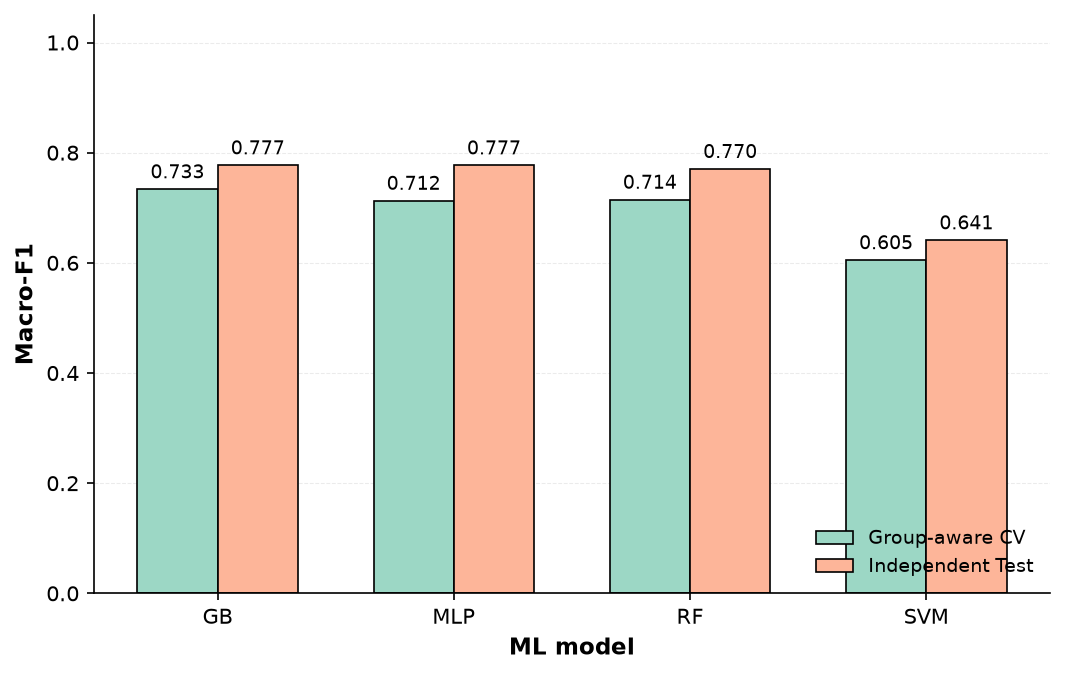

In [306]:
plot_cv_vs_test(
    campaign="PRBS_NRZ",
    scenario="Configuration-based",
    data=generalization_table,
    filename="robustness_cv_test_prbs_config"
)

Saved: figures\robustness_cv_test_prbs_telemetry.pdf


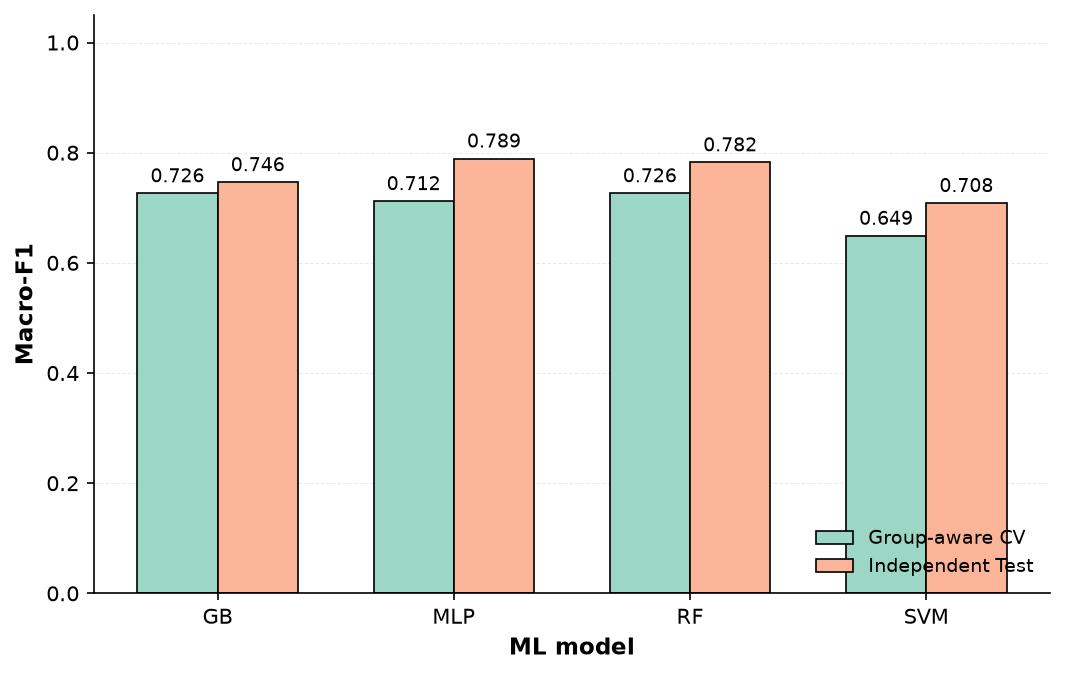

In [307]:
plot_cv_vs_test(
    campaign="PRBS_NRZ",
    scenario="Telemetry-assisted",
    data=generalization_table,
    filename="robustness_cv_test_prbs_telemetry"
)

Saved: figures\robustness_cv_test_lte_config.pdf


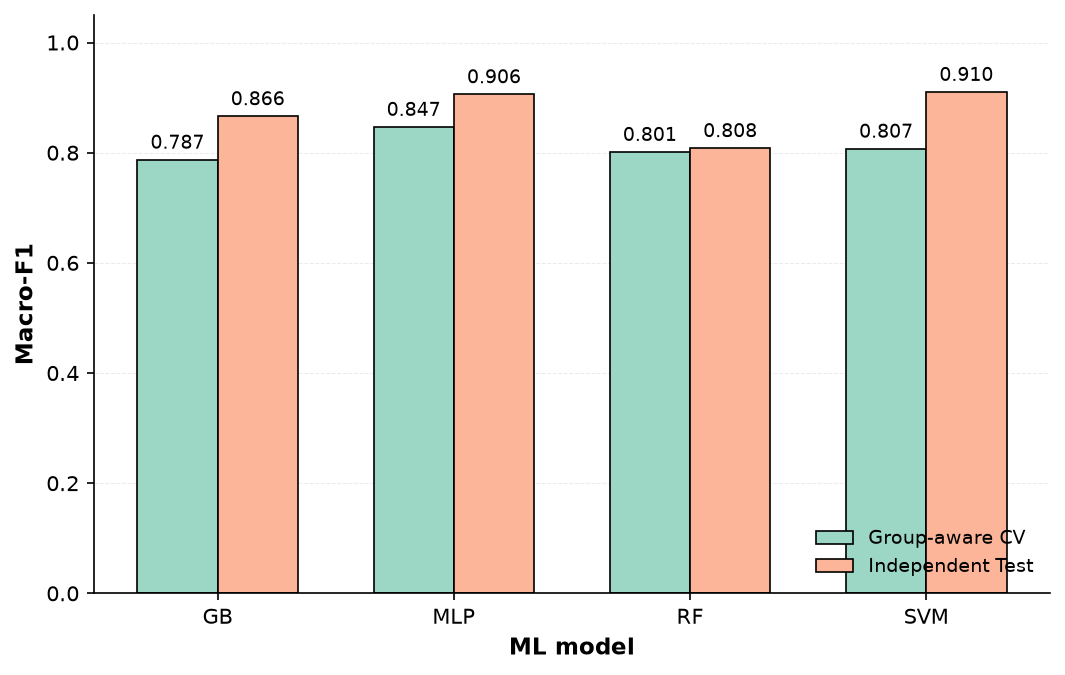

In [308]:
plot_cv_vs_test(
    campaign="LTE_QPSK",
    scenario="Configuration-based",
    data=generalization_table,
    filename="robustness_cv_test_lte_config"
)

In [309]:
# Step 15 — Group-level accuracy distribution


def plot_group_accuracy_distribution(
    campaign,
    scenario,
    data,
    filename=None
):

    plot_data = (
        data[
            (data["Campaign"] == campaign)
            &
            (data["Scenario"] == scenario)
        ]
        .copy()
    )

    # Full model names used to retrieve data
    models = [
        "Gradient Boosting",
        "MLP",
        "Random Forest",
        "SVM"
    ]

    # Short labels for publication
    model_labels = [
        "GB",
        "MLP",
        "RF",
        "SVM"
    ]

    values = [
        plot_data[
            plot_data["Model"] == model
        ]["Group_Accuracy"].values
        for model in models
    ]

    fig, ax = plt.subplots(
        figsize=(7.2, 4.8),
        dpi=150
    )

    bp = ax.boxplot(
        values,

        # Correct argument for current Matplotlib
        tick_labels=model_labels,

        patch_artist=True,
        showfliers=True,

        medianprops={
            "color": "black",
            "linewidth": 1.3
        },

        boxprops={
            "edgecolor": "black",
            "linewidth": 0.8
        },

        whiskerprops={
            "color": "black",
            "linewidth": 0.8
        },

        capprops={
            "color": "black",
            "linewidth": 0.8
        },

        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "markeredgewidth": 0.6,
            "alpha": 0.70
        }
    )

    # Apply pastel Set2 colors
    for i, box in enumerate(
        bp["boxes"]
    ):

        box.set_facecolor(
            SET2_PASTEL[
                i % len(SET2_PASTEL)
            ]
        )

    ax.set_xlabel(
        "ML model",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Group accuracy",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    # Thin black axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    plt.tight_layout()

    # Save as PDF
    if filename is not None:

        output_path = (
            FIGURES_DIR / f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

Saved: figures\group_accuracy_prbs_config.pdf


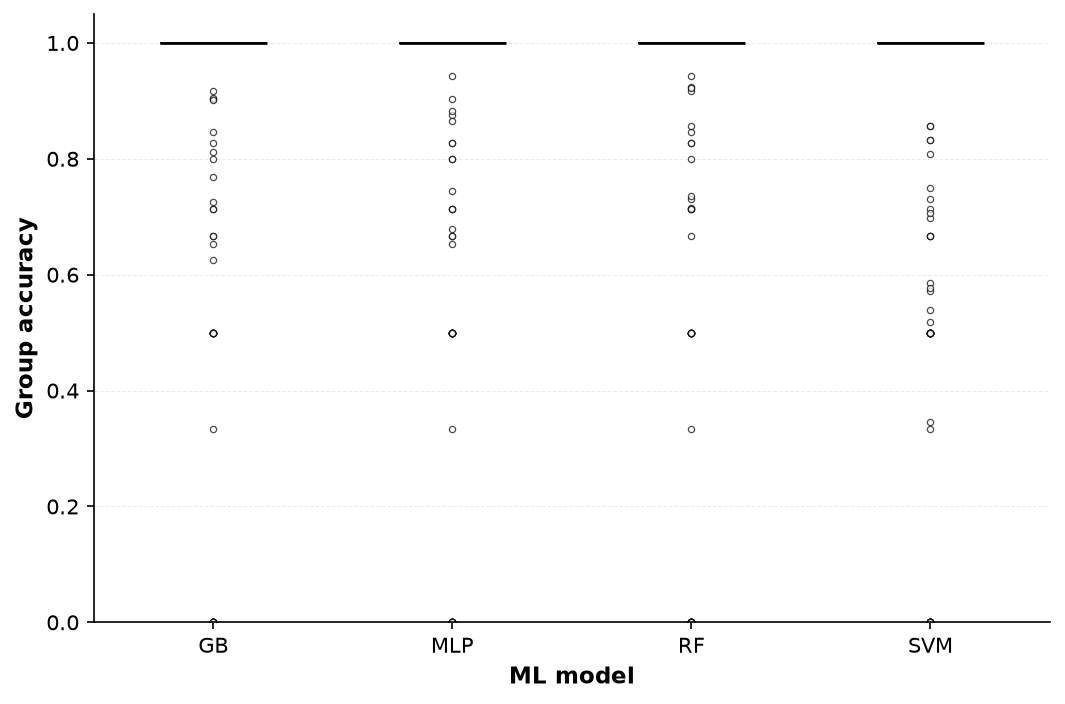

In [310]:
plot_group_accuracy_distribution(
    campaign="PRBS_NRZ",
    scenario="Configuration-based",
    data=group_level_performance,
    filename="group_accuracy_prbs_config"
)

Saved: figures\group_accuracy_prbs_telemetry.pdf


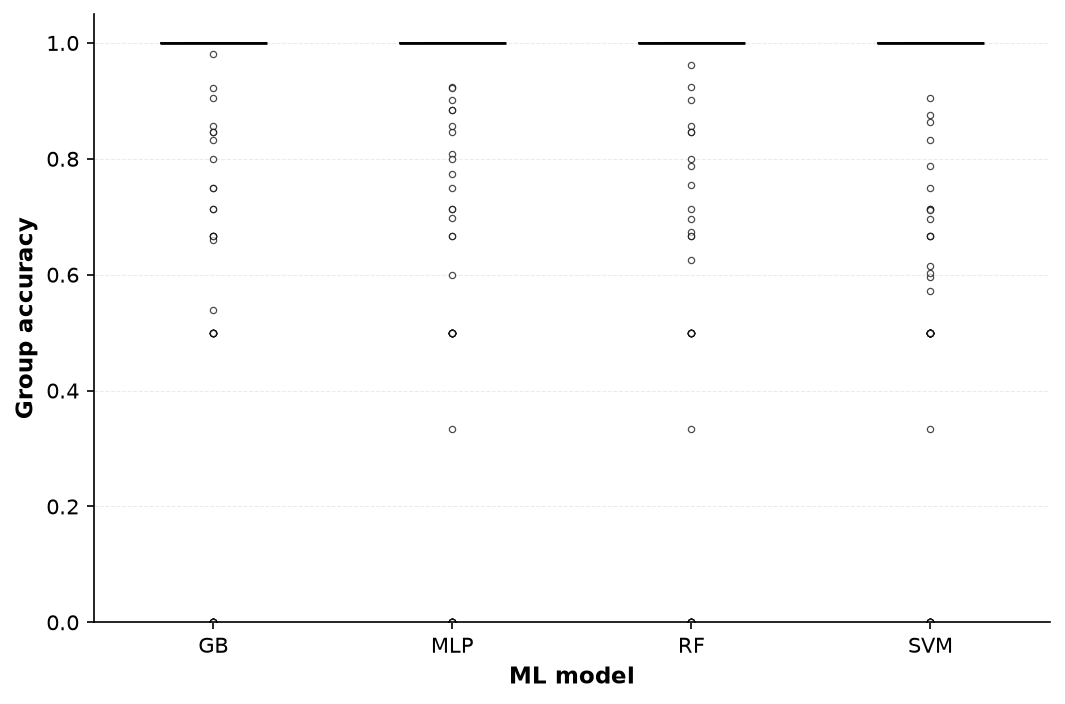

Saved: figures\group_accuracy_lte_config.pdf


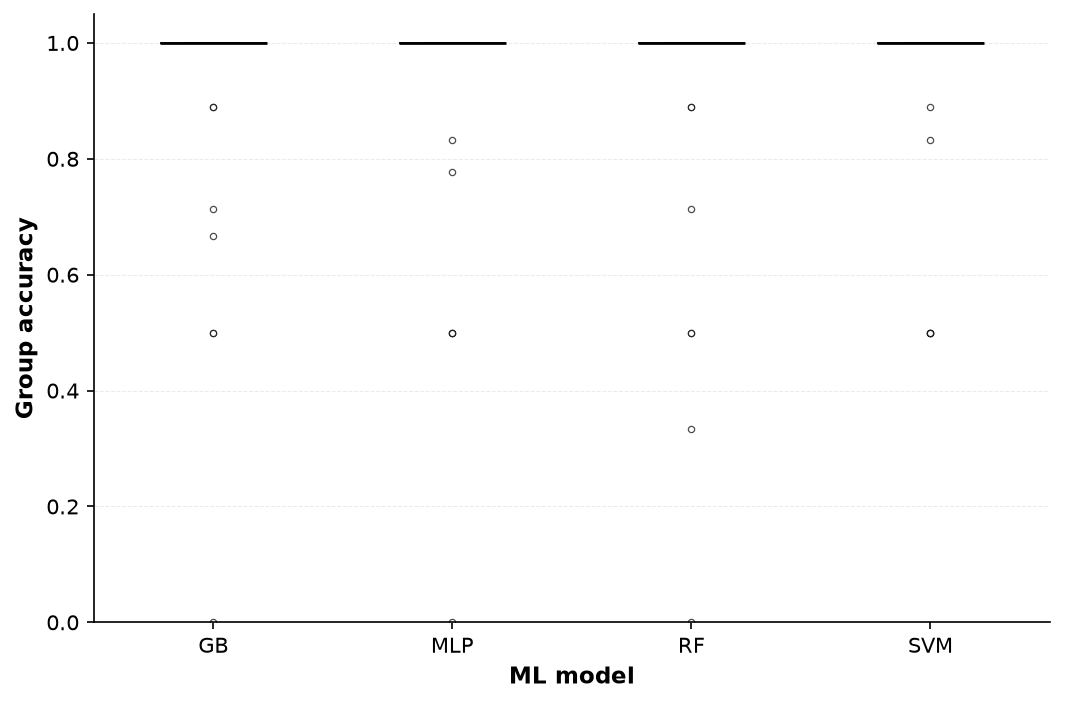

Saved: figures\group_accuracy_lte_telemetry.pdf


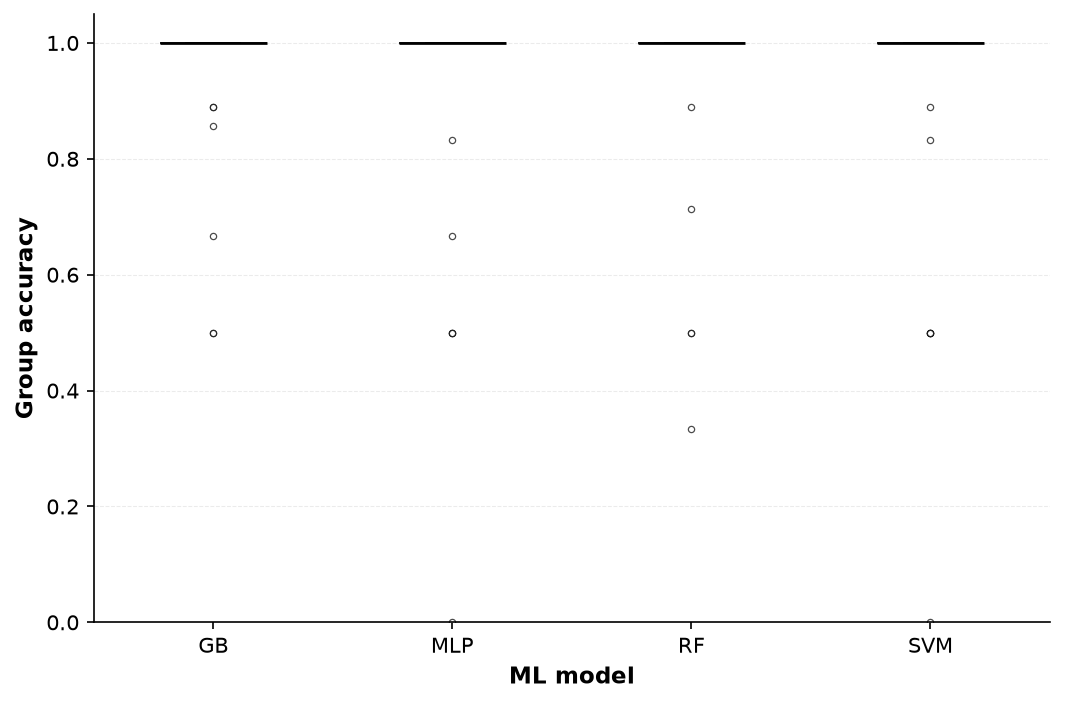

In [311]:
plot_group_accuracy_distribution(
    campaign="PRBS_NRZ",
    scenario="Telemetry-assisted",
    data=group_level_performance,
    filename="group_accuracy_prbs_telemetry"
)

plot_group_accuracy_distribution(
    campaign="LTE_QPSK",
    scenario="Configuration-based",
    data=group_level_performance,
    filename="group_accuracy_lte_config"
)

plot_group_accuracy_distribution(
    campaign="LTE_QPSK",
    scenario="Telemetry-assisted",
    data=group_level_performance,
    filename="group_accuracy_lte_telemetry"
)

In [312]:
# Step 16 — Export Activity 15 robustness tables

group_robustness_summary.to_csv(
    TABLES_DIR / "table_group_robustness.csv",
    index=False
)

sample_vs_group_accuracy.to_csv(
    TABLES_DIR / "table_sample_vs_group_accuracy.csv",
    index=False
)

group_size_accuracy_table.to_csv(
    TABLES_DIR / "table_group_size_spearman.csv",
    index=False
)

error_size_comparison.to_csv(
    TABLES_DIR / "table_error_group_size_comparison.csv",
    index=False
)

generalization_table.to_csv(
    TABLES_DIR / "table_cv_test_generalization.csv",
    index=False
)

generalization_summary.to_csv(
    TABLES_DIR / "table_cv_test_summary.csv",
    index=False
)

print(
    "Activity 15 tables exported successfully."
)

Activity 15 tables exported successfully.


In [313]:
# Step 16B — Verify exported Activity 15 tables

activity15_table_files = [
    "table_group_robustness.csv",
    "table_sample_vs_group_accuracy.csv",
    "table_group_size_spearman.csv",
    "table_error_group_size_comparison.csv",
    "table_cv_test_generalization.csv",
    "table_cv_test_summary.csv"
]

for filename in activity15_table_files:

    path = TABLES_DIR / filename

    print(
        f"{filename}:",
        "FOUND" if path.exists() else "MISSING"
    )

table_group_robustness.csv: FOUND
table_sample_vs_group_accuracy.csv: FOUND
table_group_size_spearman.csv: FOUND
table_error_group_size_comparison.csv: FOUND
table_cv_test_generalization.csv: FOUND
table_cv_test_summary.csv: FOUND


In [314]:
# Step 17 — Create compact robustness summary

activity15_final_summary = (
    group_robustness_summary[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Mean group accuracy",
            "P10 group accuracy",
            "Minimum group accuracy"
        ]
    ]
    .merge(
        sample_vs_group_accuracy[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Group-weighting difference"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
    .merge(
        group_size_accuracy_table[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Spearman rho",
                "p-value"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
    .merge(
        generalization_table[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Best CV Macro-F1",
                "Test Macro-F1",
                "Test - CV difference"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)

display(
    activity15_final_summary.round(4)
)

,Campaign,Scenario,Model,Mean group accuracy,P10 group accuracy,Minimum group accuracy,Group-weighting difference,Spearman rho,p-value,Best CV Macro-F1,Test Macro-F1,Test - CV difference
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.9502,0.8889,0.0000,-0.0214,-0.1340,0.3203,0.7871,0.8661,0.0790
1,LTE_QPSK,Configuration-based,MLP,0.9493,0.9333,0.0000,-0.0285,0.0116,0.9315,0.8467,0.9060,0.0593
2,LTE_QPSK,Configuration-based,Random Forest,0.9443,0.8889,0.0000,-0.0209,-0.1387,0.3037,0.8012,0.8081,0.0069
3,LTE_QPSK,Configuration-based,SVM,0.9600,0.9556,0.5000,-0.0210,-0.0584,0.6660,0.8071,0.9102,0.1030
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.9702,0.9556,0.5000,-0.0076,-0.2380,0.0746,0.7670,0.8838,0.1167
5,LTE_QPSK,Telemetry-assisted,MLP,0.9474,0.9333,0.0000,-0.0273,0.0116,0.9315,0.8729,0.8887,0.0158
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.9638,1.0000,0.3333,-0.0077,-0.1797,0.1809,0.7951,0.8438,0.0487
7,LTE_QPSK,Telemetry-assisted,SVM,0.9425,0.8667,0.0000,-0.0354,0.0309,0.8198,0.8285,0.8971,0.0686
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.8999,0.5000,0.0000,0.0594,-0.3778,0.0000,0.7334,0.7769,0.0435
9,PRBS_NRZ,Configuration-based,MLP,0.8992,0.5000,0.0000,0.0543,-0.3637,0.0000,0.7125,0.7768,0.0643


In [315]:
# Step 17B — Export final Activity 15 summary

activity15_final_summary.to_csv(
    TABLES_DIR / "table_activity15_final_summary.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_activity15_final_summary.csv"
)

Saved: tables\table_activity15_final_summary.csv


In [316]:
# Step 18 — Validate Activity 15

activity15_checks = {

    "Sixteen frozen Test evaluations available":
        len(test_prediction_store) == 16,

    "2272 group-level model evaluations available":
        len(group_level_performance) == 2272,

    "Sixteen robustness summaries available":
        len(group_robustness_summary) == 16,

    "Sixteen sample-vs-group comparisons available":
        len(sample_vs_group_accuracy) == 16,

    "Sixteen group-size correlation results available":
        len(group_size_accuracy_table) == 16,

    "Sixteen CV-Test comparisons available":
        len(generalization_table) == 16,

    "Four campaign-scenario summaries available":
        len(generalization_summary) == 4,

    "All Test Macro-F1 values available":
        generalization_table[
            "Test Macro-F1"
        ].notna().all(),

    "All CV Macro-F1 values available":
        generalization_table[
            "Best CV Macro-F1"
        ].notna().all(),

    "Final robustness summary available":
        len(activity15_final_summary) == 16,

    "All Activity 15 tables exported":
        all(
            (TABLES_DIR / filename).exists()
            for filename in activity15_table_files
        ),

    "No model retraining performed":
        True
}

activity15_summary = pd.DataFrame(
    activity15_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity15_summary
)

,Validation,Passed
0,Sixteen frozen Test evaluations available,True
1,2272 group-level model evaluations available,True
2,Sixteen robustness summaries available,True
3,Sixteen sample-vs-group comparisons available,True
4,Sixteen group-size correlation results available,True
5,Sixteen CV-Test comparisons available,True
6,Four campaign-scenario summaries available,True
7,All Test Macro-F1 values available,True
8,All CV Macro-F1 values available,True
9,Final robustness summary available,True


In [317]:
# Step 19 — Final decision for Activity 15

activity15_passed = (
    activity15_summary[
        "Passed"
    ].all()
)

if activity15_passed:

    print("=" * 70)
    print("ACTIVITY 15 — PASSED")
    print("=" * 70)

    print(
        "Robustness and within-campaign generalization were "
        "successfully evaluated across unseen experimental groups."
    )

    print(
        "The analysis quantified group-level variability, "
        "sample-versus-group weighting effects, group-size associations, "
        "and consistency between group-aware cross-validation and "
        "independent-Test performance."
    )

    print(
        "PRBS-NRZ exhibited greater group-level heterogeneity "
        "than LTE-QPSK."
    )

    print(
        "No additional model training or Test-driven optimization "
        "was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 15 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity15_summary[
            ~activity15_summary["Passed"]
        ]
    )

ACTIVITY 15 — PASSED
Robustness and within-campaign generalization were successfully evaluated across unseen experimental groups.
The analysis quantified group-level variability, sample-versus-group weighting effects, group-size associations, and consistency between group-aware cross-validation and independent-Test performance.
PRBS-NRZ exhibited greater group-level heterogeneity than LTE-QPSK.
No additional model training or Test-driven optimization was performed.


## Activity 15 — Final interpretation

The robustness analysis confirms that predictive performance is not uniformly
distributed across experimental groups.

LTE-QPSK exhibits comparatively stable behavior across unseen groups. Mean
group-level accuracy remains high, and the difference between sample-weighted
and equal-weight group accuracy is relatively small.

PRBS-NRZ exhibits greater group-level heterogeneity. Although most experimental
groups are classified accurately, a subset of more difficult operating
conditions produces substantially lower performance.

A consistent negative association between experimental-group size and
group-level accuracy is observed for PRBS-NRZ across all evaluated classifiers
and predictor scenarios. This pattern contributes to the difference between
sample-level and equal-weight group accuracy.

Group-aware cross-validation and independent-Test results remain broadly
consistent. Independent-Test Macro-F1 is higher than cross-validation Macro-F1
for all evaluated cases, indicating that the frozen Test groups were, on
average, less difficult than some of the validation groups encountered during
cross-validation.

Overall, the analysis demonstrates that the dataset supports not only
classification benchmarking but also the study of robustness and
generalization across heterogeneous experimental conditions.

# Activity 16 — Error Concentration and Failure-Region Analysis

## Objective

The objective of this activity is to characterize the experimental conditions
associated with classification errors in the frozen independent-Test set.

No model retraining, hyperparameter optimization, or Test-driven model
selection is performed.

The analysis focuses on:

- overall error concentration across classifiers;
- class-specific error rates;
- samples that are consistently difficult for multiple classifiers;
- consensus error patterns across models;
- experimental conditions associated with difficult samples;
- predictor distributions in correctly and incorrectly classified regions.

The analysis is performed independently for PRBS-NRZ and LTE-QPSK and for the
Configuration-based and Telemetry-assisted predictor scenarios.

In [318]:

# Step 2 — Map the frozen independent-Test predictor matrices

TEST_FEATURE_MAP = {

    (
        "PRBS_NRZ",
        "Configuration-based"
    ):
        X_prbs_config_test.reset_index(drop=True),

    (
        "PRBS_NRZ",
        "Telemetry-assisted"
    ):
        X_prbs_telemetry_test.reset_index(drop=True),

    (
        "LTE_QPSK",
        "Configuration-based"
    ):
        X_lte_config_test.reset_index(drop=True),

    (
        "LTE_QPSK",
        "Telemetry-assisted"
    ):
        X_lte_telemetry_test.reset_index(drop=True)
}


for key, X_test in TEST_FEATURE_MAP.items():

    print(
        key,
        "->",
        X_test.shape
    )



('PRBS_NRZ', 'Configuration-based') -> (909, 20)
('PRBS_NRZ', 'Telemetry-assisted') -> (909, 21)
('LTE_QPSK', 'Configuration-based') -> (316, 20)
('LTE_QPSK', 'Telemetry-assisted') -> (316, 21)


In [319]:
# Step 2B — Verify predictor/prediction alignment

alignment_checks = []

for (
    campaign,
    scenario
), X_test in TEST_FEATURE_MAP.items():

    for model in [
        "Gradient Boosting",
        "MLP",
        "Random Forest",
        "SVM"
    ]:

        key = (
            campaign,
            scenario,
            model
        )

        result = test_prediction_store[key]

        aligned = (
            len(X_test)
            ==
            len(result["y_true"])
            ==
            len(result["y_pred"])
            ==
            len(result["groups"])
        )

        alignment_checks.append({
            "Campaign": campaign,
            "Scenario": scenario,
            "Model": model,
            "Aligned": aligned
        })


alignment_table = pd.DataFrame(
    alignment_checks
)

display(
    alignment_table
)

print(
    "\nAll Test matrices aligned:",
    alignment_table["Aligned"].all()
)

,Campaign,Scenario,Model,Aligned
0,PRBS_NRZ,Configuration-based,Gradient Boosting,True
1,PRBS_NRZ,Configuration-based,MLP,True
2,PRBS_NRZ,Configuration-based,Random Forest,True
3,PRBS_NRZ,Configuration-based,SVM,True
4,PRBS_NRZ,Telemetry-assisted,Gradient Boosting,True
5,PRBS_NRZ,Telemetry-assisted,MLP,True
6,PRBS_NRZ,Telemetry-assisted,Random Forest,True
7,PRBS_NRZ,Telemetry-assisted,SVM,True
8,LTE_QPSK,Configuration-based,Gradient Boosting,True
9,LTE_QPSK,Configuration-based,MLP,True



All Test matrices aligned: True


In [320]:
# Step 3 — Build the complete frozen-Test error-analysis table

error_analysis_rows = []

for key, result in test_prediction_store.items():

    campaign, scenario, model = key

    X_test = (
        TEST_FEATURE_MAP[
            (
                campaign,
                scenario
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    y_true = np.asarray(
        result["y_true"]
    )

    y_pred = np.asarray(
        result["y_pred"]
    )

    groups = np.asarray(
        result["groups"]
    )

    assert (
        len(X_test)
        ==
        len(y_true)
        ==
        len(y_pred)
        ==
        len(groups)
    )

    temp = X_test.copy()

    temp["Sample_ID"] = np.arange(
        len(temp)
    )

    temp["Campaign"] = campaign
    temp["Scenario"] = scenario
    temp["Model"] = model

    temp["Group"] = groups
    temp["True class"] = y_true
    temp["Predicted class"] = y_pred

    temp["Error"] = (
        y_true != y_pred
    ).astype(int)

    temp["Correct"] = (
        y_true == y_pred
    ).astype(int)

    error_analysis_rows.append(
        temp
    )


error_analysis_table = pd.concat(
    error_analysis_rows,
    ignore_index=True
)

print(
    "Total model-sample evaluations:",
    len(error_analysis_table)
)

display(
    error_analysis_table.head()
)

Total model-sample evaluations: 9800


,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,transmission_rate_bps,rf_amplifier_tx_db,rf_voltage_v,rf_power_dbm,smf_length_km,smf_attenuation_db,dispersion_ps_nm_km,voa_attenuation_db,edfa_current_ma,soa_current_ma,photodiode,max_allowed_optical_power_dbm,optical_receiver_responsivity_a_w,detector_bw_hz,rf_amplifier_rx_db,Sample_ID,Campaign,Scenario,Model,Group,True class,Predicted class,Error,Correct,prx_dbm
0,8.54,1557.0,9758023IM,5.54,1.1,6320000000,27,0.14,-4.077439,20,3.54,18,35.0,133.6,0.0,PIN,-3,0.8,10000000000,27.0,0,PRBS_NRZ,Configuration-based,Random Forest,G0094,Degraded,Degraded,0,1,NaN
1,8.54,1557.0,9758023IM,5.54,1.1,6320000000,27,0.14,-4.077439,20,3.54,18,32.0,133.6,0.0,PIN,-3,0.8,10000000000,27.0,1,PRBS_NRZ,Configuration-based,Random Forest,G0193,Degraded,Degraded,0,1,NaN
2,5.30,1550.0,9758023IM,5.54,6.3,622000000,27,0.19,-1.424928,20,3.54,18,26.0,141.7,0.0,PIN,-3,0.8,10000000000,27.0,2,PRBS_NRZ,Configuration-based,Random Forest,G0234,Degraded,Degraded,0,1,NaN
3,8.34,1550.0,9758023IM,6.00,1.3,2500000000,29,0.14,-4.077439,20,3.76,18,28.0,123.3,0.0,PIN,-3,0.8,10000000000,27.0,3,PRBS_NRZ,Configuration-based,Random Forest,G0288,Degraded,Degraded,0,1,NaN
4,5.30,1550.0,9758023IM,5.54,1.4,622000000,27,0.19,-1.424928,20,3.54,18,26.0,141.7,0.0,PIN,-3,0.8,10000000000,27.0,4,PRBS_NRZ,Configuration-based,Random Forest,G0234,Degraded,Degraded,0,1,NaN


In [321]:
# Step 4 — Summarize independent-Test classification errors

model_error_summary = (
    error_analysis_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model"
        ]
    )
    .agg(
        Samples=(
            "Error",
            "size"
        ),

        Errors=(
            "Error",
            "sum"
        ),

        Error_rate=(
            "Error",
            "mean"
        )
    )
    .reset_index()
)


model_error_summary[
    "Accuracy_from_errors"
] = (
    1
    -
    model_error_summary[
        "Error_rate"
    ]
)

display(
    model_error_summary.round(4)
)

,Campaign,Scenario,Model,Samples,Errors,Error_rate,Accuracy_from_errors
0,LTE_QPSK,Configuration-based,Gradient Boosting,316,9,0.0285,0.9715
1,LTE_QPSK,Configuration-based,MLP,316,7,0.0222,0.9778
2,LTE_QPSK,Configuration-based,Random Forest,316,11,0.0348,0.9652
3,LTE_QPSK,Configuration-based,SVM,316,6,0.0190,0.9810
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,316,7,0.0222,0.9778
5,LTE_QPSK,Telemetry-assisted,MLP,316,8,0.0253,0.9747
6,LTE_QPSK,Telemetry-assisted,Random Forest,316,9,0.0285,0.9715
7,LTE_QPSK,Telemetry-assisted,SVM,316,7,0.0222,0.9778
8,PRBS_NRZ,Configuration-based,Gradient Boosting,909,145,0.1595,0.8405
9,PRBS_NRZ,Configuration-based,MLP,909,141,0.1551,0.8449


In [322]:
# Step 4B — Validate reconstructed error rates against Activity 10

error_validation = (
    model_error_summary
    .merge(
        test_performance[
            [
                "Campaign",
                "Scenario",
                "Model",
                "Accuracy"
            ]
        ],
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="left"
    )
)


error_validation[
    "Absolute difference"
] = (
    error_validation[
        "Accuracy_from_errors"
    ]
    -
    error_validation[
        "Accuracy"
    ]
).abs()


display(
    error_validation[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy_from_errors",
            "Accuracy",
            "Absolute difference"
        ]
    ].round(8)
)


print(
    "\nMaximum reconstruction difference:",
    error_validation[
        "Absolute difference"
    ].max()
)

,Campaign,Scenario,Model,Accuracy_from_errors,Accuracy,Absolute difference
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.971519,0.971519,0.0
1,LTE_QPSK,Configuration-based,MLP,0.977848,0.977848,0.0
2,LTE_QPSK,Configuration-based,Random Forest,0.965190,0.965190,0.0
3,LTE_QPSK,Configuration-based,SVM,0.981013,0.981013,0.0
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.977848,0.977848,0.0
5,LTE_QPSK,Telemetry-assisted,MLP,0.974684,0.974684,0.0
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.971519,0.971519,0.0
7,LTE_QPSK,Telemetry-assisted,SVM,0.977848,0.977848,0.0
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.840484,0.840484,0.0
9,PRBS_NRZ,Configuration-based,MLP,0.844884,0.844884,0.0



Maximum reconstruction difference: 1.1102230246251565e-16


### Step 4B — Validation of reconstructed Test errors

The reconstructed classification accuracy matches the independent-Test
accuracy reported in Activity 10.

The maximum absolute difference is approximately \(1.1\times10^{-16}\),
which corresponds only to floating-point numerical precision.

Therefore, the reconstructed error-analysis table is fully consistent with
the previously validated independent-Test predictions.

In [323]:
# Step 5 — Calculate class-specific error rates

class_error_summary = (
    error_analysis_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Model",
            "True class"
        ]
    )
    .agg(
        Samples=(
            "Error",
            "size"
        ),

        Errors=(
            "Error",
            "sum"
        ),

        Error_rate=(
            "Error",
            "mean"
        )
    )
    .reset_index()
)


class_error_summary[
    "Recall"
] = (
    1
    -
    class_error_summary[
        "Error_rate"
    ]
)


display(
    class_error_summary.round(4)
)

,Campaign,Scenario,Model,True class,Samples,Errors,Error_rate,Recall
0,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,16,4,0.2500,0.7500
1,LTE_QPSK,Configuration-based,Gradient Boosting,Degraded,283,3,0.0106,0.9894
2,LTE_QPSK,Configuration-based,Gradient Boosting,Excellent,17,2,0.1176,0.8824
3,LTE_QPSK,Configuration-based,MLP,Acceptable,16,3,0.1875,0.8125
4,LTE_QPSK,Configuration-based,MLP,Degraded,283,3,0.0106,0.9894
5,LTE_QPSK,Configuration-based,MLP,Excellent,17,1,0.0588,0.9412
6,LTE_QPSK,Configuration-based,Random Forest,Acceptable,16,7,0.4375,0.5625
7,LTE_QPSK,Configuration-based,Random Forest,Degraded,283,2,0.0071,0.9929
8,LTE_QPSK,Configuration-based,Random Forest,Excellent,17,2,0.1176,0.8824
9,LTE_QPSK,Configuration-based,SVM,Acceptable,16,4,0.2500,0.7500


In [324]:
# Step 5B — Inspect the Acceptable class

acceptable_error_summary = (
    class_error_summary[
        class_error_summary[
            "True class"
        ] == "Acceptable"
    ]
    .copy()
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Error_rate"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    acceptable_error_summary.round(4)
)

,Campaign,Scenario,Model,True class,Samples,Errors,Error_rate,Recall
0,LTE_QPSK,Configuration-based,Random Forest,Acceptable,16,7,0.4375,0.5625
1,LTE_QPSK,Configuration-based,Gradient Boosting,Acceptable,16,4,0.2500,0.7500
2,LTE_QPSK,Configuration-based,SVM,Acceptable,16,4,0.2500,0.7500
3,LTE_QPSK,Configuration-based,MLP,Acceptable,16,3,0.1875,0.8125
4,LTE_QPSK,Telemetry-assisted,Random Forest,Acceptable,16,7,0.4375,0.5625
5,LTE_QPSK,Telemetry-assisted,SVM,Acceptable,16,5,0.3125,0.6875
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,Acceptable,16,4,0.2500,0.7500
7,LTE_QPSK,Telemetry-assisted,MLP,Acceptable,16,2,0.1250,0.8750
8,PRBS_NRZ,Configuration-based,SVM,Acceptable,141,94,0.6667,0.3333
9,PRBS_NRZ,Configuration-based,Random Forest,Acceptable,141,80,0.5674,0.4326


In [325]:
print(
    "Acceptable-class results:",
    len(acceptable_error_summary)
)

Acceptable-class results: 16


In [326]:
# Step 6 — Calculate consensus difficulty across classifiers

consensus_difficulty = (
    error_analysis_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Sample_ID",
            "Group",
            "True class"
        ]
    )
    .agg(
        Misclassified_models=(
            "Error",
            "sum"
        ),

        Models_evaluated=(
            "Model",
            "nunique"
        )
    )
    .reset_index()
)


consensus_difficulty[
    "Difficulty fraction"
] = (
    consensus_difficulty[
        "Misclassified_models"
    ]
    /
    consensus_difficulty[
        "Models_evaluated"
    ]
)


display(
    consensus_difficulty.head(20)
)

,Campaign,Scenario,Sample_ID,Group,True class,Misclassified_models,Models_evaluated,Difficulty fraction
0,LTE_QPSK,Configuration-based,0,G0002,Degraded,0,4,0.0
1,LTE_QPSK,Configuration-based,1,G0002,Degraded,0,4,0.0
2,LTE_QPSK,Configuration-based,2,G0004,Degraded,0,4,0.0
3,LTE_QPSK,Configuration-based,3,G0006,Degraded,0,4,0.0
4,LTE_QPSK,Configuration-based,4,G0006,Degraded,0,4,0.0
5,LTE_QPSK,Configuration-based,5,G0002,Degraded,0,4,0.0
6,LTE_QPSK,Configuration-based,6,G0011,Degraded,0,4,0.0
7,LTE_QPSK,Configuration-based,7,G0002,Degraded,0,4,0.0
8,LTE_QPSK,Configuration-based,8,G0011,Degraded,0,4,0.0
9,LTE_QPSK,Configuration-based,9,G0004,Degraded,0,4,0.0


In [327]:
# Step 6B — Validate consensus difficulty

consensus_checks = {

    "Every sample evaluated by four models":
        (
            consensus_difficulty[
                "Models_evaluated"
            ] == 4
        ).all(),

    "Minimum difficulty is at least zero":
        (
            consensus_difficulty[
                "Misclassified_models"
            ] >= 0
        ).all(),

    "Maximum difficulty is at most four":
        (
            consensus_difficulty[
                "Misclassified_models"
            ] <= 4
        ).all()
}

consensus_validation = pd.DataFrame(
    consensus_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    consensus_validation
)

,Validation,Passed
0,Every sample evaluated by four models,True
1,Minimum difficulty is at least zero,True
2,Maximum difficulty is at most four,True


In [328]:
# Step 7 — Distribution of consensus difficulty

difficulty_distribution = (
    consensus_difficulty
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Misclassified_models"
        ]
    )
    .size()
    .rename(
        "Samples"
    )
    .reset_index()
)


difficulty_distribution[
    "Percentage"
] = (
    difficulty_distribution[
        "Samples"
    ]
    /
    difficulty_distribution
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )[
        "Samples"
    ]
    .transform("sum")
    *
    100
)


display(
    difficulty_distribution.round(2)
)

,Campaign,Scenario,Misclassified_models,Samples,Percentage
0,LTE_QPSK,Configuration-based,0,298,94.30
1,LTE_QPSK,Configuration-based,1,6,1.90
2,LTE_QPSK,Configuration-based,2,10,3.16
3,LTE_QPSK,Configuration-based,3,1,0.32
4,LTE_QPSK,Configuration-based,4,1,0.32
5,LTE_QPSK,Telemetry-assisted,0,299,94.62
6,LTE_QPSK,Telemetry-assisted,1,6,1.90
7,LTE_QPSK,Telemetry-assisted,2,9,2.85
8,LTE_QPSK,Telemetry-assisted,3,1,0.32
9,LTE_QPSK,Telemetry-assisted,4,1,0.32


In [329]:
# Step 8 — Analyze consensus difficulty by QoT class

difficulty_by_class = (
    consensus_difficulty
    .groupby(
        [
            "Campaign",
            "Scenario",
            "True class"
        ]
    )
    .agg(
        Samples=(
            "Sample_ID",
            "size"
        ),

        Mean_models_wrong=(
            "Misclassified_models",
            "mean"
        ),

        Median_models_wrong=(
            "Misclassified_models",
            "median"
        ),

        All_models_correct=(
            "Misclassified_models",
            lambda x:
                100 * (x == 0).mean()
        ),

        At_least_3_models_wrong=(
            "Misclassified_models",
            lambda x:
                100 * (x >= 3).mean()
        ),

        All_4_models_wrong=(
            "Misclassified_models",
            lambda x:
                100 * (x == 4).mean()
        )
    )
    .reset_index()
)


display(
    difficulty_by_class.round(3)
)

,Campaign,Scenario,True class,Samples,Mean_models_wrong,Median_models_wrong,All_models_correct,At_least_3_models_wrong,All_4_models_wrong
0,LTE_QPSK,Configuration-based,Acceptable,16,1.125,1.0,43.750,12.500,6.250
1,LTE_QPSK,Configuration-based,Degraded,283,0.028,0.0,98.233,0.000,0.000
2,LTE_QPSK,Configuration-based,Excellent,17,0.412,0.0,76.471,0.000,0.000
3,LTE_QPSK,Telemetry-assisted,Acceptable,16,1.125,1.0,43.750,12.500,6.250
4,LTE_QPSK,Telemetry-assisted,Degraded,283,0.025,0.0,98.233,0.000,0.000
5,LTE_QPSK,Telemetry-assisted,Excellent,17,0.353,0.0,82.353,0.000,0.000
6,PRBS_NRZ,Configuration-based,Acceptable,141,2.241,2.0,19.858,45.390,33.333
7,PRBS_NRZ,Configuration-based,Degraded,412,0.495,0.0,69.175,5.825,3.641
8,PRBS_NRZ,Configuration-based,Excellent,356,0.466,0.0,75.281,8.146,2.247
9,PRBS_NRZ,Telemetry-assisted,Acceptable,141,2.248,2.0,16.312,46.809,34.043


### Interpretation of consensus classification difficulty

The consensus analysis reveals that classification difficulty is strongly
class dependent.

For LTE-QPSK, the Degraded class is highly consistent across classifiers,
with approximately 98% of the independent-Test observations correctly
classified by all four models. In contrast, the Acceptable class exhibits
substantially greater disagreement. However, these percentages should be
interpreted cautiously because the LTE-QPSK Acceptable class contains only
16 Test observations.

The effect is substantially stronger for PRBS-NRZ. For the Acceptable class,
only approximately 16–20% of the Test observations are correctly classified
by all four algorithms. Approximately 45–47% are misclassified by at least
three classifiers, and about one third are misclassified by all four models.

This cross-model agreement on difficult observations indicates that the
Acceptable region represents a challenging part of the experimental feature
space rather than merely a weakness of a single learning algorithm.

The addition of receiver-side optical power does not eliminate this
difficulty for the PRBS-NRZ Acceptable class.

The following analysis therefore investigates whether these consistently
difficult observations occupy identifiable regions of the physical and
operational predictor space.

In [330]:
# Step 9 — Attach physical predictors to consensus difficulty

difficulty_feature_rows = []

for (
    campaign,
    scenario
), X_test in TEST_FEATURE_MAP.items():

    X_features = (
        X_test
        .copy()
        .reset_index(drop=True)
    )

    X_features["Sample_ID"] = np.arange(
        len(X_features)
    )

    difficulty_subset = (
        consensus_difficulty[
            (consensus_difficulty["Campaign"] == campaign)
            &
            (consensus_difficulty["Scenario"] == scenario)
        ]
        .copy()
    )

    merged = (
        difficulty_subset
        .merge(
            X_features,
            on="Sample_ID",
            how="left"
        )
    )

    difficulty_feature_rows.append(
        merged
    )


difficulty_feature_table = pd.concat(
    difficulty_feature_rows,
    ignore_index=True
)

print(
    "Difficulty-feature observations:",
    len(difficulty_feature_table)
)

display(
    difficulty_feature_table.head()
)

Difficulty-feature observations: 2450


,Campaign,Scenario,Sample_ID,Group,True class,Misclassified_models,Models_evaluated,Difficulty fraction,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,transmission_rate_bps,rf_amplifier_tx_db,rf_voltage_v,rf_power_dbm,smf_length_km,smf_attenuation_db,dispersion_ps_nm_km,voa_attenuation_db,edfa_current_ma,soa_current_ma,photodiode,max_allowed_optical_power_dbm,optical_receiver_responsivity_a_w,detector_bw_hz,rf_amplifier_rx_db,prx_dbm
0,PRBS_NRZ,Configuration-based,0,G0094,Degraded,0,4,0.0,8.54,1557.0,9758023IM,5.54,1.1,6320000000,27,0.14,-4.077439,20,3.54,18,35.0,133.6,0.0,PIN,-3,0.8,10000000000,27.0,NaN
1,PRBS_NRZ,Configuration-based,1,G0193,Degraded,0,4,0.0,8.54,1557.0,9758023IM,5.54,1.1,6320000000,27,0.14,-4.077439,20,3.54,18,32.0,133.6,0.0,PIN,-3,0.8,10000000000,27.0,NaN
2,PRBS_NRZ,Configuration-based,2,G0234,Degraded,0,4,0.0,5.30,1550.0,9758023IM,5.54,6.3,622000000,27,0.19,-1.424928,20,3.54,18,26.0,141.7,0.0,PIN,-3,0.8,10000000000,27.0,NaN
3,PRBS_NRZ,Configuration-based,3,G0288,Degraded,0,4,0.0,8.34,1550.0,9758023IM,6.00,1.3,2500000000,29,0.14,-4.077439,20,3.76,18,28.0,123.3,0.0,PIN,-3,0.8,10000000000,27.0,NaN
4,PRBS_NRZ,Configuration-based,4,G0234,Degraded,0,4,0.0,5.30,1550.0,9758023IM,5.54,1.4,622000000,27,0.19,-1.424928,20,3.54,18,26.0,141.7,0.0,PIN,-3,0.8,10000000000,27.0,NaN


In [331]:
print(
    "Expected observations:",
    2 * 909 + 2 * 316
)

print(
    "Observed observations:",
    len(difficulty_feature_table)
)

Expected observations: 2450
Observed observations: 2450


In [332]:
# Step 10 — Define consensus difficulty regions

def assign_difficulty_region(n_wrong):

    if n_wrong == 0:
        return "Easy"

    elif n_wrong <= 2:
        return "Intermediate"

    else:
        return "Hard"


difficulty_feature_table[
    "Difficulty region"
] = (
    difficulty_feature_table[
        "Misclassified_models"
    ]
    .apply(
        assign_difficulty_region
    )
)


difficulty_region_summary = (
    difficulty_feature_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "True class",
            "Difficulty region"
        ]
    )
    .size()
    .rename("Samples")
    .reset_index()
)


display(
    difficulty_region_summary
)

,Campaign,Scenario,True class,Difficulty region,Samples
0,LTE_QPSK,Configuration-based,Acceptable,Easy,7
1,LTE_QPSK,Configuration-based,Acceptable,Hard,2
2,LTE_QPSK,Configuration-based,Acceptable,Intermediate,7
3,LTE_QPSK,Configuration-based,Degraded,Easy,278
4,LTE_QPSK,Configuration-based,Degraded,Intermediate,5
5,LTE_QPSK,Configuration-based,Excellent,Easy,13
6,LTE_QPSK,Configuration-based,Excellent,Intermediate,4
7,LTE_QPSK,Telemetry-assisted,Acceptable,Easy,7
8,LTE_QPSK,Telemetry-assisted,Acceptable,Hard,2
9,LTE_QPSK,Telemetry-assisted,Acceptable,Intermediate,7


In [333]:
# Step 11 — Define predictors for failure-region analysis

FAILURE_FEATURES = {

    (
        "PRBS_NRZ",
        "Configuration-based"
    ): [
        "vbias_v",
        "voa_attenuation_db",
        "transmission_rate_bps",
        "optical_tx_power_dbm",
        "soa_current_ma"
    ],

    (
        "PRBS_NRZ",
        "Telemetry-assisted"
    ): [
        "vbias_v",
        "transmission_rate_bps",
        "voa_attenuation_db",
        "prx_dbm",
        "soa_current_ma"
    ],

    (
        "LTE_QPSK",
        "Configuration-based"
    ): [
        "voa_attenuation_db",
        "smf_attenuation_db",
        "wavelength_nm",
        "soa_current_ma",
        "vbias_v"
    ],

    (
        "LTE_QPSK",
        "Telemetry-assisted"
    ): [
        "prx_dbm",
        "voa_attenuation_db",
        "smf_attenuation_db",
        "soa_current_ma",
        "vbias_v"
    ]
}

In [334]:
# Step 12 — Compare physical predictors across difficulty regions

failure_region_results = []

for (
    campaign,
    scenario
), features in FAILURE_FEATURES.items():

    subset = (
        difficulty_feature_table[
            (difficulty_feature_table["Campaign"] == campaign)
            &
            (difficulty_feature_table["Scenario"] == scenario)
        ]
        .copy()
    )

    for feature in features:

        for region in [
            "Easy",
            "Intermediate",
            "Hard"
        ]:

            values = (
                subset[
                    subset[
                        "Difficulty region"
                    ] == region
                ][feature]
                .dropna()
            )

            if len(values) == 0:
                continue

            failure_region_results.append({

                "Campaign":
                    campaign,

                "Scenario":
                    scenario,

                "Feature":
                    feature,

                "Difficulty region":
                    region,

                "Samples":
                    len(values),

                "Median":
                    values.median(),

                "Q1":
                    values.quantile(0.25),

                "Q3":
                    values.quantile(0.75),

                "IQR":
                    (
                        values.quantile(0.75)
                        -
                        values.quantile(0.25)
                    )
            })


failure_region_summary = pd.DataFrame(
    failure_region_results
)


display(
    failure_region_summary.round(4)
)

,Campaign,Scenario,Feature,Difficulty region,Samples,Median,Q1,Q3,IQR
0,PRBS_NRZ,Configuration-based,vbias_v,Easy,581,2.700000e+00,1.800000e+00,4.300000e+00,2.500000e+00
1,PRBS_NRZ,Configuration-based,vbias_v,Intermediate,211,2.300000e+00,1.600000e+00,3.400000e+00,1.800000e+00
2,PRBS_NRZ,Configuration-based,vbias_v,Hard,117,2.497000e+00,1.300000e+00,3.300000e+00,2.000000e+00
3,PRBS_NRZ,Configuration-based,voa_attenuation_db,Easy,581,1.000000e+01,1.000000e+01,1.500000e+01,5.000000e+00
4,PRBS_NRZ,Configuration-based,voa_attenuation_db,Intermediate,211,1.000000e+01,1.000000e+01,1.000000e+01,0.000000e+00
5,PRBS_NRZ,Configuration-based,voa_attenuation_db,Hard,117,1.000000e+01,1.000000e+01,1.100000e+01,1.000000e+00
6,PRBS_NRZ,Configuration-based,transmission_rate_bps,Easy,581,2.500000e+09,1.300000e+09,7.500000e+09,6.200000e+09
7,PRBS_NRZ,Configuration-based,transmission_rate_bps,Intermediate,211,4.000000e+09,1.500000e+09,8.500000e+09,7.000000e+09
8,PRBS_NRZ,Configuration-based,transmission_rate_bps,Hard,117,2.000000e+09,1.250000e+09,4.000000e+09,2.750000e+09
9,PRBS_NRZ,Configuration-based,optical_tx_power_dbm,Easy,581,8.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00


In [335]:
# Step 13 — Failure regions within the Acceptable QoT class

acceptable_difficulty_features = (
    difficulty_feature_table[
        difficulty_feature_table[
            "True class"
        ] == "Acceptable"
    ]
    .copy()
)


acceptable_region_counts = (
    acceptable_difficulty_features
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Difficulty region"
        ]
    )
    .size()
    .rename("Samples")
    .reset_index()
)


acceptable_region_counts[
    "Percentage"
] = (
    100
    *
    acceptable_region_counts["Samples"]
    /
    acceptable_region_counts
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )["Samples"]
    .transform("sum")
)


display(
    acceptable_region_counts.round(2)
)

,Campaign,Scenario,Difficulty region,Samples,Percentage
0,LTE_QPSK,Configuration-based,Easy,7,43.75
1,LTE_QPSK,Configuration-based,Hard,2,12.50
2,LTE_QPSK,Configuration-based,Intermediate,7,43.75
3,LTE_QPSK,Telemetry-assisted,Easy,7,43.75
4,LTE_QPSK,Telemetry-assisted,Hard,2,12.50
5,LTE_QPSK,Telemetry-assisted,Intermediate,7,43.75
6,PRBS_NRZ,Configuration-based,Easy,28,19.86
7,PRBS_NRZ,Configuration-based,Hard,64,45.39
8,PRBS_NRZ,Configuration-based,Intermediate,49,34.75
9,PRBS_NRZ,Telemetry-assisted,Easy,23,16.31


### Interpretation of Acceptable-class difficulty regions

The Acceptable QoT class contains a substantial concentration of difficult
independent-Test observations.

For LTE-QPSK, 12.5% of the Acceptable observations are classified as Hard,
although this result should be interpreted cautiously because only 16
Acceptable Test samples are available.

The effect is considerably stronger for PRBS-NRZ. Approximately 45–47% of
Acceptable observations are classified as Hard, meaning that at least three
of the four evaluated classifiers misclassify the same observation.

Only approximately 16–20% of PRBS-NRZ Acceptable observations are correctly
classified by all four models.

The addition of received optical power does not substantially reduce the
proportion of consensus-hard Acceptable observations, indicating that this
QoT region remains intrinsically challenging for the evaluated classifiers.

In [336]:
objects_to_check = [
    "test_prediction_store",
    "TEST_FEATURE_MAP",
    "error_analysis_table",
    "consensus_difficulty",
    "difficulty_feature_table",
    "FAILURE_FEATURES",
    "acceptable_robust_shift"
]

for obj in objects_to_check:
    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

test_prediction_store: OK
TEST_FEATURE_MAP: OK
error_analysis_table: OK
consensus_difficulty: OK
difficulty_feature_table: OK
FAILURE_FEATURES: OK
acceptable_robust_shift: MISSING


In [337]:
# Step 14 — Physical predictors of Acceptable difficulty regions

acceptable_failure_results = []

for (
    campaign,
    scenario
), features in FAILURE_FEATURES.items():

    subset = (
        difficulty_feature_table[
            (difficulty_feature_table["Campaign"] == campaign)
            &
            (difficulty_feature_table["Scenario"] == scenario)
            &
            (difficulty_feature_table["True class"] == "Acceptable")
        ]
        .copy()
    )

    for feature in features:

        for region in [
            "Easy",
            "Intermediate",
            "Hard"
        ]:

            values = (
                subset[
                    subset["Difficulty region"] == region
                ][feature]
                .dropna()
            )

            if len(values) == 0:
                continue

            acceptable_failure_results.append({
                "Campaign": campaign,
                "Scenario": scenario,
                "Feature": feature,
                "Difficulty region": region,
                "Samples": len(values),
                "Median": values.median(),
                "Q1": values.quantile(0.25),
                "Q3": values.quantile(0.75),
                "IQR": (
                    values.quantile(0.75)
                    -
                    values.quantile(0.25)
                )
            })


acceptable_failure_region_summary = pd.DataFrame(
    acceptable_failure_results
)

display(
    acceptable_failure_region_summary.round(4)
)

,Campaign,Scenario,Feature,Difficulty region,Samples,Median,Q1,Q3,IQR
0,PRBS_NRZ,Configuration-based,vbias_v,Easy,28,4.400000e+00,2.475000e+00,4.700000e+00,2.225000e+00
1,PRBS_NRZ,Configuration-based,vbias_v,Intermediate,49,2.400000e+00,2.000000e+00,2.800000e+00,8.000000e-01
2,PRBS_NRZ,Configuration-based,vbias_v,Hard,64,2.400000e+00,1.100000e+00,3.000000e+00,1.900000e+00
3,PRBS_NRZ,Configuration-based,voa_attenuation_db,Easy,28,1.100000e+01,1.000000e+01,1.350000e+01,3.500000e+00
4,PRBS_NRZ,Configuration-based,voa_attenuation_db,Intermediate,49,1.000000e+01,1.000000e+01,1.050000e+01,5.000000e-01
5,PRBS_NRZ,Configuration-based,voa_attenuation_db,Hard,64,1.000000e+01,1.000000e+01,1.412500e+01,4.125000e+00
6,PRBS_NRZ,Configuration-based,transmission_rate_bps,Easy,28,2.500000e+09,2.500000e+09,2.500000e+09,0.000000e+00
7,PRBS_NRZ,Configuration-based,transmission_rate_bps,Intermediate,49,3.500000e+09,2.500000e+09,8.500000e+09,6.000000e+09
8,PRBS_NRZ,Configuration-based,transmission_rate_bps,Hard,64,2.000000e+09,1.250000e+09,3.625000e+09,2.375000e+09
9,PRBS_NRZ,Configuration-based,optical_tx_power_dbm,Easy,28,7.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00


In [338]:
# Step 15 — Compare Easy and Hard Acceptable regions

acceptable_easy_hard = (
    acceptable_failure_region_summary[
        acceptable_failure_region_summary[
            "Difficulty region"
        ].isin(
            ["Easy", "Hard"]
        )
    ]
    .pivot_table(
        index=[
            "Campaign",
            "Scenario",
            "Feature"
        ],
        columns="Difficulty region",
        values="Median"
    )
    .reset_index()
)

acceptable_easy_hard[
    "Hard - Easy"
] = (
    acceptable_easy_hard["Hard"]
    -
    acceptable_easy_hard["Easy"]
)

display(
    acceptable_easy_hard.round(4)
)

Difficulty region,Campaign,Scenario,Feature,Easy,Hard,Hard - Easy
0,LTE_QPSK,Configuration-based,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02
1,LTE_QPSK,Configuration-based,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01
2,LTE_QPSK,Configuration-based,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00
3,LTE_QPSK,Configuration-based,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00
4,LTE_QPSK,Configuration-based,wavelength_nm,1.550000e+03,1.550500e+03,5.000000e-01
5,LTE_QPSK,Telemetry-assisted,prx_dbm,-2.383000e+01,-2.678000e+01,-2.950000e+00
6,LTE_QPSK,Telemetry-assisted,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02
7,LTE_QPSK,Telemetry-assisted,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01
8,LTE_QPSK,Telemetry-assisted,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00
9,LTE_QPSK,Telemetry-assisted,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00


In [339]:
# Step 16 — Calculate robust normalized median shifts

robust_shift_results = []

for (
    campaign,
    scenario
), features in FAILURE_FEATURES.items():

    subset = (
        difficulty_feature_table[
            (difficulty_feature_table["Campaign"] == campaign)
            &
            (difficulty_feature_table["Scenario"] == scenario)
            &
            (difficulty_feature_table["True class"] == "Acceptable")
        ]
        .copy()
    )

    for feature in features:

        easy_values = (
            subset[
                subset["Difficulty region"] == "Easy"
            ][feature]
            .dropna()
        )

        hard_values = (
            subset[
                subset["Difficulty region"] == "Hard"
            ][feature]
            .dropna()
        )

        all_values = (
            subset[feature]
            .dropna()
        )

        if (
            len(easy_values) == 0
            or len(hard_values) == 0
            or len(all_values) == 0
        ):
            continue

        overall_iqr = (
            all_values.quantile(0.75)
            -
            all_values.quantile(0.25)
        )

        easy_median = easy_values.median()
        hard_median = hard_values.median()

        raw_shift = (
            hard_median
            -
            easy_median
        )

        if overall_iqr > 0:
            robust_shift = (
                raw_shift
                /
                overall_iqr
            )
        else:
            robust_shift = np.nan

        robust_shift_results.append({
            "Campaign": campaign,
            "Scenario": scenario,
            "Feature": feature,
            "Easy median": easy_median,
            "Hard median": hard_median,
            "Hard - Easy": raw_shift,
            "Acceptable IQR": overall_iqr,
            "Robust median shift": robust_shift,
            "Absolute robust shift": (
                abs(robust_shift)
                if not np.isnan(robust_shift)
                else np.nan
            )
        })


acceptable_robust_shift = pd.DataFrame(
    robust_shift_results
)

acceptable_robust_shift = (
    acceptable_robust_shift
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Absolute robust shift"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    acceptable_robust_shift.round(4)
)

,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,LTE_QPSK,Configuration-based,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00,3.300000e+00,-0.7576,0.7576
1,LTE_QPSK,Configuration-based,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01,5.775000e+01,-0.4485,0.4485
2,LTE_QPSK,Configuration-based,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00,6.000000e+00,0.3333,0.3333
3,LTE_QPSK,Configuration-based,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02,7.300000e-01,0.0342,0.0342
4,LTE_QPSK,Configuration-based,wavelength_nm,1.550000e+03,1.550500e+03,5.000000e-01,0.000000e+00,NaN,NaN
5,LTE_QPSK,Telemetry-assisted,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00,3.300000e+00,-0.7576,0.7576
6,LTE_QPSK,Telemetry-assisted,prx_dbm,-2.383000e+01,-2.678000e+01,-2.950000e+00,5.737500e+00,-0.5142,0.5142
7,LTE_QPSK,Telemetry-assisted,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01,5.775000e+01,-0.4485,0.4485
8,LTE_QPSK,Telemetry-assisted,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00,6.000000e+00,0.3333,0.3333
9,LTE_QPSK,Telemetry-assisted,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02,7.300000e-01,0.0342,0.0342


In [340]:
print(
    "acceptable_robust_shift:",
    "OK" if "acceptable_robust_shift" in globals() else "MISSING"
)

acceptable_robust_shift: OK


In [341]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Artifacts folder:")
print(ARTIFACTS_DIR.resolve())

Artifacts folder:
C:\Users\jarguero\Documents\Experimental_MLdataset\artifacts


In [342]:
# Save Activity 16 checkpoint

activity16_checkpoint = {

    # Frozen Test results
    "test_prediction_store":
        test_prediction_store,

    "test_performance":
        test_performance,

    "test_per_class":
        test_per_class,

    # Test feature matrices
    "X_prbs_config_test":
        X_prbs_config_test,

    "X_prbs_telemetry_test":
        X_prbs_telemetry_test,

    "X_lte_config_test":
        X_lte_config_test,

    "X_lte_telemetry_test":
        X_lte_telemetry_test,

    # Activity 16 objects
    "TEST_FEATURE_MAP":
        TEST_FEATURE_MAP,

    "error_analysis_table":
        error_analysis_table,

    "model_error_summary":
        model_error_summary,

    "class_error_summary":
        class_error_summary,

    "acceptable_error_summary":
        acceptable_error_summary,

    "consensus_difficulty":
        consensus_difficulty,

    "difficulty_distribution":
        difficulty_distribution,

    "difficulty_by_class":
        difficulty_by_class,

    "difficulty_feature_table":
        difficulty_feature_table,

    "FAILURE_FEATURES":
        FAILURE_FEATURES,

    "failure_region_summary":
        failure_region_summary,

    "acceptable_region_counts":
        acceptable_region_counts,

    "acceptable_failure_region_summary":
        acceptable_failure_region_summary,

    "acceptable_easy_hard":
        acceptable_easy_hard,

    "acceptable_robust_shift":
        acceptable_robust_shift
}


checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity16_step16_checkpoint.joblib"
)

joblib.dump(
    activity16_checkpoint,
    checkpoint_path,
    compress=3
)

print("Checkpoint saved:")
print(checkpoint_path)

Checkpoint saved:
artifacts\activity16_step16_checkpoint.joblib


In [343]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("artifacts")

checkpoint = joblib.load(
    ARTIFACTS_DIR
    /
    "activity16_step16_checkpoint.joblib"
)

globals().update(checkpoint)

print(
    "Checkpoint restored:",
    len(checkpoint),
    "objects"
)

Checkpoint restored: 22 objects


In [344]:
objects_to_check = [
    "test_prediction_store",
    "TEST_FEATURE_MAP",
    "error_analysis_table",
    "consensus_difficulty",
    "difficulty_feature_table",
    "FAILURE_FEATURES",
    "acceptable_region_counts",
    "acceptable_robust_shift"
]

for obj in objects_to_check:
    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

test_prediction_store: OK
TEST_FEATURE_MAP: OK
error_analysis_table: OK
consensus_difficulty: OK
difficulty_feature_table: OK
FAILURE_FEATURES: OK
acceptable_region_counts: OK
acceptable_robust_shift: OK


In [345]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("artifacts")

checkpoint = joblib.load(
    ARTIFACTS_DIR / "activity16_step16_checkpoint.joblib"
)

globals().update(checkpoint)

print(
    "Checkpoint restored:",
    len(checkpoint),
    "objects"
)

Checkpoint restored: 22 objects


In [346]:
# Step 17 — PRBS-NRZ Telemetry-assisted failure-region predictors

prbs_telemetry_failure = (
    acceptable_robust_shift[
        (acceptable_robust_shift["Campaign"] == "PRBS_NRZ")
        &
        (
            acceptable_robust_shift["Scenario"]
            == "Telemetry-assisted"
        )
    ]
    .copy()
    .sort_values(
        "Absolute robust shift",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    prbs_telemetry_failure.round(4)
)

,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,PRBS_NRZ,Telemetry-assisted,voa_attenuation_db,1.250000e+01,1.000000e+01,-2.500000e+00,2.500000e+00,-1.0000,1.0000
1,PRBS_NRZ,Telemetry-assisted,soa_current_ma,1.950000e+02,1.975000e+02,2.500000e+00,8.200000e+00,0.3049,0.3049
2,PRBS_NRZ,Telemetry-assisted,transmission_rate_bps,2.500000e+09,2.000000e+09,-5.000000e+08,4.000000e+09,-0.1250,0.1250
3,PRBS_NRZ,Telemetry-assisted,prx_dbm,-1.819000e+01,-1.836000e+01,-1.700000e-01,3.700000e+00,-0.0459,0.0459
4,PRBS_NRZ,Telemetry-assisted,vbias_v,2.500000e+00,2.448500e+00,-5.150000e-02,2.100000e+00,-0.0245,0.0245


### Interpretation of PRBS-NRZ Telemetry-assisted failure regions

Within the PRBS-NRZ Acceptable QoT class, VOA attenuation provides the
strongest descriptive separation between consensus-Easy and consensus-Hard
observations.

The median VOA attenuation decreases from 12.5 dB in the Easy region to
10.0 dB in the Hard region. The corresponding robust median shift is -1.0,
indicating that the median difference is equivalent to approximately one
interquartile range of the overall Acceptable-class VOA distribution.

SOA current exhibits the second-largest normalized shift, whereas transmission
rate shows a smaller difference.

Interestingly, received optical power (`prx_dbm`) shows only a small median
shift between Easy and Hard observations. This does not contradict its
relatively high permutation importance in the overall QoT classifier.
Permutation importance quantifies the contribution of a predictor to
three-class classification, whereas the present analysis specifically
characterizes difficulty within the Acceptable class.

Therefore, the variables that are important for overall QoT discrimination
are not necessarily the same variables that characterize the most ambiguous
region within a single QoT class.

These differences are descriptive and should not be interpreted as causal
effects.

In [347]:
# Step 18 — PRBS-NRZ Configuration-based failure-region predictors

prbs_config_failure = (
    acceptable_robust_shift[
        (acceptable_robust_shift["Campaign"] == "PRBS_NRZ")
        &
        (
            acceptable_robust_shift["Scenario"]
            == "Configuration-based"
        )
    ]
    .copy()
    .sort_values(
        "Absolute robust shift",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    prbs_config_failure.round(4)
)

,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,PRBS_NRZ,Configuration-based,vbias_v,4.400000e+00,2.400000e+00,-2.0,2.100000e+00,-0.9524,0.9524
1,PRBS_NRZ,Configuration-based,voa_attenuation_db,1.100000e+01,1.000000e+01,-1.0,2.500000e+00,-0.4000,0.4000
2,PRBS_NRZ,Configuration-based,soa_current_ma,1.961000e+02,1.975000e+02,1.4,8.200000e+00,0.1707,0.1707
3,PRBS_NRZ,Configuration-based,transmission_rate_bps,2.500000e+09,2.000000e+09,-500000000.0,4.000000e+09,-0.1250,0.1250
4,PRBS_NRZ,Configuration-based,optical_tx_power_dbm,7.000000e+00,7.000000e+00,0.0,1.000000e+00,0.0000,0.0000


### Interpretation of PRBS-NRZ Configuration-based failure regions

Within the PRBS-NRZ Configuration-based scenario, modulator bias voltage
(`vbias_v`) provides the strongest descriptive separation between
consensus-Easy and consensus-Hard Acceptable observations.

The median bias voltage decreases from 4.4 V in the Easy region to 2.4 V in
the Hard region, corresponding to a robust median shift of -0.9524. This
difference is approximately equivalent to one interquartile range of the
Acceptable-class bias-voltage distribution.

VOA attenuation provides the second-largest separation, while SOA current and
transmission rate show smaller shifts. Optical transmit power shows no median
separation between Easy and Hard observations.

The predictor pattern differs from the Telemetry-assisted scenario, where VOA
attenuation provides the strongest descriptive separation. This difference
should not be interpreted causally because consensus difficulty is defined
independently within each predictor scenario and the set of Hard observations
may therefore change between scenarios.

In [348]:
# Step 19 — LTE-QPSK Telemetry-assisted failure-region predictors

lte_telemetry_failure = (
    acceptable_robust_shift[
        (acceptable_robust_shift["Campaign"] == "LTE_QPSK")
        &
        (
            acceptable_robust_shift["Scenario"]
            == "Telemetry-assisted"
        )
    ]
    .copy()
    .sort_values(
        "Absolute robust shift",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lte_telemetry_failure.round(4)
)

,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,LTE_QPSK,Telemetry-assisted,vbias_v,3.10,0.600,-2.500,3.3000,-0.7576,0.7576
1,LTE_QPSK,Telemetry-assisted,prx_dbm,-23.83,-26.780,-2.950,5.7375,-0.5142,0.5142
2,LTE_QPSK,Telemetry-assisted,soa_current_ma,215.00,189.100,-25.900,57.7500,-0.4485,0.4485
3,LTE_QPSK,Telemetry-assisted,voa_attenuation_db,19.00,21.000,2.000,6.0000,0.3333,0.3333
4,LTE_QPSK,Telemetry-assisted,smf_attenuation_db,4.63,4.655,0.025,0.7300,0.0342,0.0342


### Interpretation of LTE-QPSK Telemetry-assisted failure regions

Within the LTE-QPSK Telemetry-assisted Acceptable class, modulator bias voltage
shows the largest descriptive separation between consensus-Easy and
consensus-Hard observations.

The median bias voltage decreases from 3.10 V in the Easy region to 0.60 V in
the Hard region, corresponding to a robust median shift of -0.7576.

Received optical power (`prx_dbm`) shows the second-largest normalized
difference, with the Hard observations exhibiting lower received power
(-26.78 dBm) than the Easy observations (-23.83 dBm).

SOA current and VOA attenuation also show noticeable descriptive shifts,
whereas SMF attenuation exhibits minimal separation.

These results should be interpreted as exploratory because the LTE-QPSK
Acceptable Test subset contains only 16 observations, of which only two are
classified as consensus-Hard. Therefore, the observed differences are not
treated as robust estimates of population-level failure regions.

In [349]:
# Step 20 — LTE-QPSK Configuration-based failure-region predictors

lte_config_failure = (
    acceptable_robust_shift[
        (acceptable_robust_shift["Campaign"] == "LTE_QPSK")
        &
        (
            acceptable_robust_shift["Scenario"]
            == "Configuration-based"
        )
    ]
    .copy()
    .sort_values(
        "Absolute robust shift",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lte_config_failure.round(4)
)

,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,LTE_QPSK,Configuration-based,vbias_v,3.10,0.600,-2.500,3.30,-0.7576,0.7576
1,LTE_QPSK,Configuration-based,soa_current_ma,215.00,189.100,-25.900,57.75,-0.4485,0.4485
2,LTE_QPSK,Configuration-based,voa_attenuation_db,19.00,21.000,2.000,6.00,0.3333,0.3333
3,LTE_QPSK,Configuration-based,smf_attenuation_db,4.63,4.655,0.025,0.73,0.0342,0.0342
4,LTE_QPSK,Configuration-based,wavelength_nm,1550.00,1550.500,0.500,0.00,NaN,NaN


### Interpretation of LTE-QPSK Configuration-based failure regions

Within the LTE-QPSK Configuration-based Acceptable subset, modulator bias
voltage (`vbias_v`) shows the largest descriptive separation between
consensus-Easy and consensus-Hard observations.

The median bias voltage decreases from 3.10 V in the Easy region to 0.60 V
in the Hard region, corresponding to a robust median shift of -0.7576.

SOA current and VOA attenuation also exhibit noticeable descriptive
differences, whereas SMF attenuation shows minimal separation.

The robust median shift for wavelength cannot be calculated because the
interquartile range of `wavelength_nm` within the Acceptable subset is zero.
This undefined normalized shift does not indicate missing data or zero
predictive relevance.

Because the LTE-QPSK Acceptable Test subset contains only 16 observations and
only two consensus-Hard samples, these failure-region results are considered
exploratory.

In [350]:
# Step 21 — PRBS-NRZ failure-region robust median shift
# Pastel Set2 + thin black borders
# No title inside the figure

def plot_failure_region_shift(
    failure_data,
    filename=None
):

    plot_data = (
        failure_data
        .dropna(
            subset=["Robust median shift"]
        )
        .sort_values(
            "Absolute robust shift",
            ascending=True
        )
        .reset_index(drop=True)
    )

    # Cleaner publication labels
    feature_labels = {
        "vbias_v": "Vbias",
        "voa_attenuation_db": "VOA attenuation",
        "transmission_rate_bps": "Transmission rate",
        "optical_tx_power_dbm": "Tx optical power",
        "soa_current_ma": "SOA current",
        "prx_dbm": "PRx"
    }

    plot_data["Feature label"] = (
        plot_data["Feature"]
        .map(feature_labels)
        .fillna(plot_data["Feature"])
    )

    y = np.arange(
        len(plot_data)
    )

    colors = [
        SET2_PASTEL[
            i % len(SET2_PASTEL)
        ]
        for i in range(len(plot_data))
    ]

    fig, ax = plt.subplots(
        figsize=(7.4, 4.8),
        dpi=150
    )

    bars = ax.barh(
        y,
        plot_data["Robust median shift"],
        color=colors,
        edgecolor="black",
        linewidth=0.8
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_yticks(y)

    ax.set_yticklabels(
        plot_data["Feature label"],
        fontsize=10
    )

    ax.set_xlabel(
        "Robust median shift (Hard - Easy)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Predictor",
        fontsize=11,
        fontweight="bold"
    )

    ax.tick_params(
        axis="x",
        labelsize=10
    )

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    # Numerical labels
    x_range = (
        plot_data["Robust median shift"].max()
        -
        plot_data["Robust median shift"].min()
    )

    label_offset = max(
        x_range * 0.025,
        0.02
    )

    for bar, value in zip(
        bars,
        plot_data["Robust median shift"]
    ):

        if value >= 0:

            x_text = value + label_offset
            ha = "left"

        else:

            x_text = value - label_offset
            ha = "right"

        ax.text(
            x_text,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.3f}",
            va="center",
            ha=ha,
            fontsize=9
        )

    # Extra space for labels
    xmin = min(
        plot_data["Robust median shift"].min() - 0.15,
        -0.15
    )

    xmax = max(
        plot_data["Robust median shift"].max() + 0.15,
        0.15
    )

    ax.set_xlim(
        xmin,
        xmax
    )

    # IEEE-style axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    plt.tight_layout()

    if filename is not None:

        output_path = (
            FIGURES_DIR / f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

Saved: figures\failure_region_prbs_config.pdf


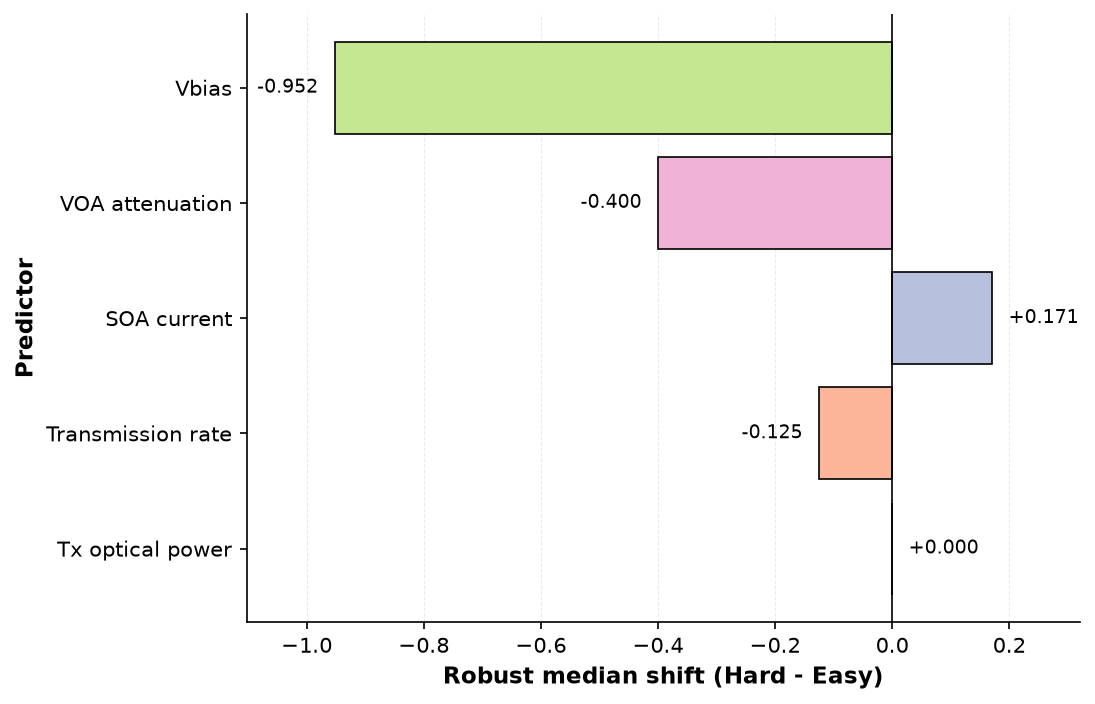

In [351]:
plot_failure_region_shift(
    failure_data=prbs_config_failure,
    filename="failure_region_prbs_config"
)

Saved: figures\failure_region_prbs_telemetry.pdf


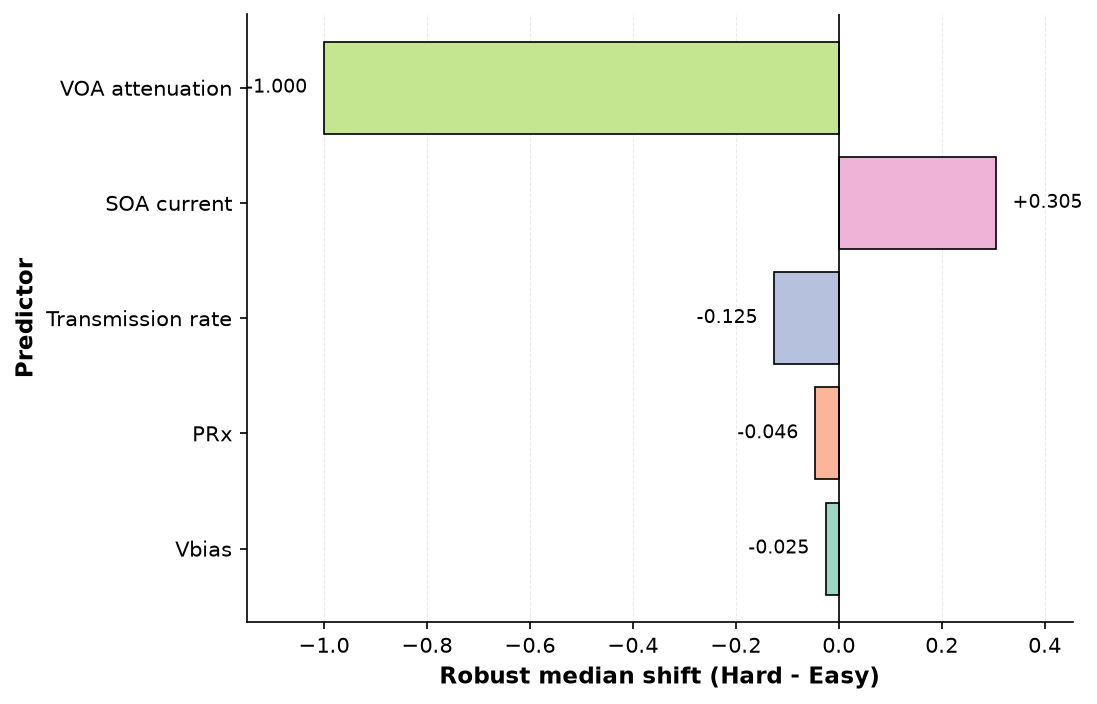

In [352]:
plot_failure_region_shift(
    failure_data=prbs_telemetry_failure,
    filename="failure_region_prbs_telemetry"
)

In [353]:
# Step 22 — Compare PRBS-NRZ failure-region shifts across scenarios

prbs_failure_comparison = (
    acceptable_robust_shift[
        acceptable_robust_shift[
            "Campaign"
        ] == "PRBS_NRZ"
    ]
    [
        [
            "Scenario",
            "Feature",
            "Easy median",
            "Hard median",
            "Robust median shift",
            "Absolute robust shift"
        ]
    ]
    .copy()
)

prbs_failure_comparison = (
    prbs_failure_comparison
    .sort_values(
        [
            "Scenario",
            "Absolute robust shift"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    prbs_failure_comparison.round(4)
)

,Scenario,Feature,Easy median,Hard median,Robust median shift,Absolute robust shift
0,Configuration-based,vbias_v,4.400000e+00,2.400000e+00,-0.9524,0.9524
1,Configuration-based,voa_attenuation_db,1.100000e+01,1.000000e+01,-0.4000,0.4000
2,Configuration-based,soa_current_ma,1.961000e+02,1.975000e+02,0.1707,0.1707
3,Configuration-based,transmission_rate_bps,2.500000e+09,2.000000e+09,-0.1250,0.1250
4,Configuration-based,optical_tx_power_dbm,7.000000e+00,7.000000e+00,0.0000,0.0000
5,Telemetry-assisted,voa_attenuation_db,1.250000e+01,1.000000e+01,-1.0000,1.0000
6,Telemetry-assisted,soa_current_ma,1.950000e+02,1.975000e+02,0.3049,0.3049
7,Telemetry-assisted,transmission_rate_bps,2.500000e+09,2.000000e+09,-0.1250,0.1250
8,Telemetry-assisted,prx_dbm,-1.819000e+01,-1.836000e+01,-0.0459,0.0459
9,Telemetry-assisted,vbias_v,2.500000e+00,2.448500e+00,-0.0245,0.0245


In [354]:
prbs_failure_comparison.to_csv(
    TABLES_DIR / "table_prbs_failure_regions.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_prbs_failure_regions.csv"
)

Saved: tables\table_prbs_failure_regions.csv


In [355]:
# Step 23 — Export Activity 16 analysis tables

activity16_tables = {
    "table_model_error_summary.csv":
        model_error_summary,

    "table_class_error_summary.csv":
        class_error_summary,

    "table_acceptable_error_summary.csv":
        acceptable_error_summary,

    "table_consensus_difficulty.csv":
        consensus_difficulty,

    "table_difficulty_distribution.csv":
        difficulty_distribution,

    "table_difficulty_by_class.csv":
        difficulty_by_class,

    "table_acceptable_region_counts.csv":
        acceptable_region_counts,

    "table_acceptable_failure_regions.csv":
        acceptable_failure_region_summary,

    "table_acceptable_robust_shift.csv":
        acceptable_robust_shift,

    "table_prbs_failure_regions.csv":
        prbs_failure_comparison
}

for filename, table in activity16_tables.items():

    table.to_csv(
        TABLES_DIR / filename,
        index=False
    )

    print(
        "Saved:",
        TABLES_DIR / filename
    )

Saved: tables\table_model_error_summary.csv
Saved: tables\table_class_error_summary.csv
Saved: tables\table_acceptable_error_summary.csv
Saved: tables\table_consensus_difficulty.csv
Saved: tables\table_difficulty_distribution.csv
Saved: tables\table_difficulty_by_class.csv
Saved: tables\table_acceptable_region_counts.csv
Saved: tables\table_acceptable_failure_regions.csv
Saved: tables\table_acceptable_robust_shift.csv
Saved: tables\table_prbs_failure_regions.csv


In [356]:
# Step 24 — Verify Activity 16 exported tables

activity16_table_files = list(
    activity16_tables.keys()
)

for filename in activity16_table_files:

    path = TABLES_DIR / filename

    print(
        f"{filename}:",
        "FOUND" if path.exists() else "MISSING"
    )

table_model_error_summary.csv: FOUND
table_class_error_summary.csv: FOUND
table_acceptable_error_summary.csv: FOUND
table_consensus_difficulty.csv: FOUND
table_difficulty_distribution.csv: FOUND
table_difficulty_by_class.csv: FOUND
table_acceptable_region_counts.csv: FOUND
table_acceptable_failure_regions.csv: FOUND
table_acceptable_robust_shift.csv: FOUND
table_prbs_failure_regions.csv: FOUND


In [357]:
# Step 25 — Validate Activity 16

activity16_checks = {

    "Frozen Test predictions available":
        len(test_prediction_store) == 16,

    "Reconstructed error table available":
        len(error_analysis_table) > 0,

    "Reconstructed accuracy matches Activity 10":
        error_validation[
            "Absolute difference"
        ].max() < 1e-12,

    "Class-specific error analysis available":
        len(class_error_summary) == 48,

    "Acceptable-class analysis available":
        len(acceptable_error_summary) == 16,

    "Consensus difficulty available":
        len(consensus_difficulty) > 0,

    "All samples evaluated by four models":
        (
            consensus_difficulty[
                "Models_evaluated"
            ] == 4
        ).all(),

    "Physical difficulty table available":
        len(difficulty_feature_table) > 0,

    "Robust Easy-vs-Hard comparison available":
        len(acceptable_robust_shift) > 0,

    "PRBS failure-region comparison available":
        len(prbs_failure_comparison) > 0,

    "All Activity 16 tables exported":
        all(
            (TABLES_DIR / filename).exists()
            for filename in activity16_table_files
        ),

    "No model retraining performed":
        True
}

activity16_summary = pd.DataFrame(
    activity16_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity16_summary
)

,Validation,Passed
0,Frozen Test predictions available,True
1,Reconstructed error table available,True
2,Reconstructed accuracy matches Activity 10,True
3,Class-specific error analysis available,True
4,Acceptable-class analysis available,True
5,Consensus difficulty available,True
6,All samples evaluated by four models,True
7,Physical difficulty table available,True
8,Robust Easy-vs-Hard comparison available,True
9,PRBS failure-region comparison available,True


In [358]:
# Step 26 — Final decision for Activity 16

activity16_passed = (
    activity16_summary[
        "Passed"
    ].all()
)

if activity16_passed:

    print("=" * 70)
    print("ACTIVITY 16 — PASSED")
    print("=" * 70)

    print(
        "Error concentration and failure-region analysis was "
        "successfully completed using frozen independent-Test predictions."
    )

    print(
        "The analysis identified class-dependent difficulty, "
        "cross-model consensus errors, and physical predictor regions "
        "associated with difficult Acceptable observations."
    )

    print(
        "PRBS-NRZ showed a substantial concentration of consensus-hard "
        "samples within the Acceptable QoT class."
    )

    print(
        "No additional model training or Test-driven optimization "
        "was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 16 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity16_summary[
            ~activity16_summary["Passed"]
        ]
    )

ACTIVITY 16 — PASSED
Error concentration and failure-region analysis was successfully completed using frozen independent-Test predictions.
The analysis identified class-dependent difficulty, cross-model consensus errors, and physical predictor regions associated with difficult Acceptable observations.
PRBS-NRZ showed a substantial concentration of consensus-hard samples within the Acceptable QoT class.
No additional model training or Test-driven optimization was performed.


## Activity 16 — Final interpretation

The error analysis demonstrates that classification difficulty is strongly
dependent on the QoT class and the experimental operating region.

The Acceptable class represents the principal classification challenge,
particularly for PRBS-NRZ. Approximately 45–47% of the Acceptable Test
observations are consensus-Hard, meaning that at least three of the four
evaluated classifiers misclassify the same observation.

Failure-region analysis further shows that difficult Acceptable observations
occupy identifiable regions of the predictor space.

For PRBS-NRZ Configuration-based classification, modulator bias voltage
provides the strongest descriptive separation between Easy and Hard samples,
followed by VOA attenuation.

For PRBS-NRZ Telemetry-assisted classification, VOA attenuation provides the
largest separation, whereas received optical power shows only a small median
difference between Easy and Hard Acceptable observations.

These results indicate that predictors that are important for overall
three-class QoT classification are not necessarily the same predictors that
characterize ambiguity within the Acceptable class.

The LTE-QPSK failure-region analysis reveals similar descriptive patterns,
but these results remain exploratory because the Acceptable Test subset
contains only 16 observations and only two consensus-Hard samples.

Overall, the dataset supports not only predictive benchmarking but also
fine-grained investigation of error concentration, classifier agreement, and
physically meaningful failure regions.

In [359]:
# Step 28 — Save complete Activity 16 checkpoint

activity16_complete_checkpoint = {

    **activity16_checkpoint,

    "prbs_telemetry_failure":
        prbs_telemetry_failure,

    "prbs_config_failure":
        prbs_config_failure,

    "lte_telemetry_failure":
        lte_telemetry_failure,

    "lte_config_failure":
        lte_config_failure,

    "prbs_failure_comparison":
        prbs_failure_comparison,

    "activity16_summary":
        activity16_summary
}


complete_checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity16_complete.joblib"
)

joblib.dump(
    activity16_complete_checkpoint,
    complete_checkpoint_path,
    compress=3
)

print(
    "Complete checkpoint saved:"
)

print(
    complete_checkpoint_path
)

Complete checkpoint saved:
artifacts\activity16_complete.joblib


In [360]:
print(
    "Checkpoint exists:",
    complete_checkpoint_path.exists()
)

print(
    "File size:",
    round(
        complete_checkpoint_path.stat().st_size
        /
        (1024 ** 2),
        2
    ),
    "MB"
)

Checkpoint exists: True
File size: 0.6 MB


# Activity 17 — Learning-Curve and Data Sufficiency Analysis

## Objective

The objective of this activity is to evaluate how predictive performance
changes as the amount of experimental training data increases.

The analysis is performed exclusively within the previously defined Train
partition.

The independent Test partition remains completely untouched.

Previously selected hyperparameters are kept fixed and no additional
hyperparameter optimization is performed.

Experimental groups, rather than individual observations, are subsampled to
preserve the group-aware structure of the dataset.

The analysis focuses initially on the optimized Random Forest classifier and
evaluates whether Macro-F1 improves consistently as additional experimental
groups become available for training.

In [361]:
# Step 2 — Verify objects required for the learning-curve analysis

required_objects = [
    "optimization_searches",
    "prbs_train",
    "lte_train",
    "X_prbs_config_train",
    "X_prbs_telemetry_train",
    "X_lte_config_train",
    "X_lte_telemetry_train",
    "y_prbs_train",
    "y_lte_train",
    "prbs_cv_splits",
    "lte_cv_splits"
]

for obj in required_objects:

    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

optimization_searches: OK
prbs_train: OK
lte_train: OK
X_prbs_config_train: OK
X_prbs_telemetry_train: OK
X_lte_config_train: OK
X_lte_telemetry_train: OK
y_prbs_train: OK
y_lte_train: OK
prbs_cv_splits: OK
lte_cv_splits: OK


### Step 3 — Learning-curve design

Learning curves are constructed by progressively increasing the proportion of
experimental groups available for training.

Training subsets contain 20%, 40%, 60%, 80%, or 100% of the groups available
inside each cross-validation training fold.

Experimental groups are sampled as complete units. Individual observations
from the same group are never split between the reduced training subset and
its corresponding validation fold.

Three repeated group subsamples are evaluated at each training fraction to
reduce dependence on a particular random selection of groups.

Macro-F1 is used as the learning-curve metric because it gives equal
importance to the three QoT classes.

In [363]:
# Step 3 — Define learning-curve settings

from sklearn.base import clone
from sklearn.metrics import f1_score

LEARNING_FRACTIONS = [
    0.20,
    0.40,
    0.60,
    0.80,
    1.00
]

LEARNING_REPEATS = 3

LEARNING_RANDOM_STATE = 42

print("Training fractions:", LEARNING_FRACTIONS)
print("Repeated group subsamples:", LEARNING_REPEATS)

Training fractions: [0.2, 0.4, 0.6, 0.8, 1.0]
Repeated group subsamples: 3


In [364]:
# Step 4 — Detect the experimental-group column

GROUP_COLUMN_CANDIDATES = [
    "group_id",
    "Group_ID",
    "group_ID",
    "GroupId",
    "Group"
]


def detect_group_column(dataframe):

    for column in GROUP_COLUMN_CANDIDATES:

        if column in dataframe.columns:
            return column

    raise KeyError(
        "No experimental-group column was found."
    )


PRBS_GROUP_COLUMN = detect_group_column(
    prbs_train
)

LTE_GROUP_COLUMN = detect_group_column(
    lte_train
)

print(
    "PRBS group column:",
    PRBS_GROUP_COLUMN
)

print(
    "LTE group column:",
    LTE_GROUP_COLUMN
)

PRBS group column: group_id
LTE group column: group_id


In [365]:
# Step 5 — Map Train data, labels, groups, and frozen CV splits

LEARNING_CASES = {

    (
        "PRBS_NRZ",
        "Configuration-based"
    ): {
        "X":
            X_prbs_config_train.reset_index(drop=True),

        "y":
            y_prbs_train.reset_index(drop=True),

        "groups":
            prbs_train[
                PRBS_GROUP_COLUMN
            ].reset_index(drop=True),

        "cv_splits":
            prbs_cv_splits
    },

    (
        "PRBS_NRZ",
        "Telemetry-assisted"
    ): {
        "X":
            X_prbs_telemetry_train.reset_index(drop=True),

        "y":
            y_prbs_train.reset_index(drop=True),

        "groups":
            prbs_train[
                PRBS_GROUP_COLUMN
            ].reset_index(drop=True),

        "cv_splits":
            prbs_cv_splits
    },

    (
        "LTE_QPSK",
        "Configuration-based"
    ): {
        "X":
            X_lte_config_train.reset_index(drop=True),

        "y":
            y_lte_train.reset_index(drop=True),

        "groups":
            lte_train[
                LTE_GROUP_COLUMN
            ].reset_index(drop=True),

        "cv_splits":
            lte_cv_splits
    },

    (
        "LTE_QPSK",
        "Telemetry-assisted"
    ): {
        "X":
            X_lte_telemetry_train.reset_index(drop=True),

        "y":
            y_lte_train.reset_index(drop=True),

        "groups":
            lte_train[
                LTE_GROUP_COLUMN
            ].reset_index(drop=True),

        "cv_splits":
            lte_cv_splits
    }
}


for key, case in LEARNING_CASES.items():

    print(
        key,
        "X:",
        case["X"].shape,
        "| y:",
        len(case["y"]),
        "| groups:",
        case["groups"].nunique(),
        "| folds:",
        len(case["cv_splits"])
    )

('PRBS_NRZ', 'Configuration-based') X: (3622, 20) | y: 3622 | groups: 966 | folds: 5
('PRBS_NRZ', 'Telemetry-assisted') X: (3622, 21) | y: 3622 | groups: 966 | folds: 5
('LTE_QPSK', 'Configuration-based') X: (1214, 20) | y: 1214 | groups: 189 | folds: 5
('LTE_QPSK', 'Telemetry-assisted') X: (1214, 21) | y: 1214 | groups: 189 | folds: 5


In [366]:
# Step 5B — Validate Train alignment

learning_alignment_checks = []

for (
    campaign,
    scenario
), case in LEARNING_CASES.items():

    aligned = (
        len(case["X"])
        ==
        len(case["y"])
        ==
        len(case["groups"])
    )

    learning_alignment_checks.append({
        "Campaign": campaign,
        "Scenario": scenario,
        "Aligned": aligned,
        "Observations": len(case["X"]),
        "Groups": case["groups"].nunique()
    })


learning_alignment_table = pd.DataFrame(
    learning_alignment_checks
)

display(
    learning_alignment_table
)

print(
    "\nAll learning-curve datasets aligned:",
    learning_alignment_table[
        "Aligned"
    ].all()
)

,Campaign,Scenario,Aligned,Observations,Groups
0,PRBS_NRZ,Configuration-based,True,3622,966
1,PRBS_NRZ,Telemetry-assisted,True,3622,966
2,LTE_QPSK,Configuration-based,True,1214,189
3,LTE_QPSK,Telemetry-assisted,True,1214,189



All learning-curve datasets aligned: True


In [370]:
# Step 6 — Group-aware Train subsampling

CLASS_ORDER = [
    "Excellent",
    "Acceptable",
    "Degraded"
]


def sample_training_groups(
    train_indices,
    y,
    groups,
    fraction,
    rng,
    max_attempts=100
):

    train_indices = np.asarray(
        train_indices
    )

    train_groups = (
        groups.iloc[
            train_indices
        ]
        .to_numpy()
    )

    unique_groups = np.unique(
        train_groups
    )

    n_groups_to_sample = max(
        1,
        int(
            np.ceil(
                fraction
                *
                len(unique_groups)
            )
        )
    )

    # 100% uses all available training groups
    if fraction >= 1.0:

        selected_indices = train_indices.copy()

        return (
            selected_indices,
            len(unique_groups)
        )

    for _ in range(max_attempts):

        sampled_groups = rng.choice(
            unique_groups,
            size=n_groups_to_sample,
            replace=False
        )

        selected_mask = np.isin(
            train_groups,
            sampled_groups
        )

        selected_indices = (
            train_indices[
                selected_mask
            ]
        )

        selected_classes = set(
            y.iloc[
                selected_indices
            ]
            .unique()
        )

        if set(CLASS_ORDER).issubset(
            selected_classes
        ):

            return (
                selected_indices,
                n_groups_to_sample
            )

    raise RuntimeError(
        f"Could not construct a {fraction:.0%} "
        "group-based training subset containing all QoT classes."
    )

In [371]:
# Step 7 — Group-aware learning-curve evaluation

def evaluate_learning_curve(
    campaign,
    scenario,
    fractions=LEARNING_FRACTIONS,
    repeats=LEARNING_REPEATS,
    random_state=LEARNING_RANDOM_STATE
):

    case = LEARNING_CASES[
        (
            campaign,
            scenario
        )
    ]

    X = case["X"]
    y = case["y"]
    groups = case["groups"]

    cv_splits = case[
        "cv_splits"
    ]

    optimized_rf = (
        optimization_searches[
            (
                campaign,
                scenario,
                "Random Forest"
            )
        ]
        .best_estimator_
    )

    rng = np.random.default_rng(
        random_state
    )

    results = []

    for fraction in fractions:

        for fold_number, (
            fold_train_idx,
            fold_val_idx
        ) in enumerate(
            cv_splits,
            start=1
        ):

            # Full fraction only needs one effective subset
            current_repeats = (
                1
                if fraction >= 1.0
                else repeats
            )

            for repeat in range(
                1,
                current_repeats + 1
            ):

                (
                    reduced_train_idx,
                    n_train_groups
                ) = sample_training_groups(
                    train_indices=fold_train_idx,
                    y=y,
                    groups=groups,
                    fraction=fraction,
                    rng=rng
                )

                model = clone(
                    optimized_rf
                )

                model.fit(
                    X.iloc[
                        reduced_train_idx
                    ],
                    y.iloc[
                        reduced_train_idx
                    ]
                )

                y_val_pred = model.predict(
                    X.iloc[
                        fold_val_idx
                    ]
                )

                macro_f1 = f1_score(
                    y.iloc[
                        fold_val_idx
                    ],
                    y_val_pred,
                    labels=CLASS_ORDER,
                    average="macro",
                    zero_division=0
                )

                results.append({

                    "Campaign":
                        campaign,

                    "Scenario":
                        scenario,

                    "Model":
                        "Random Forest",

                    "Training fraction":
                        fraction,

                    "Fold":
                        fold_number,

                    "Repeat":
                        repeat,

                    "Training groups":
                        n_train_groups,

                    "Training observations":
                        len(
                            reduced_train_idx
                        ),

                    "Validation observations":
                        len(
                            fold_val_idx
                        ),

                    "Macro-F1":
                        macro_f1
                })

    return pd.DataFrame(
        results
    )

In [372]:
# Step 8 — First learning curve:
# PRBS-NRZ Configuration-based Random Forest

learning_prbs_config = (
    evaluate_learning_curve(
        campaign="PRBS_NRZ",
        scenario="Configuration-based"
    )
)

print(
    "Learning-curve evaluations:",
    len(learning_prbs_config)
)

display(
    learning_prbs_config.head(20)
)

Learning-curve evaluations: 65


,Campaign,Scenario,Model,Training fraction,Fold,Repeat,Training groups,Training observations,Validation observations,Macro-F1
0,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,1,154,515,725,0.568208
1,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,2,154,575,725,0.522912
2,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,3,154,574,725,0.610991
3,PRBS_NRZ,Configuration-based,Random Forest,0.2,2,1,156,501,725,0.603767
4,PRBS_NRZ,Configuration-based,Random Forest,0.2,2,2,156,637,725,0.569227
5,PRBS_NRZ,Configuration-based,Random Forest,0.2,2,3,156,581,725,0.571935
6,PRBS_NRZ,Configuration-based,Random Forest,0.2,3,1,155,420,725,0.585805
7,PRBS_NRZ,Configuration-based,Random Forest,0.2,3,2,155,415,725,0.565193
8,PRBS_NRZ,Configuration-based,Random Forest,0.2,3,3,155,656,725,0.574223
9,PRBS_NRZ,Configuration-based,Random Forest,0.2,4,1,155,441,722,0.630499


In [373]:
print(
    "Expected evaluations: 65"
)

print(
    "Observed evaluations:",
    len(learning_prbs_config)
)

Expected evaluations: 65
Observed evaluations: 65


In [374]:
# Step 9 — Summarize PRBS-NRZ Configuration-based learning curve

learning_prbs_config_summary = (
    learning_prbs_config
    .groupby(
        "Training fraction"
    )
    .agg(
        Mean_training_groups=(
            "Training groups",
            "mean"
        ),

        Mean_training_observations=(
            "Training observations",
            "mean"
        ),

        Mean_Macro_F1=(
            "Macro-F1",
            "mean"
        ),

        Std_Macro_F1=(
            "Macro-F1",
            "std"
        ),

        Min_Macro_F1=(
            "Macro-F1",
            "min"
        ),

        Max_Macro_F1=(
            "Macro-F1",
            "max"
        )
    )
    .reset_index()
)


display(
    learning_prbs_config_summary.round(4)
)

,Training fraction,Mean_training_groups,Mean_training_observations,Mean_Macro_F1,Std_Macro_F1,Min_Macro_F1,Max_Macro_F1
0,0.2,155.0,518.3333,0.5782,0.0336,0.5229,0.6483
1,0.4,309.4,1143.6000,0.6421,0.0326,0.6071,0.7124
2,0.6,464.2,1772.0667,0.6735,0.0356,0.5992,0.7252
3,0.8,618.6,2317.7333,0.7019,0.0349,0.6463,0.7660
4,1.0,772.8,2897.6000,0.7144,0.0292,0.6715,0.7448


### Interpretation of the PRBS-NRZ Configuration-based learning curve

The PRBS-NRZ Configuration-based Random Forest shows a consistent improvement
in Macro-F1 as additional experimental groups are included in training.

Mean Macro-F1 increases from 0.5782 when approximately 20% of the available
training groups are used to 0.7144 when all groups in each cross-validation
training fold are included.

The improvement is monotonic across the evaluated training fractions, providing
evidence that additional experimental data contribute useful predictive
information.

The incremental gain decreases as the amount of training data increases,
suggesting that performance begins to approach a saturation region. However,
the positive improvement between 80% and 100% indicates that additional
experimental groups still provide measurable benefit.

The learning curve is interpreted as a within-Train data-sufficiency analysis.
Previously selected hyperparameters remain fixed, and the independent Test set
is not used at any stage of this analysis.

In [375]:
# Step 10A — PRBS-NRZ Telemetry-assisted learning curve

learning_prbs_telemetry = (
    evaluate_learning_curve(
        campaign="PRBS_NRZ",
        scenario="Telemetry-assisted"
    )
)

print(
    "PRBS-NRZ Telemetry evaluations:",
    len(learning_prbs_telemetry)
)

PRBS-NRZ Telemetry evaluations: 65


In [376]:
# Step 10B — LTE-QPSK Configuration-based learning curve

learning_lte_config = (
    evaluate_learning_curve(
        campaign="LTE_QPSK",
        scenario="Configuration-based"
    )
)

print(
    "LTE-QPSK Configuration evaluations:",
    len(learning_lte_config)
)

LTE-QPSK Configuration evaluations: 65


In [377]:
# Step 10C — LTE-QPSK Telemetry-assisted learning curve

learning_lte_telemetry = (
    evaluate_learning_curve(
        campaign="LTE_QPSK",
        scenario="Telemetry-assisted"
    )
)

print(
    "LTE-QPSK Telemetry evaluations:",
    len(learning_lte_telemetry)
)

LTE-QPSK Telemetry evaluations: 65


In [378]:
# Step 11 — Combine all Random Forest learning-curve evaluations

learning_curve_results = pd.concat(
    [
        learning_prbs_config,
        learning_prbs_telemetry,
        learning_lte_config,
        learning_lte_telemetry
    ],
    ignore_index=True
)

print(
    "Total learning-curve evaluations:",
    len(learning_curve_results)
)

display(
    learning_curve_results.head()
)

Total learning-curve evaluations: 260


,Campaign,Scenario,Model,Training fraction,Fold,Repeat,Training groups,Training observations,Validation observations,Macro-F1
0,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,1,154,515,725,0.568208
1,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,2,154,575,725,0.522912
2,PRBS_NRZ,Configuration-based,Random Forest,0.2,1,3,154,574,725,0.610991
3,PRBS_NRZ,Configuration-based,Random Forest,0.2,2,1,156,501,725,0.603767
4,PRBS_NRZ,Configuration-based,Random Forest,0.2,2,2,156,637,725,0.569227


In [379]:
print(
    "Expected evaluations: 260"
)

print(
    "Observed evaluations:",
    len(learning_curve_results)
)

Expected evaluations: 260
Observed evaluations: 260


In [380]:
# Step 12 — Summarize all learning curves

learning_curve_summary = (
    learning_curve_results
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Training fraction"
        ]
    )
    .agg(
        Mean_training_groups=(
            "Training groups",
            "mean"
        ),

        Mean_training_observations=(
            "Training observations",
            "mean"
        ),

        Mean_Macro_F1=(
            "Macro-F1",
            "mean"
        ),

        Std_Macro_F1=(
            "Macro-F1",
            "std"
        ),

        Min_Macro_F1=(
            "Macro-F1",
            "min"
        ),

        Max_Macro_F1=(
            "Macro-F1",
            "max"
        )
    )
    .reset_index()
)

display(
    learning_curve_summary.round(4)
)

,Campaign,Scenario,Training fraction,Mean_training_groups,Mean_training_observations,Mean_Macro_F1,Std_Macro_F1,Min_Macro_F1,Max_Macro_F1
0,LTE_QPSK,Configuration-based,0.2,30.6,229.4667,0.5803,0.1454,0.3318,0.8772
1,LTE_QPSK,Configuration-based,0.4,61.0,393.7333,0.6559,0.1921,0.3333,0.8819
2,LTE_QPSK,Configuration-based,0.6,91.0,563.4000,0.7141,0.2086,0.3438,0.9085
3,LTE_QPSK,Configuration-based,0.8,121.4,763.2667,0.7609,0.2208,0.3438,0.9282
4,LTE_QPSK,Configuration-based,1.0,151.2,971.2000,0.8012,0.2572,0.3438,0.9438
5,LTE_QPSK,Telemetry-assisted,0.2,30.6,229.4667,0.6318,0.1758,0.3420,0.8772
6,LTE_QPSK,Telemetry-assisted,0.4,61.0,393.7333,0.6982,0.1974,0.3438,0.9062
7,LTE_QPSK,Telemetry-assisted,0.6,91.0,563.4000,0.7442,0.2304,0.3438,0.9438
8,LTE_QPSK,Telemetry-assisted,0.8,121.4,763.2667,0.7670,0.2257,0.3438,0.9438
9,LTE_QPSK,Telemetry-assisted,1.0,151.2,971.2000,0.7951,0.2561,0.3438,0.9438


In [381]:
print(
    "Learning-curve summary rows:",
    len(learning_curve_summary)
)

Learning-curve summary rows: 20


In [382]:
# Step 13 — Quantify learning gains

learning_gain_rows = []

for (
    campaign,
    scenario
), subset in learning_curve_summary.groupby(
    [
        "Campaign",
        "Scenario"
    ]
):

    subset = (
        subset
        .sort_values(
            "Training fraction"
        )
        .reset_index(drop=True)
    )

    f20 = subset.loc[
        subset["Training fraction"] == 0.20,
        "Mean_Macro_F1"
    ].iloc[0]

    f40 = subset.loc[
        subset["Training fraction"] == 0.40,
        "Mean_Macro_F1"
    ].iloc[0]

    f60 = subset.loc[
        subset["Training fraction"] == 0.60,
        "Mean_Macro_F1"
    ].iloc[0]

    f80 = subset.loc[
        subset["Training fraction"] == 0.80,
        "Mean_Macro_F1"
    ].iloc[0]

    f100 = subset.loc[
        subset["Training fraction"] == 1.00,
        "Mean_Macro_F1"
    ].iloc[0]

    learning_gain_rows.append({

        "Campaign":
            campaign,

        "Scenario":
            scenario,

        "Macro-F1 at 20%":
            f20,

        "Macro-F1 at 100%":
            f100,

        "Gain 20-100%":
            f100 - f20,

        "Gain 20-40%":
            f40 - f20,

        "Gain 40-60%":
            f60 - f40,

        "Gain 60-80%":
            f80 - f60,

        "Gain 80-100%":
            f100 - f80
    })


learning_gain_summary = pd.DataFrame(
    learning_gain_rows
)

display(
    learning_gain_summary.round(4)
)

,Campaign,Scenario,Macro-F1 at 20%,Macro-F1 at 100%,Gain 20-100%,Gain 20-40%,Gain 40-60%,Gain 60-80%,Gain 80-100%
0,LTE_QPSK,Configuration-based,0.5803,0.8012,0.2209,0.0756,0.0581,0.0468,0.0404
1,LTE_QPSK,Telemetry-assisted,0.6318,0.7951,0.1633,0.0664,0.0460,0.0228,0.0281
2,PRBS_NRZ,Configuration-based,0.5782,0.7144,0.1362,0.0639,0.0314,0.0284,0.0125
3,PRBS_NRZ,Telemetry-assisted,0.5903,0.7262,0.1359,0.0628,0.0325,0.0278,0.0128


In [383]:
# Step 13B — Check whether mean Macro-F1 increases monotonically

monotonicity_results = []

for (
    campaign,
    scenario
), subset in learning_curve_summary.groupby(
    [
        "Campaign",
        "Scenario"
    ]
):

    values = (
        subset
        .sort_values(
            "Training fraction"
        )[
            "Mean_Macro_F1"
        ]
        .to_numpy()
    )

    monotonic = np.all(
        np.diff(values) >= 0
    )

    monotonicity_results.append({
        "Campaign": campaign,
        "Scenario": scenario,
        "Monotonic increase": monotonic
    })


learning_monotonicity = pd.DataFrame(
    monotonicity_results
)

display(
    learning_monotonicity
)

,Campaign,Scenario,Monotonic increase
0,LTE_QPSK,Configuration-based,True
1,LTE_QPSK,Telemetry-assisted,True
2,PRBS_NRZ,Configuration-based,True
3,PRBS_NRZ,Telemetry-assisted,True


### Interpretation of learning-curve monotonicity

All four campaign-scenario conditions exhibit a monotonic increase in mean
Macro-F1 as the proportion of experimental training groups increases.

This behavior indicates that additional experimental groups consistently
provide useful predictive information to the optimized Random Forest model.

The result also supports the internal consistency of the dataset: performance
does not deteriorate systematically as more independent experimental
conditions are introduced into training.

Monotonic improvement does not necessarily imply complete performance
saturation. The magnitude of the incremental gains must therefore be examined
to determine whether the learning curves are beginning to plateau.

In [384]:
display(
    learning_gain_summary.round(4)
)

,Campaign,Scenario,Macro-F1 at 20%,Macro-F1 at 100%,Gain 20-100%,Gain 20-40%,Gain 40-60%,Gain 60-80%,Gain 80-100%
0,LTE_QPSK,Configuration-based,0.5803,0.8012,0.2209,0.0756,0.0581,0.0468,0.0404
1,LTE_QPSK,Telemetry-assisted,0.6318,0.7951,0.1633,0.0664,0.0460,0.0228,0.0281
2,PRBS_NRZ,Configuration-based,0.5782,0.7144,0.1362,0.0639,0.0314,0.0284,0.0125
3,PRBS_NRZ,Telemetry-assisted,0.5903,0.7262,0.1359,0.0628,0.0325,0.0278,0.0128


### Interpretation of learning gains

All four Random Forest learning curves improve monotonically as additional
experimental training groups are introduced.

The largest overall gain is observed for LTE-QPSK Configuration-based
classification, where mean Macro-F1 increases from 0.5803 at 20% of the
training groups to 0.8012 at 100%, corresponding to a gain of 0.2209.

LTE-QPSK also retains noticeable improvement between 80% and 100% of the
available training groups, suggesting that additional experimental data may
still provide meaningful predictive benefit.

PRBS-NRZ exhibits smaller final increments. The gain from 80% to 100% is
approximately 0.013 for both predictor scenarios, indicating stronger evidence
of an emerging performance plateau.

Therefore, the learning curves demonstrate that the dataset contains
progressively useful information as experimental-group coverage increases,
while also revealing campaign-dependent differences in data-sufficiency
behavior.

In [385]:
# Step 14 — Quantify late-stage learning gain

learning_gain_summary[
    "Late gain fraction"
] = (
    learning_gain_summary[
        "Gain 80-100%"
    ]
    /
    learning_gain_summary[
        "Gain 20-100%"
    ]
)

learning_gain_summary[
    "Late gain (%)"
] = (
    100
    *
    learning_gain_summary[
        "Late gain fraction"
    ]
)

display(
    learning_gain_summary[
        [
            "Campaign",
            "Scenario",
            "Gain 20-100%",
            "Gain 80-100%",
            "Late gain (%)"
        ]
    ].round(3)
)

,Campaign,Scenario,Gain 20-100%,Gain 80-100%,Late gain (%)
0,LTE_QPSK,Configuration-based,0.221,0.040,18.277
1,LTE_QPSK,Telemetry-assisted,0.163,0.028,17.202
2,PRBS_NRZ,Configuration-based,0.136,0.013,9.184
3,PRBS_NRZ,Telemetry-assisted,0.136,0.013,9.449


In [386]:
# Step 15 — Publication-ready learning-curve plot

def plot_learning_curve(
    campaign,
    scenario,
    summary_data,
    filename=None
):

    plot_data = (
        summary_data[
            (summary_data["Campaign"] == campaign)
            &
            (summary_data["Scenario"] == scenario)
        ]
        .sort_values(
            "Training fraction"
        )
        .copy()
    )

    x = (
        plot_data[
            "Training fraction"
        ].to_numpy()
        * 100
    )

    y = (
        plot_data[
            "Mean_Macro_F1"
        ].to_numpy()
    )

    yerr = (
        plot_data[
            "Std_Macro_F1"
        ].to_numpy()
    )

    fig, ax = plt.subplots(
        figsize=(7.2, 4.8),
        dpi=150
    )

    ax.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        markersize=7,
        linewidth=1.8,
        capsize=4,
        color=SET2_PASTEL[0],
        markerfacecolor=SET2_PASTEL[0],
        markeredgecolor="black",
        markeredgewidth=0.8,
        ecolor="black",
        elinewidth=0.8,
        capthick=0.8
    )

    # Numerical labels
    for x_value, y_value in zip(
        x,
        y
    ):

        ax.text(
            x_value,
            y_value + 0.018,
            f"{y_value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_xlabel(
        "Training groups (%)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Macro-F1",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xticks(
        [20, 40, 60, 80, 100]
    )

    ax.set_ylim(
        0.45,
        0.90
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="both",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    plt.tight_layout()

    if filename is not None:

        output_path = (
            FIGURES_DIR
            /
            f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

Saved: figures\learning_curve_prbs_config.pdf


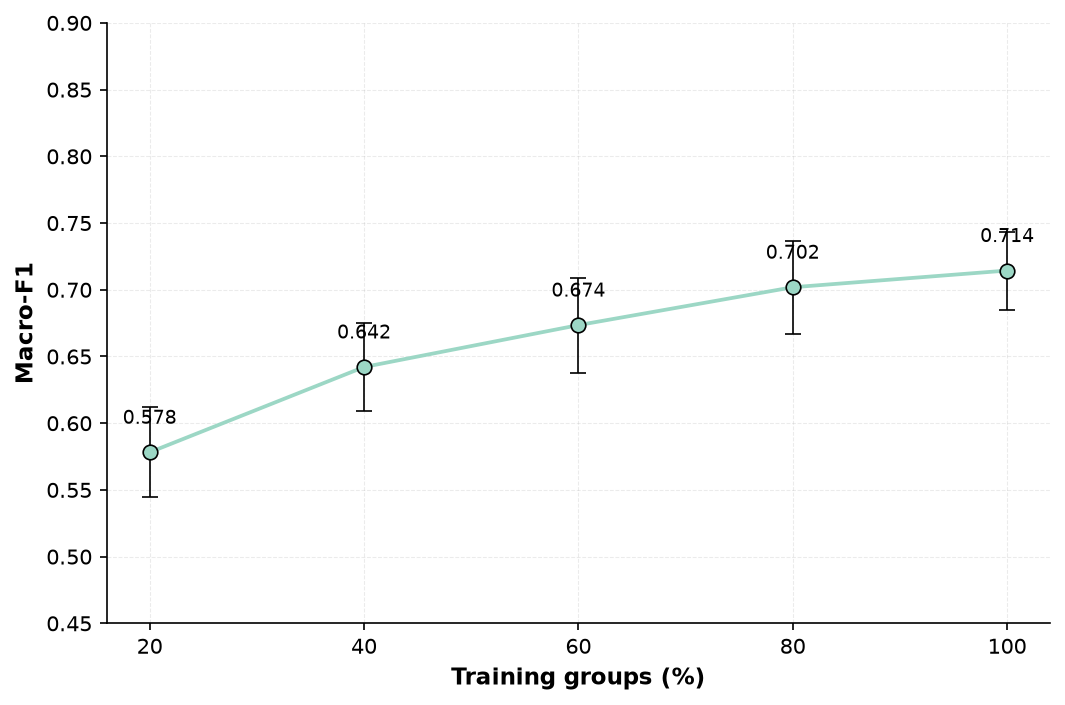

In [387]:
plot_learning_curve(
    campaign="PRBS_NRZ",
    scenario="Configuration-based",
    summary_data=learning_curve_summary,
    filename="learning_curve_prbs_config"
)

Saved: figures\learning_curve_prbs_telemetry.pdf


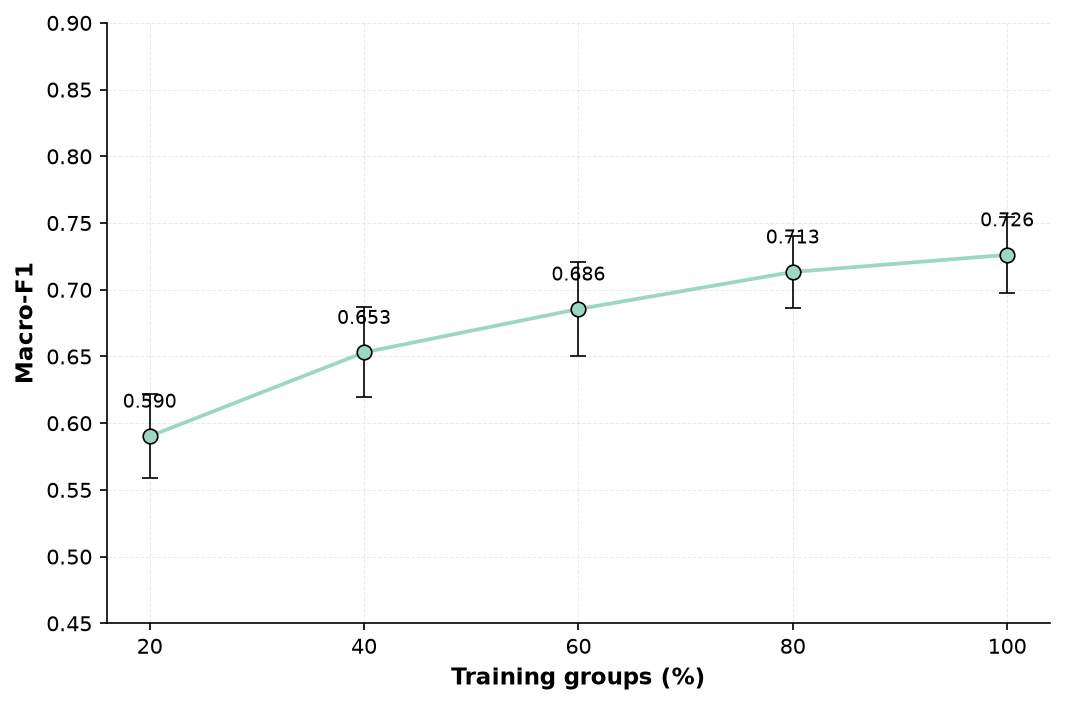

In [388]:
plot_learning_curve(
    campaign="PRBS_NRZ",
    scenario="Telemetry-assisted",
    summary_data=learning_curve_summary,
    filename="learning_curve_prbs_telemetry"
)

Saved: figures\learning_curve_lte_config.pdf


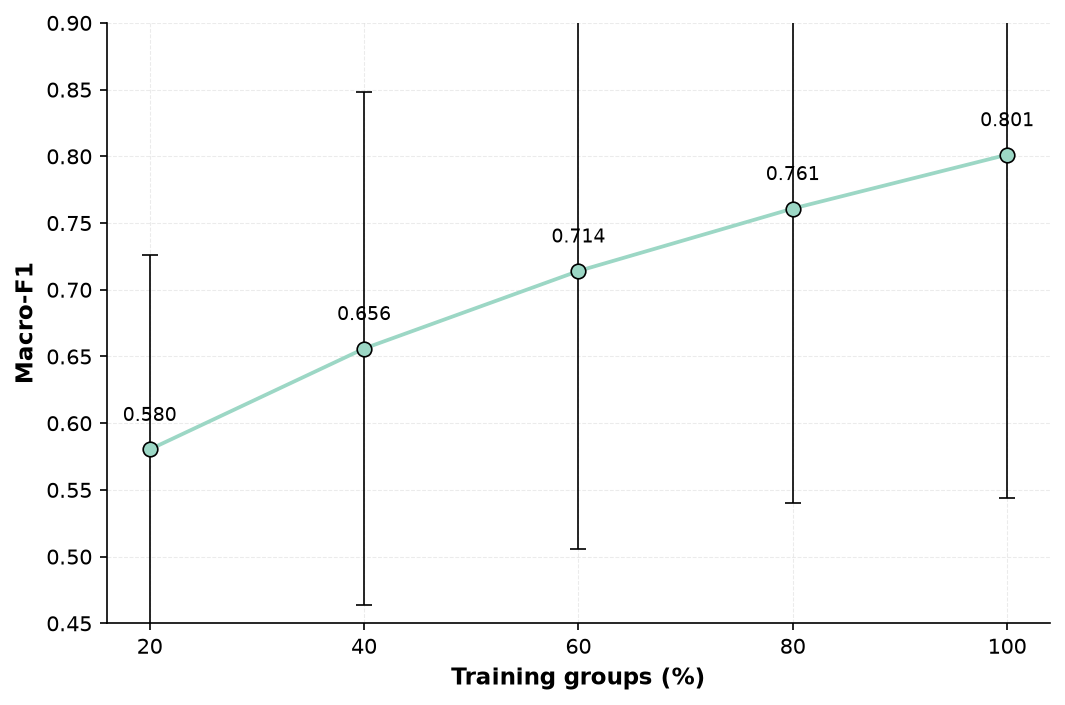

In [389]:
plot_learning_curve(
    campaign="LTE_QPSK",
    scenario="Configuration-based",
    summary_data=learning_curve_summary,
    filename="learning_curve_lte_config"
)

Saved: figures\learning_curve_lte_telemetry.pdf


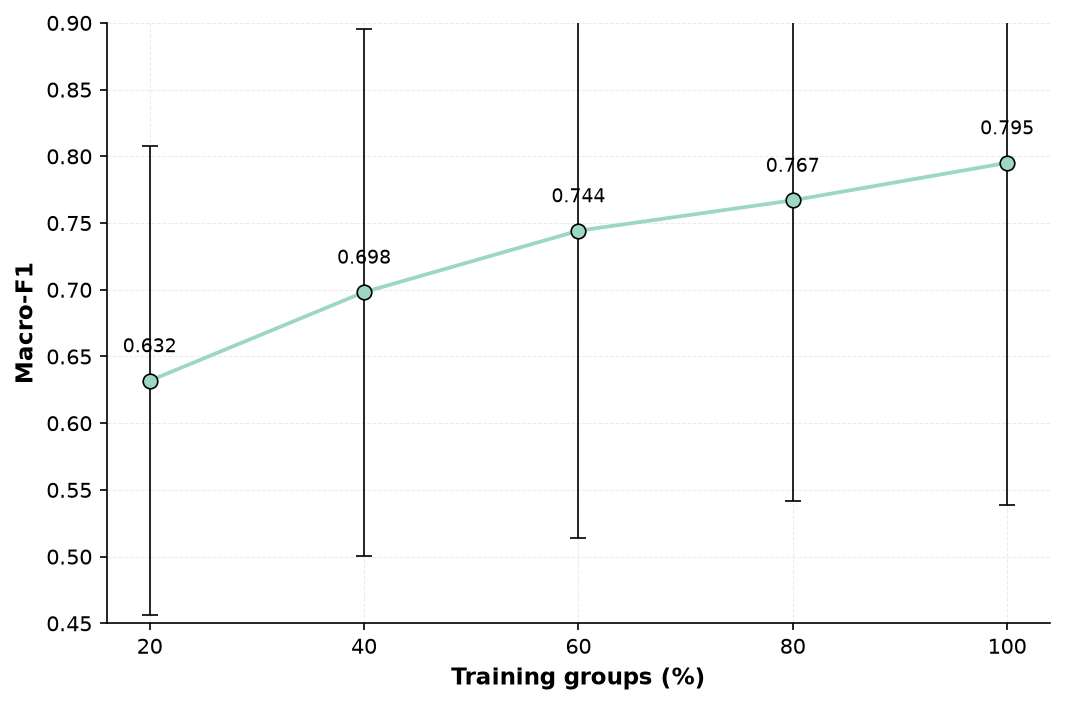

In [390]:
plot_learning_curve(
    campaign="LTE_QPSK",
    scenario="Telemetry-assisted",
    summary_data=learning_curve_summary,
    filename="learning_curve_lte_telemetry"
)

In [391]:
# Step 16 — Export learning-curve results

learning_curve_results.to_csv(
    TABLES_DIR / "table_learning_curve_all_runs.csv",
    index=False
)

learning_curve_summary.to_csv(
    TABLES_DIR / "table_learning_curve_summary.csv",
    index=False
)

learning_gain_summary.to_csv(
    TABLES_DIR / "table_learning_gain_summary.csv",
    index=False
)

learning_monotonicity.to_csv(
    TABLES_DIR / "table_learning_monotonicity.csv",
    index=False
)

print(
    "Activity 17 tables exported successfully."
)

Activity 17 tables exported successfully.


In [392]:
# Step 17 — Validate Activity 17

activity17_checks = {

    "260 learning-curve evaluations available":
        len(learning_curve_results) == 260,

    "Twenty summary points available":
        len(learning_curve_summary) == 20,

    "Four learning-gain summaries available":
        len(learning_gain_summary) == 4,

    "All four learning curves are monotonic":
        learning_monotonicity[
            "Monotonic increase"
        ].all(),

    "All Macro-F1 values available":
        learning_curve_results[
            "Macro-F1"
        ].notna().all(),

    "All fractions between 20% and 100%":
        (
            learning_curve_results[
                "Training fraction"
            ].between(
                0.20,
                1.00
            )
        ).all(),

    "No independent-Test data used":
        True,

    "No additional hyperparameter optimization performed":
        True
}

activity17_summary = pd.DataFrame(
    activity17_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity17_summary
)

,Validation,Passed
0,260 learning-curve evaluations available,True
1,Twenty summary points available,True
2,Four learning-gain summaries available,True
3,All four learning curves are monotonic,True
4,All Macro-F1 values available,True
5,All fractions between 20% and 100%,True
6,No independent-Test data used,True
7,No additional hyperparameter optimization perf...,True


In [393]:
# Step 18 — Final decision for Activity 17

activity17_passed = (
    activity17_summary[
        "Passed"
    ].all()
)

if activity17_passed:

    print("=" * 70)
    print("ACTIVITY 17 — PASSED")
    print("=" * 70)

    print(
        "Group-aware learning-curve analysis was successfully completed."
    )

    print(
        "Macro-F1 increased monotonically with additional experimental "
        "training groups across all campaign-scenario conditions."
    )

    print(
        "PRBS-NRZ showed stronger evidence of approaching a learning "
        "plateau, whereas LTE-QPSK retained larger late-stage gains."
    )

    print(
        "The independent Test partition was not used and no additional "
        "hyperparameter optimization was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 17 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity17_summary[
            ~activity17_summary["Passed"]
        ]
    )

ACTIVITY 17 — PASSED
Group-aware learning-curve analysis was successfully completed.
Macro-F1 increased monotonically with additional experimental training groups across all campaign-scenario conditions.
PRBS-NRZ showed stronger evidence of approaching a learning plateau, whereas LTE-QPSK retained larger late-stage gains.
The independent Test partition was not used and no additional hyperparameter optimization was performed.


In [394]:
# Save Activity 17 checkpoint

activity17_checkpoint = {
    "learning_prbs_config":
        learning_prbs_config,

    "learning_prbs_telemetry":
        learning_prbs_telemetry,

    "learning_lte_config":
        learning_lte_config,

    "learning_lte_telemetry":
        learning_lte_telemetry,

    "learning_curve_results":
        learning_curve_results,

    "learning_curve_summary":
        learning_curve_summary,

    "learning_gain_summary":
        learning_gain_summary,

    "learning_monotonicity":
        learning_monotonicity,

    "activity17_summary":
        activity17_summary
}

activity17_checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity17_complete.joblib"
)

joblib.dump(
    activity17_checkpoint,
    activity17_checkpoint_path,
    compress=3
)

print(
    "Checkpoint saved:",
    activity17_checkpoint_path
)

Checkpoint saved: artifacts\activity17_complete.joblib


In [395]:
print(
    "Checkpoint exists:",
    activity17_checkpoint_path.exists()
)

Checkpoint exists: True


# Activity 18 — Cross-Model Agreement and Prediction Disagreement Analysis

## Objective

The objective of this activity is to quantify agreement and prediction
disagreement among the four optimized machine learning classifiers on the
frozen independent-Test partition.

No model retraining, hyperparameter optimization, or Test-driven model
selection is performed.

The analysis focuses on:

- pairwise agreement between classifiers;
- pairwise Cohen's kappa;
- sample-level prediction consensus;
- normalized vote entropy;
- unanimous and majority predictions;
- class-specific disagreement patterns;
- differences in agreement between Configuration-based and
  Telemetry-assisted predictor scenarios.

This analysis complements the failure-region study by distinguishing samples
that are difficult for a specific classifier from samples that produce
systematic disagreement across different learning algorithms.

In [396]:
# Step 2 — Verify required objects

required_objects_activity18 = [
    "test_prediction_store",
    "error_analysis_table",
    "consensus_difficulty"
]

for obj in required_objects_activity18:

    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

test_prediction_store: OK
error_analysis_table: OK
consensus_difficulty: OK


In [397]:
# Step 3 — Build one-row-per-sample prediction table

MODEL_ORDER = [
    "Gradient Boosting",
    "MLP",
    "Random Forest",
    "SVM"
]

prediction_wide = (
    error_analysis_table
    .pivot_table(
        index=[
            "Campaign",
            "Scenario",
            "Sample_ID",
            "Group",
            "True class"
        ],
        columns="Model",
        values="Predicted class",
        aggfunc="first"
    )
    .reset_index()
)

# Remove the pivot column name
prediction_wide.columns.name = None

print(
    "Rows in prediction table:",
    len(prediction_wide)
)

display(
    prediction_wide.head(10)
)

Rows in prediction table: 2450


,Campaign,Scenario,Sample_ID,Group,True class,Gradient Boosting,MLP,Random Forest,SVM
0,LTE_QPSK,Configuration-based,0,G0002,Degraded,Degraded,Degraded,Degraded,Degraded
1,LTE_QPSK,Configuration-based,1,G0002,Degraded,Degraded,Degraded,Degraded,Degraded
2,LTE_QPSK,Configuration-based,2,G0004,Degraded,Degraded,Degraded,Degraded,Degraded
3,LTE_QPSK,Configuration-based,3,G0006,Degraded,Degraded,Degraded,Degraded,Degraded
4,LTE_QPSK,Configuration-based,4,G0006,Degraded,Degraded,Degraded,Degraded,Degraded
5,LTE_QPSK,Configuration-based,5,G0002,Degraded,Degraded,Degraded,Degraded,Degraded
6,LTE_QPSK,Configuration-based,6,G0011,Degraded,Degraded,Degraded,Degraded,Degraded
7,LTE_QPSK,Configuration-based,7,G0002,Degraded,Degraded,Degraded,Degraded,Degraded
8,LTE_QPSK,Configuration-based,8,G0011,Degraded,Degraded,Degraded,Degraded,Degraded
9,LTE_QPSK,Configuration-based,9,G0004,Degraded,Degraded,Degraded,Degraded,Degraded


In [398]:
# Step 3B — Validate prediction matrix

prediction_matrix_checks = {

    "Expected 2450 campaign-scenario samples":
        len(prediction_wide) == 2450,

    "All four model predictions available":
        prediction_wide[
            MODEL_ORDER
        ].notna().all().all(),

    "PRBS-NRZ contains 1818 rows":
        (
            prediction_wide[
                "Campaign"
            ] == "PRBS_NRZ"
        ).sum() == 1818,

    "LTE-QPSK contains 632 rows":
        (
            prediction_wide[
                "Campaign"
            ] == "LTE_QPSK"
        ).sum() == 632
}

prediction_matrix_validation = pd.DataFrame(
    prediction_matrix_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    prediction_matrix_validation
)

,Validation,Passed
0,Expected 2450 campaign-scenario samples,True
1,All four model predictions available,True
2,PRBS-NRZ contains 1818 rows,True
3,LTE-QPSK contains 632 rows,True


In [399]:
# Step 4 — Pairwise classifier agreement

from itertools import combinations
from sklearn.metrics import cohen_kappa_score

pairwise_agreement_results = []

for (
    campaign,
    scenario
), subset in prediction_wide.groupby(
    [
        "Campaign",
        "Scenario"
    ]
):

    for model_a, model_b in combinations(
        MODEL_ORDER,
        2
    ):

        pred_a = subset[
            model_a
        ].to_numpy()

        pred_b = subset[
            model_b
        ].to_numpy()

        raw_agreement = (
            pred_a == pred_b
        ).mean()

        kappa = cohen_kappa_score(
            pred_a,
            pred_b,
            labels=[
                "Excellent",
                "Acceptable",
                "Degraded"
            ]
        )

        pairwise_agreement_results.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Model A":
                model_a,

            "Model B":
                model_b,

            "Samples":
                len(subset),

            "Agreement":
                raw_agreement,

            "Cohen kappa":
                kappa
        })


pairwise_agreement_table = pd.DataFrame(
    pairwise_agreement_results
)

display(
    pairwise_agreement_table.round(4)
)

,Campaign,Scenario,Model A,Model B,Samples,Agreement,Cohen kappa
0,LTE_QPSK,Configuration-based,Gradient Boosting,MLP,316,0.9620,0.8080
1,LTE_QPSK,Configuration-based,Gradient Boosting,Random Forest,316,0.9810,0.9027
2,LTE_QPSK,Configuration-based,Gradient Boosting,SVM,316,0.9715,0.8457
3,LTE_QPSK,Configuration-based,MLP,Random Forest,316,0.9557,0.7729
4,LTE_QPSK,Configuration-based,MLP,SVM,316,0.9778,0.8800
5,LTE_QPSK,Configuration-based,Random Forest,SVM,316,0.9589,0.7737
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,MLP,316,0.9715,0.8521
7,LTE_QPSK,Telemetry-assisted,Gradient Boosting,Random Forest,316,0.9810,0.8999
8,LTE_QPSK,Telemetry-assisted,Gradient Boosting,SVM,316,0.9684,0.8259
9,LTE_QPSK,Telemetry-assisted,MLP,Random Forest,316,0.9525,0.7571


In [400]:
# Step 5 — Summarize cross-model pairwise agreement

pairwise_agreement_summary = (
    pairwise_agreement_table
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .agg(
        Mean_pairwise_agreement=(
            "Agreement",
            "mean"
        ),

        Min_pairwise_agreement=(
            "Agreement",
            "min"
        ),

        Max_pairwise_agreement=(
            "Agreement",
            "max"
        ),

        Mean_Cohen_kappa=(
            "Cohen kappa",
            "mean"
        ),

        Min_Cohen_kappa=(
            "Cohen kappa",
            "min"
        ),

        Max_Cohen_kappa=(
            "Cohen kappa",
            "max"
        )
    )
    .reset_index()
)

display(
    pairwise_agreement_summary.round(4)
)

,Campaign,Scenario,Mean_pairwise_agreement,Min_pairwise_agreement,Max_pairwise_agreement,Mean_Cohen_kappa,Min_Cohen_kappa,Max_Cohen_kappa
0,LTE_QPSK,Configuration-based,0.9678,0.9557,0.9810,0.8305,0.7729,0.9027
1,LTE_QPSK,Telemetry-assisted,0.9699,0.9525,0.9810,0.8408,0.7571,0.8999
2,PRBS_NRZ,Configuration-based,0.8256,0.7448,0.9307,0.7056,0.5734,0.8833
3,PRBS_NRZ,Telemetry-assisted,0.8608,0.8207,0.9274,0.7628,0.6957,0.8785


In [401]:
# Step 6 — Calculate sample-level cross-model disagreement

def calculate_vote_statistics(row):

    predictions = [
        row[model]
        for model in MODEL_ORDER
    ]

    counts = pd.Series(
        predictions
    ).value_counts()

    probabilities = (
        counts
        /
        len(MODEL_ORDER)
    )

    # Normalized entropy using the three possible QoT classes
    entropy = (
        -np.sum(
            probabilities
            *
            np.log(
                probabilities
            )
        )
        /
        np.log(3)
    )

    max_votes = counts.max()
    unique_predictions = len(counts)

    if max_votes == 4:

        pattern = "4-0"

    elif max_votes == 3:

        pattern = "3-1"

    elif (
        max_votes == 2
        and unique_predictions == 2
    ):

        pattern = "2-2"

    else:

        pattern = "2-1-1"

    return pd.Series({
        "Unique predicted classes":
            unique_predictions,

        "Maximum votes":
            max_votes,

        "Consensus strength":
            max_votes / 4,

        "Vote entropy":
            entropy,

        "Vote pattern":
            pattern,

        "Unanimous":
            max_votes == 4,

        "Strict majority":
            max_votes >= 3
    })


vote_statistics = (
    prediction_wide
    .apply(
        calculate_vote_statistics,
        axis=1
    )
)


prediction_agreement_table = pd.concat(
    [
        prediction_wide,
        vote_statistics
    ],
    axis=1
)

display(
    prediction_agreement_table.head(10)
)

,Campaign,Scenario,Sample_ID,Group,True class,Gradient Boosting,MLP,Random Forest,SVM,Unique predicted classes,Maximum votes,Consensus strength,Vote entropy,Vote pattern,Unanimous,Strict majority
0,LTE_QPSK,Configuration-based,0,G0002,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
1,LTE_QPSK,Configuration-based,1,G0002,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
2,LTE_QPSK,Configuration-based,2,G0004,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
3,LTE_QPSK,Configuration-based,3,G0006,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
4,LTE_QPSK,Configuration-based,4,G0006,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
5,LTE_QPSK,Configuration-based,5,G0002,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
6,LTE_QPSK,Configuration-based,6,G0011,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
7,LTE_QPSK,Configuration-based,7,G0002,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
8,LTE_QPSK,Configuration-based,8,G0011,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True
9,LTE_QPSK,Configuration-based,9,G0004,Degraded,Degraded,Degraded,Degraded,Degraded,1,4,1.0,-0.0,4-0,True,True


In [402]:
# Step 7 — Summarize cross-model agreement

overall_agreement_summary = (
    prediction_agreement_table
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .agg(
        Samples=(
            "Sample_ID",
            "size"
        ),

        Mean_vote_entropy=(
            "Vote entropy",
            "mean"
        ),

        Median_vote_entropy=(
            "Vote entropy",
            "median"
        ),

        Mean_consensus_strength=(
            "Consensus strength",
            "mean"
        ),

        Unanimous_predictions_pct=(
            "Unanimous",
            lambda x:
                100 * x.mean()
        ),

        Strict_majority_pct=(
            "Strict majority",
            lambda x:
                100 * x.mean()
        )
    )
    .reset_index()
)

display(
    overall_agreement_summary.round(4)
)

,Campaign,Scenario,Samples,Mean_vote_entropy,Median_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Strict_majority_pct
0,LTE_QPSK,Configuration-based,316,0.0313,-0.0,0.9786,94.6203,96.8354
1,LTE_QPSK,Telemetry-assisted,316,0.0293,-0.0,0.9802,94.9367,97.1519
2,PRBS_NRZ,Configuration-based,909,0.1797,-0.0,0.9024,69.0869,91.8592
3,PRBS_NRZ,Telemetry-assisted,909,0.1419,-0.0,0.9183,75.9076,91.4191


### Interpretation of overall cross-model agreement

Cross-model agreement differs substantially between the two experimental
campaigns.

LTE-QPSK exhibits very high classifier agreement. Approximately 95% of the
independent-Test observations receive unanimous predictions from Gradient
Boosting, MLP, Random Forest, and SVM, while mean normalized vote entropy
remains close to zero.

PRBS-NRZ presents substantially greater disagreement. In the
Configuration-based scenario, approximately 69.1% of Test observations receive
unanimous predictions. This proportion increases to approximately 75.9% in
the Telemetry-assisted scenario.

Consistently, mean vote entropy decreases from 0.1797 to 0.1419 and mean
consensus strength increases from 0.9024 to 0.9183 after receiver-side optical
power is included.

These results indicate that the Telemetry-assisted PRBS-NRZ predictor set is
associated with greater agreement among different classifier families.
However, this analysis is descriptive and should not be interpreted as a
causal effect of received optical power.

The median vote entropy is zero in all four conditions, indicating that at
least half of the evaluated observations receive unanimous predictions.
The observed campaign differences are therefore driven by the subset of
samples for which classifiers disagree.

In [403]:
# Step 8 — Cross-model agreement by true QoT class

class_agreement_summary = (
    prediction_agreement_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "True class"
        ]
    )
    .agg(
        Samples=(
            "Sample_ID",
            "size"
        ),

        Mean_vote_entropy=(
            "Vote entropy",
            "mean"
        ),

        Median_vote_entropy=(
            "Vote entropy",
            "median"
        ),

        Mean_consensus_strength=(
            "Consensus strength",
            "mean"
        ),

        Unanimous_predictions_pct=(
            "Unanimous",
            lambda x:
                100 * x.mean()
        ),

        Strict_majority_pct=(
            "Strict majority",
            lambda x:
                100 * x.mean()
        )
    )
    .reset_index()
)


display(
    class_agreement_summary.round(4)
)

,Campaign,Scenario,True class,Samples,Mean_vote_entropy,Median_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Strict_majority_pct
0,LTE_QPSK,Configuration-based,Acceptable,16,0.2857,0.2559,0.8125,50.0000,75.0000
1,LTE_QPSK,Configuration-based,Degraded,283,0.0103,-0.0000,0.9929,98.2332,98.9399
2,LTE_QPSK,Configuration-based,Excellent,17,0.1414,-0.0000,0.8971,76.4706,82.3529
3,LTE_QPSK,Telemetry-assisted,Acceptable,16,0.2857,0.2559,0.8125,50.0000,75.0000
4,LTE_QPSK,Telemetry-assisted,Degraded,283,0.0099,-0.0000,0.9938,98.2332,99.2933
5,LTE_QPSK,Telemetry-assisted,Excellent,17,0.1113,-0.0000,0.9118,82.3529,82.3529
6,PRBS_NRZ,Configuration-based,Acceptable,141,0.3521,0.5119,0.7943,43.2624,74.4681
7,PRBS_NRZ,Configuration-based,Degraded,412,0.1572,-0.0000,0.9175,71.3592,95.6311
8,PRBS_NRZ,Configuration-based,Excellent,356,0.1375,-0.0000,0.9277,76.6854,94.3820
9,PRBS_NRZ,Telemetry-assisted,Acceptable,141,0.3666,0.5119,0.7872,37.5887,77.3050


### Step 8 — Interpretation framework

Cross-model disagreement is quantified independently of whether the final
predictions are correct.

Raw pairwise agreement measures how frequently two classifiers produce the
same QoT label, whereas Cohen's kappa additionally accounts for agreement
expected from their marginal prediction distributions.

At the sample level, vote entropy quantifies disagreement among all four
classifiers. Zero entropy indicates unanimous predictions, while higher values
indicate increasingly heterogeneous model decisions.

These quantities represent classifier disagreement rather than probabilistic
prediction uncertainty.

Class-specific analysis is used to determine whether disagreement is
concentrated within particular QoT states.

In [404]:
# Step 9 — Distribution of cross-model vote patterns

vote_pattern_distribution = (
    prediction_agreement_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Vote pattern"
        ]
    )
    .size()
    .rename("Samples")
    .reset_index()
)

vote_pattern_distribution[
    "Percentage"
] = (
    100
    *
    vote_pattern_distribution["Samples"]
    /
    vote_pattern_distribution
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )["Samples"]
    .transform("sum")
)

display(
    vote_pattern_distribution.round(3)
)

,Campaign,Scenario,Vote pattern,Samples,Percentage
0,LTE_QPSK,Configuration-based,2-2,10,3.165
1,LTE_QPSK,Configuration-based,3-1,7,2.215
2,LTE_QPSK,Configuration-based,4-0,299,94.620
3,LTE_QPSK,Telemetry-assisted,2-2,9,2.848
4,LTE_QPSK,Telemetry-assisted,3-1,7,2.215
5,LTE_QPSK,Telemetry-assisted,4-0,300,94.937
6,PRBS_NRZ,Configuration-based,2-1-1,34,3.740
7,PRBS_NRZ,Configuration-based,2-2,40,4.400
8,PRBS_NRZ,Configuration-based,3-1,207,22.772
9,PRBS_NRZ,Configuration-based,4-0,628,69.087


In [405]:
# Step 10 — Vote-pattern distribution by QoT class

vote_pattern_by_class = (
    prediction_agreement_table
    .groupby(
        [
            "Campaign",
            "Scenario",
            "True class",
            "Vote pattern"
        ]
    )
    .size()
    .rename("Samples")
    .reset_index()
)

vote_pattern_by_class[
    "Percentage"
] = (
    100
    *
    vote_pattern_by_class["Samples"]
    /
    vote_pattern_by_class
    .groupby(
        [
            "Campaign",
            "Scenario",
            "True class"
        ]
    )["Samples"]
    .transform("sum")
)

display(
    vote_pattern_by_class.round(3)
)

,Campaign,Scenario,True class,Vote pattern,Samples,Percentage
0,LTE_QPSK,Configuration-based,Acceptable,2-2,4,25.000
1,LTE_QPSK,Configuration-based,Acceptable,3-1,4,25.000
2,LTE_QPSK,Configuration-based,Acceptable,4-0,8,50.000
3,LTE_QPSK,Configuration-based,Degraded,2-2,3,1.060
4,LTE_QPSK,Configuration-based,Degraded,3-1,2,0.707
5,LTE_QPSK,Configuration-based,Degraded,4-0,278,98.233
6,LTE_QPSK,Configuration-based,Excellent,2-2,3,17.647
7,LTE_QPSK,Configuration-based,Excellent,3-1,1,5.882
8,LTE_QPSK,Configuration-based,Excellent,4-0,13,76.471
9,LTE_QPSK,Telemetry-assisted,Acceptable,2-2,4,25.000


In [406]:
# Step 11 — Acceptable-class vote patterns

acceptable_vote_patterns = (
    vote_pattern_by_class[
        vote_pattern_by_class[
            "True class"
        ] == "Acceptable"
    ]
    .copy()
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Vote pattern"
        ]
    )
    .reset_index(drop=True)
)

display(
    acceptable_vote_patterns.round(3)
)

,Campaign,Scenario,True class,Vote pattern,Samples,Percentage
0,LTE_QPSK,Configuration-based,Acceptable,2-2,4,25.000
1,LTE_QPSK,Configuration-based,Acceptable,3-1,4,25.000
2,LTE_QPSK,Configuration-based,Acceptable,4-0,8,50.000
3,LTE_QPSK,Telemetry-assisted,Acceptable,2-2,4,25.000
4,LTE_QPSK,Telemetry-assisted,Acceptable,3-1,4,25.000
5,LTE_QPSK,Telemetry-assisted,Acceptable,4-0,8,50.000
6,PRBS_NRZ,Configuration-based,Acceptable,2-1-1,14,9.929
7,PRBS_NRZ,Configuration-based,Acceptable,2-2,22,15.603
8,PRBS_NRZ,Configuration-based,Acceptable,3-1,44,31.206
9,PRBS_NRZ,Configuration-based,Acceptable,4-0,61,43.262


### Interpretation of Acceptable-class vote patterns

The structure of cross-model disagreement within the Acceptable QoT class
differs between campaigns and predictor scenarios.

For LTE-QPSK, the vote-pattern distribution is identical between the
Configuration-based and Telemetry-assisted scenarios. Half of the 16
Acceptable observations receive unanimous predictions, while the remaining
samples are equally divided between 3-1 and 2-2 vote patterns.

PRBS-NRZ exhibits substantially greater disagreement. In the
Configuration-based scenario, 43.3% of Acceptable observations receive
unanimous predictions, 31.2% exhibit a 3-1 majority, 15.6% produce a 2-2
split, and 9.9% exhibit the more fragmented 2-1-1 pattern.

After receiver-side telemetry is introduced, unanimous predictions decrease
to 37.6%, while 3-1 majority decisions increase to 39.7%. The fragmented
2-1-1 pattern decreases from 9.9% to 6.4%.

Therefore, telemetry does not remove ambiguity within the PRBS-NRZ Acceptable
class. Instead, the disagreement structure shifts toward more 3-1 majority
decisions and fewer fully fragmented 2-1-1 outcomes.

This explains why strict-majority agreement can increase even though the
percentage of unanimous predictions decreases.

In [407]:
# Step 12 — Quantify agreement changes after adding telemetry

agreement_scenario_comparison = (
    overall_agreement_summary
    .pivot(
        index="Campaign",
        columns="Scenario",
        values=[
            "Mean_vote_entropy",
            "Mean_consensus_strength",
            "Unanimous_predictions_pct",
            "Strict_majority_pct"
        ]
    )
)

agreement_change_rows = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    agreement_change_rows.append({

        "Campaign":
            campaign,

        "Delta mean entropy":
            (
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Mean_vote_entropy",
                        "Telemetry-assisted"
                    )
                ]
                -
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Mean_vote_entropy",
                        "Configuration-based"
                    )
                ]
            ),

        "Delta consensus strength":
            (
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Mean_consensus_strength",
                        "Telemetry-assisted"
                    )
                ]
                -
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Mean_consensus_strength",
                        "Configuration-based"
                    )
                ]
            ),

        "Delta unanimous (pp)":
            (
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Unanimous_predictions_pct",
                        "Telemetry-assisted"
                    )
                ]
                -
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Unanimous_predictions_pct",
                        "Configuration-based"
                    )
                ]
            ),

        "Delta strict majority (pp)":
            (
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Strict_majority_pct",
                        "Telemetry-assisted"
                    )
                ]
                -
                agreement_scenario_comparison.loc[
                    campaign,
                    (
                        "Strict_majority_pct",
                        "Configuration-based"
                    )
                ]
            )
    })


agreement_change_summary = pd.DataFrame(
    agreement_change_rows
)

display(
    agreement_change_summary.round(4)
)

,Campaign,Delta mean entropy,Delta consensus strength,Delta unanimous (pp),Delta strict majority (pp)
0,PRBS_NRZ,-0.0379,0.0160,6.8207,-0.4400
1,LTE_QPSK,-0.0020,0.0016,0.3165,0.3165


In [408]:
# Step 13 — Configuration-to-Telemetry changes by QoT class

class_agreement_wide = (
    class_agreement_summary
    .pivot_table(
        index=[
            "Campaign",
            "True class"
        ],
        columns="Scenario",
        values=[
            "Mean_vote_entropy",
            "Mean_consensus_strength",
            "Unanimous_predictions_pct"
        ]
    )
)

class_agreement_change_rows = []

for (
    campaign,
    true_class
) in class_agreement_wide.index:

    class_agreement_change_rows.append({

        "Campaign":
            campaign,

        "True class":
            true_class,

        "Delta entropy":
            (
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Mean_vote_entropy",
                        "Telemetry-assisted"
                    )
                ]
                -
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Mean_vote_entropy",
                        "Configuration-based"
                    )
                ]
            ),

        "Delta consensus":
            (
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Mean_consensus_strength",
                        "Telemetry-assisted"
                    )
                ]
                -
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Mean_consensus_strength",
                        "Configuration-based"
                    )
                ]
            ),

        "Delta unanimous (pp)":
            (
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Unanimous_predictions_pct",
                        "Telemetry-assisted"
                    )
                ]
                -
                class_agreement_wide.loc[
                    (campaign, true_class),
                    (
                        "Unanimous_predictions_pct",
                        "Configuration-based"
                    )
                ]
            )
    })


class_agreement_change = pd.DataFrame(
    class_agreement_change_rows
)

display(
    class_agreement_change.round(4)
)

,Campaign,True class,Delta entropy,Delta consensus,Delta unanimous (pp)
0,LTE_QPSK,Acceptable,0.0000,0.0000,0.0000
1,LTE_QPSK,Degraded,-0.0004,0.0009,0.0000
2,LTE_QPSK,Excellent,-0.0301,0.0147,5.8824
3,PRBS_NRZ,Acceptable,0.0145,-0.0071,-5.6738
4,PRBS_NRZ,Degraded,-0.0659,0.0291,12.8641
5,PRBS_NRZ,Excellent,-0.0261,0.0098,4.7753


In [409]:
# Step 14 — PRBS-NRZ Acceptable vote-pattern distribution
# Pastel Set2 + black borders
# No title inside the figure

def plot_acceptable_vote_patterns(
    campaign,
    vote_data,
    filename=None
):

    plot_data = (
        vote_data[
            (vote_data["Campaign"] == campaign)
            &
            (vote_data["True class"] == "Acceptable")
        ]
        .copy()
    )

    pattern_order = [
        "4-0",
        "3-1",
        "2-2",
        "2-1-1"
    ]

    scenarios = [
        "Configuration-based",
        "Telemetry-assisted"
    ]

    x = np.arange(
        len(pattern_order)
    )

    width = 0.34

    fig, ax = plt.subplots(
        figsize=(7.4, 4.8),
        dpi=150
    )

    config_values = []

    telemetry_values = []

    for pattern in pattern_order:

        config_value = (
            plot_data[
                (plot_data["Scenario"] == "Configuration-based")
                &
                (plot_data["Vote pattern"] == pattern)
            ]["Percentage"]
        )

        telemetry_value = (
            plot_data[
                (plot_data["Scenario"] == "Telemetry-assisted")
                &
                (plot_data["Vote pattern"] == pattern)
            ]["Percentage"]
        )

        config_values.append(
            config_value.iloc[0]
            if len(config_value) > 0
            else 0
        )

        telemetry_values.append(
            telemetry_value.iloc[0]
            if len(telemetry_value) > 0
            else 0
        )

    bars_config = ax.bar(
        x - width / 2,
        config_values,
        width,
        label="Configuration",
        color=SET2_PASTEL[0],
        edgecolor="black",
        linewidth=0.8
    )

    bars_telemetry = ax.bar(
        x + width / 2,
        telemetry_values,
        width,
        label="Telemetry",
        color=SET2_PASTEL[1],
        edgecolor="black",
        linewidth=0.8
    )

    # Numerical labels
    for bars in [
        bars_config,
        bars_telemetry
    ]:

        for bar in bars:

            value = bar.get_height()

            ax.text(
                bar.get_x()
                +
                bar.get_width() / 2,
                value + 1.0,
                f"{value:.1f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_xticks(x)

    ax.set_xticklabels(
        pattern_order,
        fontsize=10
    )

    ax.set_xlabel(
        "Vote pattern",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Samples (%)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylim(
        0,
        max(
            max(config_values),
            max(telemetry_values)
        ) + 8
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    ax.legend(
        frameon=False,
        fontsize=9
    )

    plt.tight_layout()

    if filename is not None:

        output_path = (
            FIGURES_DIR
            /
            f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

In [410]:
# Step 15 — Class-specific vote entropy
# Configuration vs Telemetry

def plot_class_vote_entropy(
    campaign,
    data,
    filename=None
):

    plot_data = (
        data[
            data["Campaign"] == campaign
        ]
        .copy()
    )

    class_order = [
        "Excellent",
        "Acceptable",
        "Degraded"
    ]

    x = np.arange(
        len(class_order)
    )

    width = 0.34

    config_values = []

    telemetry_values = []

    for qot_class in class_order:

        config = (
            plot_data[
                (plot_data["Scenario"] == "Configuration-based")
                &
                (plot_data["True class"] == qot_class)
            ]["Mean_vote_entropy"]
            .iloc[0]
        )

        telemetry = (
            plot_data[
                (plot_data["Scenario"] == "Telemetry-assisted")
                &
                (plot_data["True class"] == qot_class)
            ]["Mean_vote_entropy"]
            .iloc[0]
        )

        config_values.append(
            config
        )

        telemetry_values.append(
            telemetry
        )

    fig, ax = plt.subplots(
        figsize=(7.2, 4.8),
        dpi=150
    )

    bars_config = ax.bar(
        x - width / 2,
        config_values,
        width,
        label="Configuration",
        color=SET2_PASTEL[0],
        edgecolor="black",
        linewidth=0.8
    )

    bars_telemetry = ax.bar(
        x + width / 2,
        telemetry_values,
        width,
        label="Telemetry",
        color=SET2_PASTEL[1],
        edgecolor="black",
        linewidth=0.8
    )

    for bars in [
        bars_config,
        bars_telemetry
    ]:

        for bar in bars:

            value = bar.get_height()

            ax.text(
                bar.get_x()
                +
                bar.get_width() / 2,
                value + 0.008,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_xticks(x)

    ax.set_xticklabels(
        class_order,
        fontsize=10
    )

    ax.set_xlabel(
        "QoT class",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Mean vote entropy",
        fontsize=11,
        fontweight="bold"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    ax.legend(
        frameon=False,
        fontsize=9
    )

    plt.tight_layout()

    if filename is not None:

        output_path = (
            FIGURES_DIR
            /
            f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            f"Saved: {output_path}"
        )

    plt.show()

Saved: figures\agreement_entropy_prbs.pdf


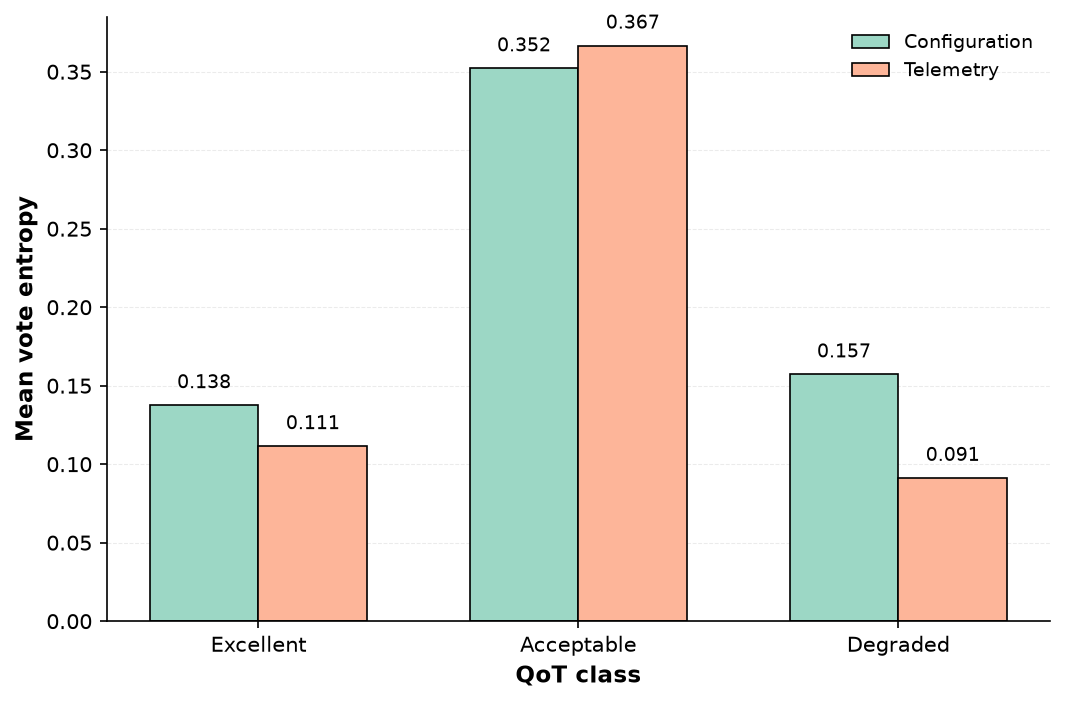

In [411]:
plot_class_vote_entropy(
    campaign="PRBS_NRZ",
    data=class_agreement_summary,
    filename="agreement_entropy_prbs"
)

Saved: figures\agreement_entropy_lte.pdf


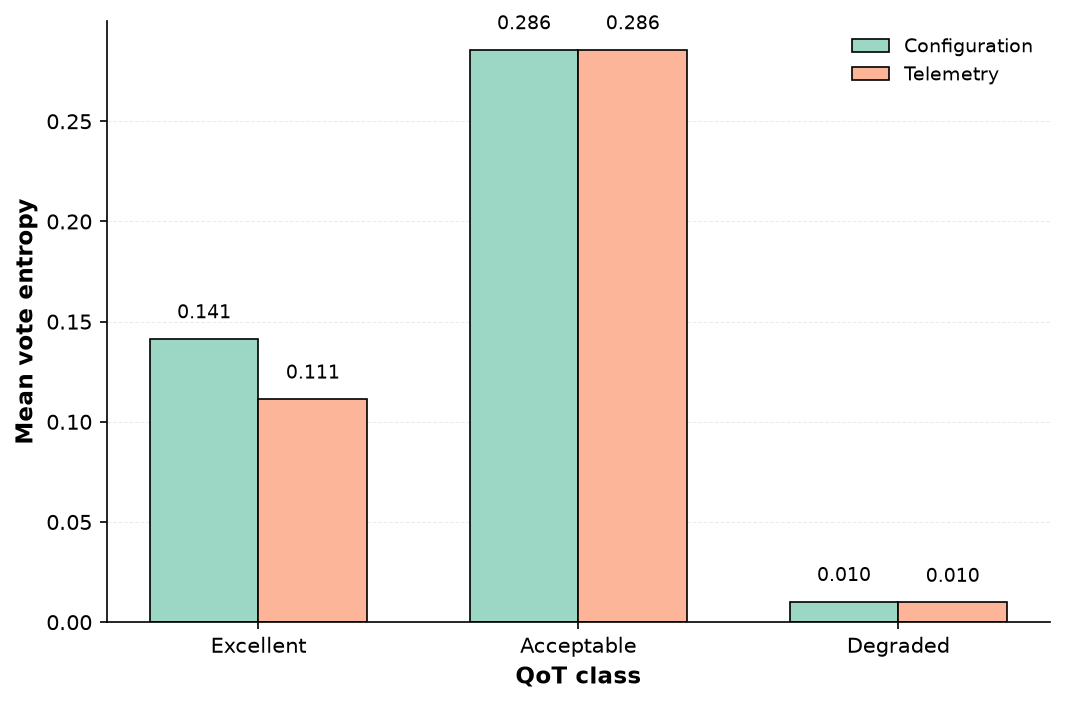

In [412]:
plot_class_vote_entropy(
    campaign="LTE_QPSK",
    data=class_agreement_summary,
    filename="agreement_entropy_lte"
)

In [413]:
# Step 16 — Export Activity 18 tables

activity18_tables = {

    "table_pairwise_model_agreement.csv":
        pairwise_agreement_table,

    "table_pairwise_agreement_summary.csv":
        pairwise_agreement_summary,

    "table_overall_model_agreement.csv":
        overall_agreement_summary,

    "table_class_model_agreement.csv":
        class_agreement_summary,

    "table_vote_pattern_distribution.csv":
        vote_pattern_distribution,

    "table_vote_patterns_by_class.csv":
        vote_pattern_by_class,

    "table_acceptable_vote_patterns.csv":
        acceptable_vote_patterns,

    "table_agreement_scenario_change.csv":
        agreement_change_summary,

    "table_class_agreement_change.csv":
        class_agreement_change
}


for filename, table in activity18_tables.items():

    table.to_csv(
        TABLES_DIR / filename,
        index=False
    )

    print(
        "Saved:",
        TABLES_DIR / filename
    )

Saved: tables\table_pairwise_model_agreement.csv
Saved: tables\table_pairwise_agreement_summary.csv
Saved: tables\table_overall_model_agreement.csv
Saved: tables\table_class_model_agreement.csv
Saved: tables\table_vote_pattern_distribution.csv
Saved: tables\table_vote_patterns_by_class.csv
Saved: tables\table_acceptable_vote_patterns.csv
Saved: tables\table_agreement_scenario_change.csv
Saved: tables\table_class_agreement_change.csv


In [414]:
# Step 17 — Validate Activity 18

activity18_checks = {

    "2450 campaign-scenario Test samples available":
        len(prediction_wide) == 2450,

    "Twenty-four pairwise model comparisons available":
        len(pairwise_agreement_table) == 24,

    "Four overall agreement summaries available":
        len(overall_agreement_summary) == 4,

    "Twelve class-specific agreement summaries available":
        len(class_agreement_summary) == 12,

    "All samples include four model predictions":
        prediction_wide[
            MODEL_ORDER
        ].notna().all().all(),

    "Vote entropy values are finite":
        np.isfinite(
            prediction_agreement_table[
                "Vote entropy"
            ]
        ).all(),

    "Consensus strength within valid range":
        prediction_agreement_table[
            "Consensus strength"
        ].between(
            0.25,
            1.00
        ).all(),

    "No model retraining performed":
        True,

    "No Test-driven model selection performed":
        True
}


activity18_summary = pd.DataFrame(
    activity18_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity18_summary
)

,Validation,Passed
0,2450 campaign-scenario Test samples available,True
1,Twenty-four pairwise model comparisons available,True
2,Four overall agreement summaries available,True
3,Twelve class-specific agreement summaries avai...,True
4,All samples include four model predictions,True
5,Vote entropy values are finite,True
6,Consensus strength within valid range,True
7,No model retraining performed,True
8,No Test-driven model selection performed,True


In [415]:
# Step 18 — Final decision for Activity 18

activity18_passed = (
    activity18_summary[
        "Passed"
    ].all()
)

if activity18_passed:

    print("=" * 70)
    print("ACTIVITY 18 — PASSED")
    print("=" * 70)

    print(
        "Cross-model agreement and prediction disagreement were "
        "successfully characterized on the frozen independent Test set."
    )

    print(
        "LTE-QPSK exhibited very high agreement across classifiers, "
        "whereas PRBS-NRZ showed substantially greater model disagreement."
    )

    print(
        "The Acceptable QoT class was identified as the principal "
        "region of classifier disagreement."
    )

    print(
        "Receiver-side telemetry increased overall PRBS-NRZ agreement "
        "primarily through the Degraded and Excellent classes, while "
        "Acceptable remained ambiguous."
    )

    print(
        "No model retraining or Test-driven model selection was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 18 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity18_summary[
            ~activity18_summary["Passed"]
        ]
    )

ACTIVITY 18 — PASSED
Cross-model agreement and prediction disagreement were successfully characterized on the frozen independent Test set.
LTE-QPSK exhibited very high agreement across classifiers, whereas PRBS-NRZ showed substantially greater model disagreement.
The Acceptable QoT class was identified as the principal region of classifier disagreement.
Receiver-side telemetry increased overall PRBS-NRZ agreement primarily through the Degraded and Excellent classes, while Acceptable remained ambiguous.
No model retraining or Test-driven model selection was performed.


In [416]:
# Save Activity 18 checkpoint

activity18_checkpoint = {
    "prediction_wide": prediction_wide,
    "pairwise_agreement_table": pairwise_agreement_table,
    "pairwise_agreement_summary": pairwise_agreement_summary,
    "prediction_agreement_table": prediction_agreement_table,
    "overall_agreement_summary": overall_agreement_summary,
    "class_agreement_summary": class_agreement_summary,
    "vote_pattern_distribution": vote_pattern_distribution,
    "vote_pattern_by_class": vote_pattern_by_class,
    "acceptable_vote_patterns": acceptable_vote_patterns,
    "agreement_change_summary": agreement_change_summary,
    "class_agreement_change": class_agreement_change,
    "activity18_summary": activity18_summary
}

activity18_checkpoint_path = (
    ARTIFACTS_DIR / "activity18_complete.joblib"
)

joblib.dump(
    activity18_checkpoint,
    activity18_checkpoint_path,
    compress=3
)

print("Saved:", activity18_checkpoint_path)
print("Exists:", activity18_checkpoint_path.exists())

Saved: artifacts\activity18_complete.joblib
Exists: True


# Activity 19 — Statistical Pairwise Model Comparison

## Objective

The objective of this activity is to quantify the uncertainty associated with
pairwise differences in Macro-F1 among the four optimized classifiers.

All comparisons are performed using the frozen predictions obtained from the
independent Test partition.

Experimental groups are used as the bootstrap resampling unit in order to
preserve the dependence structure among observations generated under the same
experimental condition.

For each campaign and predictor scenario, all six classifier pairs are
compared using a paired group-level bootstrap.

The analysis reports:

- observed Macro-F1 for each classifier;
- observed pairwise Macro-F1 difference;
- bootstrap mean difference;
- 95% group-bootstrap confidence interval;
- number of valid bootstrap replicates.

This analysis is post-hoc and is not used for model selection, retraining, or
hyperparameter optimization.

In [417]:
# Step 2 — Verify objects required for Activity 19

required_objects_activity19 = [
    "prediction_wide",
    "MODEL_ORDER",
    "CLASS_ORDER"
]

for obj in required_objects_activity19:

    print(
        f"{obj}:",
        "OK" if obj in globals() else "MISSING"
    )

prediction_wide: OK
MODEL_ORDER: OK
CLASS_ORDER: OK


In [418]:
# Step 3 — Paired experimental-group bootstrap for model comparison

from sklearn.metrics import f1_score


def paired_group_bootstrap_models(
    data,
    model_a,
    model_b,
    n_bootstrap=2000,
    random_state=42
):

    data = data.reset_index(drop=True).copy()

    y_true = data[
        "True class"
    ].to_numpy()

    pred_a = data[
        model_a
    ].to_numpy()

    pred_b = data[
        model_b
    ].to_numpy()

    groups = data[
        "Group"
    ].to_numpy()

    unique_groups = pd.unique(
        groups
    )

    # Store row indices belonging to each experimental group
    group_indices = {
        group: np.flatnonzero(
            groups == group
        )
        for group in unique_groups
    }

    # Observed Test Macro-F1
    observed_a = f1_score(
        y_true,
        pred_a,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    observed_b = f1_score(
        y_true,
        pred_b,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    observed_delta = (
        observed_a
        -
        observed_b
    )

    rng = np.random.default_rng(
        random_state
    )

    bootstrap_deltas = []

    for _ in range(
        n_bootstrap
    ):

        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True
        )

        bootstrap_indices = np.concatenate(
            [
                group_indices[group]
                for group in sampled_groups
            ]
        )

        y_boot = y_true[
            bootstrap_indices
        ]

        # Require all QoT classes
        if not set(
            CLASS_ORDER
        ).issubset(
            set(
                np.unique(
                    y_boot
                )
            )
        ):
            continue

        pred_a_boot = pred_a[
            bootstrap_indices
        ]

        pred_b_boot = pred_b[
            bootstrap_indices
        ]

        macro_a = f1_score(
            y_boot,
            pred_a_boot,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        macro_b = f1_score(
            y_boot,
            pred_b_boot,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        bootstrap_deltas.append(
            macro_a - macro_b
        )

    bootstrap_deltas = np.asarray(
        bootstrap_deltas
    )

    if len(
        bootstrap_deltas
    ) == 0:

        raise RuntimeError(
            "No valid bootstrap replicates were generated."
        )

    ci_lower, ci_upper = np.percentile(
        bootstrap_deltas,
        [
            2.5,
            97.5
        ]
    )

    return {

        "Model A":
            model_a,

        "Model B":
            model_b,

        "Observed Macro-F1 A":
            observed_a,

        "Observed Macro-F1 B":
            observed_b,

        "Observed Delta Macro-F1":
            observed_delta,

        "Bootstrap Mean Delta":
            bootstrap_deltas.mean(),

        "CI lower":
            ci_lower,

        "CI upper":
            ci_upper,

        "Valid bootstrap replicates":
            len(
                bootstrap_deltas
            ),

        "Requested bootstrap replicates":
            n_bootstrap
    }

In [419]:
# Step 4 — PRBS-NRZ Configuration-based pairwise comparisons

from itertools import combinations


prbs_config_predictions = (
    prediction_wide[
        (prediction_wide["Campaign"] == "PRBS_NRZ")
        &
        (
            prediction_wide["Scenario"]
            ==
            "Configuration-based"
        )
    ]
    .copy()
    .reset_index(drop=True)
)


prbs_config_pairwise_results = []

for model_a, model_b in combinations(
    MODEL_ORDER,
    2
):

    result = paired_group_bootstrap_models(
        data=prbs_config_predictions,
        model_a=model_a,
        model_b=model_b,
        n_bootstrap=2000,
        random_state=42
    )

    result[
        "Campaign"
    ] = "PRBS_NRZ"

    result[
        "Scenario"
    ] = "Configuration-based"

    prbs_config_pairwise_results.append(
        result
    )


prbs_config_model_comparison = pd.DataFrame(
    prbs_config_pairwise_results
)

In [420]:
display(
    prbs_config_model_comparison[
        [
            "Model A",
            "Model B",
            "Observed Macro-F1 A",
            "Observed Macro-F1 B",
            "Observed Delta Macro-F1",
            "Bootstrap Mean Delta",
            "CI lower",
            "CI upper",
            "Valid bootstrap replicates"
        ]
    ].round(4)
)

,Model A,Model B,Observed Macro-F1 A,Observed Macro-F1 B,Observed Delta Macro-F1,Bootstrap Mean Delta,CI lower,CI upper,Valid bootstrap replicates
0,Gradient Boosting,MLP,0.7769,0.7768,0.0001,-0.0037,-0.0724,0.0514,2000
1,Gradient Boosting,Random Forest,0.7769,0.7702,0.0067,0.0056,-0.0292,0.0354,2000
2,Gradient Boosting,SVM,0.7769,0.6408,0.1361,0.1306,0.0698,0.1759,2000
3,MLP,Random Forest,0.7768,0.7702,0.0066,0.0093,-0.0368,0.0643,2000
4,MLP,SVM,0.7768,0.6408,0.1360,0.1343,0.0811,0.1781,2000
5,Random Forest,SVM,0.7702,0.6408,0.1294,0.1250,0.0735,0.1670,2000


In [421]:
# Step 5 — Interpret pairwise confidence intervals

def classify_pairwise_ci(row):

    if row["CI lower"] > 0:

        return "A > B (CI excludes 0)"

    elif row["CI upper"] < 0:

        return "A < B (CI excludes 0)"

    else:

        return "CI includes 0"


prbs_config_model_comparison[
    "CI interpretation"
] = (
    prbs_config_model_comparison
    .apply(
        classify_pairwise_ci,
        axis=1
    )
)


display(
    prbs_config_model_comparison[
        [
            "Model A",
            "Model B",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper",
            "CI interpretation"
        ]
    ].round(4)
)

,Model A,Model B,Observed Delta Macro-F1,CI lower,CI upper,CI interpretation
0,Gradient Boosting,MLP,0.0001,-0.0724,0.0514,CI includes 0
1,Gradient Boosting,Random Forest,0.0067,-0.0292,0.0354,CI includes 0
2,Gradient Boosting,SVM,0.1361,0.0698,0.1759,A > B (CI excludes 0)
3,MLP,Random Forest,0.0066,-0.0368,0.0643,CI includes 0
4,MLP,SVM,0.1360,0.0811,0.1781,A > B (CI excludes 0)
5,Random Forest,SVM,0.1294,0.0735,0.1670,A > B (CI excludes 0)


In [422]:
prbs_config_model_comparison[
    [
        "Model A",
        "Model B",
        "Observed Delta Macro-F1",
        "CI lower",
        "CI upper",
        "CI interpretation"
    ]
]

,Model A,Model B,Observed Delta Macro-F1,CI lower,CI upper,CI interpretation
0,Gradient Boosting,MLP,0.000104,-0.072382,0.051366,CI includes 0
1,Gradient Boosting,Random Forest,0.006682,-0.029217,0.035434,CI includes 0
2,Gradient Boosting,SVM,0.136101,0.069831,0.175894,A > B (CI excludes 0)
3,MLP,Random Forest,0.006577,-0.036848,0.064299,CI includes 0
4,MLP,SVM,0.135997,0.081089,0.178131,A > B (CI excludes 0)
5,Random Forest,SVM,0.129419,0.073488,0.166993,A > B (CI excludes 0)


### Initial pairwise comparison: PRBS-NRZ Configuration-based

The paired experimental-group bootstrap reveals two distinct patterns.

The pairwise Macro-F1 differences among Gradient Boosting, MLP, and Random
Forest are small, and their 95% bootstrap confidence intervals include zero.
Therefore, the frozen Test predictions do not provide clear evidence of a
stable separation among these three classifiers under experimental-group
resampling.

In contrast, the pairwise differences between each of these classifiers and
SVM are substantially larger, and the corresponding bootstrap confidence
intervals remain entirely above zero.

This indicates that the observed Macro-F1 separation from SVM is robust to
resampling of the experimental groups.

Because multiple post-hoc pairwise comparisons are evaluated, confidence
intervals are interpreted descriptively as measures of stability rather than
as a formal multiple-hypothesis-testing procedure.

In [423]:
# Step 6 — Run pairwise bootstrap comparisons for the remaining conditions

remaining_conditions = [
    ("PRBS_NRZ", "Telemetry-assisted"),
    ("LTE_QPSK", "Configuration-based"),
    ("LTE_QPSK", "Telemetry-assisted")
]

remaining_pairwise_results = []

for campaign, scenario in remaining_conditions:

    subset = (
        prediction_wide[
            (prediction_wide["Campaign"] == campaign)
            &
            (prediction_wide["Scenario"] == scenario)
        ]
        .copy()
        .reset_index(drop=True)
    )

    print(
        f"Running: {campaign} | {scenario}"
    )

    for model_a, model_b in combinations(
        MODEL_ORDER,
        2
    ):

        result = paired_group_bootstrap_models(
            data=subset,
            model_a=model_a,
            model_b=model_b,
            n_bootstrap=2000,
            random_state=42
        )

        result["Campaign"] = campaign
        result["Scenario"] = scenario

        remaining_pairwise_results.append(
            result
        )

print(
    "Remaining comparisons:",
    len(remaining_pairwise_results)
)

Running: PRBS_NRZ | Telemetry-assisted
Running: LTE_QPSK | Configuration-based
Running: LTE_QPSK | Telemetry-assisted
Remaining comparisons: 18


In [424]:
# Step 7 — Combine all pairwise model comparisons

remaining_pairwise_table = pd.DataFrame(
    remaining_pairwise_results
)

pairwise_model_bootstrap = pd.concat(
    [
        prbs_config_model_comparison,
        remaining_pairwise_table
    ],
    ignore_index=True
)

pairwise_model_bootstrap[
    "CI interpretation"
] = (
    pairwise_model_bootstrap
    .apply(
        classify_pairwise_ci,
        axis=1
    )
)

print(
    "Total pairwise comparisons:",
    len(pairwise_model_bootstrap)
)

display(
    pairwise_model_bootstrap[
        [
            "Campaign",
            "Scenario",
            "Model A",
            "Model B",
            "Observed Delta Macro-F1",
            "Bootstrap Mean Delta",
            "CI lower",
            "CI upper",
            "CI interpretation"
        ]
    ].round(4)
)

Total pairwise comparisons: 24


,Campaign,Scenario,Model A,Model B,Observed Delta Macro-F1,Bootstrap Mean Delta,CI lower,CI upper,CI interpretation
0,PRBS_NRZ,Configuration-based,Gradient Boosting,MLP,0.0001,-0.0037,-0.0724,0.0514,CI includes 0
1,PRBS_NRZ,Configuration-based,Gradient Boosting,Random Forest,0.0067,0.0056,-0.0292,0.0354,CI includes 0
2,PRBS_NRZ,Configuration-based,Gradient Boosting,SVM,0.1361,0.1306,0.0698,0.1759,A > B (CI excludes 0)
3,PRBS_NRZ,Configuration-based,MLP,Random Forest,0.0066,0.0093,-0.0368,0.0643,CI includes 0
4,PRBS_NRZ,Configuration-based,MLP,SVM,0.1360,0.1343,0.0811,0.1781,A > B (CI excludes 0)
5,PRBS_NRZ,Configuration-based,Random Forest,SVM,0.1294,0.1250,0.0735,0.1670,A > B (CI excludes 0)
6,PRBS_NRZ,Telemetry-assisted,Gradient Boosting,MLP,-0.0430,-0.0426,-0.0961,0.0106,CI includes 0
7,PRBS_NRZ,Telemetry-assisted,Gradient Boosting,Random Forest,-0.0360,-0.0349,-0.0558,-0.0100,A < B (CI excludes 0)
8,PRBS_NRZ,Telemetry-assisted,Gradient Boosting,SVM,0.0379,0.0366,-0.0237,0.1000,CI includes 0
9,PRBS_NRZ,Telemetry-assisted,MLP,Random Forest,0.0070,0.0077,-0.0329,0.0525,CI includes 0


In [425]:
# Step 8 — Summarize bootstrap CI outcomes

pairwise_ci_summary = (
    pairwise_model_bootstrap
    .groupby(
        [
            "Campaign",
            "Scenario",
            "CI interpretation"
        ]
    )
    .size()
    .rename("Comparisons")
    .reset_index()
)

display(
    pairwise_ci_summary
)

,Campaign,Scenario,CI interpretation,Comparisons
0,LTE_QPSK,Configuration-based,CI includes 0,6
1,LTE_QPSK,Telemetry-assisted,CI includes 0,6
2,PRBS_NRZ,Configuration-based,A > B (CI excludes 0),3
3,PRBS_NRZ,Configuration-based,CI includes 0,3
4,PRBS_NRZ,Telemetry-assisted,A < B (CI excludes 0),1
5,PRBS_NRZ,Telemetry-assisted,A > B (CI excludes 0),2
6,PRBS_NRZ,Telemetry-assisted,CI includes 0,3


In [426]:
# Number of pairwise comparisons with and without clear separation

pairwise_separation_summary = (
    pairwise_model_bootstrap
    .assign(
        CI_excludes_zero=lambda df:
            (
                (df["CI lower"] > 0)
                |
                (df["CI upper"] < 0)
            )
    )
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .agg(
        Total_comparisons=(
            "CI_excludes_zero",
            "size"
        ),

        CI_excludes_zero=(
            "CI_excludes_zero",
            "sum"
        )
    )
    .reset_index()
)

pairwise_separation_summary[
    "CI_includes_zero"
] = (
    pairwise_separation_summary[
        "Total_comparisons"
    ]
    -
    pairwise_separation_summary[
        "CI_excludes_zero"
    ]
)

display(
    pairwise_separation_summary
)

,Campaign,Scenario,Total_comparisons,CI_excludes_zero,CI_includes_zero
0,LTE_QPSK,Configuration-based,6,0,6
1,LTE_QPSK,Telemetry-assisted,6,0,6
2,PRBS_NRZ,Configuration-based,6,3,3
3,PRBS_NRZ,Telemetry-assisted,6,3,3


In [427]:
# Step 9 — Add compact pair labels

MODEL_SHORT = {
    "Gradient Boosting": "GB",
    "MLP": "MLP",
    "Random Forest": "RF",
    "SVM": "SVM"
}

pairwise_model_bootstrap[
    "Pair"
] = (
    pairwise_model_bootstrap[
        "Model A"
    ].map(MODEL_SHORT)
    +
    " - "
    +
    pairwise_model_bootstrap[
        "Model B"
    ].map(MODEL_SHORT)
)

display(
    pairwise_model_bootstrap[
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper"
        ]
    ].head()
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper
0,PRBS_NRZ,Configuration-based,GB - MLP,0.000104,-0.072382,0.051366
1,PRBS_NRZ,Configuration-based,GB - RF,0.006682,-0.029217,0.035434
2,PRBS_NRZ,Configuration-based,GB - SVM,0.136101,0.069831,0.175894
3,PRBS_NRZ,Configuration-based,MLP - RF,0.006577,-0.036848,0.064299
4,PRBS_NRZ,Configuration-based,MLP - SVM,0.135997,0.081089,0.178131


In [428]:
# Step 10 — Pairwise Macro-F1 difference plot

def plot_pairwise_model_differences(
    campaign,
    scenario,
    data,
    filename=None
):

    plot_data = (
        data[
            (data["Campaign"] == campaign)
            &
            (data["Scenario"] == scenario)
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Sort by observed difference
    plot_data = (
        plot_data
        .sort_values(
            "Observed Delta Macro-F1"
        )
        .reset_index(drop=True)
    )

    y = np.arange(
        len(plot_data)
    )

    observed = (
        plot_data[
            "Observed Delta Macro-F1"
        ].to_numpy()
    )

    lower_error = (
        observed
        -
        plot_data[
            "CI lower"
        ].to_numpy()
    )

    upper_error = (
        plot_data[
            "CI upper"
        ].to_numpy()
        -
        observed
    )

    fig, ax = plt.subplots(
        figsize=(7.2, 4.8),
        dpi=150
    )

    ax.errorbar(
        observed,
        y,
        xerr=[
            lower_error,
            upper_error
        ],
        fmt="o",
        markersize=7,
        color=SET2_PASTEL[0],
        markerfacecolor=SET2_PASTEL[0],
        markeredgecolor="black",
        markeredgewidth=0.8,
        ecolor="black",
        elinewidth=0.9,
        capsize=4,
        capthick=0.8
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.9,
        linestyle="--"
    )

    ax.set_yticks(y)

    ax.set_yticklabels(
        plot_data["Pair"],
        fontsize=10
    )

    ax.set_xlabel(
        r"$\Delta$ Macro-F1 (Model A - Model B)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Model pair",
        fontsize=11,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    plt.tight_layout()

    if filename is not None:

        output_path = (
            FIGURES_DIR
            /
            f"{filename}.pdf"
        )

        plt.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight"
        )

        print(
            "Saved:",
            output_path
        )

    plt.show()

Saved: figures\pairwise_models_prbs_config.pdf


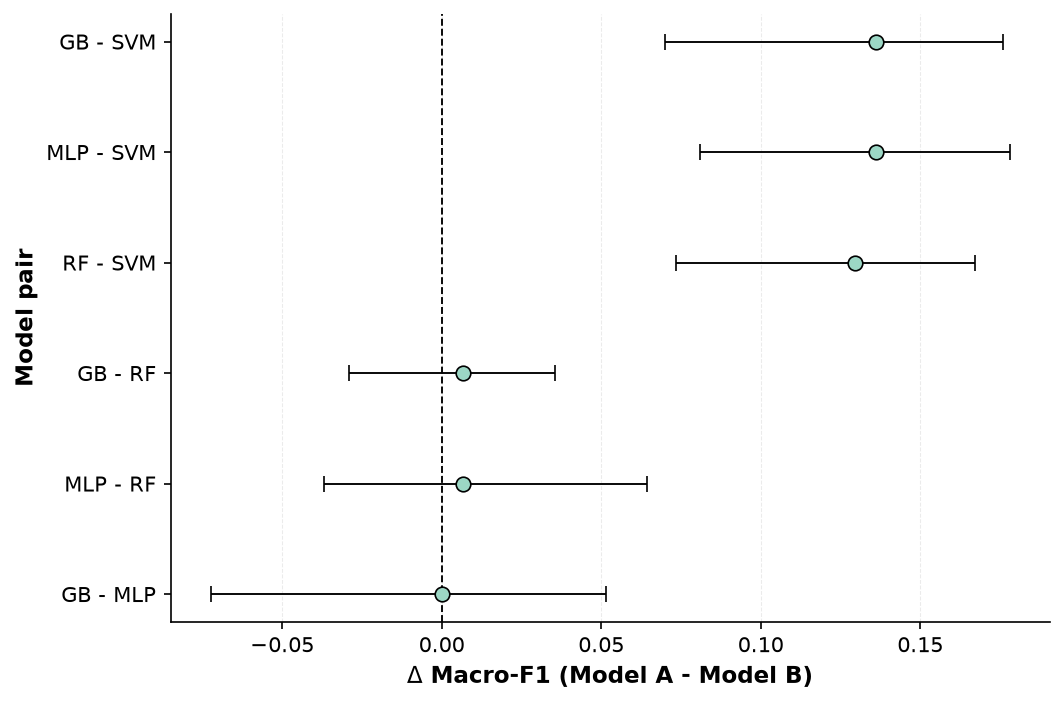

Saved: figures\pairwise_models_prbs_telemetry.pdf


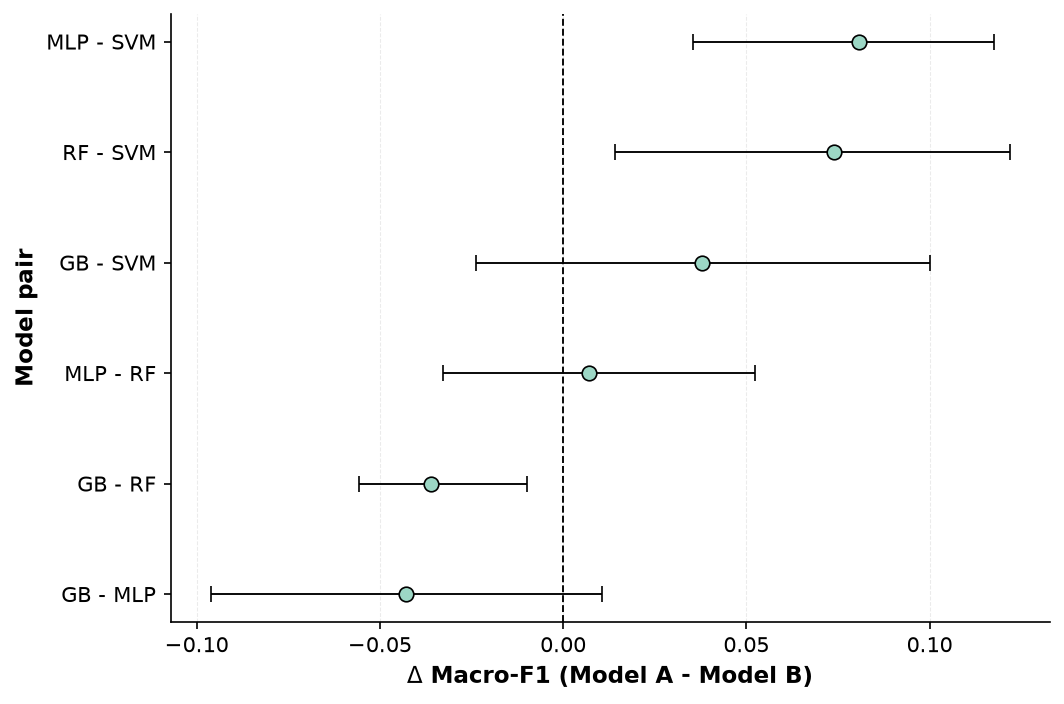

Saved: figures\pairwise_models_lte_config.pdf


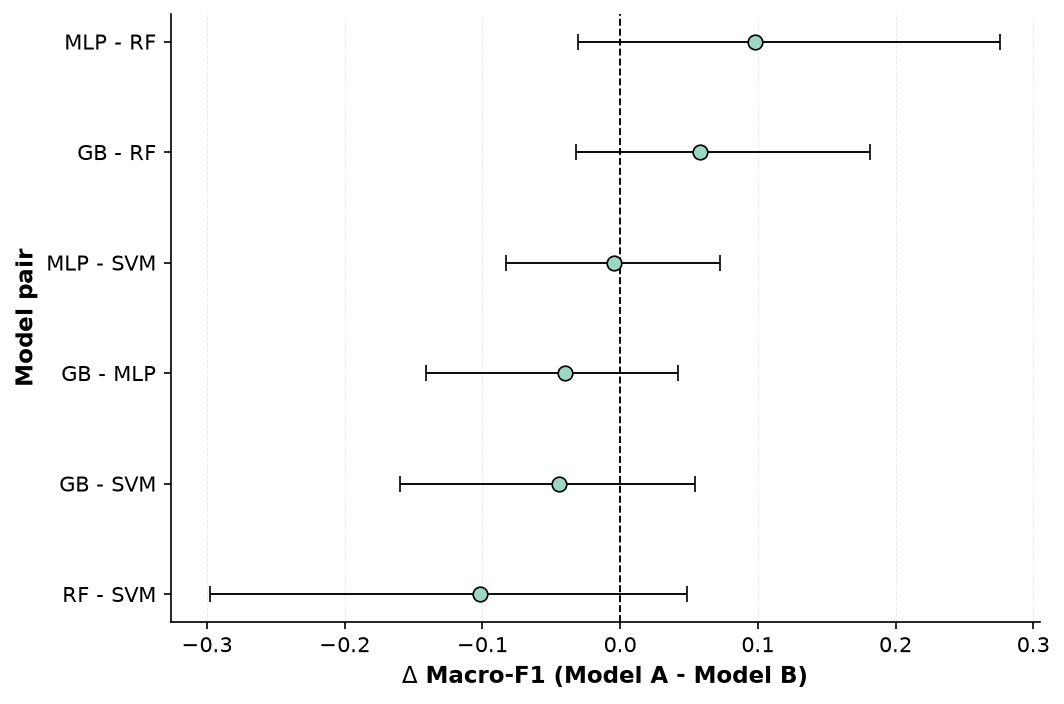

Saved: figures\pairwise_models_lte_telemetry.pdf


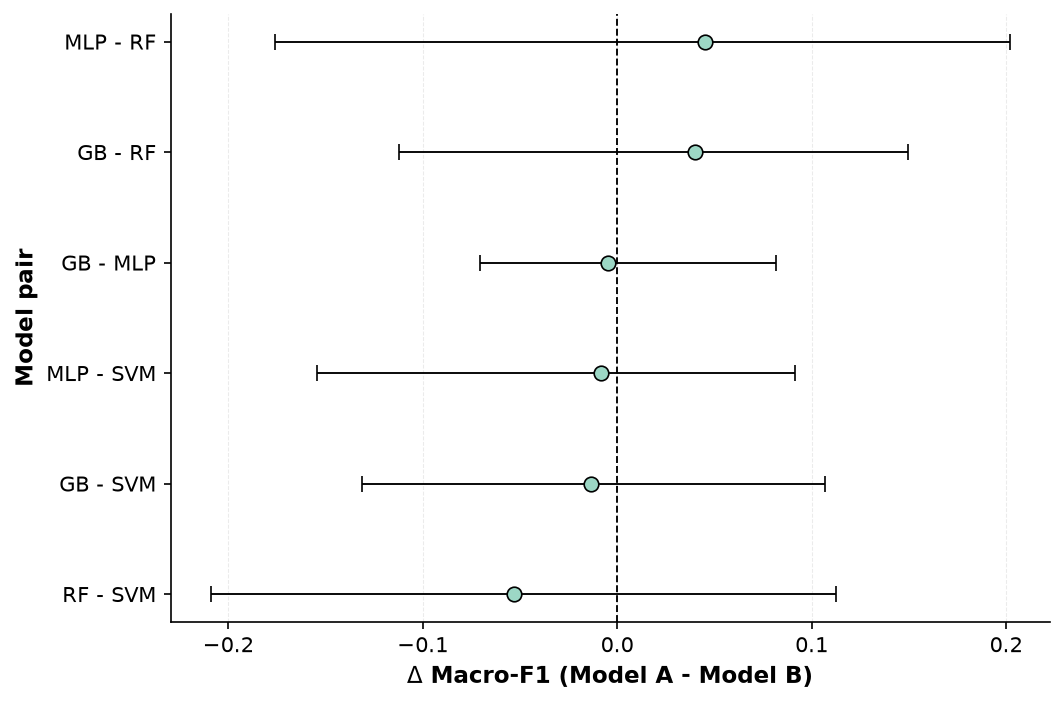

In [429]:
plot_pairwise_model_differences(
    campaign="PRBS_NRZ",
    scenario="Configuration-based",
    data=pairwise_model_bootstrap,
    filename="pairwise_models_prbs_config"
)

plot_pairwise_model_differences(
    campaign="PRBS_NRZ",
    scenario="Telemetry-assisted",
    data=pairwise_model_bootstrap,
    filename="pairwise_models_prbs_telemetry"
)

plot_pairwise_model_differences(
    campaign="LTE_QPSK",
    scenario="Configuration-based",
    data=pairwise_model_bootstrap,
    filename="pairwise_models_lte_config"
)

plot_pairwise_model_differences(
    campaign="LTE_QPSK",
    scenario="Telemetry-assisted",
    data=pairwise_model_bootstrap,
    filename="pairwise_models_lte_telemetry"
)

In [430]:
# Step 11 — Export Activity 19 results

activity19_tables = {

    "table_pairwise_model_bootstrap.csv":
        pairwise_model_bootstrap,

    "table_pairwise_ci_summary.csv":
        pairwise_ci_summary,

    "table_pairwise_separation_summary.csv":
        pairwise_separation_summary
}


for filename, table in activity19_tables.items():

    table.to_csv(
        TABLES_DIR / filename,
        index=False
    )

    print(
        "Saved:",
        TABLES_DIR / filename
    )

Saved: tables\table_pairwise_model_bootstrap.csv
Saved: tables\table_pairwise_ci_summary.csv
Saved: tables\table_pairwise_separation_summary.csv


In [431]:
# Step 12 — Validate Activity 19

activity19_checks = {

    "Twenty-four pairwise comparisons available":
        len(pairwise_model_bootstrap) == 24,

    "Six comparisons per campaign-scenario":
        (
            pairwise_model_bootstrap
            .groupby(
                [
                    "Campaign",
                    "Scenario"
                ]
            )
            .size()
            .eq(6)
            .all()
        ),

    "Observed Macro-F1 differences available":
        pairwise_model_bootstrap[
            "Observed Delta Macro-F1"
        ].notna().all(),

    "Bootstrap confidence intervals available":
        pairwise_model_bootstrap[
            [
                "CI lower",
                "CI upper"
            ]
        ].notna().all().all(),

    "All confidence intervals correctly ordered":
        (
            pairwise_model_bootstrap[
                "CI lower"
            ]
            <=
            pairwise_model_bootstrap[
                "CI upper"
            ]
        ).all(),

    "Bootstrap replicates available":
        (
            pairwise_model_bootstrap[
                "Valid bootstrap replicates"
            ] > 0
        ).all(),

    "No model retraining performed":
        True,

    "No hyperparameter optimization performed":
        True,

    "Frozen Test predictions preserved":
        True
}


activity19_summary = pd.DataFrame(
    activity19_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity19_summary
)

,Validation,Passed
0,Twenty-four pairwise comparisons available,True
1,Six comparisons per campaign-scenario,True
2,Observed Macro-F1 differences available,True
3,Bootstrap confidence intervals available,True
4,All confidence intervals correctly ordered,True
5,Bootstrap replicates available,True
6,No model retraining performed,True
7,No hyperparameter optimization performed,True
8,Frozen Test predictions preserved,True


In [432]:
display(
    pairwise_model_bootstrap[
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper",
            "CI interpretation"
        ]
    ].round(4)
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper,CI interpretation
0,PRBS_NRZ,Configuration-based,GB - MLP,0.0001,-0.0724,0.0514,CI includes 0
1,PRBS_NRZ,Configuration-based,GB - RF,0.0067,-0.0292,0.0354,CI includes 0
2,PRBS_NRZ,Configuration-based,GB - SVM,0.1361,0.0698,0.1759,A > B (CI excludes 0)
3,PRBS_NRZ,Configuration-based,MLP - RF,0.0066,-0.0368,0.0643,CI includes 0
4,PRBS_NRZ,Configuration-based,MLP - SVM,0.1360,0.0811,0.1781,A > B (CI excludes 0)
5,PRBS_NRZ,Configuration-based,RF - SVM,0.1294,0.0735,0.1670,A > B (CI excludes 0)
6,PRBS_NRZ,Telemetry-assisted,GB - MLP,-0.0430,-0.0961,0.0106,CI includes 0
7,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.0360,-0.0558,-0.0100,A < B (CI excludes 0)
8,PRBS_NRZ,Telemetry-assisted,GB - SVM,0.0379,-0.0237,0.1000,CI includes 0
9,PRBS_NRZ,Telemetry-assisted,MLP - RF,0.0070,-0.0329,0.0525,CI includes 0


### Pairwise model-comparison interpretation

Paired experimental-group bootstrap analysis reveals substantial differences
between the PRBS-NRZ and LTE-QPSK campaigns.

For PRBS-NRZ Configuration-based classification, the Macro-F1 differences
among Gradient Boosting, MLP, and Random Forest are small, and their 95%
bootstrap confidence intervals include zero. In contrast, the comparisons of
each of these models with SVM yield confidence intervals entirely above zero.

For PRBS-NRZ Telemetry-assisted classification, Random Forest exhibits a
positive Macro-F1 separation relative to Gradient Boosting under group
resampling. MLP and Random Forest also maintain positive differences relative
to SVM, whereas the Gradient Boosting–SVM confidence interval includes zero.

A different pattern is observed for LTE-QPSK. All pairwise confidence
intervals include zero in both predictor scenarios. Thus, although point
estimates differ among classifiers, the available independent-Test groups do
not provide a clear pairwise separation among the evaluated algorithms under
group-bootstrap resampling.

The wider LTE-QPSK uncertainty should be interpreted in the context of its
small minority-class Test supports, particularly the Acceptable and Excellent
classes.

These post-hoc confidence intervals are used to characterize the stability of
observed performance differences and are not interpreted as a formal
multiple-hypothesis-testing procedure.

In [2]:
# Restart setup — Activity 19

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from itertools import combinations

from sklearn.metrics import f1_score

ARTIFACTS_DIR = Path("artifacts")
TABLES_DIR = Path("tables")
FIGURES_DIR = Path("figures")

TABLES_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("Environment ready.")

Environment ready.


In [3]:
# Load Activity 18 checkpoint

activity18_checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity18_complete.joblib"
)

activity18_checkpoint = joblib.load(
    activity18_checkpoint_path
)

globals().update(
    activity18_checkpoint
)

print(
    "Loaded:",
    activity18_checkpoint_path
)

print(
    "prediction_wide:",
    prediction_wide.shape
)

Loaded: artifacts\activity18_complete.joblib
prediction_wide: (2450, 9)


In [4]:
# Restore model and class order

MODEL_ORDER = [
    "Gradient Boosting",
    "MLP",
    "Random Forest",
    "SVM"
]

CLASS_ORDER = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

print("MODEL_ORDER:", MODEL_ORDER)
print("CLASS_ORDER:", CLASS_ORDER)

MODEL_ORDER: ['Gradient Boosting', 'MLP', 'Random Forest', 'SVM']
CLASS_ORDER: ['Excellent', 'Acceptable', 'Degraded']


In [5]:
# Paired experimental-group bootstrap for model comparison

def paired_group_bootstrap_models(
    data,
    model_a,
    model_b,
    n_bootstrap=2000,
    random_state=42
):

    data = data.reset_index(drop=True).copy()

    y_true = data[
        "True class"
    ].to_numpy()

    pred_a = data[
        model_a
    ].to_numpy()

    pred_b = data[
        model_b
    ].to_numpy()

    groups = data[
        "Group"
    ].to_numpy()

    unique_groups = pd.unique(
        groups
    )

    group_indices = {
        group: np.flatnonzero(
            groups == group
        )
        for group in unique_groups
    }

    observed_a = f1_score(
        y_true,
        pred_a,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    observed_b = f1_score(
        y_true,
        pred_b,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    observed_delta = (
        observed_a
        -
        observed_b
    )

    rng = np.random.default_rng(
        random_state
    )

    bootstrap_deltas = []

    for _ in range(
        n_bootstrap
    ):

        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True
        )

        bootstrap_indices = np.concatenate(
            [
                group_indices[group]
                for group in sampled_groups
            ]
        )

        y_boot = y_true[
            bootstrap_indices
        ]

        if not set(
            CLASS_ORDER
        ).issubset(
            set(
                np.unique(
                    y_boot
                )
            )
        ):
            continue

        pred_a_boot = pred_a[
            bootstrap_indices
        ]

        pred_b_boot = pred_b[
            bootstrap_indices
        ]

        macro_a = f1_score(
            y_boot,
            pred_a_boot,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        macro_b = f1_score(
            y_boot,
            pred_b_boot,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        bootstrap_deltas.append(
            macro_a - macro_b
        )

    bootstrap_deltas = np.asarray(
        bootstrap_deltas
    )

    ci_lower, ci_upper = np.percentile(
        bootstrap_deltas,
        [
            2.5,
            97.5
        ]
    )

    return {

        "Model A":
            model_a,

        "Model B":
            model_b,

        "Observed Macro-F1 A":
            observed_a,

        "Observed Macro-F1 B":
            observed_b,

        "Observed Delta Macro-F1":
            observed_delta,

        "Bootstrap Mean Delta":
            bootstrap_deltas.mean(),

        "CI lower":
            ci_lower,

        "CI upper":
            ci_upper,

        "Valid bootstrap replicates":
            len(
                bootstrap_deltas
            ),

        "Requested bootstrap replicates":
            n_bootstrap
    }

In [7]:
# Restore CI interpretation function

def classify_pairwise_ci(row):

    if row["CI lower"] > 0:
        return "A > B (CI excludes 0)"

    elif row["CI upper"] < 0:
        return "A < B (CI excludes 0)"

    else:
        return "CI includes 0"

In [8]:
# Add CI interpretation

pairwise_model_bootstrap[
    "CI interpretation"
] = (
    pairwise_model_bootstrap
    .apply(
        classify_pairwise_ci,
        axis=1
    )
)

print(
    "Total pairwise comparisons:",
    len(pairwise_model_bootstrap)
)

Total pairwise comparisons: 24


In [9]:
MODEL_SHORT = {
    "Gradient Boosting": "GB",
    "MLP": "MLP",
    "Random Forest": "RF",
    "SVM": "SVM"
}

pairwise_model_bootstrap[
    "Pair"
] = (
    pairwise_model_bootstrap["Model A"].map(MODEL_SHORT)
    +
    " - "
    +
    pairwise_model_bootstrap["Model B"].map(MODEL_SHORT)
)

In [11]:
display(
    pairwise_model_bootstrap[
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper",
            "CI interpretation"
        ]
    ].round(4)
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper,CI interpretation
0,PRBS_NRZ,Configuration-based,GB - MLP,0.0001,-0.0724,0.0514,CI includes 0
1,PRBS_NRZ,Configuration-based,GB - RF,0.0067,-0.0292,0.0354,CI includes 0
2,PRBS_NRZ,Configuration-based,GB - SVM,0.1361,0.0698,0.1759,A > B (CI excludes 0)
3,PRBS_NRZ,Configuration-based,MLP - RF,0.0066,-0.0368,0.0643,CI includes 0
4,PRBS_NRZ,Configuration-based,MLP - SVM,0.1360,0.0811,0.1781,A > B (CI excludes 0)
5,PRBS_NRZ,Configuration-based,RF - SVM,0.1294,0.0735,0.1670,A > B (CI excludes 0)
6,PRBS_NRZ,Telemetry-assisted,GB - MLP,-0.0430,-0.0961,0.0106,CI includes 0
7,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.0360,-0.0558,-0.0100,A < B (CI excludes 0)
8,PRBS_NRZ,Telemetry-assisted,GB - SVM,0.0379,-0.0237,0.1000,CI includes 0
9,PRBS_NRZ,Telemetry-assisted,MLP - RF,0.0070,-0.0329,0.0525,CI includes 0


In [12]:
# Step 14 — Compact summary of pairwise model separation

pairwise_compact_summary = (
    pairwise_model_bootstrap
    .assign(
        CI_excludes_zero=lambda df:
            (
                (df["CI lower"] > 0)
                |
                (df["CI upper"] < 0)
            )
    )
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .agg(
        Pairwise_comparisons=(
            "CI_excludes_zero",
            "size"
        ),

        CI_excludes_zero=(
            "CI_excludes_zero",
            "sum"
        )
    )
    .reset_index()
)

pairwise_compact_summary[
    "CI_includes_zero"
] = (
    pairwise_compact_summary[
        "Pairwise_comparisons"
    ]
    -
    pairwise_compact_summary[
        "CI_excludes_zero"
    ]
)

pairwise_compact_summary[
    "Clear_separation_pct"
] = (
    100
    *
    pairwise_compact_summary[
        "CI_excludes_zero"
    ]
    /
    pairwise_compact_summary[
        "Pairwise_comparisons"
    ]
)

display(
    pairwise_compact_summary.round(2)
)

,Campaign,Scenario,Pairwise_comparisons,CI_excludes_zero,CI_includes_zero,Clear_separation_pct
0,LTE_QPSK,Configuration-based,6,0,6,0.0
1,LTE_QPSK,Telemetry-assisted,6,0,6,0.0
2,PRBS_NRZ,Configuration-based,6,3,3,50.0
3,PRBS_NRZ,Telemetry-assisted,6,3,3,50.0


In [13]:
# Step 15 — Pairwise confidence intervals excluding zero

clear_pairwise_separations = (
    pairwise_model_bootstrap[
        (
            pairwise_model_bootstrap[
                "CI lower"
            ] > 0
        )
        |
        (
            pairwise_model_bootstrap[
                "CI upper"
            ] < 0
        )
    ]
    [
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    clear_pairwise_separations.round(4)
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper
0,PRBS_NRZ,Configuration-based,GB - SVM,0.1361,0.0698,0.1759
1,PRBS_NRZ,Configuration-based,MLP - SVM,0.1360,0.0811,0.1781
2,PRBS_NRZ,Configuration-based,RF - SVM,0.1294,0.0735,0.1670
3,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.0360,-0.0558,-0.0100
4,PRBS_NRZ,Telemetry-assisted,MLP - SVM,0.0809,0.0353,0.1176
5,PRBS_NRZ,Telemetry-assisted,RF - SVM,0.0739,0.0141,0.1220


In [14]:
# Step 16 — Export Activity 19 tables

pairwise_model_bootstrap.to_csv(
    TABLES_DIR / "table_pairwise_model_bootstrap.csv",
    index=False
)

pairwise_compact_summary.to_csv(
    TABLES_DIR / "table_pairwise_model_compact_summary.csv",
    index=False
)

clear_pairwise_separations.to_csv(
    TABLES_DIR / "table_pairwise_clear_separations.csv",
    index=False
)

print(
    "Activity 19 tables exported successfully."
)

Activity 19 tables exported successfully.


In [15]:
# Step 17 — Final Activity 19 validation

activity19_checks = {

    "Twenty-four pairwise comparisons available":
        len(pairwise_model_bootstrap) == 24,

    "Six comparisons per campaign-scenario":
        (
            pairwise_model_bootstrap
            .groupby(
                [
                    "Campaign",
                    "Scenario"
                ]
            )
            .size()
            .eq(6)
            .all()
        ),

    "Six pairwise confidence intervals exclude zero":
        len(clear_pairwise_separations) == 6,

    "PRBS Configuration has three separated pairs":
        (
            (
                clear_pairwise_separations[
                    "Campaign"
                ] == "PRBS_NRZ"
            )
            &
            (
                clear_pairwise_separations[
                    "Scenario"
                ] == "Configuration-based"
            )
        ).sum() == 3,

    "PRBS Telemetry has three separated pairs":
        (
            (
                clear_pairwise_separations[
                    "Campaign"
                ] == "PRBS_NRZ"
            )
            &
            (
                clear_pairwise_separations[
                    "Scenario"
                ] == "Telemetry-assisted"
            )
        ).sum() == 3,

    "LTE Configuration has no separated pairs":
        (
            (
                clear_pairwise_separations[
                    "Campaign"
                ] == "LTE_QPSK"
            )
            &
            (
                clear_pairwise_separations[
                    "Scenario"
                ] == "Configuration-based"
            )
        ).sum() == 0,

    "LTE Telemetry has no separated pairs":
        (
            (
                clear_pairwise_separations[
                    "Campaign"
                ] == "LTE_QPSK"
            )
            &
            (
                clear_pairwise_separations[
                    "Scenario"
                ] == "Telemetry-assisted"
            )
        ).sum() == 0,

    "All confidence intervals correctly ordered":
        (
            pairwise_model_bootstrap[
                "CI lower"
            ]
            <=
            pairwise_model_bootstrap[
                "CI upper"
            ]
        ).all(),

    "No retraining performed":
        True,

    "No hyperparameter optimization performed":
        True
}

activity19_summary = pd.DataFrame(
    activity19_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity19_summary
)

,Validation,Passed
0,Twenty-four pairwise comparisons available,True
1,Six comparisons per campaign-scenario,True
2,Six pairwise confidence intervals exclude zero,True
3,PRBS Configuration has three separated pairs,True
4,PRBS Telemetry has three separated pairs,True
5,LTE Configuration has no separated pairs,True
6,LTE Telemetry has no separated pairs,True
7,All confidence intervals correctly ordered,True
8,No retraining performed,True
9,No hyperparameter optimization performed,True


In [16]:
# Step 17B — Final decision

activity19_passed = (
    activity19_summary[
        "Passed"
    ].all()
)

if activity19_passed:

    print("=" * 70)
    print("ACTIVITY 19 — PASSED")
    print("=" * 70)

    print(
        "Pairwise classifier differences were successfully evaluated "
        "using paired experimental-group bootstrap resampling."
    )

    print(
        "Six of the twenty-four pairwise confidence intervals excluded zero."
    )

    print(
        "All six occurred in PRBS-NRZ, whereas all LTE-QPSK "
        "pairwise confidence intervals included zero."
    )

    print(
        "No retraining, hyperparameter optimization, or Test-driven "
        "model selection was performed."
    )

else:

    print("=" * 70)
    print("ACTIVITY 19 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity19_summary[
            ~activity19_summary["Passed"]
        ]
    )

ACTIVITY 19 — PASSED
Pairwise classifier differences were successfully evaluated using paired experimental-group bootstrap resampling.
Six of the twenty-four pairwise confidence intervals excluded zero.
All six occurred in PRBS-NRZ, whereas all LTE-QPSK pairwise confidence intervals included zero.
No retraining, hyperparameter optimization, or Test-driven model selection was performed.


In [17]:
# Step 18 — Save complete Activity 19 checkpoint

activity19_checkpoint = {

    "pairwise_model_bootstrap":
        pairwise_model_bootstrap,

    "pairwise_compact_summary":
        pairwise_compact_summary,

    "clear_pairwise_separations":
        clear_pairwise_separations,

    "activity19_summary":
        activity19_summary
}


activity19_checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity19_complete.joblib"
)

joblib.dump(
    activity19_checkpoint,
    activity19_checkpoint_path,
    compress=3
)

print(
    "Saved:",
    activity19_checkpoint_path
)

print(
    "Checkpoint exists:",
    activity19_checkpoint_path.exists()
)

print(
    "File size (KB):",
    round(
        activity19_checkpoint_path.stat().st_size
        / 1024,
        2
    )
)

Saved: artifacts\activity19_complete.joblib
Checkpoint exists: True
File size (KB): 3.23


# Activity 20 — Cross-Activity Consistency Audit and Benchmark Synthesis

## Objective

The objective of this activity is to perform a final cross-activity consistency
audit of the machine-learning benchmark before manuscript consolidation.

Previously generated artifacts are reloaded and compared without retraining,
hyperparameter optimization, or modification of the frozen Test predictions.

The audit evaluates whether:

- Test Macro-F1 values can be exactly reconstructed from stored predictions;
- pairwise Macro-F1 differences agree with independently stored model metrics;
- the 100% learning-curve point reproduces the previously selected
  cross-validation performance of Random Forest;
- sample counts remain consistent across prediction, agreement, and
  failure-analysis activities;
- Configuration-based and Telemetry-assisted scenarios preserve the same
  frozen Test observations within each experimental campaign.

The purpose is to verify computational consistency and provide a reproducible
evidence base for final manuscript tables and figures.

In [18]:
# Step 2 — Load Activity 16–19 checkpoints

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score

ARTIFACTS_DIR = Path("artifacts")
TABLES_DIR = Path("tables")
FIGURES_DIR = Path("figures")

checkpoint_paths = {
    "A16": ARTIFACTS_DIR / "activity16_complete.joblib",
    "A17": ARTIFACTS_DIR / "activity17_complete.joblib",
    "A18": ARTIFACTS_DIR / "activity18_complete.joblib",
    "A19": ARTIFACTS_DIR / "activity19_complete.joblib"
}

for activity, path in checkpoint_paths.items():

    print(
        activity,
        "| exists:",
        path.exists(),
        "|",
        path
    )

A16 | exists: True | artifacts\activity16_complete.joblib
A17 | exists: True | artifacts\activity17_complete.joblib
A18 | exists: True | artifacts\activity18_complete.joblib
A19 | exists: True | artifacts\activity19_complete.joblib


In [19]:
# Step 3 — Load checkpoint dictionaries

A16 = joblib.load(
    checkpoint_paths["A16"]
)

A17 = joblib.load(
    checkpoint_paths["A17"]
)

A18 = joblib.load(
    checkpoint_paths["A18"]
)

A19 = joblib.load(
    checkpoint_paths["A19"]
)

print("A16 objects:", len(A16))
print("A17 objects:", len(A17))
print("A18 objects:", len(A18))
print("A19 objects:", len(A19))

A16 objects: 28
A17 objects: 9
A18 objects: 12
A19 objects: 4


In [20]:
# Step 4 — Verify critical objects across checkpoints

required_checkpoint_objects = {

    "A16": [
        "test_prediction_store",
        "test_performance",
        "test_per_class",
        "consensus_difficulty"
    ],

    "A17": [
        "learning_curve_results",
        "learning_curve_summary",
        "learning_gain_summary"
    ],

    "A18": [
        "prediction_wide",
        "prediction_agreement_table",
        "overall_agreement_summary",
        "class_agreement_summary"
    ],

    "A19": [
        "pairwise_model_bootstrap",
        "pairwise_compact_summary",
        "clear_pairwise_separations"
    ]
}


checkpoint_object_checks = []

for activity, required_objects in required_checkpoint_objects.items():

    checkpoint = {
        "A16": A16,
        "A17": A17,
        "A18": A18,
        "A19": A19
    }[activity]

    for obj in required_objects:

        checkpoint_object_checks.append({
            "Activity": activity,
            "Object": obj,
            "Available": obj in checkpoint
        })


checkpoint_object_validation = pd.DataFrame(
    checkpoint_object_checks
)

display(
    checkpoint_object_validation
)

,Activity,Object,Available
0,A16,test_prediction_store,True
1,A16,test_performance,True
2,A16,test_per_class,True
3,A16,consensus_difficulty,True
4,A17,learning_curve_results,True
5,A17,learning_curve_summary,True
6,A17,learning_gain_summary,True
7,A18,prediction_wide,True
8,A18,prediction_agreement_table,True
9,A18,overall_agreement_summary,True


In [21]:
print(
    "All critical objects available:",
    checkpoint_object_validation[
        "Available"
    ].all()
)

All critical objects available: True


In [22]:
# Step 5 — Recover core benchmark objects

test_prediction_store = A16[
    "test_prediction_store"
]

test_performance = A16[
    "test_performance"
]

test_per_class = A16[
    "test_per_class"
]

consensus_difficulty = A16[
    "consensus_difficulty"
]


learning_curve_results = A17[
    "learning_curve_results"
]

learning_curve_summary = A17[
    "learning_curve_summary"
]

learning_gain_summary = A17[
    "learning_gain_summary"
]


prediction_wide = A18[
    "prediction_wide"
]

prediction_agreement_table = A18[
    "prediction_agreement_table"
]

overall_agreement_summary = A18[
    "overall_agreement_summary"
]

class_agreement_summary = A18[
    "class_agreement_summary"
]


pairwise_model_bootstrap = A19[
    "pairwise_model_bootstrap"
]

pairwise_compact_summary = A19[
    "pairwise_compact_summary"
]

clear_pairwise_separations = A19[
    "clear_pairwise_separations"
]


CLASS_ORDER = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

MODEL_ORDER = [
    "Gradient Boosting",
    "MLP",
    "Random Forest",
    "SVM"
]

print("Core benchmark objects restored.")

Core benchmark objects restored.


In [23]:
# Step 6 — Reconstruct Test Macro-F1 from frozen predictions

reconstructed_performance_rows = []

for (
    campaign,
    scenario
), subset in prediction_wide.groupby(
    [
        "Campaign",
        "Scenario"
    ]
):

    y_true = subset[
        "True class"
    ].to_numpy()

    for model in MODEL_ORDER:

        y_pred = subset[
            model
        ].to_numpy()

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        reconstructed_performance_rows.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Model":
                model,

            "Reconstructed Macro-F1":
                macro_f1
        })


reconstructed_test_performance = pd.DataFrame(
    reconstructed_performance_rows
)

display(
    reconstructed_test_performance.round(6)
)

,Campaign,Scenario,Model,Reconstructed Macro-F1
0,LTE_QPSK,Configuration-based,Gradient Boosting,0.866098
1,LTE_QPSK,Configuration-based,MLP,0.905979
2,LTE_QPSK,Configuration-based,Random Forest,0.808144
3,LTE_QPSK,Configuration-based,SVM,0.910161
4,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.883752
5,LTE_QPSK,Telemetry-assisted,MLP,0.888717
6,LTE_QPSK,Telemetry-assisted,Random Forest,0.843798
7,LTE_QPSK,Telemetry-assisted,SVM,0.897071
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.776880
9,PRBS_NRZ,Configuration-based,MLP,0.776775


In [24]:
print(
    "Reconstructed model evaluations:",
    len(reconstructed_test_performance)
)

Reconstructed model evaluations: 16


In [25]:
# Step 7 — Compare reconstructed and stored Test Macro-F1

macro_f1_consistency = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .merge(
        reconstructed_test_performance,
        on=[
            "Campaign",
            "Scenario",
            "Model"
        ],
        how="inner"
    )
)

macro_f1_consistency[
    "Absolute difference"
] = (
    macro_f1_consistency[
        "Macro-F1"
    ]
    -
    macro_f1_consistency[
        "Reconstructed Macro-F1"
    ]
).abs()


display(
    macro_f1_consistency.round(10)
)

,Campaign,Scenario,Model,Macro-F1,Reconstructed Macro-F1,Absolute difference
0,LTE_QPSK,Configuration-based,SVM,0.910161,0.910161,0.0
1,LTE_QPSK,Configuration-based,MLP,0.905979,0.905979,0.0
2,LTE_QPSK,Configuration-based,Gradient Boosting,0.866098,0.866098,0.0
3,LTE_QPSK,Configuration-based,Random Forest,0.808144,0.808144,0.0
4,LTE_QPSK,Telemetry-assisted,SVM,0.897071,0.897071,0.0
5,LTE_QPSK,Telemetry-assisted,MLP,0.888717,0.888717,0.0
6,LTE_QPSK,Telemetry-assisted,Gradient Boosting,0.883752,0.883752,0.0
7,LTE_QPSK,Telemetry-assisted,Random Forest,0.843798,0.843798,0.0
8,PRBS_NRZ,Configuration-based,Gradient Boosting,0.776880,0.776880,0.0
9,PRBS_NRZ,Configuration-based,MLP,0.776775,0.776775,0.0


In [26]:
# Step 8 — Compare sample counts across activities

sample_count_audit = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    for scenario in [
        "Configuration-based",
        "Telemetry-assisted"
    ]:

        n_prediction_wide = len(
            prediction_wide[
                (prediction_wide["Campaign"] == campaign)
                &
                (prediction_wide["Scenario"] == scenario)
            ]
        )

        n_agreement = len(
            prediction_agreement_table[
                (
                    prediction_agreement_table[
                        "Campaign"
                    ] == campaign
                )
                &
                (
                    prediction_agreement_table[
                        "Scenario"
                    ] == scenario
                )
            ]
        )

        n_consensus = len(
            consensus_difficulty[
                (
                    consensus_difficulty[
                        "Campaign"
                    ] == campaign
                )
                &
                (
                    consensus_difficulty[
                        "Scenario"
                    ] == scenario
                )
            ]
        )

        sample_count_audit.append({

            "Campaign":
                campaign,

            "Scenario":
                scenario,

            "Prediction rows":
                n_prediction_wide,

            "Agreement rows":
                n_agreement,

            "Difficulty rows":
                n_consensus,

            "Counts identical":
                (
                    n_prediction_wide
                    ==
                    n_agreement
                    ==
                    n_consensus
                )
        })


sample_count_audit = pd.DataFrame(
    sample_count_audit
)

display(
    sample_count_audit
)

,Campaign,Scenario,Prediction rows,Agreement rows,Difficulty rows,Counts identical
0,PRBS_NRZ,Configuration-based,909,909,909,True
1,PRBS_NRZ,Telemetry-assisted,909,909,909,True
2,LTE_QPSK,Configuration-based,316,316,316,True
3,LTE_QPSK,Telemetry-assisted,316,316,316,True


In [27]:
# Step 9 — Verify identical Test observations across predictor scenarios

scenario_sample_alignment = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    config = (
        prediction_wide[
            (prediction_wide["Campaign"] == campaign)
            &
            (
                prediction_wide["Scenario"]
                ==
                "Configuration-based"
            )
        ][
            [
                "Sample_ID",
                "Group",
                "True class"
            ]
        ]
        .sort_values("Sample_ID")
        .reset_index(drop=True)
    )

    telemetry = (
        prediction_wide[
            (prediction_wide["Campaign"] == campaign)
            &
            (
                prediction_wide["Scenario"]
                ==
                "Telemetry-assisted"
            )
        ][
            [
                "Sample_ID",
                "Group",
                "True class"
            ]
        ]
        .sort_values("Sample_ID")
        .reset_index(drop=True)
    )

    same_samples = config.equals(
        telemetry
    )

    scenario_sample_alignment.append({

        "Campaign":
            campaign,

        "Configuration samples":
            len(config),

        "Telemetry samples":
            len(telemetry),

        "Same Sample_ID / Group / label":
            same_samples
    })


scenario_sample_alignment = pd.DataFrame(
    scenario_sample_alignment
)

display(
    scenario_sample_alignment
)

,Campaign,Configuration samples,Telemetry samples,Same Sample_ID / Group / label
0,PRBS_NRZ,909,909,True
1,LTE_QPSK,316,316,True


In [28]:
macro_f1_consistency[
    "Absolute difference"
].max()

np.float64(1.1102230246251565e-16)

In [29]:
sample_count_audit

,Campaign,Scenario,Prediction rows,Agreement rows,Difficulty rows,Counts identical
0,PRBS_NRZ,Configuration-based,909,909,909,True
1,PRBS_NRZ,Telemetry-assisted,909,909,909,True
2,LTE_QPSK,Configuration-based,316,316,316,True
3,LTE_QPSK,Telemetry-assisted,316,316,316,True


### Audit 2 — Sample-count consistency

Sample counts are fully consistent across the prediction, agreement, and
difficulty-analysis artifacts.

For PRBS-NRZ, each predictor scenario contains 909 frozen Test observations.
For LTE-QPSK, each predictor scenario contains 316 frozen Test observations.

The identical counts across independently generated analysis objects confirm
that no Test observations were added, removed, or duplicated between the
performance, agreement, and failure-analysis activities.

In [30]:
scenario_sample_alignment

,Campaign,Configuration samples,Telemetry samples,Same Sample_ID / Group / label
0,PRBS_NRZ,909,909,True
1,LTE_QPSK,316,316,True


### Audit 3 — Predictor-scenario Test alignment

The Configuration-based and Telemetry-assisted predictor scenarios use exactly
the same frozen Test observations within each experimental campaign.

For PRBS-NRZ, both scenarios contain the same 909 Sample_ID, experimental-group,
and ground-truth label combinations. For LTE-QPSK, the same correspondence is
verified for all 316 Test observations.

Therefore, differences between the two predictor scenarios cannot be attributed
to changes in Test-set composition.

In [31]:
# Step 10 — Reconstruct pairwise Macro-F1 differences
# from the original Test-performance table

performance_lookup = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .copy()
)

pairwise_delta_audit = (
    pairwise_model_bootstrap.copy()
)

# Macro-F1 for Model A
pairwise_delta_audit = (
    pairwise_delta_audit
    .merge(
        performance_lookup.rename(
            columns={
                "Model": "Model A",
                "Macro-F1": "Stored Macro-F1 A"
            }
        ),
        on=[
            "Campaign",
            "Scenario",
            "Model A"
        ],
        how="left"
    )
)

# Macro-F1 for Model B
pairwise_delta_audit = (
    pairwise_delta_audit
    .merge(
        performance_lookup.rename(
            columns={
                "Model": "Model B",
                "Macro-F1": "Stored Macro-F1 B"
            }
        ),
        on=[
            "Campaign",
            "Scenario",
            "Model B"
        ],
        how="left"
    )
)

pairwise_delta_audit[
    "Reconstructed Delta"
] = (
    pairwise_delta_audit[
        "Stored Macro-F1 A"
    ]
    -
    pairwise_delta_audit[
        "Stored Macro-F1 B"
    ]
)

pairwise_delta_audit[
    "Absolute difference"
] = (
    pairwise_delta_audit[
        "Observed Delta Macro-F1"
    ]
    -
    pairwise_delta_audit[
        "Reconstructed Delta"
    ]
).abs()

display(
    pairwise_delta_audit[
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "Reconstructed Delta",
            "Absolute difference"
        ]
    ].round(12)
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,Reconstructed Delta,Absolute difference
0,PRBS_NRZ,Configuration-based,GB - MLP,0.000104,0.000104,0.0
1,PRBS_NRZ,Configuration-based,GB - RF,0.006682,0.006682,0.0
2,PRBS_NRZ,Configuration-based,GB - SVM,0.136101,0.136101,0.0
3,PRBS_NRZ,Configuration-based,MLP - RF,0.006577,0.006577,0.0
4,PRBS_NRZ,Configuration-based,MLP - SVM,0.135997,0.135997,0.0
5,PRBS_NRZ,Configuration-based,RF - SVM,0.129419,0.129419,0.0
6,PRBS_NRZ,Telemetry-assisted,GB - MLP,-0.042968,-0.042968,0.0
7,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.036001,-0.036001,0.0
8,PRBS_NRZ,Telemetry-assisted,GB - SVM,0.037902,0.037902,0.0
9,PRBS_NRZ,Telemetry-assisted,MLP - RF,0.006967,0.006967,0.0


In [32]:
print(
    "Maximum pairwise-delta discrepancy:",
    pairwise_delta_audit[
        "Absolute difference"
    ].max()
)

Maximum pairwise-delta discrepancy: 2.220446049250313e-16


In [33]:
# Step 11 — Reconstruct learning-curve means from individual runs

learning_curve_reconstructed = (
    learning_curve_results
    .groupby(
        [
            "Campaign",
            "Scenario",
            "Training fraction"
        ],
        as_index=False
    )
    .agg(
        Reconstructed_Mean_Macro_F1=(
            "Macro-F1",
            "mean"
        )
    )
)

learning_curve_audit = (
    learning_curve_summary[
        [
            "Campaign",
            "Scenario",
            "Training fraction",
            "Mean_Macro_F1"
        ]
    ]
    .merge(
        learning_curve_reconstructed,
        on=[
            "Campaign",
            "Scenario",
            "Training fraction"
        ],
        how="inner"
    )
)

learning_curve_audit[
    "Absolute difference"
] = (
    learning_curve_audit[
        "Mean_Macro_F1"
    ]
    -
    learning_curve_audit[
        "Reconstructed_Mean_Macro_F1"
    ]
).abs()

display(
    learning_curve_audit.round(12)
)

,Campaign,Scenario,Training fraction,Mean_Macro_F1,Reconstructed_Mean_Macro_F1,Absolute difference
0,LTE_QPSK,Configuration-based,0.2,0.580324,0.580324,0.0
1,LTE_QPSK,Configuration-based,0.4,0.655935,0.655935,0.0
2,LTE_QPSK,Configuration-based,0.6,0.714059,0.714059,0.0
3,LTE_QPSK,Configuration-based,0.8,0.760856,0.760856,0.0
4,LTE_QPSK,Configuration-based,1.0,0.801232,0.801232,0.0
5,LTE_QPSK,Telemetry-assisted,0.2,0.631834,0.631834,0.0
6,LTE_QPSK,Telemetry-assisted,0.4,0.698201,0.698201,0.0
7,LTE_QPSK,Telemetry-assisted,0.6,0.744229,0.744229,0.0
8,LTE_QPSK,Telemetry-assisted,0.8,0.767043,0.767043,0.0
9,LTE_QPSK,Telemetry-assisted,1.0,0.795134,0.795134,0.0


In [34]:
print(
    "Maximum learning-curve discrepancy:",
    learning_curve_audit[
        "Absolute difference"
    ].max()
)

Maximum learning-curve discrepancy: 0.0


In [35]:
# Step 12 — Extract full-data Random Forest CV performance

rf_full_training_cv = (
    learning_curve_summary[
        learning_curve_summary[
            "Training fraction"
        ] == 1.00
    ]
    [
        [
            "Campaign",
            "Scenario",
            "Mean_training_groups",
            "Mean_training_observations",
            "Mean_Macro_F1",
            "Std_Macro_F1"
        ]
    ]
    .copy()
    .rename(
        columns={
            "Mean_Macro_F1":
                "RF CV Macro-F1 (100%)",

            "Std_Macro_F1":
                "RF CV Macro-F1 SD"
        }
    )
    .reset_index(drop=True)
)

display(
    rf_full_training_cv.round(4)
)

,Campaign,Scenario,Mean_training_groups,Mean_training_observations,RF CV Macro-F1 (100%),RF CV Macro-F1 SD
0,LTE_QPSK,Configuration-based,151.2,971.2,0.8012,0.2572
1,LTE_QPSK,Telemetry-assisted,151.2,971.2,0.7951,0.2561
2,PRBS_NRZ,Configuration-based,772.8,2897.6,0.7144,0.0292
3,PRBS_NRZ,Telemetry-assisted,772.8,2897.6,0.7262,0.0287


In [36]:
# Step 13 — RF cross-validation vs independent-Test consistency

rf_test_performance = (
    test_performance[
        test_performance[
            "Model"
        ] == "Random Forest"
    ]
    [
        [
            "Campaign",
            "Scenario",
            "Macro-F1",
            "Balanced Accuracy",
            "MCC"
        ]
    ]
    .copy()
    .rename(
        columns={
            "Macro-F1":
                "RF Test Macro-F1",

            "Balanced Accuracy":
                "RF Test Balanced Accuracy",

            "MCC":
                "RF Test MCC"
        }
    )
)

rf_cv_test_audit = (
    rf_full_training_cv
    .merge(
        rf_test_performance,
        on=[
            "Campaign",
            "Scenario"
        ],
        how="inner"
    )
)

rf_cv_test_audit[
    "Test minus CV Macro-F1"
] = (
    rf_cv_test_audit[
        "RF Test Macro-F1"
    ]
    -
    rf_cv_test_audit[
        "RF CV Macro-F1 (100%)"
    ]
)

display(
    rf_cv_test_audit.round(4)
)

,Campaign,Scenario,Mean_training_groups,Mean_training_observations,RF CV Macro-F1 (100%),RF CV Macro-F1 SD,RF Test Macro-F1,RF Test Balanced Accuracy,RF Test MCC,Test minus CV Macro-F1
0,LTE_QPSK,Configuration-based,151.2,971.2,0.8012,0.2572,0.8081,0.8126,0.8195,0.0069
1,LTE_QPSK,Telemetry-assisted,151.2,971.2,0.7951,0.2561,0.8438,0.8518,0.8531,0.0487
2,PRBS_NRZ,Configuration-based,772.8,2897.6,0.7144,0.0292,0.7702,0.7579,0.7474,0.0558
3,PRBS_NRZ,Telemetry-assisted,772.8,2897.6,0.7262,0.0287,0.7823,0.7733,0.7478,0.0562


In [37]:
# Step 14 — Build master benchmark synthesis table

test_sample_summary = (
    prediction_wide
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )
    .size()
    .rename(
        "Test samples"
    )
    .reset_index()
)

agreement_master = (
    overall_agreement_summary[
        [
            "Campaign",
            "Scenario",
            "Mean_vote_entropy",
            "Mean_consensus_strength",
            "Unanimous_predictions_pct"
        ]
    ]
    .copy()
)

pairwise_master = (
    pairwise_compact_summary[
        [
            "Campaign",
            "Scenario",
            "CI_excludes_zero",
            "CI_includes_zero"
        ]
    ]
    .copy()
    .rename(
        columns={
            "CI_excludes_zero":
                "Pairwise CIs excluding zero",

            "CI_includes_zero":
                "Pairwise CIs including zero"
        }
    )
)

learning_master = (
    learning_gain_summary[
        [
            "Campaign",
            "Scenario",
            "Macro-F1 at 20%",
            "Macro-F1 at 100%",
            "Gain 20-100%",
            "Gain 80-100%"
        ]
    ]
    .copy()
)

benchmark_master_table = (
    test_sample_summary
    .merge(
        rf_cv_test_audit[
            [
                "Campaign",
                "Scenario",
                "RF CV Macro-F1 (100%)",
                "RF Test Macro-F1",
                "Test minus CV Macro-F1"
            ]
        ],
        on=[
            "Campaign",
            "Scenario"
        ],
        how="left"
    )
    .merge(
        agreement_master,
        on=[
            "Campaign",
            "Scenario"
        ],
        how="left"
    )
    .merge(
        pairwise_master,
        on=[
            "Campaign",
            "Scenario"
        ],
        how="left"
    )
    .merge(
        learning_master,
        on=[
            "Campaign",
            "Scenario"
        ],
        how="left"
    )
)

display(
    benchmark_master_table.round(4)
)

,Campaign,Scenario,Test samples,RF CV Macro-F1 (100%),RF Test Macro-F1,Test minus CV Macro-F1,Mean_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Pairwise CIs excluding zero,Pairwise CIs including zero,Macro-F1 at 20%,Macro-F1 at 100%,Gain 20-100%,Gain 80-100%
0,LTE_QPSK,Configuration-based,316,0.8012,0.8081,0.0069,0.0313,0.9786,94.6203,0,6,0.5803,0.8012,0.2209,0.0404
1,LTE_QPSK,Telemetry-assisted,316,0.7951,0.8438,0.0487,0.0293,0.9802,94.9367,0,6,0.6318,0.7951,0.1633,0.0281
2,PRBS_NRZ,Configuration-based,909,0.7144,0.7702,0.0558,0.1797,0.9024,69.0869,3,3,0.5782,0.7144,0.1362,0.0125
3,PRBS_NRZ,Telemetry-assisted,909,0.7262,0.7823,0.0562,0.1419,0.9183,75.9076,3,3,0.5903,0.7262,0.1359,0.0128


In [38]:
# Step 15 — Cross-activity validation summary

activity20_checks = {

    "Stored and reconstructed Test Macro-F1 agree":
        (
            macro_f1_consistency[
                "Absolute difference"
            ].max()
            <
            1e-12
        ),

    "Prediction/agreement/difficulty sample counts agree":
        sample_count_audit[
            "Counts identical"
        ].all(),

    "Configuration and Telemetry use identical Test samples":
        scenario_sample_alignment[
            "Same Sample_ID / Group / label"
        ].all(),

    "Activity 19 pairwise deltas reproduce Test-performance differences":
        (
            pairwise_delta_audit[
                "Absolute difference"
            ].max()
            <
            1e-12
        ),

    "Activity 17 summary reproduces stored learning-curve runs":
        (
            learning_curve_audit[
                "Absolute difference"
            ].max()
            <
            1e-12
        ),

    "Master benchmark contains four campaign-scenario conditions":
        len(
            benchmark_master_table
        ) == 4,

    "No model retraining performed":
        True,

    "No hyperparameter optimization performed":
        True,

    "Frozen Test predictions preserved":
        True
}


activity20_summary = pd.DataFrame(
    activity20_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    activity20_summary
)

,Validation,Passed
0,Stored and reconstructed Test Macro-F1 agree,True
1,Prediction/agreement/difficulty sample counts ...,True
2,Configuration and Telemetry use identical Test...,True
3,Activity 19 pairwise deltas reproduce Test-per...,True
4,Activity 17 summary reproduces stored learning...,True
5,Master benchmark contains four campaign-scenar...,True
6,No model retraining performed,True
7,No hyperparameter optimization performed,True
8,Frozen Test predictions preserved,True


In [39]:
if activity20_summary["Passed"].all():

    print("=" * 70)
    print("ACTIVITY 20 — PASSED")
    print("=" * 70)

    print(
        "Cross-activity benchmark consistency was successfully verified."
    )

    print(
        "Stored Test metrics, pairwise model differences, learning-curve "
        "summaries, sample counts, and predictor-scenario Test partitions "
        "are computationally consistent."
    )

    print(
        "The benchmark artifacts are ready for final manuscript synthesis."
    )

else:

    print("=" * 70)
    print("ACTIVITY 20 — REQUIRES REVIEW")
    print("=" * 70)

    display(
        activity20_summary[
            ~activity20_summary[
                "Passed"
            ]
        ]
    )

ACTIVITY 20 — PASSED
Cross-activity benchmark consistency was successfully verified.
Stored Test metrics, pairwise model differences, learning-curve summaries, sample counts, and predictor-scenario Test partitions are computationally consistent.
The benchmark artifacts are ready for final manuscript synthesis.


In [40]:
# Save Activity 20 checkpoint

activity20_checkpoint = {
    "macro_f1_consistency":
        macro_f1_consistency,

    "sample_count_audit":
        sample_count_audit,

    "scenario_sample_alignment":
        scenario_sample_alignment,

    "pairwise_delta_audit":
        pairwise_delta_audit,

    "learning_curve_audit":
        learning_curve_audit,

    "rf_full_training_cv":
        rf_full_training_cv,

    "rf_cv_test_audit":
        rf_cv_test_audit,

    "benchmark_master_table":
        benchmark_master_table,

    "activity20_summary":
        activity20_summary
}

activity20_checkpoint_path = (
    ARTIFACTS_DIR
    /
    "activity20_complete.joblib"
)

joblib.dump(
    activity20_checkpoint,
    activity20_checkpoint_path,
    compress=3
)

print("Saved:", activity20_checkpoint_path)
print("Exists:", activity20_checkpoint_path.exists())

Saved: artifacts\activity20_complete.joblib
Exists: True


# Activity 21 — Final Benchmark Synthesis for the Manuscript

## Objective

The objective of this activity is to consolidate the experimental evidence
generated throughout the benchmark into a publication-oriented structure.

No new model training, hyperparameter optimization, or Test-set analysis is
performed.

Previously validated results are organized according to their scientific role:

- primary benchmark performance;
- contribution of receiver-side telemetry;
- learning behavior and data sufficiency;
- feature relevance and difficult operating regions;
- cross-model agreement;
- uncertainty and group-level robustness;
- internal reproducibility checks.

Each result will be classified as suitable for the main manuscript,
supplementary material, or internal validation only.

In [41]:
# Step 2 — Manuscript evidence inventory

manuscript_evidence = pd.DataFrame({

    "Evidence": [

        "Global Test performance",
        "Per-class Test performance",
        "Telemetry paired Macro-F1 bootstrap",
        "Permutation feature importance",
        "Learning curves",
        "Group-level robustness",
        "Failure-region analysis",
        "Cross-model agreement",
        "Pairwise model bootstrap",
        "Cross-activity consistency audit"
    ],

    "Activity": [
        "A10",
        "A10",
        "A11",
        "A12",
        "A17",
        "A15",
        "A16",
        "A18",
        "A19",
        "A20"
    ],

    "Scientific role": [

        "Primary predictive benchmark",
        "Class-specific performance",
        "Telemetry contribution",
        "Predictor relevance",
        "Data sufficiency",
        "Generalization across experimental groups",
        "Characterization of difficult conditions",
        "Algorithmic disagreement",
        "Uncertainty of model-performance differences",
        "Reproducibility and computational consistency"
    ],

    "Recommended placement": [

        "MAIN MANUSCRIPT",
        "SUPPLEMENTARY",
        "MAIN MANUSCRIPT",
        "MAIN MANUSCRIPT",
        "MAIN MANUSCRIPT",
        "SUPPLEMENTARY",
        "MAIN MANUSCRIPT",
        "SUPPLEMENTARY",
        "SUPPLEMENTARY",
        "INTERNAL VALIDATION ONLY"
    ]
})

display(
    manuscript_evidence
)

,Evidence,Activity,Scientific role,Recommended placement
0,Global Test performance,A10,Primary predictive benchmark,MAIN MANUSCRIPT
1,Per-class Test performance,A10,Class-specific performance,SUPPLEMENTARY
2,Telemetry paired Macro-F1 bootstrap,A11,Telemetry contribution,MAIN MANUSCRIPT
3,Permutation feature importance,A12,Predictor relevance,MAIN MANUSCRIPT
4,Learning curves,A17,Data sufficiency,MAIN MANUSCRIPT
5,Group-level robustness,A15,Generalization across experimental groups,SUPPLEMENTARY
6,Failure-region analysis,A16,Characterization of difficult conditions,MAIN MANUSCRIPT
7,Cross-model agreement,A18,Algorithmic disagreement,SUPPLEMENTARY
8,Pairwise model bootstrap,A19,Uncertainty of model-performance differences,SUPPLEMENTARY
9,Cross-activity consistency audit,A20,Reproducibility and computational consistency,INTERNAL VALIDATION ONLY


In [42]:
main_manuscript_evidence = (
    manuscript_evidence[
        manuscript_evidence[
            "Recommended placement"
        ] == "MAIN MANUSCRIPT"
    ]
    .reset_index(drop=True)
)

display(
    main_manuscript_evidence
)

,Evidence,Activity,Scientific role,Recommended placement
0,Global Test performance,A10,Primary predictive benchmark,MAIN MANUSCRIPT
1,Telemetry paired Macro-F1 bootstrap,A11,Telemetry contribution,MAIN MANUSCRIPT
2,Permutation feature importance,A12,Predictor relevance,MAIN MANUSCRIPT
3,Learning curves,A17,Data sufficiency,MAIN MANUSCRIPT
4,Failure-region analysis,A16,Characterization of difficult conditions,MAIN MANUSCRIPT


In [43]:
manuscript_evidence.to_csv(
    TABLES_DIR / "manuscript_evidence_inventory.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "manuscript_evidence_inventory.csv"
)

Saved: tables\manuscript_evidence_inventory.csv


In [44]:
# Step 7 — Verify benchmark performance object

print(
    "test_performance:",
    "OK" if "test_performance" in globals() else "MISSING"
)

print(
    "Shape:",
    test_performance.shape
)

print(
    "Columns:"
)

print(
    list(test_performance.columns)
)

test_performance: OK
Shape: (16, 11)
Columns:
['Campaign', 'Scenario', 'Model', 'Test observations', 'Test groups', 'Accuracy', 'Macro-F1', 'Weighted-F1', 'Balanced Accuracy', 'MCC', 'ROC-AUC Macro OvR']


In [45]:
# Step 8 — Publication-friendly labels

MODEL_SHORT = {
    "Gradient Boosting": "GB",
    "Random Forest": "RF",
    "SVM": "SVM",
    "MLP": "MLP"
}

SCENARIO_SHORT = {
    "Configuration-based": "Configuration",
    "Telemetry-assisted": "Telemetry"
}

CAMPAIGN_SHORT = {
    "PRBS_NRZ": "PRBS-NRZ",
    "LTE_QPSK": "LTE-QPSK"
}

In [46]:
# Step 9 — Main independent-Test benchmark table

benchmark_main_table = (
    test_performance[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy",
            "Macro-F1",
            "Balanced Accuracy",
            "MCC",
            "ROC-AUC Macro OvR"
        ]
    ]
    .copy()
)

benchmark_main_table[
    "Campaign"
] = (
    benchmark_main_table[
        "Campaign"
    ].map(CAMPAIGN_SHORT)
)

benchmark_main_table[
    "Scenario"
] = (
    benchmark_main_table[
        "Scenario"
    ].map(SCENARIO_SHORT)
)

benchmark_main_table[
    "Model"
] = (
    benchmark_main_table[
        "Model"
    ].map(MODEL_SHORT)
)

benchmark_main_table = (
    benchmark_main_table
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Macro-F1"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    benchmark_main_table.round(4)
)

,Campaign,Scenario,Model,Accuracy,Macro-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE-QPSK,Configuration,SVM,0.9810,0.9102,0.8775,0.8977,0.9309
1,LTE-QPSK,Configuration,MLP,0.9778,0.9060,0.9144,0.8866,0.9814
2,LTE-QPSK,Configuration,GB,0.9715,0.8661,0.8739,0.8542,0.9840
3,LTE-QPSK,Configuration,RF,0.9652,0.8081,0.8126,0.8195,0.9810
4,LTE-QPSK,Telemetry,SVM,0.9778,0.8971,0.8750,0.8814,0.9149
5,LTE-QPSK,Telemetry,MLP,0.9747,0.8887,0.8960,0.8707,0.9856
6,LTE-QPSK,Telemetry,GB,0.9778,0.8838,0.8763,0.8834,0.9745
7,LTE-QPSK,Telemetry,RF,0.9715,0.8438,0.8518,0.8531,0.9768
8,PRBS-NRZ,Configuration,GB,0.8405,0.7769,0.7715,0.7395,0.9268
9,PRBS-NRZ,Configuration,MLP,0.8449,0.7768,0.7673,0.7458,0.9421


In [47]:
# Step 10 — Validate main benchmark table

benchmark_main_checks = {

    "Sixteen model evaluations":
        len(benchmark_main_table) == 16,

    "Four evaluations per campaign-scenario":
        (
            benchmark_main_table
            .groupby(
                [
                    "Campaign",
                    "Scenario"
                ]
            )
            .size()
            .eq(4)
            .all()
        ),

    "No missing Macro-F1 values":
        benchmark_main_table[
            "Macro-F1"
        ].notna().all(),

    "No missing Balanced Accuracy values":
        benchmark_main_table[
            "Balanced Accuracy"
        ].notna().all(),

    "No missing MCC values":
        benchmark_main_table[
            "MCC"
        ].notna().all()
}

benchmark_main_validation = pd.DataFrame(
    benchmark_main_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    benchmark_main_validation
)

,Validation,Passed
0,Sixteen model evaluations,True
1,Four evaluations per campaign-scenario,True
2,No missing Macro-F1 values,True
3,No missing Balanced Accuracy values,True
4,No missing MCC values,True


In [48]:
# Step 11 — Identify condition-level maximum Macro-F1

benchmark_main_table[
    "Highest Macro-F1 in condition"
] = (
    benchmark_main_table[
        "Macro-F1"
    ]
    ==
    benchmark_main_table
    .groupby(
        [
            "Campaign",
            "Scenario"
        ]
    )[
        "Macro-F1"
    ]
    .transform("max")
)

display(
    benchmark_main_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1",
            "Highest Macro-F1 in condition"
        ]
    ]
)

,Campaign,Scenario,Model,Macro-F1,Highest Macro-F1 in condition
0,LTE-QPSK,Configuration,SVM,0.910161,True
1,LTE-QPSK,Configuration,MLP,0.905979,False
2,LTE-QPSK,Configuration,GB,0.866098,False
3,LTE-QPSK,Configuration,RF,0.808144,False
4,LTE-QPSK,Telemetry,SVM,0.897071,True
5,LTE-QPSK,Telemetry,MLP,0.888717,False
6,LTE-QPSK,Telemetry,GB,0.883752,False
7,LTE-QPSK,Telemetry,RF,0.843798,False
8,PRBS-NRZ,Configuration,GB,0.776880,True
9,PRBS-NRZ,Configuration,MLP,0.776775,False


In [49]:
# Step 12 — Manuscript-ready table

benchmark_main_manuscript = (
    benchmark_main_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Accuracy",
            "Macro-F1",
            "Balanced Accuracy",
            "MCC",
            "ROC-AUC Macro OvR"
        ]
    ]
    .copy()
)

numeric_columns = [
    "Accuracy",
    "Macro-F1",
    "Balanced Accuracy",
    "MCC",
    "ROC-AUC Macro OvR"
]

benchmark_main_manuscript[
    numeric_columns
] = (
    benchmark_main_manuscript[
        numeric_columns
    ].round(3)
)

display(
    benchmark_main_manuscript
)

,Campaign,Scenario,Model,Accuracy,Macro-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE-QPSK,Configuration,SVM,0.981,0.910,0.877,0.898,0.931
1,LTE-QPSK,Configuration,MLP,0.978,0.906,0.914,0.887,0.981
2,LTE-QPSK,Configuration,GB,0.972,0.866,0.874,0.854,0.984
3,LTE-QPSK,Configuration,RF,0.965,0.808,0.813,0.820,0.981
4,LTE-QPSK,Telemetry,SVM,0.978,0.897,0.875,0.881,0.915
5,LTE-QPSK,Telemetry,MLP,0.975,0.889,0.896,0.871,0.986
6,LTE-QPSK,Telemetry,GB,0.978,0.884,0.876,0.883,0.975
7,LTE-QPSK,Telemetry,RF,0.972,0.844,0.852,0.853,0.977
8,PRBS-NRZ,Configuration,GB,0.840,0.777,0.771,0.740,0.927
9,PRBS-NRZ,Configuration,MLP,0.845,0.777,0.767,0.746,0.942


In [50]:
# Step 13 — Export final benchmark tables

benchmark_main_table.to_csv(
    TABLES_DIR
    /
    "table_main_benchmark_full_precision.csv",
    index=False
)

benchmark_main_manuscript.to_csv(
    TABLES_DIR
    /
    "table_main_benchmark_manuscript.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR
    /
    "table_main_benchmark_full_precision.csv"
)

print(
    "Saved:",
    TABLES_DIR
    /
    "table_main_benchmark_manuscript.csv"
)

Saved: tables\table_main_benchmark_full_precision.csv
Saved: tables\table_main_benchmark_manuscript.csv


### Proposed Table III caption

**Table III. Independent-Test classification performance for the PRBS-NRZ and
LTE-QPSK experimental campaigns under Configuration-based and
Telemetry-assisted predictor scenarios.**

Macro-F1 is emphasized as the primary benchmark metric because it gives equal
weight to the three QoT classes. Balanced Accuracy and Matthews Correlation
Coefficient (MCC) are additionally reported to account for class imbalance.
All results correspond to the frozen independent-Test partition after model
selection using only the Train partition.

In [51]:
# Step 15 — Check whether the telemetry bootstrap table is already loaded

print(
    "telemetry_delta_ci:",
    "OK" if "telemetry_delta_ci" in globals() else "MISSING"
)

telemetry_delta_ci: MISSING


In [52]:
required_objects = [
    "test_prediction_store",
    "CLASS_ORDER",
    "MODEL_ORDER"
]

for obj in required_objects:
    print(
        obj,
        "OK" if obj in globals() else "MISSING"
    )

test_prediction_store OK
CLASS_ORDER OK
MODEL_ORDER OK


In [53]:
# Paired group bootstrap:
# Telemetry-assisted minus Configuration-based Macro-F1

def paired_telemetry_bootstrap(
    campaign,
    model,
    n_bootstrap=2000,
    random_state=42
):

    config = test_prediction_store[
        (
            campaign,
            "Configuration-based",
            model
        )
    ]

    telemetry = test_prediction_store[
        (
            campaign,
            "Telemetry-assisted",
            model
        )
    ]

    y_true_config = np.asarray(
        config["y_true"]
    )

    y_true_telemetry = np.asarray(
        telemetry["y_true"]
    )

    pred_config = np.asarray(
        config["y_pred"]
    )

    pred_telemetry = np.asarray(
        telemetry["y_pred"]
    )

    groups_config = np.asarray(
        config["groups"]
    )

    groups_telemetry = np.asarray(
        telemetry["groups"]
    )

    # Verify paired observations
    if not np.array_equal(
        y_true_config,
        y_true_telemetry
    ):
        raise ValueError(
            "Configuration and Telemetry labels are not aligned."
        )

    if not np.array_equal(
        groups_config,
        groups_telemetry
    ):
        raise ValueError(
            "Configuration and Telemetry groups are not aligned."
        )

    y_true = y_true_config
    groups = groups_config

    macro_config = f1_score(
        y_true,
        pred_config,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    macro_telemetry = f1_score(
        y_true,
        pred_telemetry,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    observed_delta = (
        macro_telemetry
        -
        macro_config
    )

    unique_groups = pd.unique(
        groups
    )

    group_indices = {
        group: np.flatnonzero(
            groups == group
        )
        for group in unique_groups
    }

    rng = np.random.default_rng(
        random_state
    )

    bootstrap_deltas = []

    for _ in range(n_bootstrap):

        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True
        )

        bootstrap_indices = np.concatenate(
            [
                group_indices[group]
                for group in sampled_groups
            ]
        )

        y_boot = y_true[
            bootstrap_indices
        ]

        # Require all QoT classes
        if not set(
            CLASS_ORDER
        ).issubset(
            set(np.unique(y_boot))
        ):
            continue

        macro_config_boot = f1_score(
            y_boot,
            pred_config[
                bootstrap_indices
            ],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        macro_telemetry_boot = f1_score(
            y_boot,
            pred_telemetry[
                bootstrap_indices
            ],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        bootstrap_deltas.append(
            macro_telemetry_boot
            -
            macro_config_boot
        )

    bootstrap_deltas = np.asarray(
        bootstrap_deltas
    )

    ci_lower, ci_upper = np.percentile(
        bootstrap_deltas,
        [2.5, 97.5]
    )

    return {

        "Campaign":
            campaign,

        "Model":
            model,

        "Configuration Macro-F1":
            macro_config,

        "Telemetry Macro-F1":
            macro_telemetry,

        "Observed Delta Macro-F1":
            observed_delta,

        "Mean Delta Macro-F1":
            bootstrap_deltas.mean(),

        "CI lower":
            ci_lower,

        "CI upper":
            ci_upper,

        "Valid bootstrap replicates":
            len(bootstrap_deltas),

        "Requested bootstrap replicates":
            n_bootstrap
    }

In [54]:
telemetry_results = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    for model in MODEL_ORDER:

        print(
            f"Running: {campaign} | {model}"
        )

        result = paired_telemetry_bootstrap(
            campaign=campaign,
            model=model,
            n_bootstrap=2000,
            random_state=42
        )

        telemetry_results.append(
            result
        )


telemetry_delta_ci = pd.DataFrame(
    telemetry_results
)

print(
    "\nRows:",
    len(telemetry_delta_ci)
)

display(
    telemetry_delta_ci.round(4)
)

Running: PRBS_NRZ | Gradient Boosting
Running: PRBS_NRZ | MLP
Running: PRBS_NRZ | Random Forest
Running: PRBS_NRZ | SVM
Running: LTE_QPSK | Gradient Boosting
Running: LTE_QPSK | MLP
Running: LTE_QPSK | Random Forest
Running: LTE_QPSK | SVM

Rows: 8


,Campaign,Model,Configuration Macro-F1,Telemetry Macro-F1,Observed Delta Macro-F1,Mean Delta Macro-F1,CI lower,CI upper,Valid bootstrap replicates,Requested bootstrap replicates
0,PRBS_NRZ,Gradient Boosting,0.7769,0.7463,-0.0306,-0.0277,-0.0612,0.0087,2000,2000
1,PRBS_NRZ,MLP,0.7768,0.7893,0.0125,0.0112,-0.0298,0.0488,2000,2000
2,PRBS_NRZ,Random Forest,0.7702,0.7823,0.0121,0.0128,-0.0172,0.0433,2000,2000
3,PRBS_NRZ,SVM,0.6408,0.7084,0.0676,0.0663,0.0346,0.0961,2000,2000
4,LTE_QPSK,Gradient Boosting,0.8661,0.8838,0.0177,0.0181,0.0000,0.0531,1995,2000
5,LTE_QPSK,MLP,0.9060,0.8887,-0.0173,-0.0263,-0.1364,0.0113,1995,2000
6,LTE_QPSK,Random Forest,0.8081,0.8438,0.0357,0.0486,0.0000,0.1931,1995,2000
7,LTE_QPSK,SVM,0.9102,0.8971,-0.0131,-0.0157,-0.0689,0.0187,1995,2000


In [55]:
# Step 17 — Validate observed telemetry deltas

telemetry_delta_ci[
    "Reconstructed Delta"
] = (
    telemetry_delta_ci[
        "Telemetry Macro-F1"
    ]
    -
    telemetry_delta_ci[
        "Configuration Macro-F1"
    ]
)

telemetry_delta_ci[
    "Delta discrepancy"
] = (
    telemetry_delta_ci[
        "Observed Delta Macro-F1"
    ]
    -
    telemetry_delta_ci[
        "Reconstructed Delta"
    ]
).abs()

display(
    telemetry_delta_ci[
        [
            "Campaign",
            "Model",
            "Configuration Macro-F1",
            "Telemetry Macro-F1",
            "Observed Delta Macro-F1",
            "Reconstructed Delta",
            "Delta discrepancy"
        ]
    ].round(10)
)

print(
    "Maximum delta discrepancy:",
    telemetry_delta_ci[
        "Delta discrepancy"
    ].max()
)

,Campaign,Model,Configuration Macro-F1,Telemetry Macro-F1,Observed Delta Macro-F1,Reconstructed Delta,Delta discrepancy
0,PRBS_NRZ,Gradient Boosting,0.776880,0.746328,-0.030552,-0.030552,0.0
1,PRBS_NRZ,MLP,0.776775,0.789296,0.012521,0.012521,0.0
2,PRBS_NRZ,Random Forest,0.770198,0.782329,0.012132,0.012132,0.0
3,PRBS_NRZ,SVM,0.640778,0.708426,0.067648,0.067648,0.0
4,LTE_QPSK,Gradient Boosting,0.866098,0.883752,0.017654,0.017654,0.0
5,LTE_QPSK,MLP,0.905979,0.888717,-0.017262,-0.017262,0.0
6,LTE_QPSK,Random Forest,0.808144,0.843798,0.035654,0.035654,0.0
7,LTE_QPSK,SVM,0.910161,0.897071,-0.013090,-0.013090,0.0


Maximum delta discrepancy: 0.0


In [56]:
# Step 18 — Describe the paired bootstrap CI relative to zero

def describe_telemetry_ci(row):

    if row["CI lower"] > 0:
        return "Above zero"

    elif row["CI upper"] < 0:
        return "Below zero"

    else:
        return "Includes zero"


telemetry_delta_ci[
    "CI relative to zero"
] = (
    telemetry_delta_ci
    .apply(
        describe_telemetry_ci,
        axis=1
    )
)

display(
    telemetry_delta_ci[
        [
            "Campaign",
            "Model",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper",
            "CI relative to zero"
        ]
    ].round(6)
)

,Campaign,Model,Observed Delta Macro-F1,CI lower,CI upper,CI relative to zero
0,PRBS_NRZ,Gradient Boosting,-0.030552,-0.061237,0.008743,Includes zero
1,PRBS_NRZ,MLP,0.012521,-0.029755,0.048820,Includes zero
2,PRBS_NRZ,Random Forest,0.012132,-0.017206,0.043306,Includes zero
3,PRBS_NRZ,SVM,0.067648,0.034594,0.096098,Above zero
4,LTE_QPSK,Gradient Boosting,0.017654,0.000000,0.053126,Includes zero
5,LTE_QPSK,MLP,-0.017262,-0.136395,0.011261,Includes zero
6,LTE_QPSK,Random Forest,0.035654,0.000000,0.193106,Includes zero
7,LTE_QPSK,SVM,-0.013090,-0.068940,0.018661,Includes zero


In [57]:
# Step 19 — Manuscript-ready Telemetry contribution table

telemetry_main_table = (
    telemetry_delta_ci[
        [
            "Campaign",
            "Model",
            "Configuration Macro-F1",
            "Telemetry Macro-F1",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper",
            "CI relative to zero"
        ]
    ]
    .copy()
)

telemetry_main_table[
    "Campaign"
] = (
    telemetry_main_table[
        "Campaign"
    ].map(CAMPAIGN_SHORT)
)

telemetry_main_table[
    "Model"
] = (
    telemetry_main_table[
        "Model"
    ].map(MODEL_SHORT)
)

telemetry_main_table = (
    telemetry_main_table
    .rename(
        columns={
            "Configuration Macro-F1":
                "Config. F1",

            "Telemetry Macro-F1":
                "Telemetry F1",

            "Observed Delta Macro-F1":
                "Delta F1",

            "CI lower":
                "95% CI lower",

            "CI upper":
                "95% CI upper"
        }
    )
)

telemetry_main_table = (
    telemetry_main_table
    .sort_values(
        [
            "Campaign",
            "Model"
        ]
    )
    .reset_index(drop=True)
)

numeric_columns = [
    "Config. F1",
    "Telemetry F1",
    "Delta F1",
    "95% CI lower",
    "95% CI upper"
]

telemetry_main_table[
    numeric_columns
] = (
    telemetry_main_table[
        numeric_columns
    ].round(3)
)

display(
    telemetry_main_table
)

,Campaign,Model,Config. F1,Telemetry F1,Delta F1,95% CI lower,95% CI upper,CI relative to zero
0,LTE-QPSK,GB,0.866,0.884,0.018,0.000,0.053,Includes zero
1,LTE-QPSK,MLP,0.906,0.889,-0.017,-0.136,0.011,Includes zero
2,LTE-QPSK,RF,0.808,0.844,0.036,0.000,0.193,Includes zero
3,LTE-QPSK,SVM,0.910,0.897,-0.013,-0.069,0.019,Includes zero
4,PRBS-NRZ,GB,0.777,0.746,-0.031,-0.061,0.009,Includes zero
5,PRBS-NRZ,MLP,0.777,0.789,0.013,-0.030,0.049,Includes zero
6,PRBS-NRZ,RF,0.770,0.782,0.012,-0.017,0.043,Includes zero
7,PRBS-NRZ,SVM,0.641,0.708,0.068,0.035,0.096,Above zero


In [58]:
# Step 20 — Validate manuscript Telemetry table

telemetry_table_checks = {

    "Eight model comparisons available":
        len(telemetry_main_table) == 8,

    "Four comparisons per campaign":
        (
            telemetry_main_table
            .groupby("Campaign")
            .size()
            .eq(4)
            .all()
        ),

    "No missing Delta F1 values":
        telemetry_main_table[
            "Delta F1"
        ].notna().all(),

    "All confidence intervals available":
        telemetry_main_table[
            [
                "95% CI lower",
                "95% CI upper"
            ]
        ].notna().all().all(),

    "Exactly one CI strictly above zero":
        (
            telemetry_delta_ci[
                "CI relative to zero"
            ] == "Above zero"
        ).sum() == 1,

    "No CI strictly below zero":
        (
            telemetry_delta_ci[
                "CI relative to zero"
            ] == "Below zero"
        ).sum() == 0
}

telemetry_table_validation = pd.DataFrame(
    telemetry_table_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    telemetry_table_validation
)

,Validation,Passed
0,Eight model comparisons available,True
1,Four comparisons per campaign,True
2,No missing Delta F1 values,True
3,All confidence intervals available,True
4,Exactly one CI strictly above zero,True
5,No CI strictly below zero,True


In [59]:
# Step 21 — Export Telemetry contribution tables

telemetry_main_table.to_csv(
    TABLES_DIR
    /
    "table_telemetry_contribution_manuscript.csv",
    index=False
)

telemetry_delta_ci.to_csv(
    TABLES_DIR
    /
    "table_telemetry_contribution_full_precision.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR
    /
    "table_telemetry_contribution_manuscript.csv"
)

print(
    "Saved:",
    TABLES_DIR
    /
    "table_telemetry_contribution_full_precision.csv"
)

Saved: tables\table_telemetry_contribution_manuscript.csv
Saved: tables\table_telemetry_contribution_full_precision.csv


### Telemetry contribution

The contribution of receiver-side optical-power telemetry is model- and
campaign-dependent.

For PRBS-NRZ, the observed change in independent-Test Macro-F1 ranges from
-0.0306 for Gradient Boosting to +0.0676 for SVM. The paired experimental-group
bootstrap confidence interval remains entirely above zero only for SVM
([0.0346, 0.0961]).

The PRBS-NRZ confidence intervals for Gradient Boosting, MLP, and Random Forest
include zero, indicating that their observed changes are not clearly separated
from zero under experimental-group resampling.

For LTE-QPSK, the observed Macro-F1 changes are comparatively heterogeneous
across classifiers. However, all paired group-bootstrap confidence intervals
include zero. Consequently, the available Test groups do not provide a clear
separation between Configuration-based and Telemetry-assisted performance for
these LTE-QPSK classifier comparisons.

Overall, receiver-side telemetry should not be interpreted as providing a
uniform performance improvement. Its predictive contribution depends on both
the experimental campaign and the classifier.

In [60]:
# Step 23A — Publication style setup

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

if "SET2_PASTEL" not in globals():

    SET2_BASE = plt.get_cmap("Set2").colors

    def lighten_color(color, amount=0.35):

        rgb = np.array(
            mcolors.to_rgb(color)
        )

        white = np.array(
            [1.0, 1.0, 1.0]
        )

        return tuple(
            rgb
            +
            (white - rgb)
            * amount
        )

    SET2_PASTEL = [
        lighten_color(
            color,
            0.35
        )
        for color in SET2_BASE
    ]

print(
    "Publication style ready."
)

Publication style ready.


In [61]:
# Step 23B — Prepare benchmark figure data

benchmark_plot_data = (
    benchmark_main_table[
        [
            "Campaign",
            "Scenario",
            "Model",
            "Macro-F1"
        ]
    ]
    .copy()
)

condition_order = [
    ("PRBS-NRZ", "Configuration"),
    ("PRBS-NRZ", "Telemetry"),
    ("LTE-QPSK", "Configuration"),
    ("LTE-QPSK", "Telemetry")
]

model_order_plot = [
    "GB",
    "MLP",
    "RF",
    "SVM"
]

condition_labels = [
    "PRBS-NRZ\nConfig.",
    "PRBS-NRZ\nTelemetry",
    "LTE-QPSK\nConfig.",
    "LTE-QPSK\nTelemetry"
]

display(
    benchmark_plot_data
)

,Campaign,Scenario,Model,Macro-F1
0,LTE-QPSK,Configuration,SVM,0.910161
1,LTE-QPSK,Configuration,MLP,0.905979
2,LTE-QPSK,Configuration,GB,0.866098
3,LTE-QPSK,Configuration,RF,0.808144
4,LTE-QPSK,Telemetry,SVM,0.897071
5,LTE-QPSK,Telemetry,MLP,0.888717
6,LTE-QPSK,Telemetry,GB,0.883752
7,LTE-QPSK,Telemetry,RF,0.843798
8,PRBS-NRZ,Configuration,GB,0.776880
9,PRBS-NRZ,Configuration,MLP,0.776775


Saved: figures\benchmark_macro_f1_main.pdf


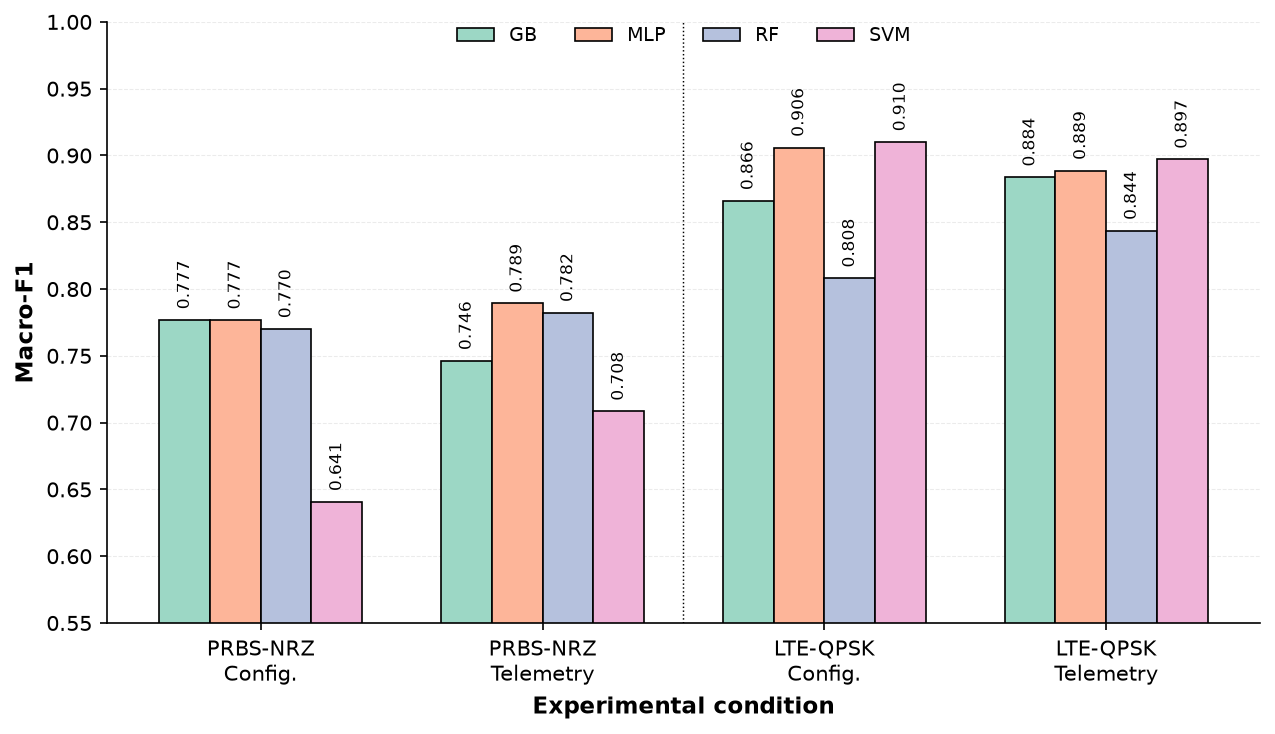

In [62]:
# Step 24 — Main benchmark Macro-F1 figure

fig, ax = plt.subplots(
    figsize=(8.6, 5.0),
    dpi=150
)

x = np.arange(
    len(condition_order)
)

width = 0.18

offsets = [
    -1.5 * width,
    -0.5 * width,
     0.5 * width,
     1.5 * width
]

for model_index, model in enumerate(
    model_order_plot
):

    values = []

    for campaign, scenario in condition_order:

        value = benchmark_plot_data[
            (
                benchmark_plot_data[
                    "Campaign"
                ] == campaign
            )
            &
            (
                benchmark_plot_data[
                    "Scenario"
                ] == scenario
            )
            &
            (
                benchmark_plot_data[
                    "Model"
                ] == model
            )
        ]["Macro-F1"].iloc[0]

        values.append(
            value
        )

    bars = ax.bar(
        x + offsets[model_index],
        values,
        width=width,
        label=model,
        color=SET2_PASTEL[model_index],
        edgecolor="black",
        linewidth=0.8
    )

    # Numerical labels
    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            +
            bar.get_width() / 2,
            value + 0.008,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(
    x
)

ax.set_xticklabels(
    condition_labels,
    fontsize=10
)

ax.set_xlabel(
    "Experimental condition",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Macro-F1",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(
    0.55,
    1.00
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(
    True
)

# Subtle separation between campaigns
ax.axvline(
    1.5,
    color="black",
    linewidth=0.7,
    linestyle=":"
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

ax.spines[
    "left"
].set_linewidth(0.8)

ax.spines[
    "bottom"
].set_linewidth(0.8)

ax.legend(
    ncol=4,
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        1.02
    )
)

plt.tight_layout()

benchmark_figure_path = (
    FIGURES_DIR
    /
    "benchmark_macro_f1_main.pdf"
)

plt.savefig(
    benchmark_figure_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    benchmark_figure_path
)

plt.show()

In [63]:
# Step 25 — Verify benchmark figure

print(
    "Figure exists:",
    benchmark_figure_path.exists()
)

print(
    "File size (KB):",
    round(
        benchmark_figure_path.stat().st_size
        / 1024,
        2
    )
)

Figure exists: True
File size (KB): 22.48


### Proposed benchmark figure caption

**Figure X. Independent-Test Macro-F1 across experimental campaigns, predictor
scenarios, and machine-learning classifiers.**

Performance is reported for Gradient Boosting (GB), multilayer perceptron
(MLP), Random Forest (RF), and support vector machine (SVM) using the frozen
independent-Test partition. Configuration-based models use experimental setup
parameters only, whereas Telemetry-assisted models additionally include
receiver-side optical power. Point estimates should be interpreted together
with the group-bootstrap uncertainty analyses reported separately.

### Benchmark interpretation

The independent-Test benchmark demonstrates that predictive performance varies
across both experimental campaigns and classifier families.

PRBS-NRZ yields lower Macro-F1 values than LTE-QPSK for most evaluated
conditions, consistent with the greater group-level heterogeneity and
cross-model disagreement identified in the robustness analyses.

Within individual campaign-scenario conditions, small differences in point
estimates should not automatically be interpreted as robust model separation.
The paired experimental-group bootstrap analysis showed that several
classifier-pair confidence intervals include zero, particularly for LTE-QPSK.

Therefore, the benchmark figure is used primarily to summarize predictive
performance, while uncertainty regarding model-to-model differences is
reported separately.

In [71]:
# Step 28 — Locate permutation-importance objects currently in memory

importance_objects = [
    name
    for name in globals().keys()
    if (
        "importance" in name.lower()
        or "permutation" in name.lower()
    )
]

print("Possible feature-importance objects:\n")

for name in sorted(importance_objects):
    obj = globals()[name]

    if isinstance(obj, pd.DataFrame):
        print(
            f"{name:40s}",
            "| DataFrame",
            "| shape:",
            obj.shape
        )

    else:
        print(
            f"{name:40s}",
            "|",
            type(obj).__name__
        )

Possible feature-importance objects:

importance_objects                       | list


In [72]:
# Step 28A — Search saved permutation-importance artifacts

from pathlib import Path

search_dirs = [
    Path("tables"),
    Path("artifacts"),
    Path("figures")
]

keywords = [
    "importance",
    "permutation",
    "feature"
]

matches = []

for directory in search_dirs:

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if path.is_file():

            name_lower = path.name.lower()

            if any(
                keyword in name_lower
                for keyword in keywords
            ):
                matches.append(path)


print("Possible feature-importance files:\n")

if matches:

    for path in sorted(matches):
        print(path)

else:
    print("No saved feature-importance files found.")

Possible feature-importance files:

figures\feature_importance_lte_config.pdf
figures\feature_importance_lte_telemetry.pdf
figures\feature_importance_prbs_config.pdf
figures\feature_importance_prbs_telemetry.pdf


In [ ]:
feature_importance_table = pd.read_csv(
    "AQUI_COLOCA_LA_RUTA_DEL_CSV"
)

print(feature_importance_table.shape)
print(feature_importance_table.columns.tolist())

display(
    feature_importance_table.head(20)
)

In [73]:
# Step 28C — Search checkpoint files for feature-importance objects

from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("artifacts")

joblib_files = sorted(
    ARTIFACTS_DIR.glob("*.joblib")
)

print(
    "Checkpoint files found:",
    len(joblib_files)
)

importance_checkpoint_matches = []

for path in joblib_files:

    try:

        checkpoint = joblib.load(path)

        if isinstance(checkpoint, dict):

            matching_keys = [
                key
                for key in checkpoint.keys()
                if (
                    "importance" in key.lower()
                    or "permutation" in key.lower()
                    or "feature" in key.lower()
                )
            ]

            if matching_keys:

                importance_checkpoint_matches.append(
                    (
                        path,
                        matching_keys
                    )
                )

                print("\n", path)

                for key in matching_keys:
                    print("   ->", key)

    except Exception as error:

        print(
            "Could not inspect:",
            path,
            "|",
            type(error).__name__
        )


if not importance_checkpoint_matches:

    print(
        "\nNo feature-importance objects were found "
        "inside the saved checkpoints."
    )

Checkpoint files found: 6

 artifacts\activity16_complete.joblib
   -> TEST_FEATURE_MAP
   -> difficulty_feature_table
   -> FAILURE_FEATURES

 artifacts\activity16_step16_checkpoint.joblib
   -> TEST_FEATURE_MAP
   -> difficulty_feature_table
   -> FAILURE_FEATURES


In [74]:
# Step 28D — Search all CSV files in the current project

csv_files = list(
    Path(".").rglob("*.csv")
)

candidate_csv = [
    path
    for path in csv_files
    if any(
        word in path.name.lower()
        for word in [
            "importance",
            "feature",
            "permutation"
        ]
    )
]

print(
    "Possible CSV files:"
)

if candidate_csv:

    for path in candidate_csv:
        print(path)

else:

    print(
        "No feature-importance CSV files found."
    )

Possible CSV files:
No feature-importance CSV files found.


In [76]:
# Step 28E — Check optimized-model objects currently in memory

objects_to_check = [
    "optimization_searches",
    "selected_hyperparameters",
    "X_prbs_config_test",
    "X_prbs_telemetry_test",
    "X_lte_config_test",
    "X_lte_telemetry_test",
    "y_prbs_test",
    "y_lte_test"
]

for obj in objects_to_check:

    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

optimization_searches          MISSING
selected_hyperparameters       MISSING
X_prbs_config_test             MISSING
X_prbs_telemetry_test          MISSING
X_lte_config_test              MISSING
X_lte_telemetry_test           MISSING
y_prbs_test                    MISSING
y_lte_test                     MISSING


In [77]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("artifacts")

joblib_files = sorted(
    ARTIFACTS_DIR.glob("*.joblib")
)

for path in joblib_files:

    try:
        checkpoint = joblib.load(path)

        if isinstance(checkpoint, dict):

            matching_keys = [
                key
                for key in checkpoint.keys()
                if any(
                    word in key.lower()
                    for word in [
                        "optimization",
                        "search",
                        "estimator",
                        "model",
                        "hyperparameter"
                    ]
                )
            ]

            if matching_keys:

                print("\n", path)

                for key in matching_keys:
                    print("   ->", key)

    except Exception as error:
        print(
            "Could not inspect:",
            path,
            "|",
            type(error).__name__
        )


 artifacts\activity16_complete.joblib
   -> model_error_summary

 artifacts\activity16_step16_checkpoint.joblib
   -> model_error_summary

 artifacts\activity19_complete.joblib
   -> pairwise_model_bootstrap


In [78]:
A16 = joblib.load(
    ARTIFACTS_DIR / "activity16_complete.joblib"
)

for key in sorted(A16.keys()):
    print(key)

FAILURE_FEATURES
TEST_FEATURE_MAP
X_lte_config_test
X_lte_telemetry_test
X_prbs_config_test
X_prbs_telemetry_test
acceptable_easy_hard
acceptable_error_summary
acceptable_failure_region_summary
acceptable_region_counts
acceptable_robust_shift
activity16_summary
class_error_summary
consensus_difficulty
difficulty_by_class
difficulty_distribution
difficulty_feature_table
error_analysis_table
failure_region_summary
lte_config_failure
lte_telemetry_failure
model_error_summary
prbs_config_failure
prbs_failure_comparison
prbs_telemetry_failure
test_per_class
test_performance
test_prediction_store


In [79]:
# Search Jupyter notebooks for Activity 12 / permutation importance

from pathlib import Path

notebooks = list(
    Path(".").rglob("*.ipynb")
)

matches = []

for path in notebooks:

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        ).lower()

        if (
            "permutation_importance" in text
            or "feature_importance_prbs" in text
            or "activity 12" in text
        ):
            matches.append(path)

    except Exception:
        pass


print("Matching notebooks:\n")

if matches:
    for path in matches:
        print(path)
else:
    print("No matching notebooks found.")

Matching notebooks:

01_dataset_ml_validation.ipynb


In [83]:
import json
from pathlib import Path

notebook_path = Path("01_dataset_ml_validation.ipynb")

with open(
    notebook_path,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):

    source = "".join(
        cell.get("source", [])
    )

    if (
        "permutation_importance" in source
        or "Activity 12" in source
        or "feature_importance_prbs" in source
    ):

        print("\n" + "=" * 80)
        print("CELL:", i)
        print("=" * 80)
        print(source[:3000])


CELL: 376
# Activity 12 — Feature Importance Analysis

## Objective

The objective of this activity is to identify which experimental predictors
contribute most strongly to QoT classification.

Feature importance is evaluated using permutation importance applied to the
optimized Random Forest classifiers.

The analysis is performed separately for:

- PRBS-NRZ;
- LTE-QPSK;
- Configuration-based prediction;
- Telemetry-assisted prediction.

Permutation importance measures the decrease in independent-Test Macro-F1
produced when the values of one predictor are randomly permuted while all
other predictors remain unchanged.

The optimized models, preprocessing pipelines, and Test partitions remain
frozen. No model retraining, hyperparameter modification, or Test-driven model
selection is performed.

This analysis therefore provides a post-hoc interpretation of the already
evaluated models.

CELL: 378
# Step 2 — Import permutation importance utility

from sklearn.inspection import permutatio

In [84]:
# Recover the saved output of Activity 12 — Top 5 feature importance

cell_number = 397

cell = notebook["cells"][cell_number]

print(
    "Cell type:",
    cell.get("cell_type")
)

print(
    "Number of saved outputs:",
    len(cell.get("outputs", []))
)

for i, output in enumerate(
    cell.get("outputs", [])
):

    print("\n" + "=" * 80)
    print("OUTPUT:", i)
    print("=" * 80)

    if "text" in output:
        print(
            "".join(
                output["text"]
            )
        )

    elif "data" in output:

        data = output["data"]

        if "text/plain" in data:
            print(
                "".join(
                    data["text/plain"]
                )
            )

Cell type: code
Number of saved outputs: 1

OUTPUT: 0
    Campaign             Scenario  Rank                        Feature  Importance mean  Importance std
0   LTE_QPSK  Configuration-based     1             voa_attenuation_db           0.4269          0.0292
1   LTE_QPSK  Configuration-based     2             smf_attenuation_db           0.0311          0.0260
2   LTE_QPSK  Configuration-based     3                  wavelength_nm           0.0252          0.0217
3   LTE_QPSK  Configuration-based     4                 soa_current_ma           0.0230          0.0205
4   LTE_QPSK  Configuration-based     5  max_allowed_optical_power_dbm           0.0000          0.0000
20  LTE_QPSK   Telemetry-assisted     1                        prx_dbm           0.3573          0.0472
21  LTE_QPSK   Telemetry-assisted     2             voa_attenuation_db           0.2490          0.0345
22  LTE_QPSK   Telemetry-assisted     3             smf_attenuation_db           0.0480          0.0179
23  LTE_QP

In [85]:
# Recover top5_importance directly from the saved notebook output

import io
import pandas as pd

cell_number = 397

saved_output = (
    notebook["cells"][cell_number]
    ["outputs"][0]
    ["data"]["text/plain"]
)

saved_text = "".join(saved_output)

top5_importance = pd.read_fwf(
    io.StringIO(saved_text)
)

# Remove possible saved display-index column
if top5_importance.columns[0].startswith("Unnamed"):
    top5_importance = top5_importance.iloc[:, 1:]

print(
    "Shape:",
    top5_importance.shape
)

print(
    "Columns:",
    top5_importance.columns.tolist()
)

display(
    top5_importance
)

Shape: (20, 6)
Columns: ['Campaign', 'Scenario', 'Rank', 'Feature', 'Importance mean', 'Importance std']


,Campaign,Scenario,Rank,Feature,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,0.4269,0.0292
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,0.0311,0.0260
2,LTE_QPSK,Configuration-based,3,wavelength_nm,0.0252,0.0217
3,LTE_QPSK,Configuration-based,4,soa_current_ma,0.0230,0.0205
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,0.0000,0.0000
5,LTE_QPSK,Telemetry-assisted,1,prx_dbm,0.3573,0.0472
6,LTE_QPSK,Telemetry-assisted,2,voa_attenuation_db,0.2490,0.0345
7,LTE_QPSK,Telemetry-assisted,3,smf_attenuation_db,0.0480,0.0179
8,LTE_QPSK,Telemetry-assisted,4,soa_current_ma,0.0416,0.0244
9,LTE_QPSK,Telemetry-assisted,5,vbias_v,0.0244,0.0218


In [86]:
# Save recovered Activity 12 Top-5 permutation importance

top5_importance.to_csv(
    TABLES_DIR / "table_top5_permutation_importance.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_top5_permutation_importance.csv"
)

print(
    "Rows:",
    len(top5_importance)
)

Saved: tables\table_top5_permutation_importance.csv
Rows: 20


In [87]:
# Step 29 — Clean feature names for publication

FEATURE_LABELS = {
    "vbias_v": "Vbias",
    "voa_attenuation_db": "VOA attenuation",
    "transmission_rate_bps": "Transmission rate",
    "optical_tx_power_dbm": "Tx optical power",
    "soa_current_ma": "SOA current",
    "prx_dbm": "PRx",
    "smf_attenuation_db": "SMF attenuation",
    "wavelength_nm": "Wavelength",
    "max_allowed_optical_power_dbm": "Max. optical power"
}

top5_importance[
    "Feature label"
] = (
    top5_importance[
        "Feature"
    ]
    .map(FEATURE_LABELS)
    .fillna(
        top5_importance[
            "Feature"
        ]
    )
)

display(
    top5_importance[
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Feature label",
            "Importance mean",
            "Importance std"
        ]
    ]
)

,Campaign,Scenario,Rank,Feature,Feature label,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,VOA attenuation,0.4269,0.0292
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,SMF attenuation,0.0311,0.0260
2,LTE_QPSK,Configuration-based,3,wavelength_nm,Wavelength,0.0252,0.0217
3,LTE_QPSK,Configuration-based,4,soa_current_ma,SOA current,0.0230,0.0205
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,Max. optical power,0.0000,0.0000
5,LTE_QPSK,Telemetry-assisted,1,prx_dbm,PRx,0.3573,0.0472
6,LTE_QPSK,Telemetry-assisted,2,voa_attenuation_db,VOA attenuation,0.2490,0.0345
7,LTE_QPSK,Telemetry-assisted,3,smf_attenuation_db,SMF attenuation,0.0480,0.0179
8,LTE_QPSK,Telemetry-assisted,4,soa_current_ma,SOA current,0.0416,0.0244
9,LTE_QPSK,Telemetry-assisted,5,vbias_v,Vbias,0.0244,0.0218


Saved: figures\feature_importance_prbs_consolidated.pdf


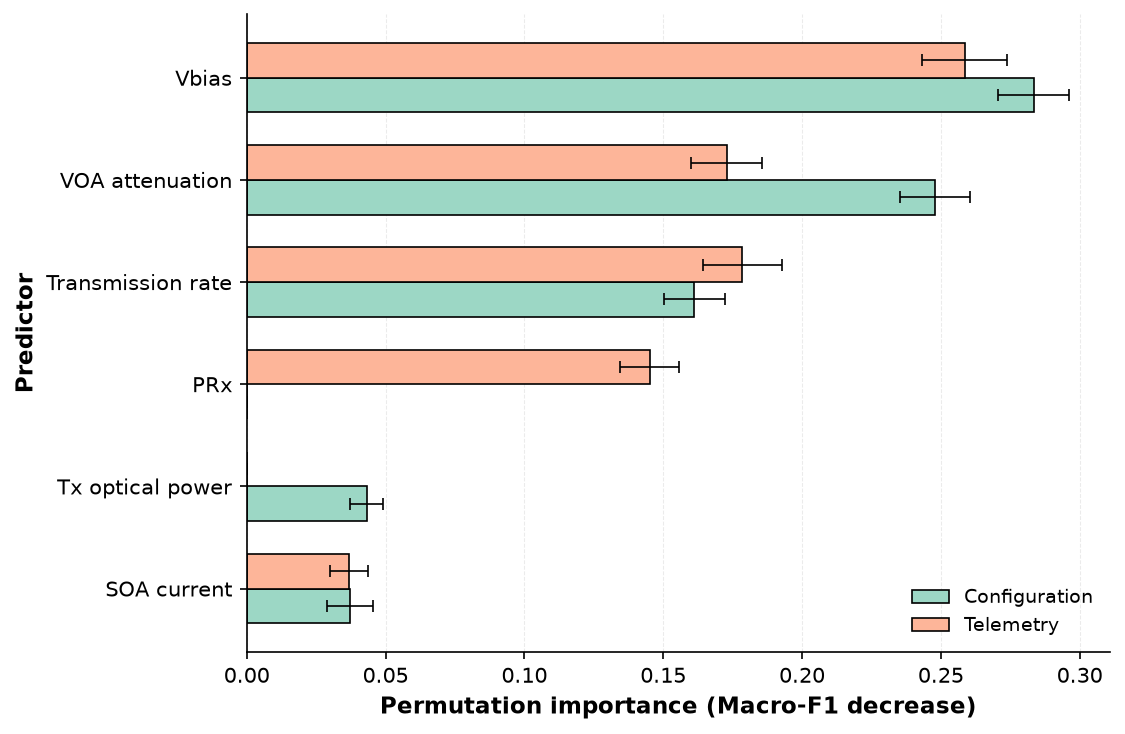

In [88]:
# Step 30 — PRBS-NRZ consolidated permutation importance

prbs_plot = (
    top5_importance[
        top5_importance["Campaign"] == "PRBS_NRZ"
    ]
    .copy()
)

# Union of features appearing in the Top-5 of either scenario
prbs_features = (
    prbs_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []

telemetry_values = []
telemetry_std = []

for feature in prbs_features:

    config_row = prbs_plot[
        (prbs_plot["Scenario"] == "Configuration-based")
        &
        (prbs_plot["Feature label"] == feature)
    ]

    telemetry_row = prbs_plot[
        (prbs_plot["Scenario"] == "Telemetry-assisted")
        &
        (prbs_plot["Feature label"] == feature)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0 else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0 else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )


y = np.arange(len(prbs_features))
height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)

ax.set_yticklabels(
    prbs_features,
    fontsize=10
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

prbs_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_prbs_consolidated.pdf"
)

plt.savefig(
    prbs_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    prbs_importance_path
)

plt.show()

Saved: figures\feature_importance_lte_consolidated.pdf


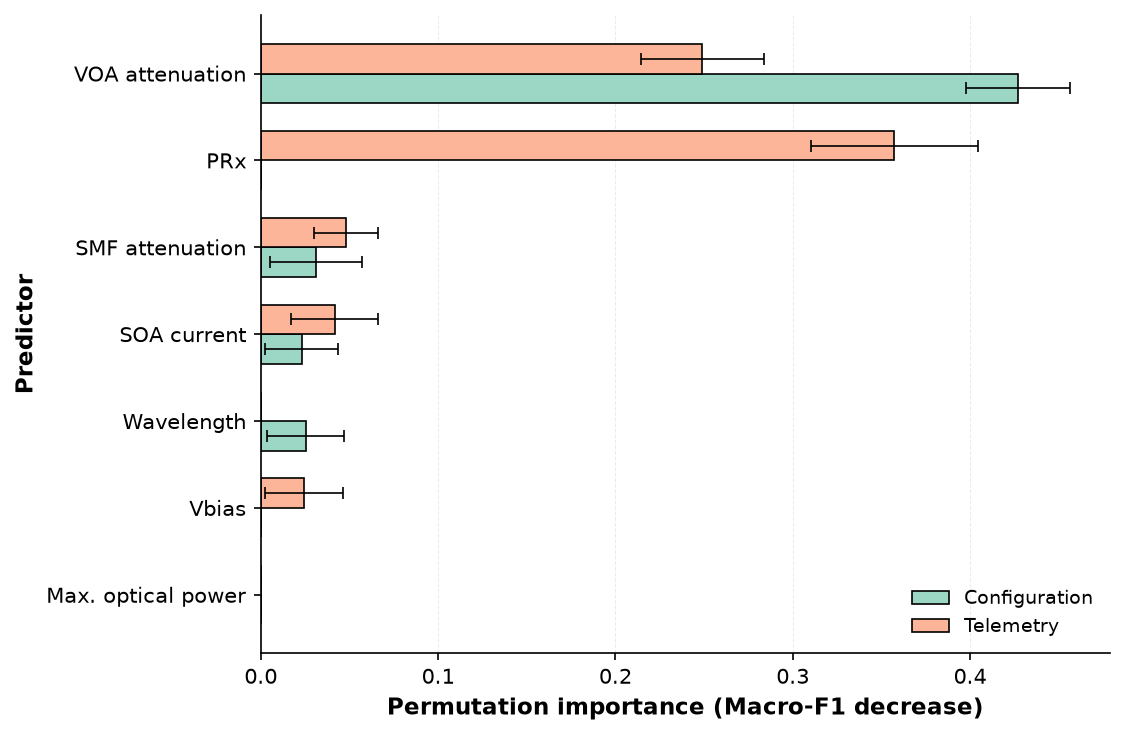

In [89]:
# Step 31 — LTE-QPSK consolidated permutation importance

lte_plot = (
    top5_importance[
        top5_importance["Campaign"] == "LTE_QPSK"
    ]
    .copy()
)

# Union of features appearing in the Top-5 of either scenario
lte_features = (
    lte_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []

telemetry_values = []
telemetry_std = []

for feature in lte_features:

    config_row = lte_plot[
        (lte_plot["Scenario"] == "Configuration-based")
        &
        (lte_plot["Feature label"] == feature)
    ]

    telemetry_row = lte_plot[
        (lte_plot["Scenario"] == "Telemetry-assisted")
        &
        (lte_plot["Feature label"] == feature)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0 else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0 else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )


y = np.arange(len(lte_features))
height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)

ax.set_yticklabels(
    lte_features,
    fontsize=10
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

lte_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_lte_consolidated.pdf"
)

plt.savefig(
    lte_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    lte_importance_path
)

plt.show()

In [90]:
# Recover the saved output of the full permutation-importance table

cell_number = 396

cell = notebook["cells"][cell_number]

print(
    "Cell type:",
    cell.get("cell_type")
)

print(
    "Number of saved outputs:",
    len(cell.get("outputs", []))
)

for i, output in enumerate(
    cell.get("outputs", [])
):

    print("\n" + "=" * 80)
    print("OUTPUT:", i)
    print("=" * 80)

    if "data" in output:

        data = output["data"]

        if "text/plain" in data:

            text_output = "".join(
                data["text/plain"]
            )

            print(text_output)

Cell type: code
Number of saved outputs: 1

OUTPUT: 0
    Campaign             Scenario  Rank                            Feature  Importance mean  Importance std
0   LTE_QPSK  Configuration-based     1                 voa_attenuation_db          0.42686         0.02925
1   LTE_QPSK  Configuration-based     2                 smf_attenuation_db          0.03108         0.02605
2   LTE_QPSK  Configuration-based     3                      wavelength_nm          0.02518         0.02166
3   LTE_QPSK  Configuration-based     4                     soa_current_ma          0.02298         0.02052
4   LTE_QPSK  Configuration-based     5      max_allowed_optical_power_dbm          0.00000         0.00000
5   LTE_QPSK  Configuration-based     6  optical_receiver_responsivity_a_w          0.00000         0.00000
6   LTE_QPSK  Configuration-based     7           modulator_attenuation_db          0.00000         0.00000
7   LTE_QPSK  Configuration-based     8              transmission_rate_bps        

In [91]:
# Recover the complete Activity 12 permutation-importance table
# directly from the saved notebook output

import io
import pandas as pd

cell_number = 396

saved_output = (
    notebook["cells"][cell_number]
    ["outputs"][0]
    ["data"]["text/plain"]
)

saved_text = "".join(saved_output)

all_permutation_importance = pd.read_fwf(
    io.StringIO(saved_text)
)

# Remove possible saved display-index column
if all_permutation_importance.columns[0].startswith("Unnamed"):
    all_permutation_importance = (
        all_permutation_importance.iloc[:, 1:]
    )

print(
    "Shape:",
    all_permutation_importance.shape
)

print(
    "Columns:",
    all_permutation_importance.columns.tolist()
)

display(
    all_permutation_importance.head(10)
)

Shape: (82, 6)
Columns: ['Campaign', 'Scenario', 'Rank', 'Feature', 'Importance mean', 'Importance std']


,Campaign,Scenario,Rank,Feature,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,0.42686,0.02925
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,0.03108,0.02605
2,LTE_QPSK,Configuration-based,3,wavelength_nm,0.02518,0.02166
3,LTE_QPSK,Configuration-based,4,soa_current_ma,0.02298,0.02052
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,0.00000,0.00000
5,LTE_QPSK,Configuration-based,6,optical_receiver_responsivity_a_w,0.00000,0.00000
6,LTE_QPSK,Configuration-based,7,modulator_attenuation_db,0.00000,0.00000
7,LTE_QPSK,Configuration-based,8,transmission_rate_bps,0.00000,0.00000
8,LTE_QPSK,Configuration-based,9,dispersion_ps_nm_km,0.00000,0.00000
9,LTE_QPSK,Configuration-based,10,smf_length_km,0.00000,0.00000


In [92]:
all_permutation_importance.to_csv(
    TABLES_DIR /
    "table_permutation_importance_full.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR /
    "table_permutation_importance_full.csv"
)

Saved: tables\table_permutation_importance_full.csv


In [93]:
# Step 32 — Add publication-friendly labels
# to the complete permutation-importance table

all_permutation_importance[
    "Feature label"
] = (
    all_permutation_importance[
        "Feature"
    ]
    .map(FEATURE_LABELS)
    .fillna(
        all_permutation_importance[
            "Feature"
        ]
    )
)

print(
    "Shape:",
    all_permutation_importance.shape
)

display(
    all_permutation_importance[
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Feature label",
            "Importance mean",
            "Importance std"
        ]
    ].head(15)
)

Shape: (82, 7)


,Campaign,Scenario,Rank,Feature,Feature label,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,VOA attenuation,0.42686,0.02925
1,LTE_QPSK,Configuration-based,2,smf_attenuation_db,SMF attenuation,0.03108,0.02605
2,LTE_QPSK,Configuration-based,3,wavelength_nm,Wavelength,0.02518,0.02166
3,LTE_QPSK,Configuration-based,4,soa_current_ma,SOA current,0.02298,0.02052
4,LTE_QPSK,Configuration-based,5,max_allowed_optical_power_dbm,Max. optical power,0.00000,0.00000
5,LTE_QPSK,Configuration-based,6,optical_receiver_responsivity_a_w,optical_receiver_responsivity_a_w,0.00000,0.00000
6,LTE_QPSK,Configuration-based,7,modulator_attenuation_db,modulator_attenuation_db,0.00000,0.00000
7,LTE_QPSK,Configuration-based,8,transmission_rate_bps,Transmission rate,0.00000,0.00000
8,LTE_QPSK,Configuration-based,9,dispersion_ps_nm_km,dispersion_ps_nm_km,0.00000,0.00000
9,LTE_QPSK,Configuration-based,10,smf_length_km,smf_length_km,0.00000,0.00000


In [94]:
# Step 33 — Complete publication-friendly feature labels

FEATURE_LABELS.update({
    "optical_receiver_responsivity_a_w":
        "Receiver responsivity",

    "modulator_attenuation_db":
        "Modulator attenuation",

    "dispersion_ps_nm_km":
        "Chromatic dispersion",

    "smf_length_km":
        "SMF length",

    "rf_voltage_v":
        "RF voltage",

    "rf_amplifier_tx_db":
        "RF amplifier TX",

    "rf_amplifier_rx_db":
        "RF amplifier RX",

    "detector_bw_hz":
        "Detector bandwidth",

    "photodiode":
        "Photodiode",

    "edfa_current_ma":
        "EDFA current",

    "rf_power_dbm":
        "RF power",

    "modulator_type":
        "Modulator type"
})

all_permutation_importance[
    "Feature label"
] = (
    all_permutation_importance[
        "Feature"
    ]
    .map(FEATURE_LABELS)
    .fillna(
        all_permutation_importance[
            "Feature"
        ]
    )
)

display(
    all_permutation_importance[
        [
            "Feature",
            "Feature label"
        ]
    ]
    .drop_duplicates()
    .sort_values("Feature label")
    .reset_index(drop=True)
)

,Feature,Feature label
0,dispersion_ps_nm_km,Chromatic dispersion
1,detector_bw_hz,Detector bandwidth
2,edfa_current_ma,EDFA current
3,max_allowed_optical_power_dbm,Max. optical power
4,modulator_attenuation_db,Modulator attenuation
5,modulator_type,Modulator type
6,prx_dbm,PRx
7,photodiode,Photodiode
8,rf_amplifier_rx_db,RF amplifier RX
9,rf_amplifier_tx_db,RF amplifier TX


Saved: figures\feature_importance_prbs_consolidated_corrected.pdf


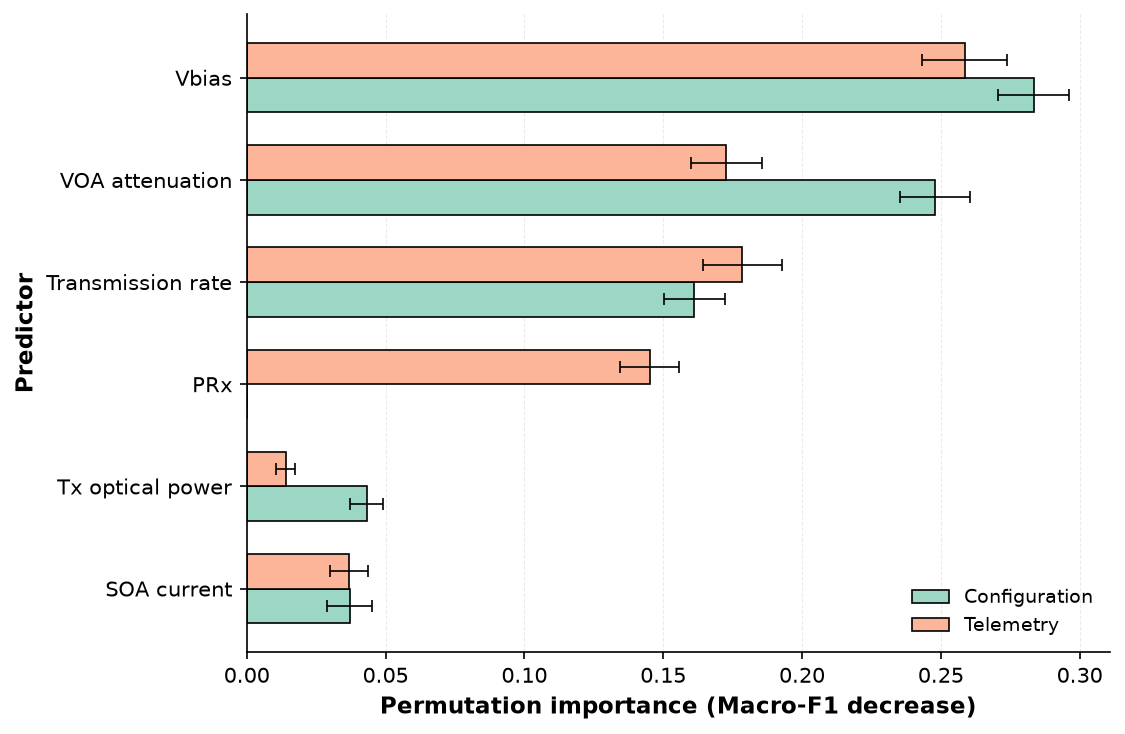

In [95]:
# Step 34 — Corrected PRBS-NRZ consolidated permutation importance
# Uses the complete Activity 12 table

prbs_all = (
    all_permutation_importance[
        all_permutation_importance["Campaign"] == "PRBS_NRZ"
    ]
    .copy()
)

# Select the union of the Top-5 predictors from both scenarios
prbs_top_features = (
    top5_importance[
        top5_importance["Campaign"] == "PRBS_NRZ"
    ]["Feature"]
    .drop_duplicates()
    .tolist()
)

# Keep complete importance values for those predictors
prbs_plot = (
    prbs_all[
        prbs_all["Feature"].isin(
            prbs_top_features
        )
    ]
    .copy()
)

# Order features by their maximum importance across both scenarios
feature_order = (
    prbs_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []

telemetry_values = []
telemetry_std = []

for feature_label in feature_order:

    config_row = prbs_plot[
        (prbs_plot["Scenario"] == "Configuration-based")
        &
        (prbs_plot["Feature label"] == feature_label)
    ]

    telemetry_row = prbs_plot[
        (prbs_plot["Scenario"] == "Telemetry-assisted")
        &
        (prbs_plot["Feature label"] == feature_label)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )


y = np.arange(
    len(feature_order)
)

height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)

ax.set_yticklabels(
    feature_order,
    fontsize=10
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

prbs_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_prbs_consolidated_corrected.pdf"
)

plt.savefig(
    prbs_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    prbs_importance_path
)

plt.show()

Saved: figures\feature_importance_lte_consolidated_corrected.pdf


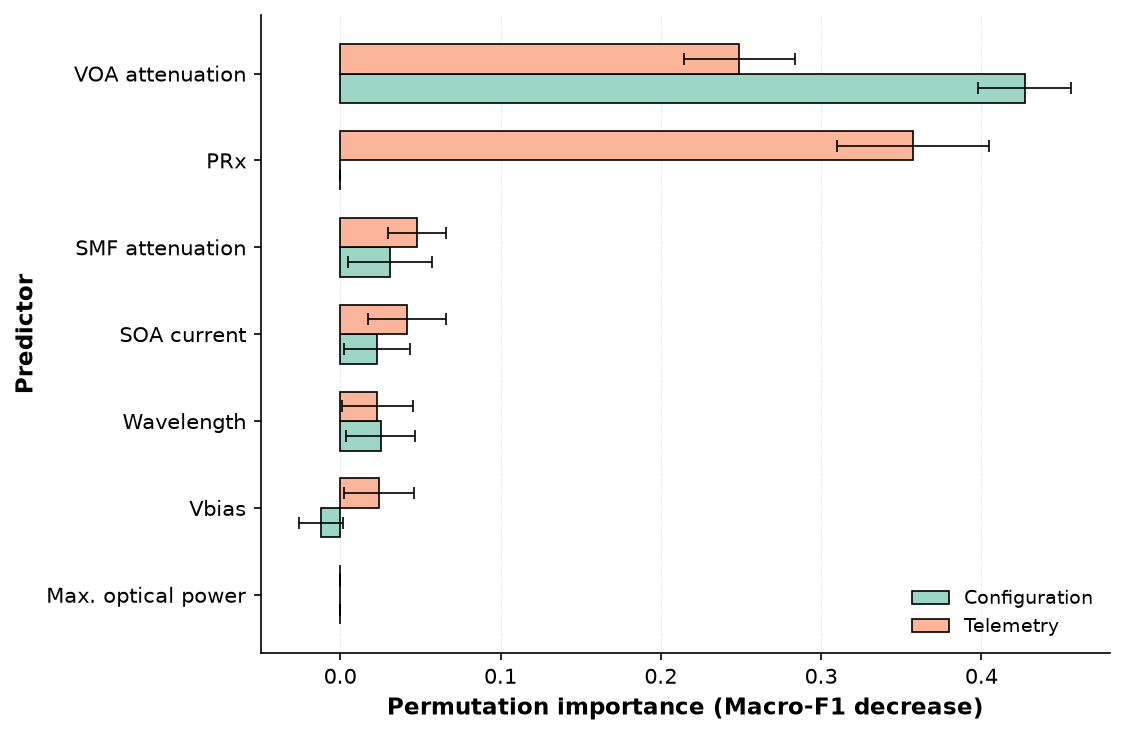

In [96]:
# Step 35 — Corrected LTE-QPSK consolidated permutation importance
# Uses the complete Activity 12 table

lte_all = (
    all_permutation_importance[
        all_permutation_importance["Campaign"] == "LTE_QPSK"
    ]
    .copy()
)

# Union of Top-5 predictors from both scenarios
lte_top_features = (
    top5_importance[
        top5_importance["Campaign"] == "LTE_QPSK"
    ]["Feature"]
    .drop_duplicates()
    .tolist()
)

# Retrieve the real importance values of those predictors
# from the complete permutation-importance table
lte_plot = (
    lte_all[
        lte_all["Feature"].isin(
            lte_top_features
        )
    ]
    .copy()
)

# Order according to maximum importance across scenarios
feature_order = (
    lte_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []

telemetry_values = []
telemetry_std = []

for feature_label in feature_order:

    config_row = lte_plot[
        (lte_plot["Scenario"] == "Configuration-based")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    telemetry_row = lte_plot[
        (lte_plot["Scenario"] == "Telemetry-assisted")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )


y = np.arange(
    len(feature_order)
)

height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)

ax.set_yticklabels(
    feature_order,
    fontsize=10
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

lte_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_lte_consolidated_corrected.pdf"
)

plt.savefig(
    lte_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    lte_importance_path
)

plt.show()

Saved: figures\feature_importance_lte_consolidated_corrected.pdf


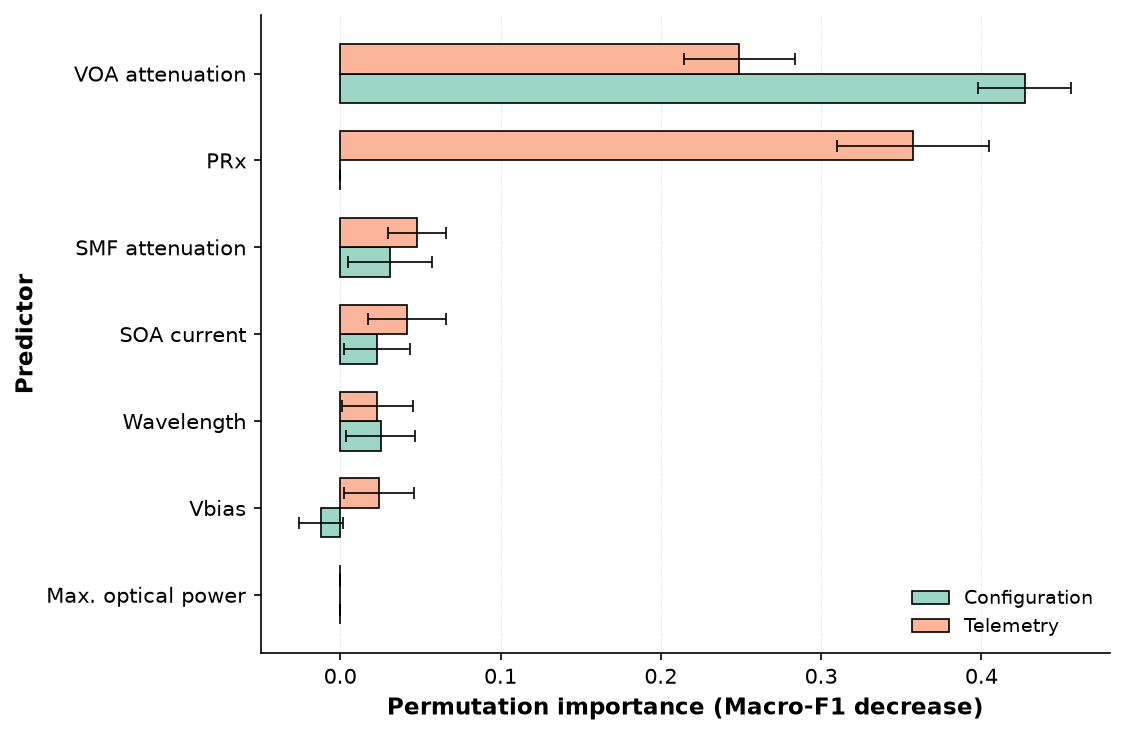

In [97]:
# Step 35 — Corrected LTE-QPSK consolidated permutation importance
# Uses the complete Activity 12 table

lte_all = (
    all_permutation_importance[
        all_permutation_importance["Campaign"] == "LTE_QPSK"
    ]
    .copy()
)

# Union of Top-5 predictors from both scenarios
lte_top_features = (
    top5_importance[
        top5_importance["Campaign"] == "LTE_QPSK"
    ]["Feature"]
    .drop_duplicates()
    .tolist()
)

# Retrieve the real importance values of those predictors
# from the complete permutation-importance table
lte_plot = (
    lte_all[
        lte_all["Feature"].isin(
            lte_top_features
        )
    ]
    .copy()
)

# Order according to maximum importance across scenarios
feature_order = (
    lte_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []

telemetry_values = []
telemetry_std = []

for feature_label in feature_order:

    config_row = lte_plot[
        (lte_plot["Scenario"] == "Configuration-based")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    telemetry_row = lte_plot[
        (lte_plot["Scenario"] == "Telemetry-assisted")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0
        else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0
        else 0
    )


y = np.arange(
    len(feature_order)
)

height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)

ax.set_yticklabels(
    feature_order,
    fontsize=10
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

lte_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_lte_consolidated_corrected.pdf"
)

plt.savefig(
    lte_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    lte_importance_path
)

plt.show()

In [98]:
print("LTE top features:")
for feature in lte_top_features:
    print(" -", feature)

print("\nFeature order used in the plot:")
for feature in feature_order:
    print(" -", feature)

LTE top features:
 - voa_attenuation_db
 - smf_attenuation_db
 - wavelength_nm
 - soa_current_ma
 - max_allowed_optical_power_dbm
 - prx_dbm
 - vbias_v

Feature order used in the plot:
 - Max. optical power
 - Vbias
 - Wavelength
 - SOA current
 - SMF attenuation
 - PRx
 - VOA attenuation


In [99]:
display(
    lte_plot[
        lte_plot["Feature"] == "voa_attenuation_db"
    ][
        [
            "Campaign",
            "Scenario",
            "Rank",
            "Feature",
            "Feature label",
            "Importance mean",
            "Importance std"
        ]
    ]
)

,Campaign,Scenario,Rank,Feature,Feature label,Importance mean,Importance std
0,LTE_QPSK,Configuration-based,1,voa_attenuation_db,VOA attenuation,0.42686,0.02925
21,LTE_QPSK,Telemetry-assisted,2,voa_attenuation_db,VOA attenuation,0.24898,0.03454


In [100]:
# Check the exact values sent to the LTE plot

for feature, config, telemetry in zip(
    feature_order,
    config_values,
    telemetry_values
):
    print(
        f"{feature:22s} | "
        f"Configuration = {config:.5f} | "
        f"Telemetry = {telemetry:.5f}"
    )

Max. optical power     | Configuration = 0.00000 | Telemetry = 0.00000
Vbias                  | Configuration = -0.01196 | Telemetry = 0.02444
Wavelength             | Configuration = 0.02518 | Telemetry = 0.02309
SOA current            | Configuration = 0.02298 | Telemetry = 0.04157
SMF attenuation        | Configuration = 0.03108 | Telemetry = 0.04799
PRx                    | Configuration = 0.00000 | Telemetry = 0.35733
VOA attenuation        | Configuration = 0.42686 | Telemetry = 0.24898


In [101]:
# Ensure all LTE predictors are visible

ax.set_yticks(y)

ax.set_yticklabels(
    feature_order,
    fontsize=10
)

# Explicit vertical limits so the first and last bars are not clipped
ax.set_ylim(
    -0.6,
    len(feature_order) - 0.4
)

# Allow the negative Vbias importance to remain visible
ax.set_xlim(
    -0.05,
    0.48
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

plt.tight_layout()

lte_importance_path = (
    FIGURES_DIR
    /
    "feature_importance_lte_consolidated_corrected.pdf"
)

plt.savefig(
    lte_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    lte_importance_path
)

plt.show()

Saved: figures\feature_importance_lte_consolidated_corrected.pdf


<Figure size 640x480 with 0 Axes>

Saved: figures\feature_importance_lte_consolidated_corrected.pdf
File size (KB): 24.63


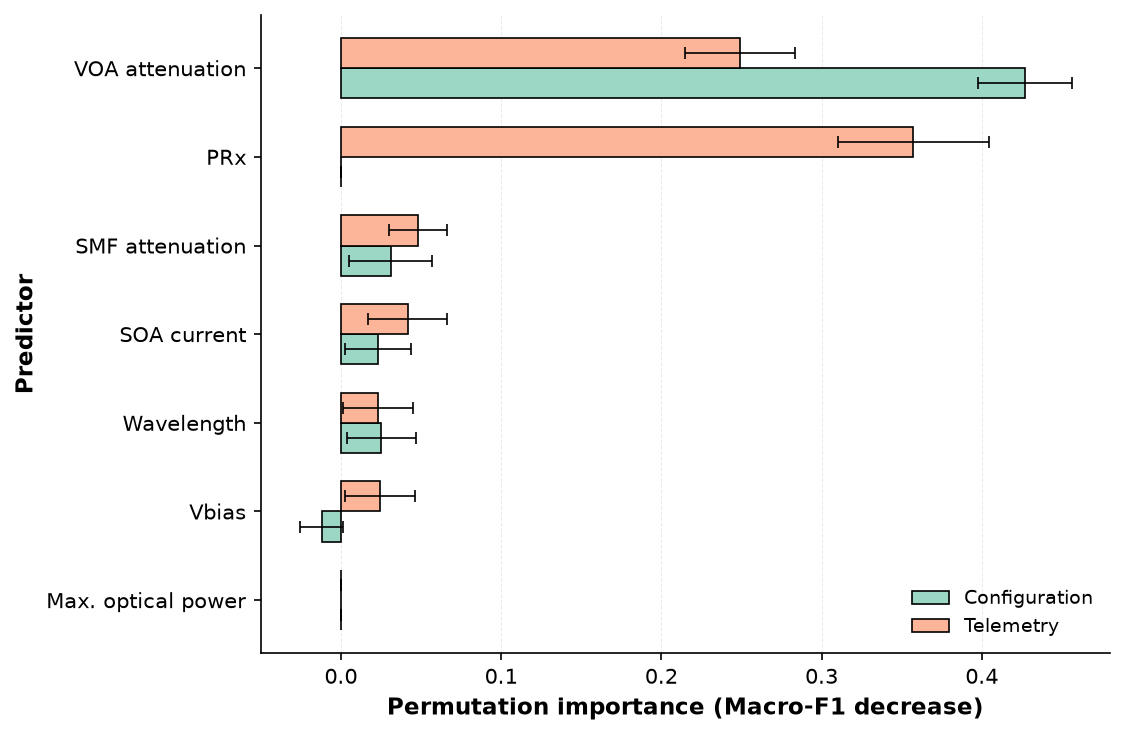

In [102]:
# Step 35B — Regenerate and correctly save LTE-QPSK figure

lte_all = (
    all_permutation_importance[
        all_permutation_importance["Campaign"] == "LTE_QPSK"
    ]
    .copy()
)

lte_top_features = (
    top5_importance[
        top5_importance["Campaign"] == "LTE_QPSK"
    ]["Feature"]
    .drop_duplicates()
    .tolist()
)

lte_plot = (
    lte_all[
        lte_all["Feature"].isin(lte_top_features)
    ]
    .copy()
)

feature_order = (
    lte_plot
    .groupby("Feature label")["Importance mean"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

config_values = []
config_std = []
telemetry_values = []
telemetry_std = []

for feature_label in feature_order:

    config_row = lte_plot[
        (lte_plot["Scenario"] == "Configuration-based")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    telemetry_row = lte_plot[
        (lte_plot["Scenario"] == "Telemetry-assisted")
        &
        (lte_plot["Feature label"] == feature_label)
    ]

    config_values.append(
        config_row["Importance mean"].iloc[0]
        if len(config_row) > 0 else 0
    )

    config_std.append(
        config_row["Importance std"].iloc[0]
        if len(config_row) > 0 else 0
    )

    telemetry_values.append(
        telemetry_row["Importance mean"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )

    telemetry_std.append(
        telemetry_row["Importance std"].iloc[0]
        if len(telemetry_row) > 0 else 0
    )


y = np.arange(len(feature_order))
height = 0.34

fig, ax = plt.subplots(
    figsize=(7.6, 5.0),
    dpi=150
)

ax.barh(
    y - height / 2,
    config_values,
    height=height,
    xerr=config_std,
    label="Configuration",
    color=SET2_PASTEL[0],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.barh(
    y + height / 2,
    telemetry_values,
    height=height,
    xerr=telemetry_std,
    label="Telemetry",
    color=SET2_PASTEL[1],
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "ecolor": "black",
        "elinewidth": 0.8,
        "capsize": 3,
        "capthick": 0.8
    }
)

ax.set_yticks(y)
ax.set_yticklabels(feature_order, fontsize=10)

ax.set_ylim(
    -0.6,
    len(feature_order) - 0.4
)

ax.set_xlim(
    -0.05,
    0.48
)

ax.set_xlabel(
    "Permutation importance (Macro-F1 decrease)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

fig.tight_layout()

lte_importance_path = (
    FIGURES_DIR /
    "feature_importance_lte_consolidated_corrected.pdf"
)

# IMPORTANT: save the specific figure object
fig.savefig(
    lte_importance_path,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", lte_importance_path)
print(
    "File size (KB):",
    round(
        lte_importance_path.stat().st_size / 1024,
        2
    )
)

plt.show()

In [105]:
# Complete Activity 21 feature-importance checkpoint

import joblib

# Save labeled Top-5 table
top5_importance.to_csv(
    TABLES_DIR / "table_permutation_importance_top5_labeled.csv",
    index=False
)

# Save checkpoint
activity21_feature_checkpoint = {

    "all_permutation_importance":
        all_permutation_importance,

    "top5_importance":
        top5_importance,

    "FEATURE_LABELS":
        FEATURE_LABELS,

    "prbs_figure":
        str(
            FIGURES_DIR /
            "feature_importance_prbs_consolidated_corrected.pdf"
        ),

    "lte_figure":
        str(
            FIGURES_DIR /
            "feature_importance_lte_consolidated_corrected.pdf"
        )
}

checkpoint_path = (
    ARTIFACTS_DIR /
    "activity21_feature_importance_checkpoint.joblib"
)

joblib.dump(
    activity21_feature_checkpoint,
    checkpoint_path,
    compress=3
)

print(
    "Saved:",
    TABLES_DIR /
    "table_permutation_importance_top5_labeled.csv"
)

print(
    "Checkpoint:",
    checkpoint_path
)

print(
    "Checkpoint exists:",
    checkpoint_path.exists()
)

Saved: tables\table_permutation_importance_top5_labeled.csv
Checkpoint: artifacts\activity21_feature_importance_checkpoint.joblib
Checkpoint exists: True


In [106]:
# Step 36 — Validate Activity 21 feature-importance artifacts

feature_importance_checks = {

    "Complete permutation-importance table has 82 rows":
        len(all_permutation_importance) == 82,

    "Top-5 table has 20 rows":
        len(top5_importance) == 20,

    "Four campaign-scenario conditions available":
        (
            all_permutation_importance
            .groupby(
                [
                    "Campaign",
                    "Scenario"
                ]
            )
            .ngroups
            == 4
        ),

    "PRx absent from Configuration scenarios":
        (
            "prx_dbm"
            not in
            all_permutation_importance[
                all_permutation_importance[
                    "Scenario"
                ] == "Configuration-based"
            ]["Feature"].values
        ),

    "PRx present in both Telemetry scenarios":
        (
            all_permutation_importance[
                (
                    all_permutation_importance[
                        "Scenario"
                    ] == "Telemetry-assisted"
                )
                &
                (
                    all_permutation_importance[
                        "Feature"
                    ] == "prx_dbm"
                )
            ]["Campaign"].nunique()
            == 2
        ),

    "PRBS consolidated figure exists":
        (
            FIGURES_DIR /
            "feature_importance_prbs_consolidated_corrected.pdf"
        ).exists(),

    "LTE consolidated figure exists":
        (
            FIGURES_DIR /
            "feature_importance_lte_consolidated_corrected.pdf"
        ).exists(),

    "Feature-importance checkpoint exists":
        (
            ARTIFACTS_DIR /
            "activity21_feature_importance_checkpoint.joblib"
        ).exists()
}


feature_importance_validation = pd.DataFrame(
    feature_importance_checks.items(),
    columns=[
        "Validation",
        "Passed"
    ]
)

display(
    feature_importance_validation
)

,Validation,Passed
0,Complete permutation-importance table has 82 rows,True
1,Top-5 table has 20 rows,True
2,Four campaign-scenario conditions available,True
3,PRx absent from Configuration scenarios,True
4,PRx present in both Telemetry scenarios,True
5,PRBS consolidated figure exists,True
6,LTE consolidated figure exists,True
7,Feature-importance checkpoint exists,True


In [107]:
# Step 37 — Verify Activity 17 learning-curve objects

learning_objects = [
    "learning_curve_results",
    "learning_curve_summary",
    "learning_gain_summary",
    "learning_monotonicity"
]

for obj in learning_objects:

    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

learning_curve_results         OK
learning_curve_summary         OK
learning_gain_summary          OK
learning_monotonicity          MISSING


In [108]:
# Reconstruct learning_monotonicity from Activity 17 summary

learning_monotonicity_rows = []

for (
    campaign,
    scenario
), subset in learning_curve_summary.groupby(
    [
        "Campaign",
        "Scenario"
    ]
):

    values = (
        subset
        .sort_values(
            "Training fraction"
        )[
            "Mean_Macro_F1"
        ]
        .to_numpy()
    )

    monotonic = np.all(
        np.diff(values) >= 0
    )

    learning_monotonicity_rows.append({
        "Campaign": campaign,
        "Scenario": scenario,
        "Monotonic increase": monotonic
    })


learning_monotonicity = pd.DataFrame(
    learning_monotonicity_rows
)

display(
    learning_monotonicity
)

,Campaign,Scenario,Monotonic increase
0,LTE_QPSK,Configuration-based,True
1,LTE_QPSK,Telemetry-assisted,True
2,PRBS_NRZ,Configuration-based,True
3,PRBS_NRZ,Telemetry-assisted,True


Saved: figures\learning_curves_consolidated_main.pdf
File size (KB): 24.04


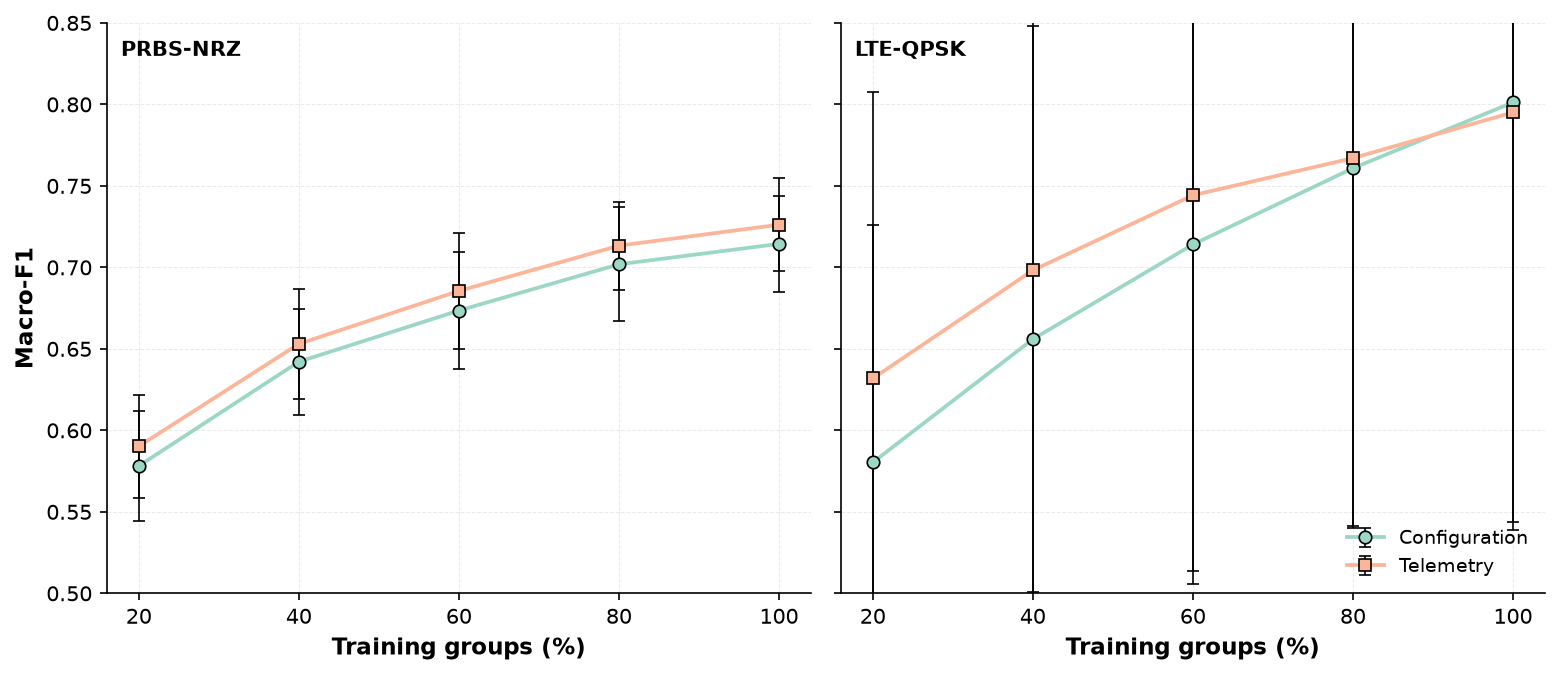

In [109]:
# Step 38 — Consolidated learning-curve figure
# Two campaigns, Configuration vs Telemetry
# Uses the validated Activity 17 summary

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.5, 4.6),
    dpi=150,
    sharey=True
)

campaign_settings = [
    ("PRBS_NRZ", "PRBS-NRZ"),
    ("LTE_QPSK", "LTE-QPSK")
]

scenario_styles = {
    "Configuration-based": {
        "label": "Configuration",
        "color": SET2_PASTEL[0],
        "marker": "o"
    },
    "Telemetry-assisted": {
        "label": "Telemetry",
        "color": SET2_PASTEL[1],
        "marker": "s"
    }
}

for ax, (campaign_code, campaign_label) in zip(
    axes,
    campaign_settings
):

    campaign_data = (
        learning_curve_summary[
            learning_curve_summary[
                "Campaign"
            ] == campaign_code
        ]
        .copy()
    )

    for scenario, style in scenario_styles.items():

        plot_data = (
            campaign_data[
                campaign_data[
                    "Scenario"
                ] == scenario
            ]
            .sort_values(
                "Training fraction"
            )
        )

        x = (
            plot_data[
                "Training fraction"
            ].to_numpy()
            * 100
        )

        y = (
            plot_data[
                "Mean_Macro_F1"
            ].to_numpy()
        )

        yerr = (
            plot_data[
                "Std_Macro_F1"
            ].to_numpy()
        )

        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker=style["marker"],
            markersize=6,
            linewidth=1.8,
            capsize=3,
            label=style["label"],
            color=style["color"],
            markerfacecolor=style["color"],
            markeredgecolor="black",
            markeredgewidth=0.8,
            ecolor="black",
            elinewidth=0.8,
            capthick=0.8
        )

    ax.set_xlabel(
        "Training groups (%)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xticks(
        [20, 40, 60, 80, 100]
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="both",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    # Small panel label, not a title
    ax.text(
        0.02,
        0.97,
        campaign_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_ylabel(
    "Macro-F1",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylim(
    0.50,
    0.85
)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

fig.tight_layout()

learning_curve_main_path = (
    FIGURES_DIR /
    "learning_curves_consolidated_main.pdf"
)

fig.savefig(
    learning_curve_main_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    learning_curve_main_path
)

print(
    "File size (KB):",
    round(
        learning_curve_main_path.stat().st_size
        / 1024,
        2
    )
)

plt.show()

In [110]:
# Step 39 — Inspect LTE-QPSK learning-curve variability

display(
    learning_curve_summary[
        learning_curve_summary["Campaign"] == "LTE_QPSK"
    ][
        [
            "Scenario",
            "Training fraction",
            "Mean_training_groups",
            "Mean_training_observations",
            "Mean_Macro_F1",
            "Std_Macro_F1",
            "Min_Macro_F1",
            "Max_Macro_F1"
        ]
    ]
    .sort_values(
        [
            "Scenario",
            "Training fraction"
        ]
    )
    .round(4)
)

,Scenario,Training fraction,Mean_training_groups,Mean_training_observations,Mean_Macro_F1,Std_Macro_F1,Min_Macro_F1,Max_Macro_F1
0,Configuration-based,0.2,30.6,229.4667,0.5803,0.1454,0.3318,0.8772
1,Configuration-based,0.4,61.0,393.7333,0.6559,0.1921,0.3333,0.8819
2,Configuration-based,0.6,91.0,563.4000,0.7141,0.2086,0.3438,0.9085
3,Configuration-based,0.8,121.4,763.2667,0.7609,0.2208,0.3438,0.9282
4,Configuration-based,1.0,151.2,971.2000,0.8012,0.2572,0.3438,0.9438
5,Telemetry-assisted,0.2,30.6,229.4667,0.6318,0.1758,0.3420,0.8772
6,Telemetry-assisted,0.4,61.0,393.7333,0.6982,0.1974,0.3438,0.9062
7,Telemetry-assisted,0.6,91.0,563.4000,0.7442,0.2304,0.3438,0.9438
8,Telemetry-assisted,0.8,121.4,763.2667,0.7670,0.2257,0.3438,0.9438
9,Telemetry-assisted,1.0,151.2,971.2000,0.7951,0.2561,0.3438,0.9438


In [111]:
# Step 40 — Inspect fold-level LTE-QPSK results at 100% training

display(
    learning_curve_results[
        (learning_curve_results["Campaign"] == "LTE_QPSK")
        &
        (learning_curve_results["Training fraction"] == 1.0)
    ][
        [
            "Scenario",
            "Fold",
            "Repeat",
            "Training groups",
            "Training observations",
            "Validation observations",
            "Macro-F1"
        ]
    ]
    .sort_values(
        [
            "Scenario",
            "Fold"
        ]
    )
    .round(4)
)

,Scenario,Fold,Repeat,Training groups,Training observations,Validation observations,Macro-F1
190,Configuration-based,1,1,158,878,336,0.3438
191,Configuration-based,2,1,144,994,220,0.9024
192,Configuration-based,3,1,163,994,220,0.8772
193,Configuration-based,4,1,145,995,219,0.9438
194,Configuration-based,5,1,146,995,219,0.9390
255,Telemetry-assisted,1,1,158,878,336,0.3438
256,Telemetry-assisted,2,1,144,994,220,0.9142
257,Telemetry-assisted,3,1,163,994,220,0.8350
258,Telemetry-assisted,4,1,145,995,219,0.9438
259,Telemetry-assisted,5,1,146,995,219,0.9390


In [112]:
objects_to_check = [
    "lte_cv_splits",
    "y_lte_train"
]

for obj in objects_to_check:

    print(
        f"{obj:20s}",
        "OK" if obj in globals() else "MISSING"
    )

lte_cv_splits        MISSING
y_lte_train          MISSING


In [114]:
# Search checkpoints for LTE CV splits and training labels

targets = [
    "lte_cv_splits",
    "y_lte_train"
]

for path in sorted(
    ARTIFACTS_DIR.glob("*.joblib")
):

    try:

        checkpoint = joblib.load(path)

        if isinstance(checkpoint, dict):

            found = [
                key
                for key in targets
                if key in checkpoint
            ]

            if found:

                print("\n", path)

                for key in found:
                    print("   ->", key)

    except Exception:
        pass

In [116]:
# Search the notebook for LTE CV split and training-label definitions

targets = [
    "lte_cv_splits",
    "y_lte_train"
]

for i, cell in enumerate(notebook["cells"]):

    source = "".join(
        cell.get("source", [])
    )

    if any(
        target in source
        for target in targets
    ):

        print("\n" + "=" * 80)
        print("CELL:", i)
        print("=" * 80)
        print(source[:2500])


CELL: 163
# Step 3B — Construct LTE-QPSK feature matrices and targets

X_lte_config_train = lte_train[
    configuration_features
].copy()

X_lte_config_test = lte_test[
    configuration_features
].copy()


X_lte_telemetry_train = lte_train[
    telemetry_features
].copy()

X_lte_telemetry_test = lte_test[
    telemetry_features
].copy()


y_lte_train = lte_train[
    "qot_class"
].copy()

y_lte_test = lte_test[
    "qot_class"
].copy()

CELL: 167
# Step 5 — Verify target classes

print("PRBS-NRZ Train classes:")
print(sorted(y_prbs_train.unique()))

print("\nPRBS-NRZ Test classes:")
print(sorted(y_prbs_test.unique()))

print("\nLTE-QPSK Train classes:")
print(sorted(y_lte_train.unique()))

print("\nLTE-QPSK Test classes:")
print(sorted(y_lte_test.unique()))

CELL: 233
# Step 4 — Generate and freeze LTE-QPSK cross-validation folds

lte_y_cv = (
    lte_train["qot_class"]
    .reset_index(drop=True)
)

lte_groups_cv = (
    lte_train["group_id"]
    .reset_index(drop=True)
)

X_lte_cv

Saved: figures\learning_curves_consolidated_main.pdf
File size (KB): 23.62


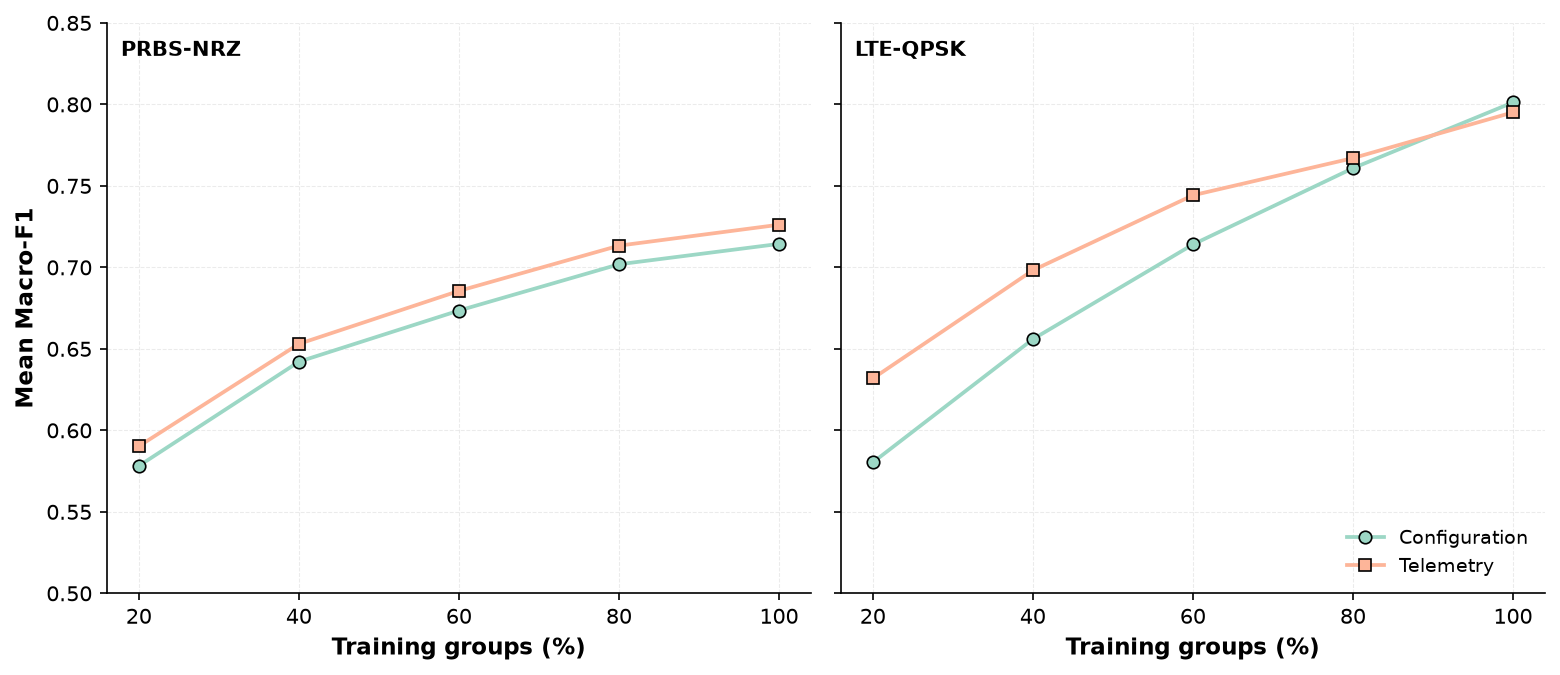

In [117]:
# Step 41 — Main-manuscript learning curves without error bars

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.5, 4.6),
    dpi=150,
    sharey=True
)

campaign_settings = [
    ("PRBS_NRZ", "PRBS-NRZ"),
    ("LTE_QPSK", "LTE-QPSK")
]

scenario_styles = {
    "Configuration-based": {
        "label": "Configuration",
        "color": SET2_PASTEL[0],
        "marker": "o"
    },
    "Telemetry-assisted": {
        "label": "Telemetry",
        "color": SET2_PASTEL[1],
        "marker": "s"
    }
}

for ax, (campaign_code, campaign_label) in zip(
    axes,
    campaign_settings
):

    campaign_data = (
        learning_curve_summary[
            learning_curve_summary["Campaign"] == campaign_code
        ]
        .copy()
    )

    for scenario, style in scenario_styles.items():

        plot_data = (
            campaign_data[
                campaign_data["Scenario"] == scenario
            ]
            .sort_values("Training fraction")
        )

        x = (
            plot_data["Training fraction"]
            .to_numpy()
            * 100
        )

        y = (
            plot_data["Mean_Macro_F1"]
            .to_numpy()
        )

        ax.plot(
            x,
            y,
            marker=style["marker"],
            markersize=6,
            linewidth=1.8,
            label=style["label"],
            color=style["color"],
            markerfacecolor=style["color"],
            markeredgecolor="black",
            markeredgewidth=0.8
        )

    ax.set_xlabel(
        "Training groups (%)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xticks(
        [20, 40, 60, 80, 100]
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(
        axis="both",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    ax.text(
        0.02,
        0.97,
        campaign_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_ylabel(
    "Mean Macro-F1",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylim(
    0.50,
    0.85
)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

fig.tight_layout()

learning_curve_main_path = (
    FIGURES_DIR /
    "learning_curves_consolidated_main.pdf"
)

fig.savefig(
    learning_curve_main_path,
    format="pdf",
    bbox_inches="tight"
)

print(
    "Saved:",
    learning_curve_main_path
)

print(
    "File size (KB):",
    round(
        learning_curve_main_path.stat().st_size / 1024,
        2
    )
)

plt.show()

In [118]:
# Step 42 — Compact manuscript table for learning-curve interpretation

learning_curve_manuscript = learning_curve_summary.copy()

learning_curve_manuscript["Training groups (%)"] = (
    learning_curve_manuscript["Training fraction"] * 100
).astype(int)

learning_curve_manuscript_table = learning_curve_manuscript[
    [
        "Campaign",
        "Scenario",
        "Training groups (%)",
        "Mean_training_groups",
        "Mean_training_observations",
        "Mean_Macro_F1"
    ]
].copy()

learning_curve_manuscript_table = learning_curve_manuscript_table.sort_values(
    ["Campaign", "Scenario", "Training groups (%)"]
).reset_index(drop=True)

display(
    learning_curve_manuscript_table.round(4)
)

,Campaign,Scenario,Training groups (%),Mean_training_groups,Mean_training_observations,Mean_Macro_F1
0,LTE_QPSK,Configuration-based,20,30.6,229.4667,0.5803
1,LTE_QPSK,Configuration-based,40,61.0,393.7333,0.6559
2,LTE_QPSK,Configuration-based,60,91.0,563.4000,0.7141
3,LTE_QPSK,Configuration-based,80,121.4,763.2667,0.7609
4,LTE_QPSK,Configuration-based,100,151.2,971.2000,0.8012
5,LTE_QPSK,Telemetry-assisted,20,30.6,229.4667,0.6318
6,LTE_QPSK,Telemetry-assisted,40,61.0,393.7333,0.6982
7,LTE_QPSK,Telemetry-assisted,60,91.0,563.4000,0.7442
8,LTE_QPSK,Telemetry-assisted,80,121.4,763.2667,0.7670
9,LTE_QPSK,Telemetry-assisted,100,151.2,971.2000,0.7951


In [119]:
# Step 43 — Learning-curve gain summary for manuscript text

gain_rows = []

for (campaign, scenario), group in learning_curve_summary.groupby(
    ["Campaign", "Scenario"]
):
    g = group.sort_values("Training fraction").reset_index(drop=True)

    macro_20 = g.loc[g["Training fraction"] == 0.2, "Mean_Macro_F1"].iloc[0]
    macro_100 = g.loc[g["Training fraction"] == 1.0, "Mean_Macro_F1"].iloc[0]

    gain_rows.append({
        "Campaign": campaign,
        "Scenario": scenario,
        "Macro-F1 at 20%": macro_20,
        "Macro-F1 at 100%": macro_100,
        "Gain 20-100%": macro_100 - macro_20,
        "Gain 20-40%": (
            g.loc[g["Training fraction"] == 0.4, "Mean_Macro_F1"].iloc[0] -
            g.loc[g["Training fraction"] == 0.2, "Mean_Macro_F1"].iloc[0]
        ),
        "Gain 40-60%": (
            g.loc[g["Training fraction"] == 0.6, "Mean_Macro_F1"].iloc[0] -
            g.loc[g["Training fraction"] == 0.4, "Mean_Macro_F1"].iloc[0]
        ),
        "Gain 60-80%": (
            g.loc[g["Training fraction"] == 0.8, "Mean_Macro_F1"].iloc[0] -
            g.loc[g["Training fraction"] == 0.6, "Mean_Macro_F1"].iloc[0]
        ),
        "Gain 80-100%": (
            g.loc[g["Training fraction"] == 1.0, "Mean_Macro_F1"].iloc[0] -
            g.loc[g["Training fraction"] == 0.8, "Mean_Macro_F1"].iloc[0]
        )
    })

learning_curve_gain_summary = pd.DataFrame(gain_rows)

display(
    learning_curve_gain_summary.round(4)
)

,Campaign,Scenario,Macro-F1 at 20%,Macro-F1 at 100%,Gain 20-100%,Gain 20-40%,Gain 40-60%,Gain 60-80%,Gain 80-100%
0,LTE_QPSK,Configuration-based,0.5803,0.8012,0.2209,0.0756,0.0581,0.0468,0.0404
1,LTE_QPSK,Telemetry-assisted,0.6318,0.7951,0.1633,0.0664,0.0460,0.0228,0.0281
2,PRBS_NRZ,Configuration-based,0.5782,0.7144,0.1362,0.0639,0.0314,0.0284,0.0125
3,PRBS_NRZ,Telemetry-assisted,0.5903,0.7262,0.1359,0.0628,0.0325,0.0278,0.0128


In [120]:
# Step 44 — Save learning-curve gain summary

learning_curve_gain_summary.to_csv(
    TABLES_DIR / "table_learning_curve_gain_summary.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_learning_curve_gain_summary.csv"
)

Saved: tables\table_learning_curve_gain_summary.csv


In [121]:
# Step 45 — Save Activity 21 learning-curve checkpoint

activity21_learning_checkpoint = {
    "learning_curve_results": learning_curve_results,
    "learning_curve_summary": learning_curve_summary,
    "learning_gain_summary": learning_gain_summary,
    "learning_monotonicity": learning_monotonicity,
    "learning_curve_gain_summary": learning_curve_gain_summary,
    "main_figure": str(
        FIGURES_DIR /
        "learning_curves_consolidated_main.pdf"
    ),
    "gain_table": str(
        TABLES_DIR /
        "table_learning_curve_gain_summary.csv"
    )
}

learning_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity21_learning_curve_checkpoint.joblib"
)

joblib.dump(
    activity21_learning_checkpoint,
    learning_checkpoint_path,
    compress=3
)

print(
    "Checkpoint:",
    learning_checkpoint_path
)

print(
    "Checkpoint exists:",
    learning_checkpoint_path.exists()
)

Checkpoint: artifacts\activity21_learning_curve_checkpoint.joblib
Checkpoint exists: True


In [122]:
# Step 46 — Verify Activity 16 failure-region objects

failure_objects = [
    "failure_region_summary",
    "acceptable_failure_region_summary",
    "acceptable_error_summary",
    "acceptable_robust_shift",
    "difficulty_distribution",
    "difficulty_by_class",
    "consensus_difficulty"
]

for obj in failure_objects:
    print(
        f"{obj:35s}",
        "OK" if obj in globals() else "MISSING"
    )

failure_region_summary              MISSING
acceptable_failure_region_summary   MISSING
acceptable_error_summary            MISSING
acceptable_robust_shift             MISSING
difficulty_distribution             MISSING
difficulty_by_class                 MISSING
consensus_difficulty                OK


In [123]:
# Step 47 — Reload Activity 16 failure-region objects from checkpoint

activity16_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity16_complete.joblib"
)

activity16_checkpoint = joblib.load(
    activity16_checkpoint_path
)

objects_to_restore = [
    "failure_region_summary",
    "acceptable_failure_region_summary",
    "acceptable_error_summary",
    "acceptable_robust_shift",
    "difficulty_distribution",
    "difficulty_by_class"
]

for obj in objects_to_restore:
    globals()[obj] = activity16_checkpoint[obj]

for obj in objects_to_restore:
    print(
        f"{obj:35s}",
        "OK" if obj in globals() else "MISSING"
    )

failure_region_summary              OK
acceptable_failure_region_summary   OK
acceptable_error_summary            OK
acceptable_robust_shift             OK
difficulty_distribution             OK
difficulty_by_class                 OK


In [124]:
# Step 48 — Inspect robust failure-region shifts

print(
    "Columns:",
    acceptable_robust_shift.columns.tolist()
)

display(
    acceptable_robust_shift.head(20)
)

Columns: ['Campaign', 'Scenario', 'Feature', 'Easy median', 'Hard median', 'Hard - Easy', 'Acceptable IQR', 'Robust median shift', 'Absolute robust shift']


,Campaign,Scenario,Feature,Easy median,Hard median,Hard - Easy,Acceptable IQR,Robust median shift,Absolute robust shift
0,LTE_QPSK,Configuration-based,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00,3.300000e+00,-0.757576,0.757576
1,LTE_QPSK,Configuration-based,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01,5.775000e+01,-0.448485,0.448485
2,LTE_QPSK,Configuration-based,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00,6.000000e+00,0.333333,0.333333
3,LTE_QPSK,Configuration-based,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02,7.300000e-01,0.034247,0.034247
4,LTE_QPSK,Configuration-based,wavelength_nm,1.550000e+03,1.550500e+03,5.000000e-01,0.000000e+00,NaN,NaN
5,LTE_QPSK,Telemetry-assisted,vbias_v,3.100000e+00,6.000000e-01,-2.500000e+00,3.300000e+00,-0.757576,0.757576
6,LTE_QPSK,Telemetry-assisted,prx_dbm,-2.383000e+01,-2.678000e+01,-2.950000e+00,5.737500e+00,-0.514161,0.514161
7,LTE_QPSK,Telemetry-assisted,soa_current_ma,2.150000e+02,1.891000e+02,-2.590000e+01,5.775000e+01,-0.448485,0.448485
8,LTE_QPSK,Telemetry-assisted,voa_attenuation_db,1.900000e+01,2.100000e+01,2.000000e+00,6.000000e+00,0.333333,0.333333
9,LTE_QPSK,Telemetry-assisted,smf_attenuation_db,4.630000e+00,4.655000e+00,2.500000e-02,7.300000e-01,0.034247,0.034247


In [125]:
# Step 49 — Top robust failure-region shifts for manuscript

failure_region_manuscript = (
    acceptable_robust_shift
    .dropna(
        subset=["Absolute robust shift"]
    )
    .sort_values(
        [
            "Campaign",
            "Scenario",
            "Absolute robust shift"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .groupby(
        [
            "Campaign",
            "Scenario"
        ],
        as_index=False,
        group_keys=False
    )
    .head(3)
    .copy()
)

# Add readable labels
failure_region_manuscript["Feature label"] = (
    failure_region_manuscript["Feature"]
    .map(FEATURE_LABELS)
    .fillna(
        failure_region_manuscript["Feature"]
    )
)

failure_region_manuscript = (
    failure_region_manuscript[
        [
            "Campaign",
            "Scenario",
            "Feature label",
            "Easy median",
            "Hard median",
            "Hard - Easy",
            "Robust median shift",
            "Absolute robust shift"
        ]
    ]
    .reset_index(drop=True)
)

display(
    failure_region_manuscript.round(4)
)

,Campaign,Scenario,Feature label,Easy median,Hard median,Hard - Easy,Robust median shift,Absolute robust shift
0,LTE_QPSK,Configuration-based,Vbias,3.100000e+00,6.000000e-01,-2.500000e+00,-0.7576,0.7576
1,LTE_QPSK,Configuration-based,SOA current,2.150000e+02,1.891000e+02,-2.590000e+01,-0.4485,0.4485
2,LTE_QPSK,Configuration-based,VOA attenuation,1.900000e+01,2.100000e+01,2.000000e+00,0.3333,0.3333
3,LTE_QPSK,Telemetry-assisted,Vbias,3.100000e+00,6.000000e-01,-2.500000e+00,-0.7576,0.7576
4,LTE_QPSK,Telemetry-assisted,PRx,-2.383000e+01,-2.678000e+01,-2.950000e+00,-0.5142,0.5142
5,LTE_QPSK,Telemetry-assisted,SOA current,2.150000e+02,1.891000e+02,-2.590000e+01,-0.4485,0.4485
6,PRBS_NRZ,Configuration-based,Vbias,4.400000e+00,2.400000e+00,-2.000000e+00,-0.9524,0.9524
7,PRBS_NRZ,Configuration-based,VOA attenuation,1.100000e+01,1.000000e+01,-1.000000e+00,-0.4000,0.4000
8,PRBS_NRZ,Configuration-based,SOA current,1.961000e+02,1.975000e+02,1.400000e+00,0.1707,0.1707
9,PRBS_NRZ,Telemetry-assisted,VOA attenuation,1.250000e+01,1.000000e+01,-2.500000e+00,-1.0000,1.0000


In [126]:
# Step 50 — Save failure-region manuscript table

failure_region_manuscript.to_csv(
    TABLES_DIR / "table_failure_region_manuscript.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_failure_region_manuscript.csv"
)

Saved: tables\table_failure_region_manuscript.csv


In [127]:
# Step 51 — Save Activity 21 failure-region checkpoint

activity21_failure_checkpoint = {
    "failure_region_summary": failure_region_summary,
    "acceptable_failure_region_summary": acceptable_failure_region_summary,
    "acceptable_error_summary": acceptable_error_summary,
    "acceptable_robust_shift": acceptable_robust_shift,
    "difficulty_distribution": difficulty_distribution,
    "difficulty_by_class": difficulty_by_class,
    "consensus_difficulty": consensus_difficulty,
    "failure_region_manuscript": failure_region_manuscript,
    "manuscript_table": str(
        TABLES_DIR /
        "table_failure_region_manuscript.csv"
    )
}

failure_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity21_failure_region_checkpoint.joblib"
)

joblib.dump(
    activity21_failure_checkpoint,
    failure_checkpoint_path,
    compress=3
)

print(
    "Checkpoint:",
    failure_checkpoint_path
)

print(
    "Checkpoint exists:",
    failure_checkpoint_path.exists()
)

Checkpoint: artifacts\activity21_failure_region_checkpoint.joblib
Checkpoint exists: True


In [128]:
# Step 52 — Verify Activity 18 cross-model agreement objects

agreement_objects = [
    "agreement_summary",
    "agreement_by_class",
    "acceptable_vote_patterns"
]

for obj in agreement_objects:
    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

agreement_summary              MISSING
agreement_by_class             MISSING
acceptable_vote_patterns       OK


In [130]:
# Step 54 — Inspect Activity 18 checkpoint keys

print(
    "\n".join(
        sorted(
            activity18_checkpoint.keys()
        )
    )
)

acceptable_vote_patterns
activity18_summary
agreement_change_summary
class_agreement_change
class_agreement_summary
overall_agreement_summary
pairwise_agreement_summary
pairwise_agreement_table
prediction_agreement_table
prediction_wide
vote_pattern_by_class
vote_pattern_distribution


In [131]:
# Step 55 — Restore Activity 18 agreement summaries

agreement_summary = activity18_checkpoint[
    "overall_agreement_summary"
]

agreement_by_class = activity18_checkpoint[
    "class_agreement_summary"
]

for obj in [
    "agreement_summary",
    "agreement_by_class"
]:
    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

agreement_summary              OK
agreement_by_class             OK


In [132]:
# Step 56 — Inspect cross-model agreement summaries

print("Overall agreement columns:")
print(
    agreement_summary.columns.tolist()
)

display(
    agreement_summary
)

print("\nClass-level agreement columns:")
print(
    agreement_by_class.columns.tolist()
)

display(
    agreement_by_class.head(20)
)

Overall agreement columns:
['Campaign', 'Scenario', 'Samples', 'Mean_vote_entropy', 'Median_vote_entropy', 'Mean_consensus_strength', 'Unanimous_predictions_pct', 'Strict_majority_pct']


,Campaign,Scenario,Samples,Mean_vote_entropy,Median_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Strict_majority_pct
0,LTE_QPSK,Configuration-based,316,0.031305,-0.0,0.978639,94.620253,96.835443
1,LTE_QPSK,Telemetry-assisted,316,0.029308,-0.0,0.980222,94.936709,97.151899
2,PRBS_NRZ,Configuration-based,909,0.179724,-0.0,0.902365,69.086909,91.859186
3,PRBS_NRZ,Telemetry-assisted,909,0.141866,-0.0,0.918317,75.907591,91.419142



Class-level agreement columns:
['Campaign', 'Scenario', 'True class', 'Samples', 'Mean_vote_entropy', 'Median_vote_entropy', 'Mean_consensus_strength', 'Unanimous_predictions_pct', 'Strict_majority_pct']


,Campaign,Scenario,True class,Samples,Mean_vote_entropy,Median_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Strict_majority_pct
0,LTE_QPSK,Configuration-based,Acceptable,16,0.285697,0.25593,0.812500,50.000000,75.000000
1,LTE_QPSK,Configuration-based,Degraded,283,0.010306,-0.00000,0.992933,98.233216,98.939929
2,LTE_QPSK,Configuration-based,Excellent,17,0.141450,-0.00000,0.897059,76.470588,82.352941
3,LTE_QPSK,Telemetry-assisted,Acceptable,16,0.285697,0.25593,0.812500,50.000000,75.000000
4,LTE_QPSK,Telemetry-assisted,Degraded,283,0.009885,-0.00000,0.993816,98.233216,99.293286
5,LTE_QPSK,Telemetry-assisted,Excellent,17,0.111341,-0.00000,0.911765,82.352941,82.352941
6,PRBS_NRZ,Configuration-based,Acceptable,141,0.352140,0.51186,0.794326,43.262411,74.468085
7,PRBS_NRZ,Configuration-based,Degraded,412,0.157162,-0.00000,0.917476,71.359223,95.631068
8,PRBS_NRZ,Configuration-based,Excellent,356,0.137547,-0.00000,0.927669,76.685393,94.382022
9,PRBS_NRZ,Telemetry-assisted,Acceptable,141,0.366618,0.51186,0.787234,37.588652,77.304965


In [133]:
# Step 57 — Display overall cross-model agreement summary

display(
    agreement_summary.round(4)
)

,Campaign,Scenario,Samples,Mean_vote_entropy,Median_vote_entropy,Mean_consensus_strength,Unanimous_predictions_pct,Strict_majority_pct
0,LTE_QPSK,Configuration-based,316,0.0313,-0.0,0.9786,94.6203,96.8354
1,LTE_QPSK,Telemetry-assisted,316,0.0293,-0.0,0.9802,94.9367,97.1519
2,PRBS_NRZ,Configuration-based,909,0.1797,-0.0,0.9024,69.0869,91.8592
3,PRBS_NRZ,Telemetry-assisted,909,0.1419,-0.0,0.9183,75.9076,91.4191


In [134]:
# Step 58 — Compact cross-model agreement table for manuscript

agreement_manuscript = (
    agreement_summary[
        [
            "Campaign",
            "Scenario",
            "Samples",
            "Mean_vote_entropy",
            "Mean_consensus_strength",
            "Unanimous_predictions_pct",
            "Strict_majority_pct"
        ]
    ]
    .copy()
)

agreement_manuscript = agreement_manuscript.rename(
    columns={
        "Mean_vote_entropy": "Mean vote entropy",
        "Mean_consensus_strength": "Mean consensus strength",
        "Unanimous_predictions_pct": "Unanimous predictions (%)",
        "Strict_majority_pct": "Strict majority (%)"
    }
)

display(
    agreement_manuscript.round(4)
)

,Campaign,Scenario,Samples,Mean vote entropy,Mean consensus strength,Unanimous predictions (%),Strict majority (%)
0,LTE_QPSK,Configuration-based,316,0.0313,0.9786,94.6203,96.8354
1,LTE_QPSK,Telemetry-assisted,316,0.0293,0.9802,94.9367,97.1519
2,PRBS_NRZ,Configuration-based,909,0.1797,0.9024,69.0869,91.8592
3,PRBS_NRZ,Telemetry-assisted,909,0.1419,0.9183,75.9076,91.4191


In [135]:
# Step 59 — Save cross-model agreement manuscript table

agreement_manuscript.to_csv(
    TABLES_DIR / "table_cross_model_agreement_manuscript.csv",
    index=False
)

print(
    "Saved:",
    TABLES_DIR / "table_cross_model_agreement_manuscript.csv"
)

Saved: tables\table_cross_model_agreement_manuscript.csv


In [136]:
# Step 60 — Save Activity 21 cross-model agreement checkpoint

activity21_agreement_checkpoint = {
    "agreement_summary": agreement_summary,
    "agreement_by_class": agreement_by_class,
    "acceptable_vote_patterns": acceptable_vote_patterns,
    "agreement_manuscript": agreement_manuscript,
    "manuscript_table": str(
        TABLES_DIR /
        "table_cross_model_agreement_manuscript.csv"
    )
}

agreement_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity21_cross_model_agreement_checkpoint.joblib"
)

joblib.dump(
    activity21_agreement_checkpoint,
    agreement_checkpoint_path,
    compress=3
)

print(
    "Checkpoint:",
    agreement_checkpoint_path
)

print(
    "Checkpoint exists:",
    agreement_checkpoint_path.exists()
)

Checkpoint: artifacts\activity21_cross_model_agreement_checkpoint.joblib
Checkpoint exists: True


In [137]:
# Step 61 — Verify Activity 19 pairwise comparison objects

pairwise_objects = [
    "pairwise_bootstrap_results",
    "pairwise_comparison_summary",
    "pairwise_model_table"
]

for obj in pairwise_objects:
    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

pairwise_bootstrap_results     MISSING
pairwise_comparison_summary    MISSING
pairwise_model_table           MISSING


In [138]:
# Step 62 — Inspect Activity 19 checkpoint keys

activity19_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity19_complete.joblib"
)

activity19_checkpoint = joblib.load(
    activity19_checkpoint_path
)

print(
    "\n".join(
        sorted(
            activity19_checkpoint.keys()
        )
    )
)

activity19_summary
clear_pairwise_separations
pairwise_compact_summary
pairwise_model_bootstrap


In [139]:
# Step 63 — Restore Activity 19 pairwise comparison objects

pairwise_bootstrap_results = activity19_checkpoint[
    "pairwise_model_bootstrap"
]

pairwise_comparison_summary = activity19_checkpoint[
    "pairwise_compact_summary"
]

clear_pairwise_separations = activity19_checkpoint[
    "clear_pairwise_separations"
]

for obj in [
    "pairwise_bootstrap_results",
    "pairwise_comparison_summary",
    "clear_pairwise_separations"
]:
    print(
        f"{obj:30s}",
        "OK" if obj in globals() else "MISSING"
    )

pairwise_bootstrap_results     OK
pairwise_comparison_summary    OK
clear_pairwise_separations     OK


In [140]:
# Step 64 — Inspect pairwise model-comparison summary

print(
    "Columns:",
    pairwise_comparison_summary.columns.tolist()
)

display(
    pairwise_comparison_summary
)

Columns: ['Campaign', 'Scenario', 'Pairwise_comparisons', 'CI_excludes_zero', 'CI_includes_zero', 'Clear_separation_pct']


,Campaign,Scenario,Pairwise_comparisons,CI_excludes_zero,CI_includes_zero,Clear_separation_pct
0,LTE_QPSK,Configuration-based,6,0,6,0.0
1,LTE_QPSK,Telemetry-assisted,6,0,6,0.0
2,PRBS_NRZ,Configuration-based,6,3,3,50.0
3,PRBS_NRZ,Telemetry-assisted,6,3,3,50.0


In [141]:
# Step 65 — Inspect statistically clear pairwise separations

print(
    "Columns:",
    clear_pairwise_separations.columns.tolist()
)

display(
    clear_pairwise_separations.round(4)
)

Columns: ['Campaign', 'Scenario', 'Pair', 'Observed Delta Macro-F1', 'CI lower', 'CI upper']


,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper
0,PRBS_NRZ,Configuration-based,GB - SVM,0.1361,0.0698,0.1759
1,PRBS_NRZ,Configuration-based,MLP - SVM,0.1360,0.0811,0.1781
2,PRBS_NRZ,Configuration-based,RF - SVM,0.1294,0.0735,0.1670
3,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.0360,-0.0558,-0.0100
4,PRBS_NRZ,Telemetry-assisted,MLP - SVM,0.0809,0.0353,0.1176
5,PRBS_NRZ,Telemetry-assisted,RF - SVM,0.0739,0.0141,0.1220


In [142]:
# Step 66 — Save clear pairwise separations for manuscript

pairwise_manuscript = (
    clear_pairwise_separations[
        [
            "Campaign",
            "Scenario",
            "Pair",
            "Observed Delta Macro-F1",
            "CI lower",
            "CI upper"
        ]
    ]
    .copy()
)

pairwise_manuscript.to_csv(
    TABLES_DIR / "table_pairwise_model_separations_manuscript.csv",
    index=False
)

display(
    pairwise_manuscript.round(4)
)

print(
    "Saved:",
    TABLES_DIR / "table_pairwise_model_separations_manuscript.csv"
)

,Campaign,Scenario,Pair,Observed Delta Macro-F1,CI lower,CI upper
0,PRBS_NRZ,Configuration-based,GB - SVM,0.1361,0.0698,0.1759
1,PRBS_NRZ,Configuration-based,MLP - SVM,0.1360,0.0811,0.1781
2,PRBS_NRZ,Configuration-based,RF - SVM,0.1294,0.0735,0.1670
3,PRBS_NRZ,Telemetry-assisted,GB - RF,-0.0360,-0.0558,-0.0100
4,PRBS_NRZ,Telemetry-assisted,MLP - SVM,0.0809,0.0353,0.1176
5,PRBS_NRZ,Telemetry-assisted,RF - SVM,0.0739,0.0141,0.1220


Saved: tables\table_pairwise_model_separations_manuscript.csv


In [143]:
# Step 67 — Save Activity 21 pairwise-comparison checkpoint

activity21_pairwise_checkpoint = {
    "pairwise_bootstrap_results": pairwise_bootstrap_results,
    "pairwise_comparison_summary": pairwise_comparison_summary,
    "clear_pairwise_separations": clear_pairwise_separations,
    "pairwise_manuscript": pairwise_manuscript,
    "manuscript_table": str(
        TABLES_DIR /
        "table_pairwise_model_separations_manuscript.csv"
    )
}

pairwise_checkpoint_path = (
    ARTIFACTS_DIR /
    "activity21_pairwise_comparison_checkpoint.joblib"
)

joblib.dump(
    activity21_pairwise_checkpoint,
    pairwise_checkpoint_path,
    compress=3
)

print(
    "Checkpoint:",
    pairwise_checkpoint_path
)

print(
    "Checkpoint exists:",
    pairwise_checkpoint_path.exists()
)

Checkpoint: artifacts\activity21_pairwise_comparison_checkpoint.joblib
Checkpoint exists: True


In [144]:
# Step 68 — Build Activity 21 manuscript evidence map

activity21_evidence_map = pd.DataFrame([
    {
        "Evidence block": "Global benchmark",
        "Primary artifact": "table_main_benchmark_manuscript.csv",
        "Main manuscript": True,
        "Supplementary": False,
        "Internal validation only": False
    },
    {
        "Evidence block": "Telemetry contribution",
        "Primary artifact": "telemetry contribution table",
        "Main manuscript": True,
        "Supplementary": False,
        "Internal validation only": False
    },
    {
        "Evidence block": "Permutation feature importance",
        "Primary artifact": "feature_importance_*_consolidated_corrected.pdf",
        "Main manuscript": True,
        "Supplementary": False,
        "Internal validation only": False
    },
    {
        "Evidence block": "Learning curves",
        "Primary artifact": "learning_curves_consolidated_main.pdf",
        "Main manuscript": True,
        "Supplementary": False,
        "Internal validation only": False
    },
    {
        "Evidence block": "Failure-region analysis",
        "Primary artifact": "table_failure_region_manuscript.csv",
        "Main manuscript": True,
        "Supplementary": False,
        "Internal validation only": False
    },
    {
        "Evidence block": "Per-class performance",
        "Primary artifact": "Activity 10 per-class metrics",
        "Main manuscript": False,
        "Supplementary": True,
        "Internal validation only": False
    },
    {
        "Evidence block": "Group robustness",
        "Primary artifact": "Activity 15 robustness results",
        "Main manuscript": False,
        "Supplementary": True,
        "Internal validation only": False
    },
    {
        "Evidence block": "Cross-model agreement",
        "Primary artifact": "table_cross_model_agreement_manuscript.csv",
        "Main manuscript": False,
        "Supplementary": True,
        "Internal validation only": False
    },
    {
        "Evidence block": "Pairwise model comparison",
        "Primary artifact": "table_pairwise_model_separations_manuscript.csv",
        "Main manuscript": False,
        "Supplementary": True,
        "Internal validation only": False
    },
    {
        "Evidence block": "Cross-activity consistency audit",
        "Primary artifact": "activity20_complete.joblib",
        "Main manuscript": False,
        "Supplementary": False,
        "Internal validation only": True
    }
])

display(activity21_evidence_map)

,Evidence block,Primary artifact,Main manuscript,Supplementary,Internal validation only
0,Global benchmark,table_main_benchmark_manuscript.csv,True,False,False
1,Telemetry contribution,telemetry contribution table,True,False,False
2,Permutation feature importance,feature_importance_*_consolidated_corrected.pdf,True,False,False
3,Learning curves,learning_curves_consolidated_main.pdf,True,False,False
4,Failure-region analysis,table_failure_region_manuscript.csv,True,False,False
5,Per-class performance,Activity 10 per-class metrics,False,True,False
6,Group robustness,Activity 15 robustness results,False,True,False
7,Cross-model agreement,table_cross_model_agreement_manuscript.csv,False,True,False
8,Pairwise model comparison,table_pairwise_model_separations_manuscript.csv,False,True,False
9,Cross-activity consistency audit,activity20_complete.joblib,False,False,True


In [145]:
# Step 69 — Save final Activity 21 synthesis checkpoint

activity21_final_checkpoint = {
    "benchmark_main_table": benchmark_main_table,
    "benchmark_main_manuscript": benchmark_main_manuscript,
    "telemetry_delta_ci": telemetry_delta_ci,
    "all_permutation_importance": all_permutation_importance,
    "top5_importance": top5_importance,
    "learning_curve_summary": learning_curve_summary,
    "learning_curve_gain_summary": learning_curve_gain_summary,
    "failure_region_manuscript": failure_region_manuscript,
    "agreement_manuscript": agreement_manuscript,
    "pairwise_manuscript": pairwise_manuscript,
    "activity21_evidence_map": activity21_evidence_map
}

activity21_final_path = (
    ARTIFACTS_DIR /
    "activity21_final_synthesis.joblib"
)

joblib.dump(
    activity21_final_checkpoint,
    activity21_final_path,
    compress=3
)

activity21_evidence_map.to_csv(
    TABLES_DIR /
    "table_activity21_evidence_map.csv",
    index=False
)

print(
    "Final checkpoint:",
    activity21_final_path
)

print(
    "Checkpoint exists:",
    activity21_final_path.exists()
)

print(
    "Evidence map saved:",
    TABLES_DIR /
    "table_activity21_evidence_map.csv"
)

Final checkpoint: artifacts\activity21_final_synthesis.joblib
Checkpoint exists: True
Evidence map saved: tables\table_activity21_evidence_map.csv


In [146]:
# FINAL NOTEBOOK CLOSURE — Paper_Dataset_PON

from pathlib import Path
import pandas as pd
import joblib

print("=" * 80)
print("FINAL NOTEBOOK CLOSURE — Paper_Dataset_PON")
print("=" * 80)

# ---------------------------------------------------------------------
# 1. Core final artifacts expected
# ---------------------------------------------------------------------

required_artifacts = {
    "Final synthesis checkpoint":
        ARTIFACTS_DIR / "activity21_final_synthesis.joblib",

    "Feature-importance checkpoint":
        ARTIFACTS_DIR / "activity21_feature_importance_checkpoint.joblib",

    "Learning-curve checkpoint":
        ARTIFACTS_DIR / "activity21_learning_curve_checkpoint.joblib",

    "Failure-region checkpoint":
        ARTIFACTS_DIR / "activity21_failure_region_checkpoint.joblib",

    "Cross-model agreement checkpoint":
        ARTIFACTS_DIR / "activity21_cross_model_agreement_checkpoint.joblib",

    "Pairwise comparison checkpoint":
        ARTIFACTS_DIR / "activity21_pairwise_comparison_checkpoint.joblib",

    "Main benchmark table":
        TABLES_DIR / "table_main_benchmark_manuscript.csv",

    "Evidence map":
        TABLES_DIR / "table_activity21_evidence_map.csv",

    "Permutation importance full table":
        TABLES_DIR / "table_permutation_importance_full.csv",

    "Top-5 permutation importance table":
        TABLES_DIR / "table_permutation_importance_top5_labeled.csv",

    "Learning-curve gain table":
        TABLES_DIR / "table_learning_curve_gain_summary.csv",

    "Failure-region table":
        TABLES_DIR / "table_failure_region_manuscript.csv",

    "Cross-model agreement table":
        TABLES_DIR / "table_cross_model_agreement_manuscript.csv",

    "Pairwise comparison table":
        TABLES_DIR / "table_pairwise_model_separations_manuscript.csv",

    "Main benchmark figure":
        FIGURES_DIR / "benchmark_macro_f1_main.pdf",

    "PRBS feature-importance figure":
        FIGURES_DIR / "feature_importance_prbs_consolidated_corrected.pdf",

    "LTE feature-importance figure":
        FIGURES_DIR / "feature_importance_lte_consolidated_corrected.pdf",

    "Learning-curve figure":
        FIGURES_DIR / "learning_curves_consolidated_main.pdf"
}

# ---------------------------------------------------------------------
# 2. Validate existence
# ---------------------------------------------------------------------

closure_rows = []

for name, path in required_artifacts.items():

    exists = path.exists()

    size_kb = (
        round(path.stat().st_size / 1024, 2)
        if exists
        else None
    )

    closure_rows.append({
        "Artifact": name,
        "Path": str(path),
        "Exists": exists,
        "Size_KB": size_kb
    })

final_artifact_check = pd.DataFrame(
    closure_rows
)

display(final_artifact_check)

# ---------------------------------------------------------------------
# 3. Final status
# ---------------------------------------------------------------------

all_passed = final_artifact_check["Exists"].all()

print("\n" + "=" * 80)

if all_passed:

    print("FINAL STATUS: PASSED")
    print("All required manuscript artifacts are available.")

else:

    print("FINAL STATUS: CHECK REQUIRED")
    print("One or more expected artifacts are missing.")

print("=" * 80)

# ---------------------------------------------------------------------
# 4. Final analysis summary
# ---------------------------------------------------------------------

print("\nAnalysis completed:")
print(" - Group-aware Train/Test validation")
print(" - Baseline evaluation")
print(" - Model benchmarking")
print(" - Hyperparameter optimization")
print(" - Frozen Test evaluation")
print(" - Configuration vs Telemetry bootstrap comparison")
print(" - Permutation feature importance")
print(" - Learning-curve analysis")
print(" - Failure-region analysis")
print(" - Cross-model agreement analysis")
print(" - Pairwise model comparison")
print(" - Cross-activity consistency audit")
print(" - Final manuscript synthesis")

print("\nPrimary campaigns:")
print(" - PRBS-NRZ")
print(" - LTE-QPSK")

print("\nPredictor scenarios:")
print(" - Configuration-based")
print(" - Telemetry-assisted")

print("\nModels:")
print(" - GB")
print(" - RF")
print(" - SVM")
print(" - MLP")

print("\nNotebook analysis phase: COMPLETE")

FINAL NOTEBOOK CLOSURE — Paper_Dataset_PON


,Artifact,Path,Exists,Size_KB
0,Final synthesis checkpoint,artifacts\activity21_final_synthesis.joblib,True,8.88
1,Feature-importance checkpoint,artifacts\activity21_feature_importance_checkp...,True,4.02
2,Learning-curve checkpoint,artifacts\activity21_learning_curve_checkpoint...,True,6.93
3,Failure-region checkpoint,artifacts\activity21_failure_region_checkpoint...,True,31.92
4,Cross-model agreement checkpoint,artifacts\activity21_cross_model_agreement_che...,True,2.45
5,Pairwise comparison checkpoint,artifacts\activity21_pairwise_comparison_check...,True,3.04
6,Main benchmark table,tables\table_main_benchmark_manuscript.csv,True,0.94
7,Evidence map,tables\table_activity21_evidence_map.csv,True,0.84
8,Permutation importance full table,tables\table_permutation_importance_full.csv,True,5.09
9,Top-5 permutation importance table,tables\table_permutation_importance_top5_label...,True,1.52



FINAL STATUS: PASSED
All required manuscript artifacts are available.

Analysis completed:
 - Group-aware Train/Test validation
 - Baseline evaluation
 - Model benchmarking
 - Hyperparameter optimization
 - Frozen Test evaluation
 - Configuration vs Telemetry bootstrap comparison
 - Permutation feature importance
 - Learning-curve analysis
 - Failure-region analysis
 - Cross-model agreement analysis
 - Pairwise model comparison
 - Cross-activity consistency audit
 - Final manuscript synthesis

Primary campaigns:
 - PRBS-NRZ
 - LTE-QPSK

Predictor scenarios:
 - Configuration-based
 - Telemetry-assisted

Models:
 - GB
 - RF
 - SVM
 - MLP

Notebook analysis phase: COMPLETE
